In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
import os

os.listdir('/content')

['.config', 'RF25_ind2025_rfp25.nc', 'era5 2025.nc', 'sample_data']

In [ ]:
ds = xr.open_dataset('/content/RF25_ind2025_rfp25.nc')

In [ ]:
print(ds)

<xarray.Dataset> Size: 25MB
Dimensions:    (TIME: 365, LATITUDE: 129, LONGITUDE: 135)
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2025-01-01 2025-01-02 ... 2025-12-31
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Data variables:
    RAINFALL   (TIME, LATITUDE, LONGITUDE) float32 25MB ...
Attributes:
    history:      FERRET V6.82    9-Apr-26
    Conventions:  CF-1.0


In [ ]:
print(ds["RAINFALL"])

<xarray.DataArray 'RAINFALL' (TIME: 365, LATITUDE: 129, LONGITUDE: 135)> Size: 25MB
[6356475 values with dtype=float32]
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2025-01-01 2025-01-02 ... 2025-12-31
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Attributes:
    long_name:  Rainfall
    units:      mm
    history:    From ind2025_rfp25.grd


In [ ]:
print(ds["RAINFALL"].attrs)

{'long_name': 'Rainfall', 'units': 'mm', 'history': 'From ind2025_rfp25.grd'}


In [ ]:
print("Missing values:", ds["RAINFALL"].isnull().sum().item())

Missing values: 4544615


In [ ]:
print("Total values:", ds["RAINFALL"].size)

Total values: 6356475


In [ ]:
missing = ds["RAINFALL"].isnull().sum().item()
total = ds["RAINFALL"].size

print("Missing percentage:", (missing / total) * 100, "%")

Missing percentage: 71.49583692219352 %


In [ ]:
missing_by_lat = ds["RAINFALL"].isnull().sum(dim=["TIME", "LONGITUDE"])

print(missing_by_lat)

<xarray.DataArray 'RAINFALL' (LATITUDE: 129)> Size: 1kB
array([49275, 49275, 49275, 49275, 49275, 49275, 49275, 47815, 47085,
       46720, 46720, 44895, 44530, 45260, 44530, 44165, 43435, 43070,
       43070, 43070, 42705, 42340, 41975, 41975, 41610, 41245, 41245,
       40515, 40515, 40515, 40880, 40515, 40515, 40515, 40150, 39785,
       39785, 38690, 37960, 37595, 36135, 35770, 35770, 35405, 34675,
       33945, 33580, 32850, 32485, 32120, 31755, 31390, 31025, 29930,
       28835, 28835, 28470, 27375, 25915, 24455, 23725, 20075, 19345,
       18250, 18250, 19710, 18250, 16425, 16060, 15330, 14600, 15330,
       16790, 20440, 19710, 16060, 14965, 14600, 13870, 12775, 12410,
       12775, 14235, 18250, 17520, 20440, 21170, 26645, 29200, 31390,
       33580, 33945, 36500, 38325, 38325, 37960, 38690, 39785, 40515,
       41610, 42340, 42705, 42705, 43435, 42705, 41610, 40515, 40515,
       40515, 40880, 40880, 40150, 39420, 39055, 39785, 39785, 39055,
       38690, 39785, 42705, 43435,

In [ ]:
rain = ds["RAINFALL"]

# Number of non-missing observations at each grid cell
valid_count = rain.notnull().sum(dim="TIME")

print(valid_count)

NameError: name 'ds' is not defined

In [ ]:
import xarray as xr

ds = xr.open_dataset('/content/RF25_ind2025_rfp25.nc')

print(ds)

<xarray.Dataset> Size: 25MB
Dimensions:    (TIME: 365, LATITUDE: 129, LONGITUDE: 135)
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2025-01-01 2025-01-02 ... 2025-12-31
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Data variables:
    RAINFALL   (TIME, LATITUDE, LONGITUDE) float32 25MB ...
Attributes:
    history:      FERRET V6.82    9-Apr-26
    Conventions:  CF-1.0


In [ ]:
rain = ds["RAINFALL"]

valid_count = rain.notnull().sum(dim="TIME")

print("Minimum valid days:", valid_count.min().item())
print("Maximum valid days:", valid_count.max().item())

Minimum valid days: 0
Maximum valid days: 365


In [ ]:
uk = rain.sel(
    LATITUDE=slice(28.5, 31.5),
    LONGITUDE=slice(77.5, 81.0)
)

print(uk)

<xarray.DataArray 'RAINFALL' (TIME: 365, LATITUDE: 13, LONGITUDE: 15)> Size: 285kB
array([[[ 0.,  0., ...,  0.,  0.],
        [ 0.,  0., ...,  0., nan],
        ...,
        [ 0.,  0., ..., nan, nan],
        [ 0.,  0., ..., nan, nan]],

       [[ 0.,  0., ...,  0.,  0.],
        [ 0.,  0., ...,  0., nan],
        ...,
        [ 0.,  0., ..., nan, nan],
        [ 0.,  0., ..., nan, nan]],

       ...,

       [[ 0.,  0., ...,  0.,  0.],
        [ 0.,  0., ...,  0., nan],
        ...,
        [ 0.,  0., ..., nan, nan],
        [ 0.,  0., ..., nan, nan]],

       [[ 0.,  0., ...,  0.,  0.],
        [ 0.,  0., ...,  0., nan],
        ...,
        [ 0.,  0., ..., nan, nan],
        [ 0.,  0., ..., nan, nan]]], dtype=float32)
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2025-01-01 2025-01-02 ... 2025-12-31
  * LATITUDE   (LATITUDE) float64 104B 28.5 28.75 29.0 29.25 ... 31.0 31.25 31.5
  * LONGITUDE  (LONGITUDE) float64 120B 77.5 77.75 78.0 ... 80.5 80.75 81.0
Attributes:
    long_

In [ ]:
uk_missing = uk.isnull().sum().item()
uk_total = uk.size
uk_valid = uk.notnull().sum().item()

print("Total values:", uk_total)
print("Valid values:", uk_valid)
print("Missing values:", uk_missing)
print("Missing percentage:", (uk_missing / uk_total) * 100)


Total values: 71175
Valid values: 57305
Missing values: 13870
Missing percentage: 19.48717948717949


In [ ]:
missing_map = uk.isnull().sum(dim="TIME")

print(missing_map)

<xarray.DataArray 'RAINFALL' (LATITUDE: 13, LONGITUDE: 15)> Size: 2kB
array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0, 365],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 365, 365,
        365, 365],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 365,
        365, 365],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 365,
        365, 365],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 365,
        365, 365],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        365, 365],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0, 365],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 365,
        365, 365],
       [  

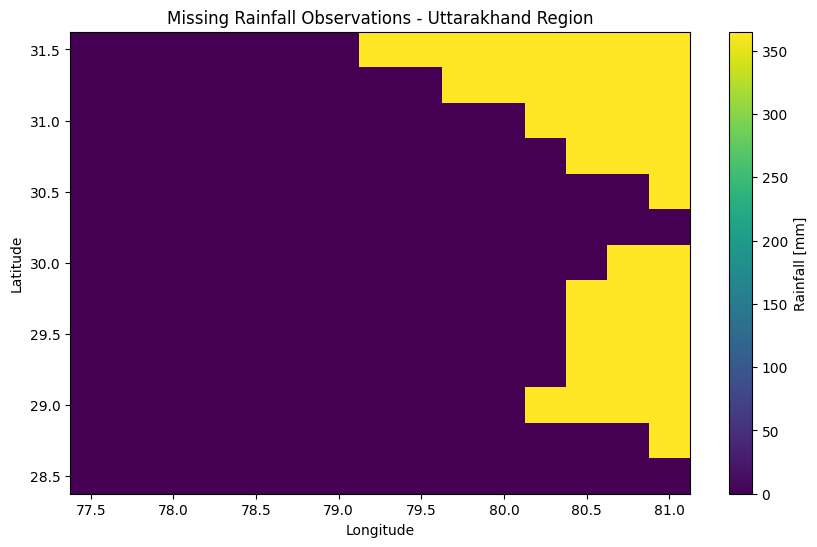

In [ ]:
plt.figure(figsize=(10, 6))

missing_map.plot()

plt.title("Missing Rainfall Observations - Uttarakhand Region")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

In [ ]:
print("Total grid cells:", missing_map.size)
print("Completely missing cells:", (missing_map == 365).sum().item())

Total grid cells: 195
Completely missing cells: 38


In [ ]:
print("Percentage of completely missing cells:",
      (38 / 195) * 100)

Percentage of completely missing cells: 19.48717948717949


In [ ]:
print("Cells with data for all 365 days:", (missing_map == 0).sum().item())

Cells with data for all 365 days: 157


In [ ]:
print("Minimum rainfall value:", rain.min(skipna=True).item())

Minimum rainfall value: 0.0


In [ ]:
print("Maximum rainfall value:", rain.max(skipna=True).item())

Maximum rainfall value: 469.21014404296875


In [ ]:
print("Valid rainfall observations:", uk.notnull().sum().item())

Valid rainfall observations: 57305


In [ ]:
# Descriptive statistics for available rainfall observations

print("Mean:", rain.mean(skipna=True).item())
print("Median:", rain.median(skipna=True).item())
print("Standard deviation:", rain.std(skipna=True).item())
print("Minimum:", rain.min(skipna=True).item())
print("Maximum:", rain.max(skipna=True).item())

print("\nPercentiles:")
print(rain.quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99],
    skipna=True
))

Mean: 3.473656415939331
Median: 0.0
Standard deviation: 11.317556381225586
Minimum: 0.0
Maximum: 469.21014404296875

Percentiles:
<xarray.DataArray 'RAINFALL' (quantile: 6)> Size: 48B
array([ 0.        ,  0.        ,  0.82905714, 10.01179733, 20.57294302,
       54.0846838 ])
Coordinates:
  * quantile  (quantile) float64 48B 0.25 0.5 0.75 0.9 0.95 0.99
Attributes:
    long_name:  Rainfall
    units:      mm
    history:    From ind2025_rfp25.grd


In [ ]:
# Skewness and kurtosis of available rainfall observations

rain_valid = rain.dropna(dim=None)

print("Skewness:", rain_valid.skew().item())
print("Kurtosis:", rain_valid.kurtosis().item())

ValueError: Dimension None not found in data dimensions ('LONGITUDE', 'LATITUDE', 'TIME')

In [ ]:
# Remove NaN values and convert the remaining rainfall values into a 1D array

rain_valid = rain.values.flatten()
rain_valid = rain_valid[~np.isnan(rain_valid)]

print("Number of valid observations:", len(rain_valid))
print("Minimum:", rain_valid.min())
print("Maximum:", rain_valid.max())

Number of valid observations: 1811860
Minimum: 0.0
Maximum: 469.21014


In [ ]:
# Full India rainfall distribution statistics

rain_valid = rain.values.flatten()
rain_valid = rain_valid[~np.isnan(rain_valid)]

print("Valid observations:", len(rain_valid))
print("Mean:", np.mean(rain_valid))
print("Median:", np.median(rain_valid))
print("Standard deviation:", np.std(rain_valid))
print("Minimum:", np.min(rain_valid))
print("Maximum:", np.max(rain_valid))

print("\nPercentiles:")
for p in [25, 50, 75, 90, 95, 99, 99.5, 99.9]:
    print(f"{p}th percentile:", np.percentile(rain_valid, p))

print("\nSkewness:", pd.Series(rain_valid).skew())
print("Kurtosis:", pd.Series(rain_valid).kurtosis())

Valid observations: 1811860
Mean: 3.4739623
Median: 0.0
Standard deviation: 11.266276
Minimum: 0.0
Maximum: 469.21014

Percentiles:
25th percentile: 0.0
50th percentile: 0.0
75th percentile: 0.82905716
90th percentile: 10.011797
95th percentile: 20.57294
99th percentile: 54.08457
99.5th percentile: 71.90752
99.9th percentile: 124.29072

Skewness: 6.997009
Kurtosis: 82.21901


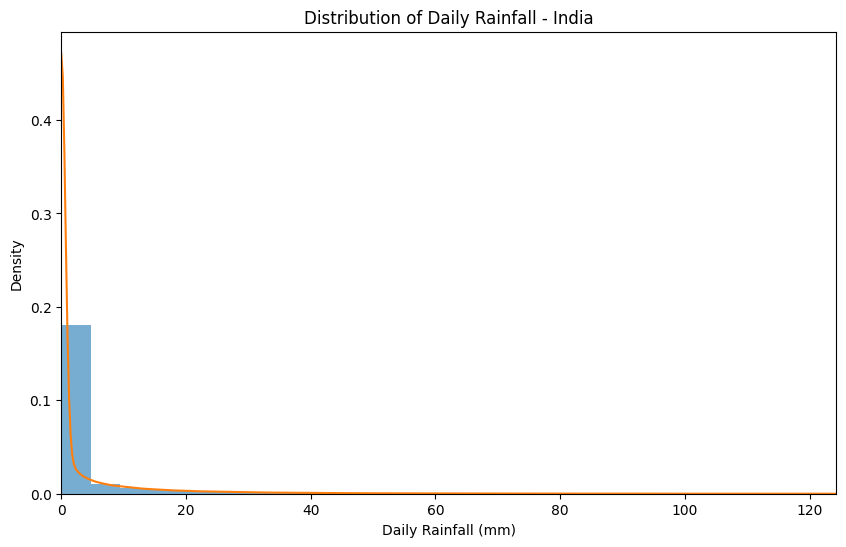

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(rain_valid, bins=100, density=True, alpha=0.6)

# KDE
from scipy.stats import gaussian_kde

kde = gaussian_kde(rain_valid)
x = np.linspace(0, np.percentile(rain_valid, 99.9), 500)

plt.plot(x, kde(x))

plt.xlabel("Daily Rainfall (mm)")
plt.ylabel("Density")
plt.title("Distribution of Daily Rainfall - India")
plt.xlim(0, np.percentile(rain_valid, 99.9))

plt.show()

In [ ]:
# Separate zero-rainfall and positive-rainfall observations

zero_count = np.sum(rain_valid == 0)
positive_count = np.sum(rain_valid > 0)

print("Zero-rainfall observations:", zero_count)
print("Positive-rainfall observations:", positive_count)

print("Percentage zero rainfall:", (zero_count / len(rain_valid)) * 100)
print("Percentage positive rainfall:", (positive_count / len(rain_valid)) * 100)

Zero-rainfall observations: 1259972
Positive-rainfall observations: 551888
Percentage zero rainfall: 69.54025145430663
Percentage positive rainfall: 30.459748545693376


In [ ]:
# Positive rainfall observations only
rain_positive = rain_valid[rain_valid > 0]

print("Positive observations:", len(rain_positive))
print("Mean positive rainfall:", np.mean(rain_positive))
print("Median positive rainfall:", np.median(rain_positive))
print("Standard deviation:", np.std(rain_positive))
print("Minimum positive rainfall:", np.min(rain_positive))
print("Maximum positive rainfall:", np.max(rain_positive))

print("\nPercentiles of positive rainfall:")
for p in [50, 75, 90, 95, 99, 99.5, 99.9]:
    print(f"{p}th percentile:", np.percentile(rain_positive, p))

print("\nSkewness:", pd.Series(rain_positive).skew())
print("Kurtosis:", pd.Series(rain_positive).kurtosis())

Positive observations: 551888
Mean positive rainfall: 11.405097
Median positive rainfall: 4.8703046
Standard deviation: 18.062534
Minimum positive rainfall: 0.1
Maximum positive rainfall: 469.21014

Percentiles of positive rainfall:
50th percentile: 4.8703046
75th percentile: 13.880279
90th percentile: 29.628273
95th percentile: 44.223663
99th percentile: 85.94844
99.5th percentile: 109.04362
99.9th percentile: 166.94463

Skewness: 4.188623
Kurtosis: 30.79274


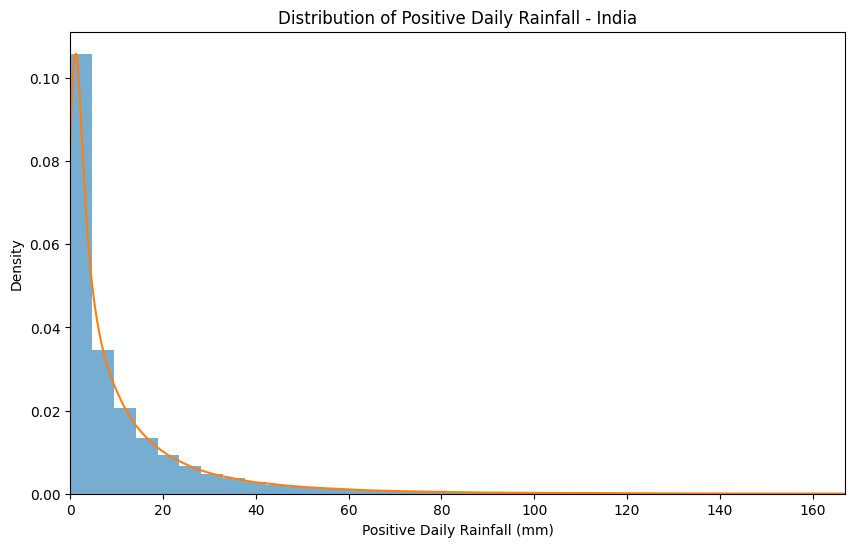

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    rain_positive,
    bins=100,
    density=True,
    alpha=0.6
)

kde_positive = gaussian_kde(rain_positive)

x_positive = np.linspace(
    0,
    np.percentile(rain_positive, 99.9),
    500
)

plt.plot(x_positive, kde_positive(x_positive))

plt.xlabel("Positive Daily Rainfall (mm)")
plt.ylabel("Density")
plt.title("Distribution of Positive Daily Rainfall - India")
plt.xlim(0, np.percentile(rain_positive, 99.9))

plt.show()

In [ ]:
# Average annual rainfall at each grid cell

mean_spatial = rain.mean(dim="TIME", skipna=True)

print(mean_spatial)

<xarray.DataArray 'RAINFALL' (LATITUDE: 129, LONGITUDE: 135)> Size: 70kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32)
Coordinates:
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Attributes:
    long_name:  Rainfall
    units:      mm
    history:    From ind2025_rfp25.grd


In [ ]:
# Check how many grid cells have a valid annual mean

total_cells = mean_spatial.size
valid_cells = mean_spatial.notnull().sum().item()
missing_cells = mean_spatial.isnull().sum().item()

print("Total grid cells:", total_cells)
print("Grid cells with valid mean:", valid_cells)
print("Grid cells with missing mean:", missing_cells)
print("Percentage with valid mean:", (valid_cells / total_cells) * 100)

Total grid cells: 17415
Grid cells with valid mean: 4964
Grid cells with missing mean: 12451
Percentage with valid mean: 28.50416307780649


In [ ]:
print("Minimum annual mean rainfall:", mean_spatial.min(skipna=True).item())
print("Maximum annual mean rainfall:", mean_spatial.max(skipna=True).item())

Minimum annual mean rainfall: 0.0
Maximum annual mean rainfall: 21.90656089782715


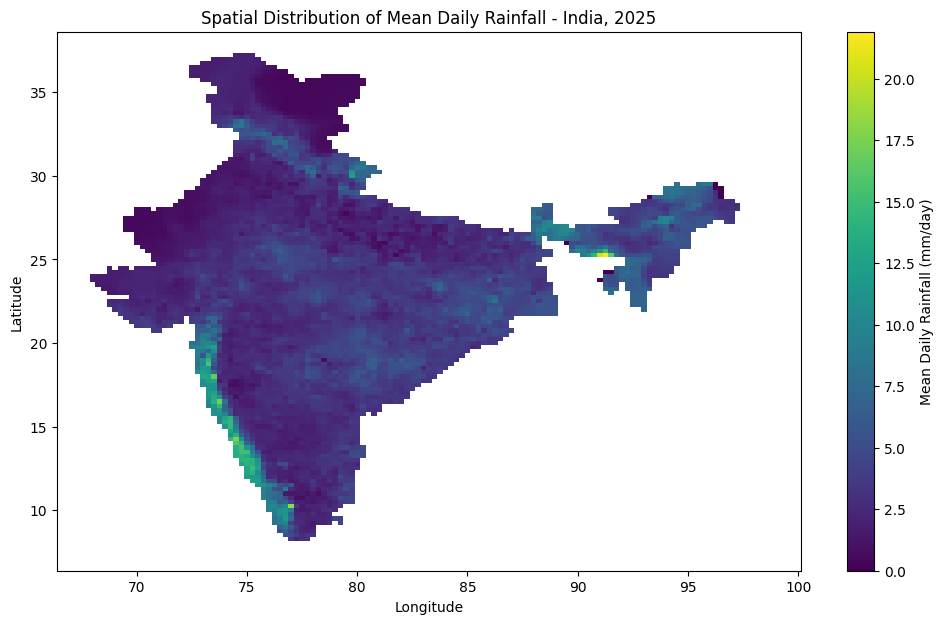

In [ ]:
# India-wide spatial distribution of mean daily rainfall in 2025

plt.figure(figsize=(12, 7))

plt.pcolormesh(
    mean_spatial.LONGITUDE,
    mean_spatial.LATITUDE,
    mean_spatial,
    shading="auto"
)

plt.colorbar(label="Mean Daily Rainfall (mm/day)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of Mean Daily Rainfall - India, 2025")

plt.show()

In [ ]:
# Maximum daily rainfall recorded at each grid cell during 2025

max_spatial = rain.max(dim="TIME", skipna=True)

print("Minimum grid-cell maximum:", max_spatial.min(skipna=True).item())
print("Maximum grid-cell maximum:", max_spatial.max(skipna=True).item())

print("Number of valid grid cells:", max_spatial.notnull().sum().item())

NameError: name 'rain' is not defined

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Open the NetCDF file
ds = xr.open_dataset("/content/RF25_ind2025_rfp25.nc")

# Select rainfall variable
rain = ds["RAINFALL"]

print("Dataset loaded successfully!")
print("Shape:", rain.shape)
print("Dimensions:", rain.dims)

Dataset loaded successfully!
Shape: (365, 129, 135)
Dimensions: ('TIME', 'LATITUDE', 'LONGITUDE')


In [ ]:
# Maximum daily rainfall recorded at each grid cell during 2025

max_spatial = rain.max(dim="TIME", skipna=True)

print("Minimum grid-cell maximum:", max_spatial.min(skipna=True).item())
print("Maximum grid-cell maximum:", max_spatial.max(skipna=True).item())

print("Number of valid grid cells:", max_spatial.notnull().sum().item())

Minimum grid-cell maximum: 0.0
Maximum grid-cell maximum: 469.21014404296875
Number of valid grid cells: 4964


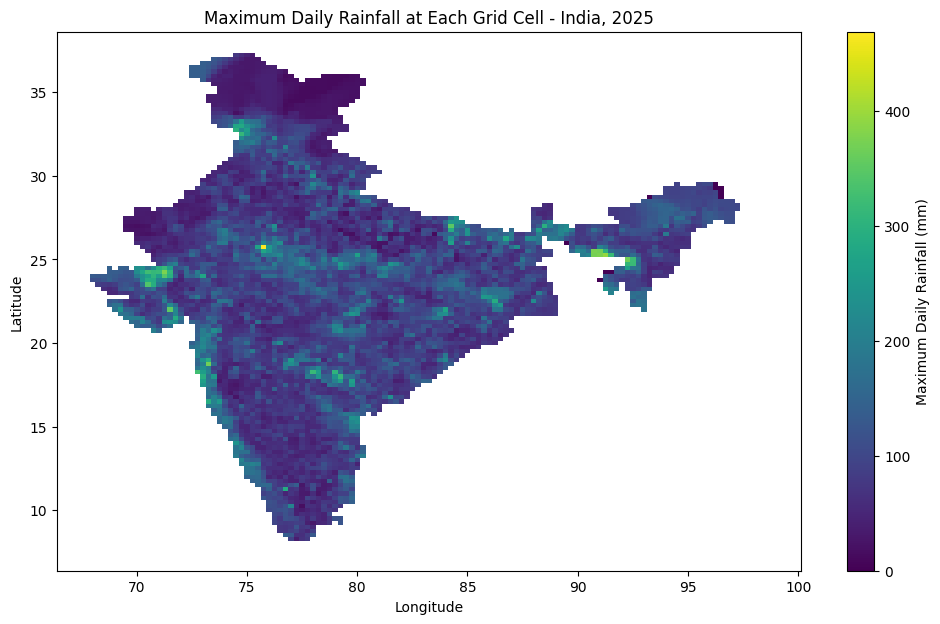

In [ ]:
# Maximum daily rainfall recorded at each grid cell during 2025

plt.figure(figsize=(12, 7))

plt.pcolormesh(
    max_spatial.LONGITUDE,
    max_spatial.LATITUDE,
    max_spatial,
    shading="auto"
)

plt.colorbar(label="Maximum Daily Rainfall (mm)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Maximum Daily Rainfall at Each Grid Cell - India, 2025")

plt.show()

In [ ]:
# Exploratory extreme-rainfall frequency
# Threshold = India-wide 99th percentile

extreme_threshold = np.percentile(rain_valid, 99)

extreme_days = (rain >= extreme_threshold).sum(dim="TIME")

print("Exploratory threshold:", extreme_threshold, "mm")
print("Maximum number of extreme-rainfall days at any grid cell:",
      extreme_days.max().item())
print("Minimum number of extreme-rainfall days:",
      extreme_days.min().item())

NameError: name 'rain_valid' is not defined

In [ ]:
# Calculate the 99th percentile directly from all valid rainfall values

rain_values = rain.values.flatten()
rain_values = rain_values[~np.isnan(rain_values)]

extreme_threshold = np.percentile(rain_values, 99)

# Count days >= threshold at each grid cell
extreme_days = (rain >= extreme_threshold).sum(dim="TIME")

print("Exploratory 99th percentile threshold:", extreme_threshold, "mm")
print("Maximum extreme-rainfall days at any grid cell:",
      extreme_days.max().item())
print("Minimum extreme-rainfall days:",
      extreme_days.min().item())

Exploratory 99th percentile threshold: 54.08457 mm
Maximum extreme-rainfall days at any grid cell: 47
Minimum extreme-rainfall days: 0


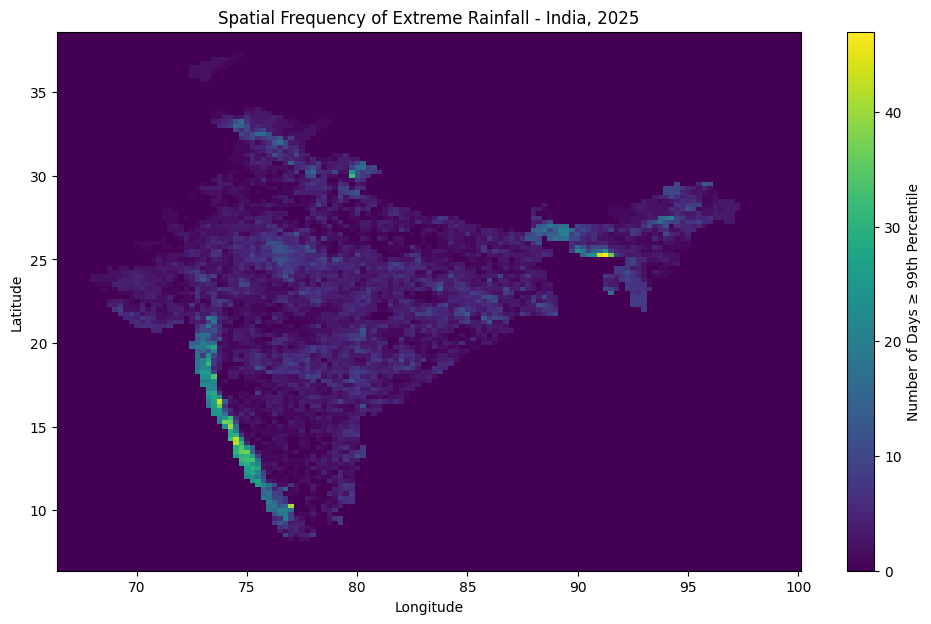

In [ ]:
# Spatial distribution of extreme-rainfall frequency

plt.figure(figsize=(12, 7))

plt.pcolormesh(
    extreme_days.LONGITUDE,
    extreme_days.LATITUDE,
    extreme_days,
    shading="auto"
)

plt.colorbar(label="Number of Days ≥ 99th Percentile")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Frequency of Extreme Rainfall - India, 2025")

plt.show()

In [ ]:
# Find the grid cells with the highest frequency of extreme-rainfall days

top_cells = extreme_days.stack(
    cell=("LATITUDE", "LONGITUDE")
).sortby(
    extreme_days.stack(cell=("LATITUDE", "LONGITUDE")),
    ascending=False
).dropna("cell").head(20)

print(top_cells)

NameError: name 'extreme_days' is not defined

In [ ]:
# Recreate the exploratory extreme-rainfall frequency
# using the India-wide 99th percentile threshold

rain_values = rain.values.flatten()
rain_values = rain_values[~np.isnan(rain_values)]

extreme_threshold = np.percentile(rain_values, 99)

extreme_days = (rain >= extreme_threshold).sum(dim="TIME")

# Find the 20 grid cells with the highest number of extreme days
top_cells = (
    extreme_days
    .stack(cell=("LATITUDE", "LONGITUDE"))
    .sortby(
        extreme_days.stack(cell=("LATITUDE", "LONGITUDE")),
        ascending=False
    )
    .dropna("cell")
    .head(20)
)

print("99th percentile threshold:", extreme_threshold, "mm")
print("\nTop 20 grid cells:")
print(top_cells)

NameError: name 'rain' is not defined

In [ ]:
import os
import xarray as xr
import numpy as np

# Check that the NetCDF file exists
file_path = "/content/RF25_ind2025_rfp25.nc"

if not os.path.exists(file_path):
    print("FILE NOT FOUND")
    print("Please upload RF25_ind2025_rfp25.nc again in Colab.")
else:
    # Load dataset
    ds = xr.open_dataset(file_path)
    rain = ds["RAINFALL"]

    # Get all valid rainfall observations
    rain_values = rain.values.flatten()
    rain_values = rain_values[~np.isnan(rain_values)]

    # India-wide 99th percentile
    extreme_threshold = np.percentile(rain_values, 99)

    # Count extreme-rainfall days at each grid cell
    extreme_days = (rain >= extreme_threshold).sum(dim="TIME")

    # Find top 20 grid cells
    stacked = extreme_days.stack(
        cell=("LATITUDE", "LONGITUDE")
    )

    top_cells = stacked.sortby(stacked, ascending=False).dropna("cell").head(20)

    print("99th percentile threshold:", extreme_threshold, "mm")
    print("\nTop 20 grid cells:")
    print(top_cells)

99th percentile threshold: 54.08457 mm

Top 20 grid cells:
<xarray.DataArray 'RAINFALL' (cell: 20)> Size: 160B
array([47, 44, 43, 42, 42, 41, 40, 37, 37, 36, 36, 36, 36, 34, 34, 33, 32,
       32, 32, 32])
Coordinates:
  * cell       (cell) object 160B MultiIndex
  * LATITUDE   (cell) float64 160B 25.25 25.25 16.5 14.25 ... 15.5 14.25 13.0
  * LONGITUDE  (cell) float64 160B 91.25 91.0 73.75 74.5 ... 74.25 74.25 75.0
Attributes:
    long_name:  Rainfall
    units:      mm
    history:    From ind2025_rfp25.grd


In [ ]:
# Display the top 20 extreme-rainfall cells clearly

top_df = top_cells.to_dataframe(name="extreme_days").reset_index()

top_df = top_df[
    ["LATITUDE", "LONGITUDE", "extreme_days"]
]

print(top_df.to_string(index=False))

 LATITUDE  LONGITUDE  extreme_days
    25.25      91.25            47
    25.25      91.00            44
    16.50      73.75            43
    14.25      74.50            42
    14.00      74.50            42
    10.25      77.00            41
    15.00      74.25            40
    15.25      74.00            37
    13.50      75.00            37
    25.25      91.50            36
    16.25      73.75            36
    15.25      74.25            36
    13.50      74.75            36
    18.00      73.50            34
    13.75      74.75            34
    13.00      75.25            33
    30.00      79.75            32
    15.50      74.25            32
    14.25      74.25            32
    13.00      75.00            32


In [ ]:
# Calculate the percentage of valid days that were extreme
# for every grid cell

valid_days = rain.notnull().sum(dim="TIME")

extreme_frequency_percent = (
    extreme_days / valid_days
) * 100

# Remove cells where there are no valid observations
extreme_frequency_percent = extreme_frequency_percent.where(valid_days > 0)

# Find the 20 cells with the highest percentage
top_frequency = (
    extreme_frequency_percent
    .stack(cell=("LATITUDE", "LONGITUDE"))
    .dropna("cell")
    .sortby(
        extreme_frequency_percent.stack(
            cell=("LATITUDE", "LONGITUDE")
        ).dropna("cell"),
        ascending=False
    )
    .head(20)
)

print("Top 20 cells by percentage of valid days classified as extreme:")
print(
    top_frequency.to_dataframe(name="extreme_percentage")
    .reset_index()
    [["LATITUDE", "LONGITUDE", "extreme_percentage"]]
    .to_string(index=False)
)

Top 20 cells by percentage of valid days classified as extreme:
 LATITUDE  LONGITUDE  extreme_percentage
    25.25      91.25           12.876712
    25.25      91.00           12.054795
    16.50      73.75           11.780822
    14.25      74.50           11.506849
    14.00      74.50           11.506849
    10.25      77.00           11.232877
    15.00      74.25           10.958904
    15.25      74.00           10.136986
    13.50      75.00           10.136986
    25.25      91.50            9.863014
    16.25      73.75            9.863014
    15.25      74.25            9.863014
    13.50      74.75            9.863014
    18.00      73.50            9.315068
    13.75      74.75            9.315068
    13.00      75.25            9.041096
    30.00      79.75            8.767123
    15.50      74.25            8.767123
    14.25      74.25            8.767123
    13.00      75.00            8.767123


In [ ]:
import xarray as xr
import numpy as np
import pandas as pd

# Load ERA5 dataset
ds_era5 = xr.open_dataset("/content/era5 2025.nc")

# Display dataset structure
print(ds_era5)


OSError: Unable to synchronously open file (truncated file: eof = 206569472, sblock->base_addr = 0, stored_eof = 596876954)

In [ ]:
import os

file_path = "/content/era5 2025.nc"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    size_mb = os.path.getsize(file_path) / (1024**2)
    print("File size:", round(size_mb, 2), "MB")

File exists: True
File size: 319.0 MB


In [ ]:
import os

file_path = "/content/era5 2025.nc"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    size_mb = os.path.getsize(file_path) / (1024**2)
    print("File size:", round(size_mb, 2), "MB")

File exists: True
File size: 569.23 MB


In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
file_path = "/content/era5 2025.nc"

ds = xr.open_dataset(file_path)

ds

<xarray.Dataset> Size: 1GB
Dimensions:     (valid_time: 3672, latitude: 127, longitude: 135)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 29kB 2025-05-01 ... 2025-09-30T23...
  * latitude    (latitude) float64 1kB 38.0 37.75 37.5 37.25 ... 7.0 6.75 6.5
  * longitude   (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
    number      int64 8B ...
    expver      (valid_time) <U4 59kB ...
Data variables:
    u10         (valid_time, latitude, longitude) float32 252MB ...
    v10         (valid_time, latitude, longitude) float32 252MB ...
    t2m         (valid_time, latitude, longitude) float32 252MB ...
    sp          (valid_time, latitude, longitude) float32 252MB ...
    tcwv        (valid_time, latitude, longitude) float32 252MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-09-03T17:26 GRIB to CDM+CF via cfgrib-0.9.1...

In [ ]:
for var in ds.data_vars:
    total = ds[var].size
    missing = ds[var].isnull().sum().item()
    percentage = (missing / total) * 100

    print(f"{var}:")
    print(f"  Total values   : {total:,}")
    print(f"  Missing values : {missing:,}")
    print(f"  Missing %      : {percentage:.2f}%")
    print()

u10:
  Total values   : 62,956,440
  Missing values : 0
  Missing %      : 0.00%

v10:
  Total values   : 62,956,440
  Missing values : 0
  Missing %      : 0.00%

t2m:
  Total values   : 62,956,440
  Missing values : 0
  Missing %      : 0.00%

sp:
  Total values   : 62,956,440
  Missing values : 0
  Missing %      : 0.00%

tcwv:
  Total values   : 62,956,440
  Missing values : 0
  Missing %      : 0.00%



In [ ]:
print("Start time:", ds.valid_time.values[0])
print("End time:", ds.valid_time.values[-1])
print("Total time points:", len(ds.valid_time))

Start time: 2025-05-01T00:00:00.000000000
End time: 2025-09-30T23:00:00.000000000
Total time points: 3672


In [ ]:
times = pd.to_datetime(ds.valid_time.values)

print("Total timestamps:", len(times))
print("Unique timestamps:", times.nunique())
print("Duplicate timestamps:", times.duplicated().sum())

Total timestamps: 3672
Unique timestamps: 3672
Duplicate timestamps: 0


In [ ]:
print("Latitude range:", ds.latitude.min().item(), "to", ds.latitude.max().item())
print("Longitude range:", ds.longitude.min().item(), "to", ds.longitude.max().item())

Latitude range: 6.5 to 38.0
Longitude range: 66.5 to 100.0


In [ ]:
print("Latitude resolution:", abs(ds.latitude.values[1] - ds.latitude.values[0]))
print("Longitude resolution:", abs(ds.longitude.values[1] - ds.longitude.values[0]))

Latitude resolution: 0.25
Longitude resolution: 0.25


In [ ]:
print("Number of latitude points:", len(ds.latitude))
print("Number of longitude points:", len(ds.longitude))
print("Total spatial grid cells:", len(ds.latitude) * len(ds.longitude))

Number of latitude points: 127
Number of longitude points: 135
Total spatial grid cells: 17145


In [ ]:
for var in ds.data_vars:
    print(f"{var}:")
    print("  Minimum:", ds[var].min().item())
    print("  Maximum:", ds[var].max().item())

u10:
  Minimum: -12.151824951171875
  Maximum: 18.5328369140625
v10:
  Minimum: -16.488174438476562
  Maximum: 18.705169677734375
t2m:
  Minimum: 241.14585876464844
  Maximum: 322.52392578125
sp:
  Minimum: 49135.68359375
  Maximum: 101726.375
tcwv:
  Minimum: 0.29937171936035156
  Maximum: 91.38423919677734


In [ ]:
# Convert temperature from Kelvin to Celsius
t2m_c = ds.t2m - 273.15

# Convert surface pressure from Pa to hPa
sp_hpa = ds.sp / 100

# Calculate wind speed from U and V components
wind_speed = np.sqrt(ds.u10**2 + ds.v10**2)

# Create a new dataset with convenient variables
era5 = xr.Dataset({
    "temperature": t2m_c,
    "pressure": sp_hpa,
    "u10": ds.u10,
    "v10": ds.v10,
    "wind_speed": wind_speed,
    "tcwv": ds.tcwv
})

era5

<xarray.Dataset> Size: 2GB
Dimensions:      (valid_time: 3672, latitude: 127, longitude: 135)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 29kB 2025-05-01 ... 2025-09-30T2...
  * latitude     (latitude) float64 1kB 38.0 37.75 37.5 37.25 ... 7.0 6.75 6.5
  * longitude    (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
    number       int64 8B 0
    expver       (valid_time) <U4 59kB '0001' '0001' '0001' ... '0001' '0001'
Data variables:
    temperature  (valid_time, latitude, longitude) float32 252MB 13.06 ... 26.44
    pressure     (valid_time, latitude, longitude) float32 252MB 878.3 ... 1....
    u10          (valid_time, latitude, longitude) float32 252MB -0.7523 ... ...
    v10          (valid_time, latitude, longitude) float32 252MB 0.6752 ... -...
    wind_speed   (valid_time, latitude, longitude) float32 252MB 1.011 ... 2.421
    tcwv         (valid_time, latitude, longitude) float32 252MB 20.7 ... 56.44

In [ ]:
for var in era5.data_vars:
    print(f"\n========== {var.upper()} ==========")
    print(f"Mean   : {era5[var].mean().item():.2f}")
    print(f"Median : {era5[var].median().item():.2f}")
    print(f"Std    : {era5[var].std().item():.2f}")
    print(f"Min    : {era5[var].min().item():.2f}")
    print(f"Max    : {era5[var].max().item():.2f}")


========== TEMPERATURE ==========
Mean   : 10.53
Median : 27.19
Std    : 12.36
Min    : -32.00
Max    : 49.37

========== PRESSURE ==========
Mean   : 272.89
Median : 977.84
Std    : 528.62
Min    : 491.36
Max    : 1017.26

========== U10 ==========
Mean   : 2.17
Median : 1.44
Std    : 3.05
Min    : -12.15
Max    : 18.53

========== V10 ==========
Mean   : 1.22
Median : 0.88
Std    : 2.40
Min    : -16.49
Max    : 18.71

========== WIND_SPEED ==========
Mean   : 2.89
Median : 3.03
Std    : 3.01
Min    : 0.00
Max    : 20.33

========== TCWV ==========
Mean   : 26.59
Median : 49.93
Std    : 23.40
Min    : 0.30
Max    : 91.38


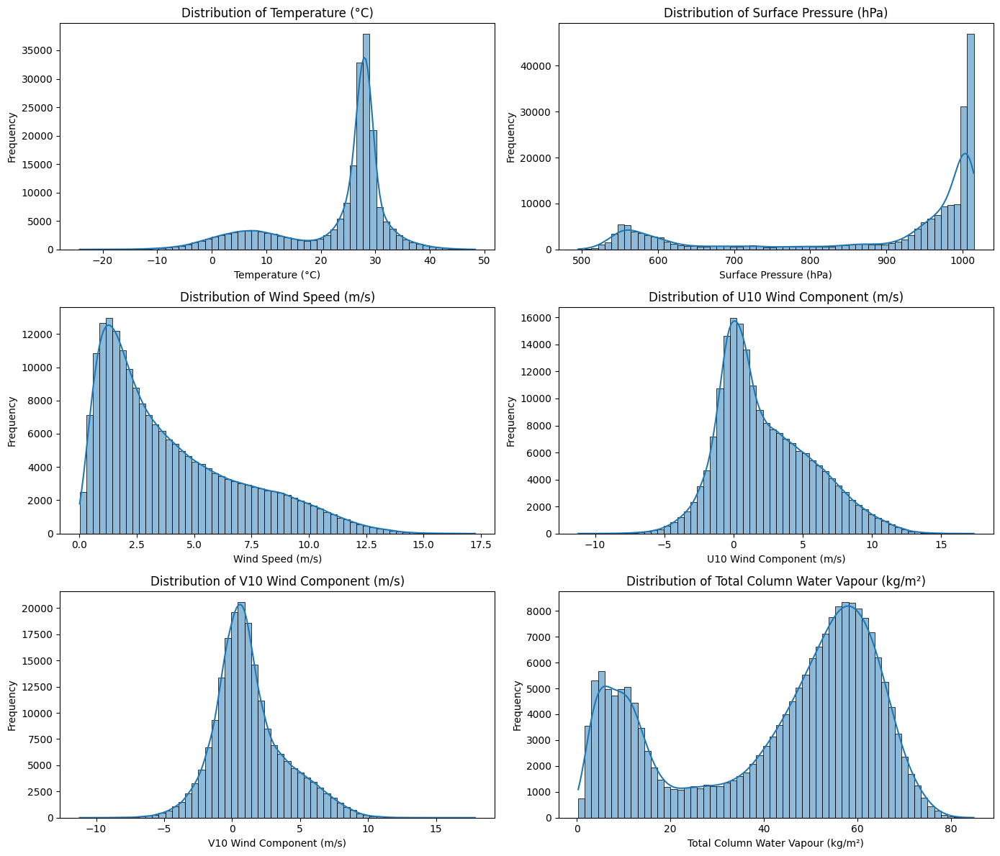

In [ ]:
# Cell 10: Distribution analysis of ERA5 variables

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

variables = [
    ("temperature", "Temperature (°C)"),
    ("pressure", "Surface Pressure (hPa)"),
    ("wind_speed", "Wind Speed (m/s)"),
    ("u10", "U10 Wind Component (m/s)"),
    ("v10", "V10 Wind Component (m/s)"),
    ("tcwv", "Total Column Water Vapour (kg/m²)")
]

# Randomly sample values to keep plotting memory-efficient
sample_size = 200000

for ax, (var, label) in zip(axes.flat, variables):
    values = era5[var].values.ravel()

    if len(values) > sample_size:
        values = np.random.choice(values, sample_size, replace=False)

    sns.histplot(values, bins=60, kde=True, ax=ax)
    ax.set_title(f"Distribution of {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

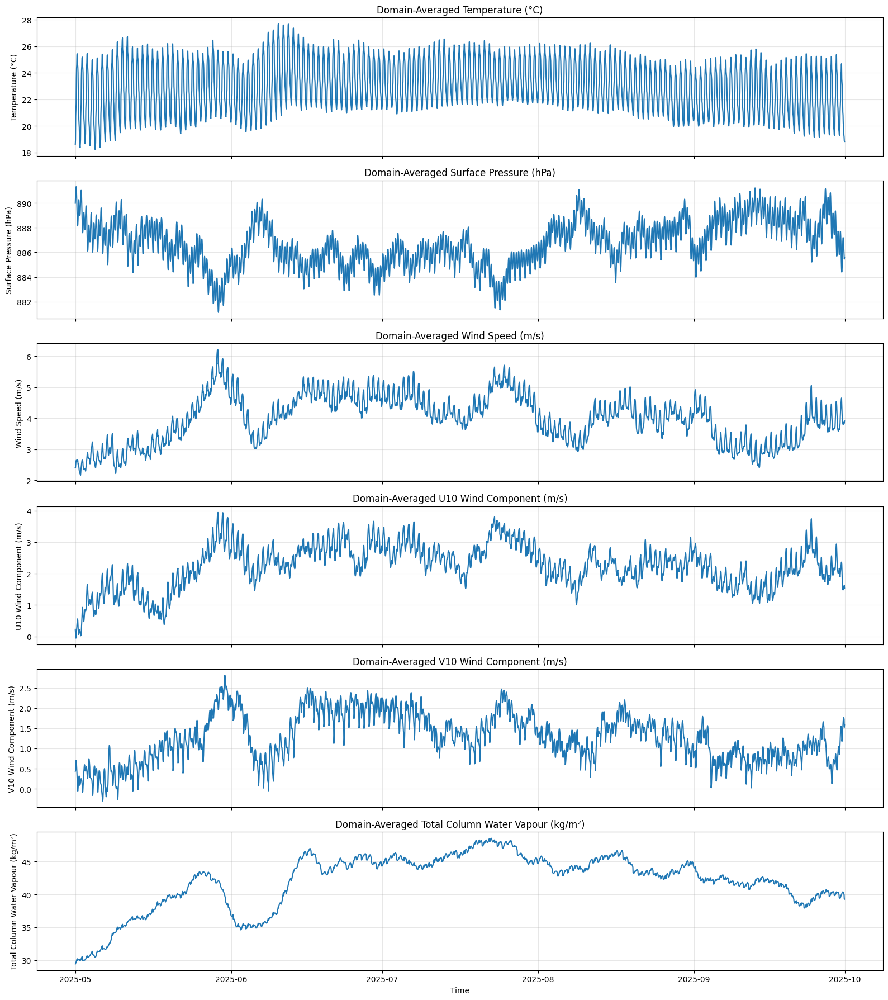

In [ ]:
# Cell 11: Temporal variation of atmospheric variables

# Average each variable over the entire spatial domain for every hour
temporal_mean = era5.mean(dim=["latitude", "longitude"])

fig, axes = plt.subplots(6, 1, figsize=(16, 18), sharex=True)

variables = [
    ("temperature", "Temperature (°C)"),
    ("pressure", "Surface Pressure (hPa)"),
    ("wind_speed", "Wind Speed (m/s)"),
    ("u10", "U10 Wind Component (m/s)"),
    ("v10", "V10 Wind Component (m/s)"),
    ("tcwv", "Total Column Water Vapour (kg/m²)")
]

for ax, (var, label) in zip(axes, variables):
    ax.plot(
        temporal_mean.valid_time,
        temporal_mean[var]
    )
    ax.set_ylabel(label)
    ax.set_title(f"Domain-Averaged {label}")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()

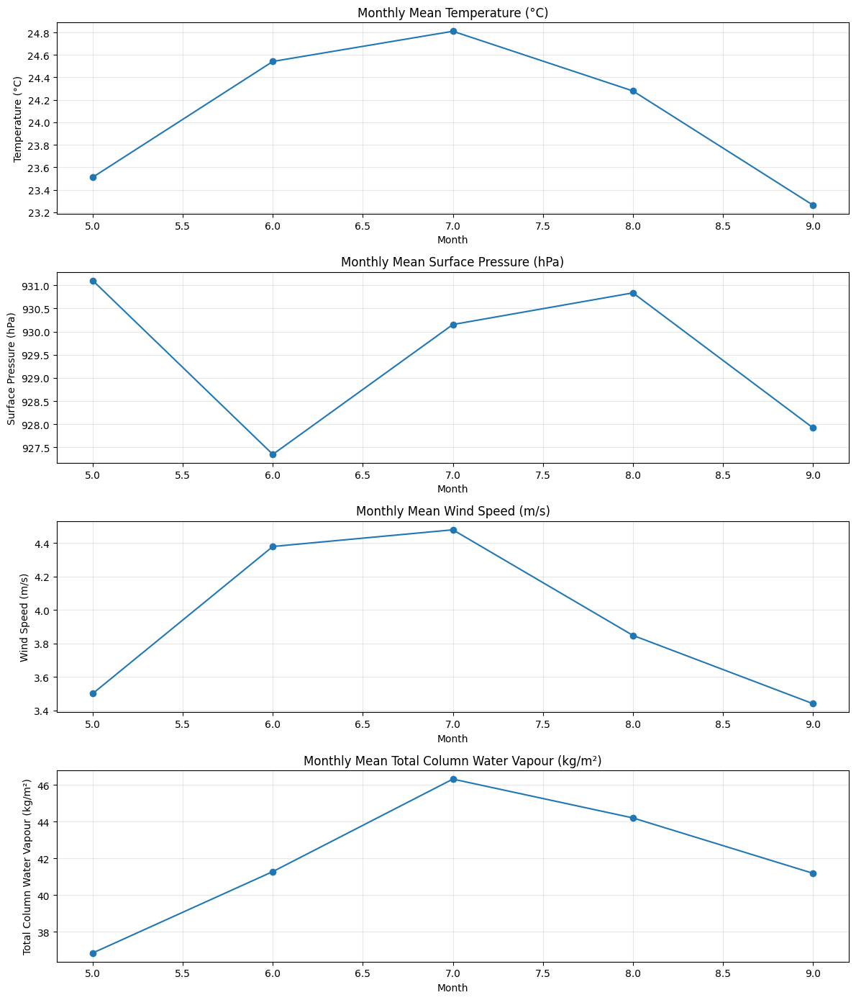

Monthly mean values:
<xarray.Dataset> Size: 208B
Dimensions:      (month: 5)
Coordinates:
  * month        (month) int64 40B 5 6 7 8 9
    number       int64 8B 0
Data variables:
    temperature  (month) float64 40B 23.51 24.54 24.81 24.28 23.26
    pressure     (month) float64 40B 931.1 927.3 930.2 930.8 927.9
    wind_speed   (month) float64 40B 3.501 4.38 4.48 3.848 3.44
    tcwv         (month) float64 40B 36.85 41.28 46.32 44.2 41.19


In [ ]:
# Cell 12: Monthly variation of ERA5 variables

monthly_mean = era5.groupby("valid_time.month").mean(
    dim=["valid_time", "latitude", "longitude"]
)

variables = [
    ("temperature", "Temperature (°C)"),
    ("pressure", "Surface Pressure (hPa)"),
    ("wind_speed", "Wind Speed (m/s)"),
    ("tcwv", "Total Column Water Vapour (kg/m²)")
]

fig, axes = plt.subplots(4, 1, figsize=(12, 14))

for ax, (var, label) in zip(axes, variables):
    ax.plot(
        monthly_mean.month,
        monthly_mean[var],
        marker="o"
    )
    ax.set_title(f"Monthly Mean {label}")
    ax.set_xlabel("Month")
    ax.set_ylabel(label)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Monthly mean values:")
print(monthly_mean[["temperature", "pressure", "wind_speed", "tcwv"]])

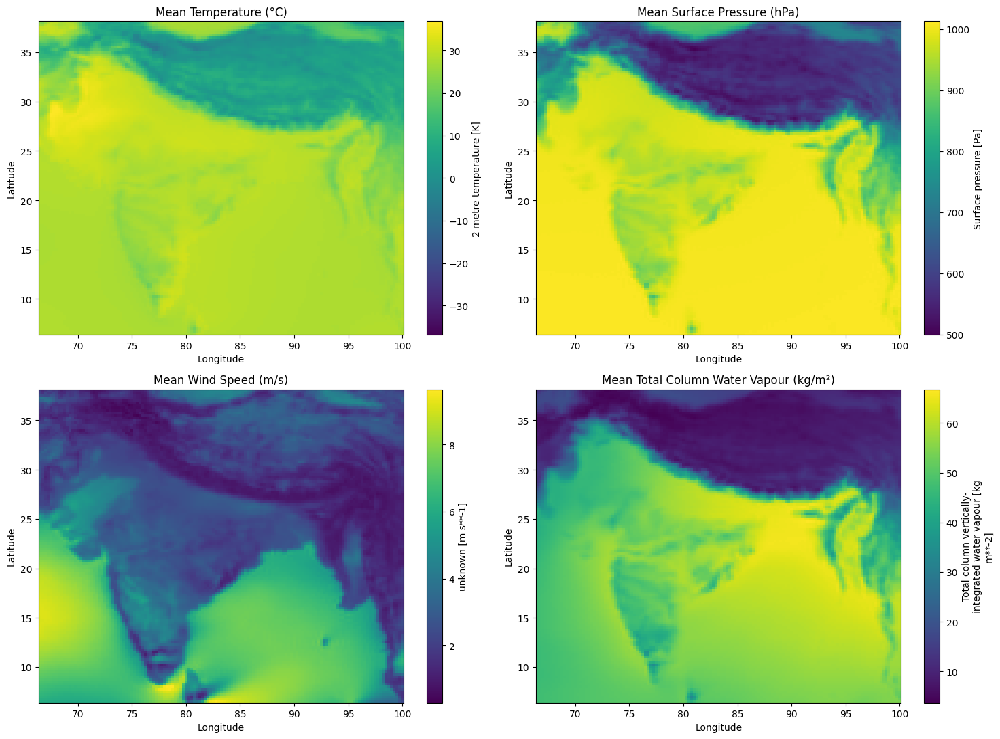

In [ ]:
# Cell 13: Spatial distribution of atmospheric variables

spatial_mean = era5.mean(dim="valid_time")

variables = [
    ("temperature", "Mean Temperature (°C)"),
    ("pressure", "Mean Surface Pressure (hPa)"),
    ("wind_speed", "Mean Wind Speed (m/s)"),
    ("tcwv", "Mean Total Column Water Vapour (kg/m²)")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for ax, (var, title) in zip(axes.flat, variables):
    spatial_mean[var].plot(
        ax=ax,
        cmap="viridis",
        add_colorbar=True
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

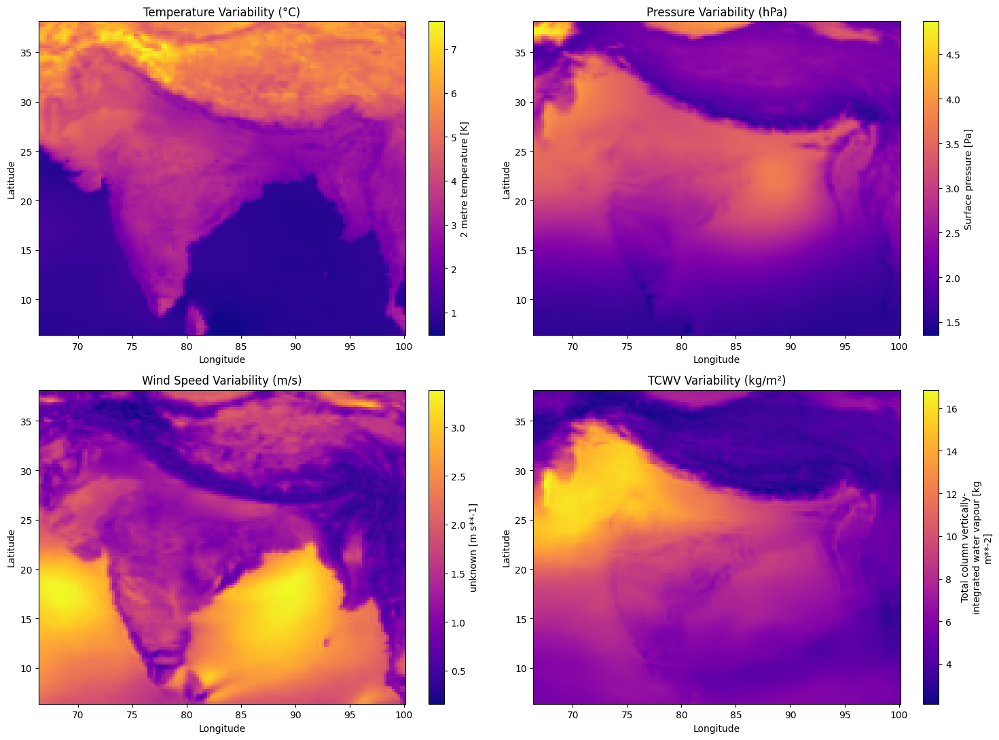

In [ ]:
# Cell 14: Spatial variability of atmospheric variables

spatial_std = era5.std(dim="valid_time")

variables = [
    ("temperature", "Temperature Variability (°C)"),
    ("pressure", "Pressure Variability (hPa)"),
    ("wind_speed", "Wind Speed Variability (m/s)"),
    ("tcwv", "TCWV Variability (kg/m²)")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for ax, (var, title) in zip(axes.flat, variables):
    spatial_std[var].plot(
        ax=ax,
        cmap="plasma",
        add_colorbar=True
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [ ]:
# Cell 15: Extreme atmospheric thresholds

percentiles = [0.90, 0.95, 0.99]

print("Extreme-value thresholds across the complete ERA5 domain:\n")

for var in era5.data_vars:
    print(f"\n========== {var.upper()} ==========")

    for p in percentiles:
        value = era5[var].quantile(p).item()
        print(f"{int(p*100)}th percentile : {value:.2f}")

Extreme-value thresholds across the complete ERA5 domain:


========== TEMPERATURE ==========
90th percentile : 30.78
95th percentile : 33.23
99th percentile : 38.40

========== PRESSURE ==========
90th percentile : 1008.78
95th percentile : 1009.90
99th percentile : 1011.49

========== U10 ==========
90th percentile : 7.17
95th percentile : 8.67
99th percentile : 11.13

========== V10 ==========
90th percentile : 5.08
95th percentile : 6.41
99th percentile : 8.47

========== WIND_SPEED ==========
90th percentile : 8.76
95th percentile : 10.14
99th percentile : 12.27

========== TCWV ==========
90th percentile : 65.02
95th percentile : 68.00
99th percentile : 73.05


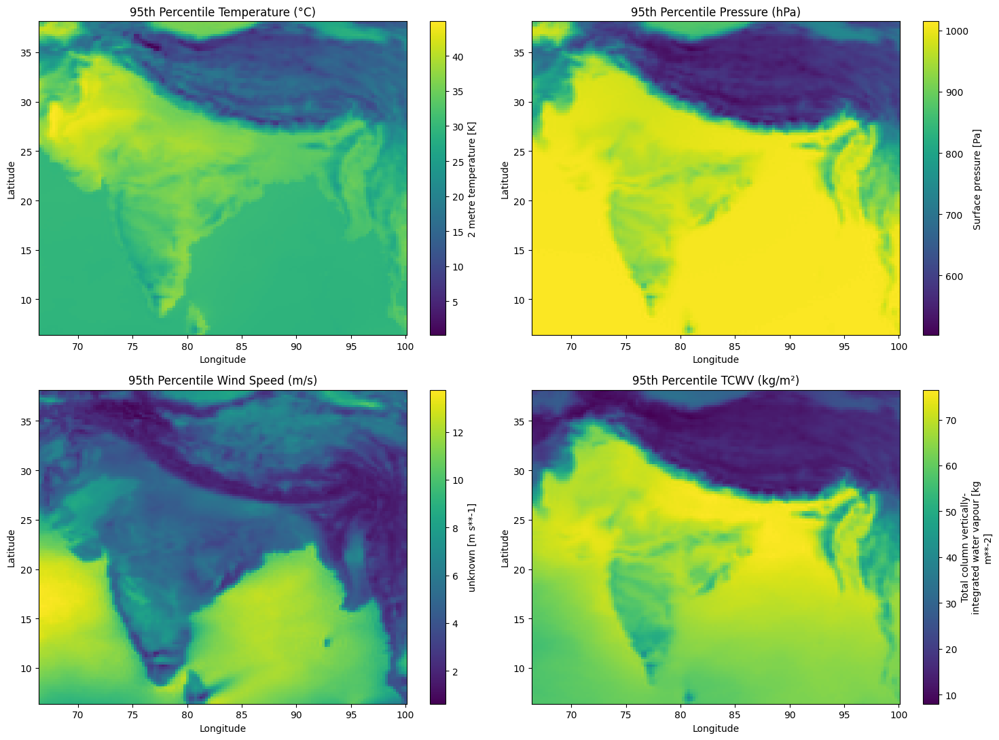

In [ ]:
# Cell 16: Spatial 95th-percentile maps

spatial_p95 = era5.quantile(
    0.95,
    dim="valid_time"
)

variables = [
    ("temperature", "95th Percentile Temperature (°C)"),
    ("pressure", "95th Percentile Pressure (hPa)"),
    ("wind_speed", "95th Percentile Wind Speed (m/s)"),
    ("tcwv", "95th Percentile TCWV (kg/m²)")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for ax, (var, title) in zip(axes.flat, variables):
    spatial_p95[var].plot(
        ax=ax,
        cmap="viridis",
        add_colorbar=True
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# Define file_path and load the dataset 'ds'
file_path = "/content/era5 2025.nc"
ds = xr.open_dataset(file_path)

# Create the 'era5' dataset with calculated variables (from cell 5hRFHwICs0n2)
# Convert temperature from Kelvin to Celsius
t2m_c = ds.t2m - 273.15
# Convert surface pressure from Pa to hPa
sp_hpa = ds.sp / 100
# Calculate wind speed from U and V components
wind_speed = np.sqrt(ds.u10**2 + ds.v10**2)
# Create a new dataset with convenient variables
era5 = xr.Dataset({
    "temperature": t2m_c,
    "pressure": sp_hpa,
    "u10": ds.u10,
    "v10": ds.v10,
    "wind_speed": wind_speed,
    "tcwv": ds.tcwv
})

# Cell 17: Spatial minimum and maximum maps

spatial_min = era5.min(dim="valid_time", skipna=True)
spatial_max = era5.max(dim="valid_time", skipna=True)

variables = [
    ("temperature", "Minimum Temperature (°C)", "viridis"),
    ("pressure", "Minimum Pressure (hPa)", "viridis"),
    ("wind_speed", "Minimum Wind Speed (m/s)", "viridis"),
    ("tcwv", "Minimum TCWV (kg/m²)", "viridis")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for ax, (var, title, cmap) in zip(axes.flat, variables):
    spatial_min[var].plot(
        ax=ax,
        cmap=cmap,
        add_colorbar=True
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()


variables = [
    ("temperature", "Maximum Temperature (°C)", "viridis"),
    ("pressure", "Maximum Pressure (hPa)", "viridis"),
    ("wind_speed", "Maximum Wind Speed (m/s)", "viridis"),
    ("tcwv", "Maximum TCWV (kg/m²)", "viridis")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for ax, (var, title, cmap) in zip(axes.flat, variables):
    spatial_max[var].plot(
        ax=ax,
        cmap=cmap,
        add_colorbar=True
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

NameError: name 'era5' is not defined

In [ ]:
# Check which ERA5-related variables currently exist

print("era5 exists:", "era5" in globals())
print("ds_era5 exists:", "ds_era5" in globals())

# Show currently defined variables containing ERA5-related names
print("\nERA5-related variables:")
print([name for name in globals() if "era" in name.lower()])

era5 exists: False
ds_era5 exists: False

ERA5-related variables:
[]


In [ ]:
# Cell 18: Check available files in Colab

import os

print("Files in /content:\n")

for file in os.listdir("/content"):
    print(file)

Files in /content:

.config
era5 2025.nc
sample_data


In [ ]:
# Cell 19: Load ERA5 NetCDF file

import xarray as xr

file_path = "/content/era5 2025.nc"

ds_era5 = xr.open_dataset(file_path)

print(ds_era5)

<xarray.Dataset> Size: 1GB
Dimensions:     (valid_time: 3672, latitude: 127, longitude: 135)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 29kB 2025-05-01 ... 2025-09-30T23...
  * latitude    (latitude) float64 1kB 38.0 37.75 37.5 37.25 ... 7.0 6.75 6.5
  * longitude   (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
    number      int64 8B ...
    expver      (valid_time) <U4 59kB ...
Data variables:
    u10         (valid_time, latitude, longitude) float32 252MB ...
    v10         (valid_time, latitude, longitude) float32 252MB ...
    t2m         (valid_time, latitude, longitude) float32 252MB ...
    sp          (valid_time, latitude, longitude) float32 252MB ...
    tcwv        (valid_time, latitude, longitude) float32 252MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European 

In [ ]:
# Cell 20: Prepare ERA5 variables for EDA

import numpy as np

era5 = xr.Dataset({
    "temperature": ds_era5["t2m"] - 273.15,
    "pressure": ds_era5["sp"] / 100,
    "wind_speed": np.sqrt(
        ds_era5["u10"]**2 + ds_era5["v10"]**2
    ),
    "tcwv": ds_era5["tcwv"]
})

print(era5)

<xarray.Dataset> Size: 1GB
Dimensions:      (valid_time: 3672, latitude: 127, longitude: 135)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 29kB 2025-05-01 ... 2025-09-30T2...
  * latitude     (latitude) float64 1kB 38.0 37.75 37.5 37.25 ... 7.0 6.75 6.5
  * longitude    (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
    number       int64 8B 0
    expver       (valid_time) <U4 59kB '0001' '0001' '0001' ... '0001' '0001'
Data variables:
    temperature  (valid_time, latitude, longitude) float32 252MB 13.06 ... 26.44
    pressure     (valid_time, latitude, longitude) float32 252MB 878.3 ... 1....
    wind_speed   (valid_time, latitude, longitude) float32 252MB 1.011 ... 2.421
    tcwv         (valid_time, latitude, longitude) float32 252MB ...


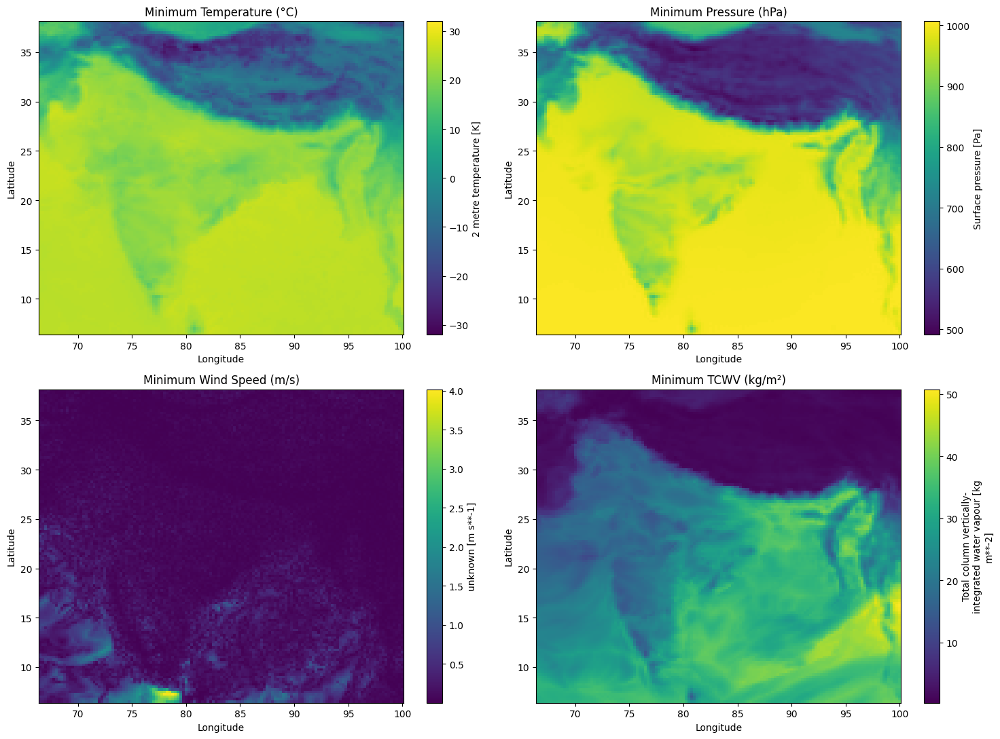

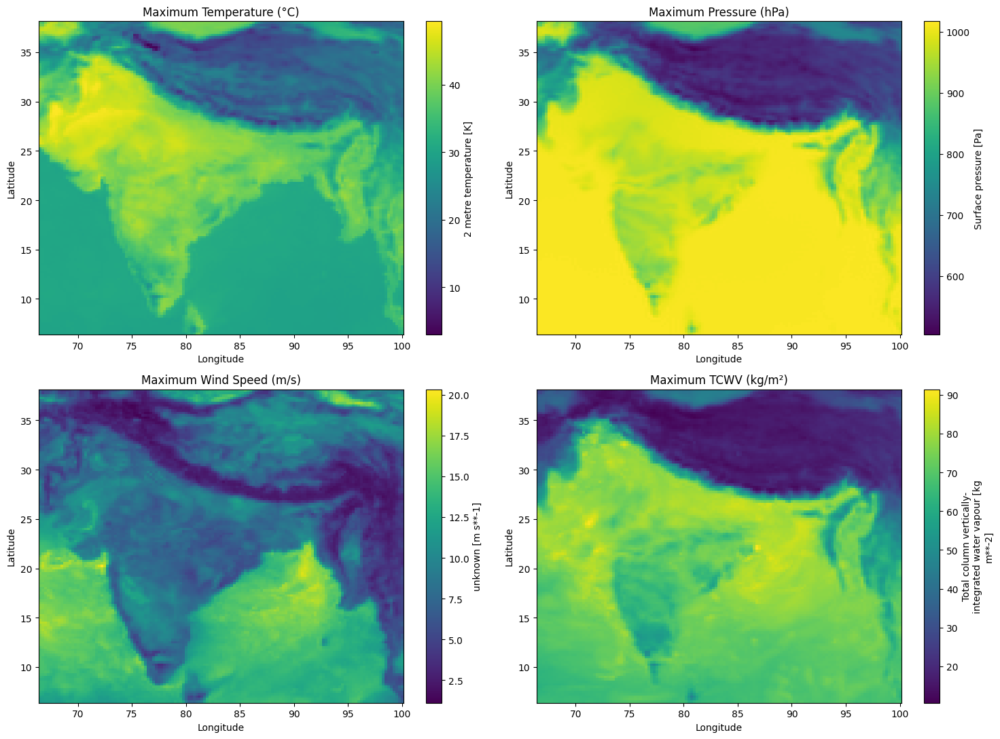

In [ ]:
# Cell 17: Spatial minimum and maximum maps

spatial_min = era5.min(dim="valid_time", skipna=True)
spatial_max = era5.max(dim="valid_time", skipna=True)

variables = [
    ("temperature", "Minimum Temperature (°C)", "viridis"),
    ("pressure", "Minimum Pressure (hPa)", "viridis"),
    ("wind_speed", "Minimum Wind Speed (m/s)", "viridis"),
    ("tcwv", "Minimum TCWV (kg/m²)", "viridis")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for ax, (var, title, cmap) in zip(axes.flat, variables):
    spatial_min[var].plot(
        ax=ax,
        cmap=cmap,
        add_colorbar=True
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()


variables = [
    ("temperature", "Maximum Temperature (°C)", "viridis"),
    ("pressure", "Maximum Pressure (hPa)", "viridis"),
    ("wind_speed", "Maximum Wind Speed (m/s)", "viridis"),
    ("tcwv", "Maximum TCWV (kg/m²)", "viridis")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for ax, (var, title, cmap) in zip(axes.flat, variables):
    spatial_max[var].plot(
        ax=ax,
        cmap=cmap,
        add_colorbar=True
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

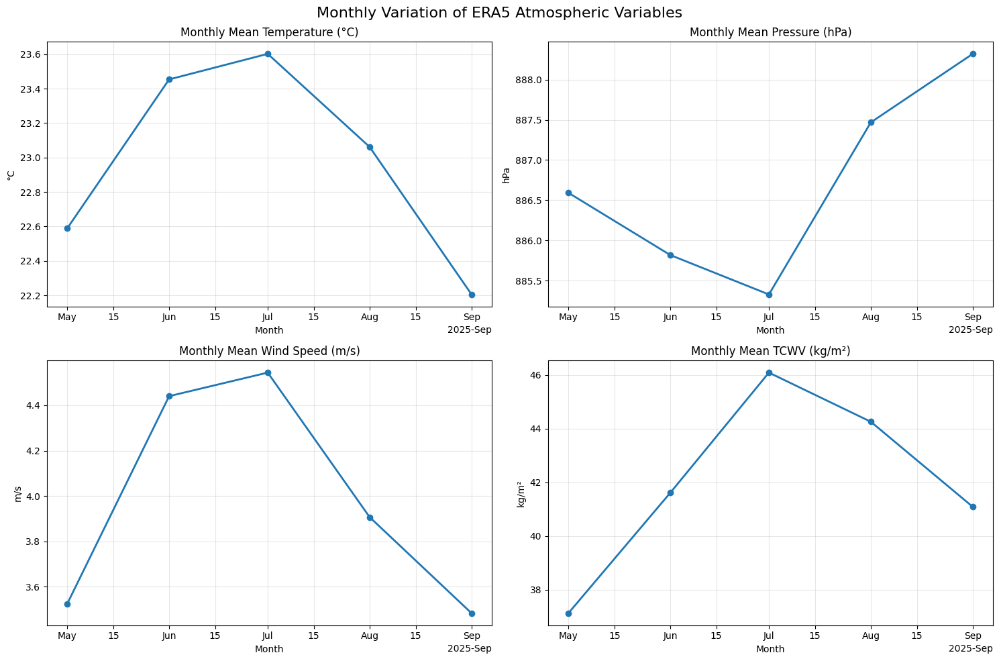

<xarray.Dataset> Size: 128B
Dimensions:      (valid_time: 5)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 40B 2025-05-01 ... 2025-09-01
    number       int64 8B 0
Data variables:
    temperature  (valid_time) float32 20B 22.59 23.45 23.6 23.06 22.21
    pressure     (valid_time) float32 20B 886.6 885.8 885.3 887.5 888.3
    wind_speed   (valid_time) float32 20B 3.524 4.44 4.544 3.907 3.483
    tcwv         (valid_time) float32 20B 37.13 41.61 46.09 44.26 41.09


In [ ]:
# Cell 18: Monthly mean variation of ERA5 variables

import matplotlib.pyplot as plt

# Calculate monthly spatial averages
monthly_mean = (
    era5
    .resample(valid_time="MS")
    .mean()
    .mean(dim=["latitude", "longitude"], skipna=True)
)

variables = [
    ("temperature", "Monthly Mean Temperature (°C)"),
    ("pressure", "Monthly Mean Pressure (hPa)"),
    ("wind_speed", "Monthly Mean Wind Speed (m/s)"),
    ("tcwv", "Monthly Mean TCWV (kg/m²)")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (var, title) in zip(axes.flat, variables):
    monthly_mean[var].plot(
        ax=ax,
        marker="o",
        linewidth=2
    )
    ax.set_title(title)
    ax.set_xlabel("Month")
    ax.set_ylabel(title.split("(")[-1].replace(")", ""))
    ax.grid(True, alpha=0.3)

plt.suptitle("Monthly Variation of ERA5 Atmospheric Variables", fontsize=16)
plt.tight_layout()
plt.show()

print(monthly_mean)

In [ ]:
# Cell 19: Monthly distributions of ERA5 variables

import pandas as pd
import matplotlib.pyplot as plt

# Convert ERA5 data to a dataframe
era5_df = era5.to_dataframe().reset_index()

# Extract month names
era5_df["month"] = era5_df["valid_time"].dt.month
month_names = {
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September"
}
era5_df["month_name"] = era5_df["month"].map(month_names)

variables = [
    ("temperature", "Temperature (°C)"),
    ("pressure", "Pressure (hPa)"),
    ("wind_speed", "Wind Speed (m/s)"),
    ("tcwv", "TCWV (kg/m²)")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (var, ylabel) in zip(axes.flat, variables):
    monthly_data = [
        era5_df.loc[era5_df["month"] == month, var].dropna()
        for month in [5, 6, 7, 8, 9]
    ]

    ax.boxplot(
        monthly_data,
        labels=["May", "June", "July", "August", "September"],
        showfliers=False
    )

    ax.set_title(f"Monthly Distribution of {ylabel}")
    ax.set_xlabel("Month")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)

plt.suptitle("Monthly Distributions of ERA5 Atmospheric Variables", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# Cell 19A: Reload ERA5 after session restart

import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

file_path = "/content/era5 2025.nc"

ds_era5 = xr.open_dataset(file_path)

era5 = xr.Dataset({
    "temperature": ds_era5["t2m"] - 273.15,
    "pressure": ds_era5["sp"] / 100,
    "wind_speed": np.sqrt(
        ds_era5["u10"]**2 + ds_era5["v10"]**2
    ),
    "tcwv": ds_era5["tcwv"]
})

print("ERA5 reloaded successfully.")
print(era5)

ERA5 reloaded successfully.
<xarray.Dataset> Size: 1GB
Dimensions:      (valid_time: 3672, latitude: 127, longitude: 135)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 29kB 2025-05-01 ... 2025-09-30T2...
  * latitude     (latitude) float64 1kB 38.0 37.75 37.5 37.25 ... 7.0 6.75 6.5
  * longitude    (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
    number       int64 8B 0
    expver       (valid_time) <U4 59kB '0001' '0001' '0001' ... '0001' '0001'
Data variables:
    temperature  (valid_time, latitude, longitude) float32 252MB 13.06 ... 26.44
    pressure     (valid_time, latitude, longitude) float32 252MB 878.3 ... 1....
    wind_speed   (valid_time, latitude, longitude) float32 252MB 1.011 ... 2.421
    tcwv         (valid_time, latitude, longitude) float32 252MB ...


Sample dimensions:
Frozen({'valid_time': 306, 'latitude': 32, 'longitude': 34})


/tmp/ipykernel_9366/2528154468.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_9366/2528154468.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_9366/2528154468.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_9366/2528154468.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


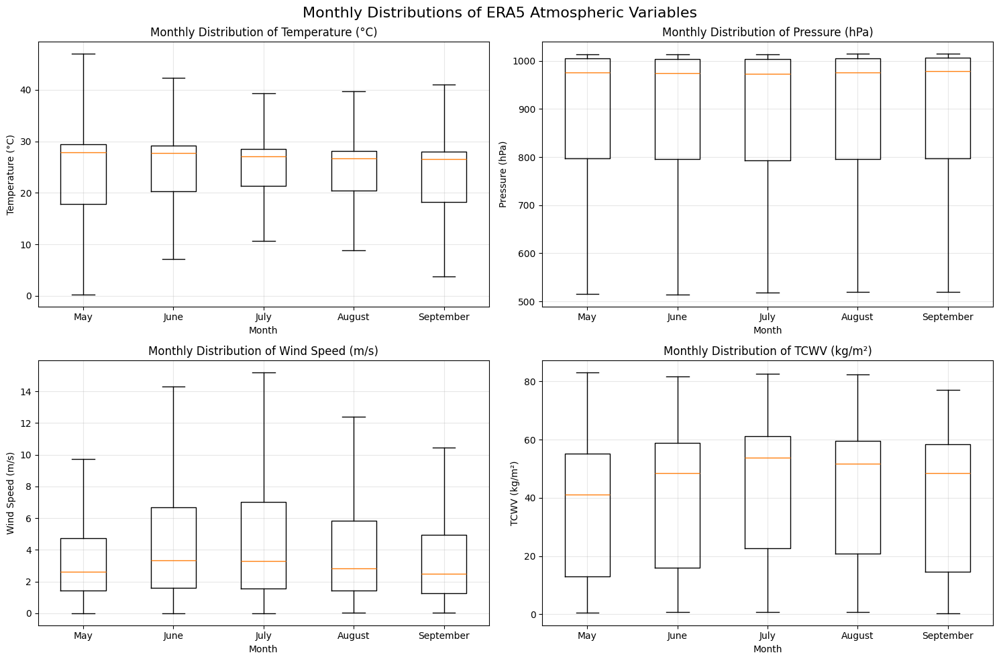

In [ ]:
# Cell 19: Memory-safe monthly boxplots

import matplotlib.pyplot as plt

# Take a smaller representative sample:
# Every 12th hour and every 4th spatial grid point
era5_sample = era5.isel(
    valid_time=slice(None, None, 12),
    latitude=slice(None, None, 4),
    longitude=slice(None, None, 4)
)

print("Sample dimensions:")
print(era5_sample.sizes)

# Convert only the smaller sample to a DataFrame
era5_df = era5_sample.to_dataframe().reset_index()

# Extract month
era5_df["month"] = era5_df["valid_time"].dt.month

months = [5, 6, 7, 8, 9]
month_labels = ["May", "June", "July", "August", "September"]

variables = [
    ("temperature", "Temperature (°C)"),
    ("pressure", "Pressure (hPa)"),
    ("wind_speed", "Wind Speed (m/s)"),
    ("tcwv", "TCWV (kg/m²)")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (var, ylabel) in zip(axes.flat, variables):

    monthly_data = [
        era5_df.loc[era5_df["month"] == month, var].dropna()
        for month in months
    ]

    ax.boxplot(
        monthly_data,
        labels=month_labels,
        showfliers=False
    )

    ax.set_title(f"Monthly Distribution of {ylabel}")
    ax.set_xlabel("Month")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Monthly Distributions of ERA5 Atmospheric Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()

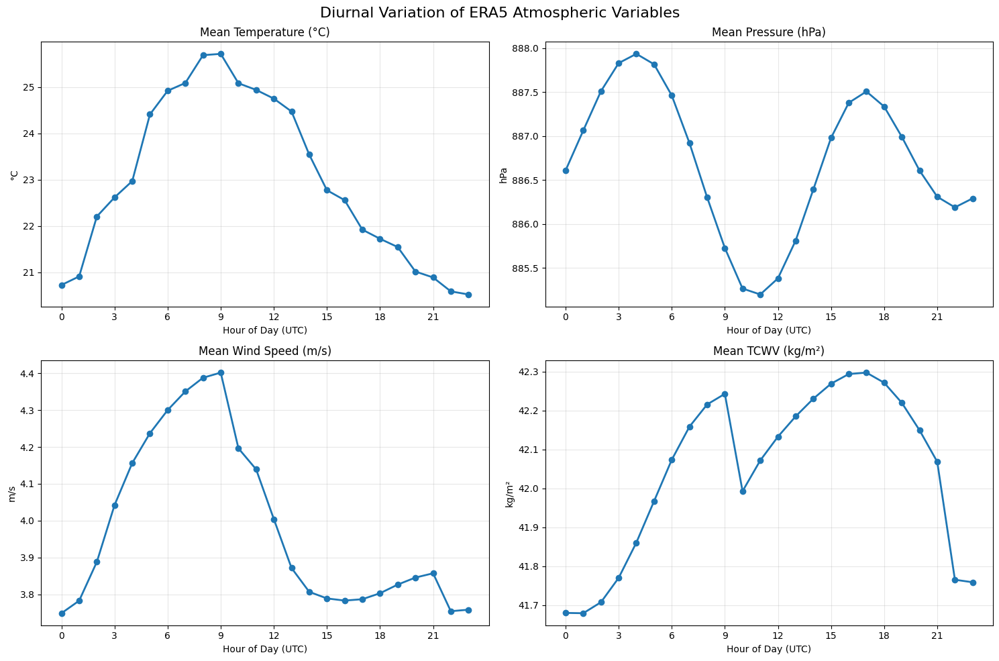

<xarray.Dataset> Size: 968B
Dimensions:      (hour: 24)
Coordinates:
  * hour         (hour) int64 192B 0 1 2 3 4 5 6 7 8 ... 16 17 18 19 20 21 22 23
    number       int64 8B 0
Data variables:
    temperature  (hour) float64 192B 20.73 20.91 22.21 ... 20.89 20.59 20.52
    pressure     (hour) float64 192B 886.6 887.1 887.5 ... 886.3 886.2 886.3
    wind_speed   (hour) float64 192B 3.749 3.783 3.888 ... 3.857 3.754 3.758
    tcwv         (hour) float64 192B 41.68 41.68 41.71 ... 42.07 41.77 41.76


In [ ]:
# Cell 20: Diurnal variation of ERA5 atmospheric variables

# Spatial average at each time step
spatial_hourly_mean = era5.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

# Group by hour of the day
diurnal_mean = spatial_hourly_mean.groupby(
    "valid_time.hour"
).mean()

variables = [
    ("temperature", "Mean Temperature (°C)"),
    ("pressure", "Mean Pressure (hPa)"),
    ("wind_speed", "Mean Wind Speed (m/s)"),
    ("tcwv", "Mean TCWV (kg/m²)")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (var, title) in zip(axes.flat, variables):
    diurnal_mean[var].plot(
        ax=ax,
        marker="o",
        linewidth=2
    )

    ax.set_title(title)
    ax.set_xlabel("Hour of Day (UTC)")
    ax.set_ylabel(title.split("(")[-1].replace(")", ""))
    ax.set_xticks(range(0, 24, 3))
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Diurnal Variation of ERA5 Atmospheric Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()

print(diurnal_mean)

In [ ]:
# Cell 21: Find exact hourly maxima, minima, and ranges

for var in ["temperature", "pressure", "wind_speed", "tcwv"]:

    data = diurnal_mean[var]

    min_hour = int(data.idxmin().values)
    max_hour = int(data.idxmax().values)

    min_value = float(data.min().values)
    max_value = float(data.max().values)
    amplitude = max_value - min_value

    print(f"\n========== {var.upper()} ==========")
    print(f"Minimum: {min_value:.3f} at {min_hour:02d}:00 UTC")
    print(f"Maximum: {max_value:.3f} at {max_hour:02d}:00 UTC")
    print(f"Diurnal range: {amplitude:.3f}")

    print("\nHourly values:")
    for hour, value in zip(data.hour.values, data.values):
        print(f"{int(hour):02d}:00 UTC → {float(value):.3f}")


========== TEMPERATURE ==========
Minimum: 20.523 at 23:00 UTC
Maximum: 25.719 at 09:00 UTC
Diurnal range: 5.196

Hourly values:
00:00 UTC → 20.728
01:00 UTC → 20.913
02:00 UTC → 22.207
03:00 UTC → 22.619
04:00 UTC → 22.972
05:00 UTC → 24.412
06:00 UTC → 24.922
07:00 UTC → 25.091
08:00 UTC → 25.691
09:00 UTC → 25.719
10:00 UTC → 25.085
11:00 UTC → 24.941
12:00 UTC → 24.753
13:00 UTC → 24.475
14:00 UTC → 23.544
15:00 UTC → 22.774
16:00 UTC → 22.560
17:00 UTC → 21.923
18:00 UTC → 21.726
19:00 UTC → 21.547
20:00 UTC → 21.018
21:00 UTC → 20.890
22:00 UTC → 20.590
23:00 UTC → 20.523

========== PRESSURE ==========
Minimum: 885.197 at 11:00 UTC
Maximum: 887.936 at 04:00 UTC
Diurnal range: 2.739

Hourly values:
00:00 UTC → 886.609
01:00 UTC → 887.064
02:00 UTC → 887.512
03:00 UTC → 887.831
04:00 UTC → 887.936
05:00 UTC → 887.818
06:00 UTC → 887.463
07:00 UTC → 886.921
08:00 UTC → 886.302
09:00 UTC → 885.726
10:00 UTC → 885.265
11:00 UTC → 885.197
12:00 UTC → 885.380
13:00 UTC → 885.810
14:00

Pearson correlation matrix:
             temperature  pressure  wind_speed   tcwv
temperature        1.000    -0.294       0.398  0.239
pressure          -0.294     1.000      -0.725 -0.377
wind_speed         0.398    -0.725       1.000  0.591
tcwv               0.239    -0.377       0.591  1.000


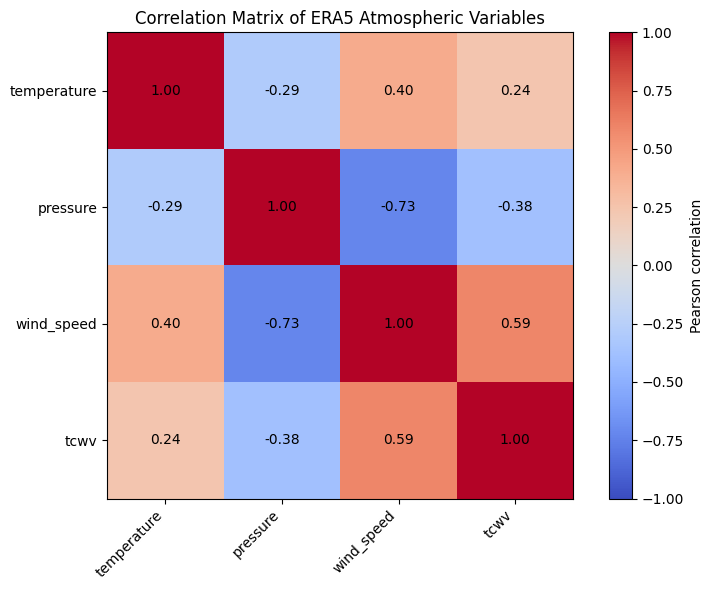

In [ ]:
# Cell 22: Correlation analysis of ERA5 atmospheric variables

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Calculate spatial mean at each hourly time step
era5_spatial_mean = era5.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

# Convert the small spatial-mean dataset to a DataFrame
era5_mean_df = era5_spatial_mean.to_dataframe()

# Calculate Pearson correlation matrix
corr_matrix = era5_mean_df[
    ["temperature", "pressure", "wind_speed", "tcwv"]
].corr()

# Print numerical correlation matrix
print("Pearson correlation matrix:")
print(corr_matrix.round(3))

# Plot correlation matrix
fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))

ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
ax.set_yticklabels(corr_matrix.columns)

# Add correlation values inside cells
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        ax.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title("Correlation Matrix of ERA5 Atmospheric Variables")

fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

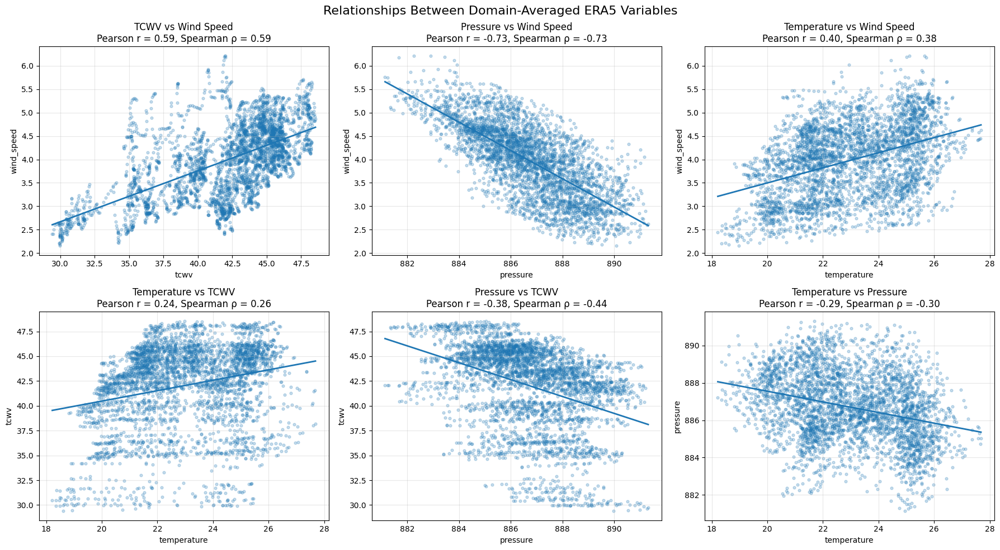

Pearson and Spearman correlations:

TCWV vs Wind Speed
  Pearson correlation : 0.5906
  Spearman correlation: 0.5882

Pressure vs Wind Speed
  Pearson correlation : -0.7254
  Spearman correlation: -0.7303

Temperature vs Wind Speed
  Pearson correlation : 0.3984
  Spearman correlation: 0.3843

Temperature vs TCWV
  Pearson correlation : 0.2393
  Spearman correlation: 0.2585

Pressure vs TCWV
  Pearson correlation : -0.3768
  Spearman correlation: -0.4396

Temperature vs Pressure
  Pearson correlation : -0.2939
  Spearman correlation: -0.2978



In [ ]:
# Cell 23: Scatter plots and Pearson/Spearman correlations

import matplotlib.pyplot as plt
import pandas as pd

# Use the already calculated spatial-mean dataset
era5_mean_df = era5_spatial_mean.to_dataframe().reset_index()

# Select relevant variables
era5_mean_df = era5_mean_df[
    ["temperature", "pressure", "wind_speed", "tcwv"]
].dropna()

relationships = [
    ("tcwv", "wind_speed", "TCWV vs Wind Speed"),
    ("pressure", "wind_speed", "Pressure vs Wind Speed"),
    ("temperature", "wind_speed", "Temperature vs Wind Speed"),
    ("temperature", "tcwv", "Temperature vs TCWV"),
    ("pressure", "tcwv", "Pressure vs TCWV"),
    ("temperature", "pressure", "Temperature vs Pressure")
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (x_var, y_var, title) in zip(axes.flat, relationships):

    x = era5_mean_df[x_var]
    y = era5_mean_df[y_var]

    # Scatter plot
    ax.scatter(
        x,
        y,
        alpha=0.25,
        s=12
    )

    # Linear regression line
    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept

    ax.plot(
        x_line,
        y_line,
        linewidth=2
    )

    pearson_r = x.corr(y, method="pearson")
    spearman_r = x.corr(y, method="spearman")

    ax.set_title(
        f"{title}\n"
        f"Pearson r = {pearson_r:.2f}, "
        f"Spearman ρ = {spearman_r:.2f}"
    )

    ax.set_xlabel(x_var)
    ax.set_ylabel(y_var)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Relationships Between Domain-Averaged ERA5 Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Print exact correlation values
print("Pearson and Spearman correlations:\n")

for x_var, y_var, title in relationships:
    x = era5_mean_df[x_var]
    y = era5_mean_df[y_var]

    pearson_r = x.corr(y, method="pearson")
    spearman_r = x.corr(y, method="spearman")

    print(f"{title}")
    print(f"  Pearson correlation : {pearson_r:.4f}")
    print(f"  Spearman correlation: {spearman_r:.4f}")
    print()

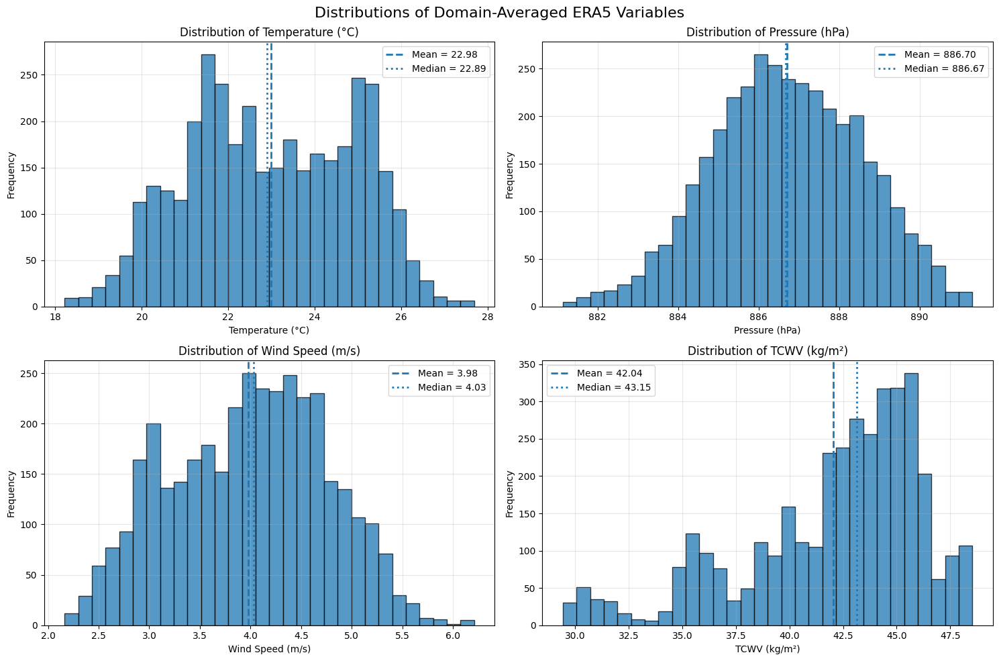

Statistical summary of domain-averaged ERA5 variables:


========== TEMPERATURE (°C) ==========
Count      : 3672
Mean       : 22.984
Median     : 22.891
Std. Dev.  : 1.908
Minimum    : 18.214
Maximum    : 27.688
Skewness   : -0.028
Kurtosis   : -0.967
Percentiles:
  1th percentile: 19.129
  5th percentile: 19.968
  25th percentile: 21.509
  50th percentile: 22.891
  75th percentile: 24.720
  95th percentile: 25.853
  99th percentile: 26.556

========== PRESSURE (HPA) ==========
Count      : 3672
Mean       : 886.701
Median     : 886.670
Std. Dev.  : 1.852
Minimum    : 881.141
Maximum    : 891.314
Skewness   : -0.077
Kurtosis   : -0.373
Percentiles:
  1th percentile: 882.262
  5th percentile: 883.639
  25th percentile: 885.418
  50th percentile: 886.670
  75th percentile: 888.049
  95th percentile: 889.735
  99th percentile: 890.540

========== WIND SPEED (M/S) ==========
Count      : 3672
Mean       : 3.980
Median     : 4.031
Std. Dev.  : 0.770
Minimum    : 2.163
Maximum    : 6.209
Sk

In [ ]:
# Cell 24: Distribution plots and statistical summary

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the already calculated hourly spatial means
era5_mean_df = era5_spatial_mean.to_dataframe().reset_index()

variables = [
    ("temperature", "Temperature (°C)"),
    ("pressure", "Pressure (hPa)"),
    ("wind_speed", "Wind Speed (m/s)"),
    ("tcwv", "TCWV (kg/m²)")
]

# Create distribution plots
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (var, label) in zip(axes.flat, variables):

    values = era5_mean_df[var].dropna()

    ax.hist(
        values,
        bins=30,
        edgecolor="black",
        alpha=0.75
    )

    ax.axvline(
        values.mean(),
        linestyle="--",
        linewidth=2,
        label=f"Mean = {values.mean():.2f}"
    )

    ax.axvline(
        values.median(),
        linestyle=":",
        linewidth=2,
        label=f"Median = {values.median():.2f}"
    )

    ax.set_title(f"Distribution of {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Frequency")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Distributions of Domain-Averaged ERA5 Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Print statistical summary
print("Statistical summary of domain-averaged ERA5 variables:\n")

for var, label in variables:

    values = era5_mean_df[var].dropna()

    print(f"\n========== {label.upper()} ==========")
    print(f"Count      : {len(values)}")
    print(f"Mean       : {values.mean():.3f}")
    print(f"Median     : {values.median():.3f}")
    print(f"Std. Dev.  : {values.std():.3f}")
    print(f"Minimum    : {values.min():.3f}")
    print(f"Maximum    : {values.max():.3f}")
    print(f"Skewness   : {values.skew():.3f}")
    print(f"Kurtosis   : {values.kurtosis():.3f}")

    print("Percentiles:")
    for p in [1, 5, 25, 50, 75, 95, 99]:
        print(f"  {p}th percentile: {values.quantile(p / 100):.3f}")

In [ ]:
# Cell 25: Monthly Pearson and Spearman correlation analysis

import pandas as pd
import numpy as np

# Create a DataFrame from the hourly spatial means
monthly_corr_df = era5_spatial_mean.to_dataframe().reset_index()

# Extract month number and name
monthly_corr_df["month"] = monthly_corr_df["valid_time"].dt.month

month_names = {
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September"
}

monthly_corr_df["month_name"] = monthly_corr_df["month"].map(month_names)

variables = [
    "temperature",
    "pressure",
    "wind_speed",
    "tcwv"
]

months = [5, 6, 7, 8, 9]

# Calculate and print monthly correlations
for month in months:

    month_data = monthly_corr_df[
        monthly_corr_df["month"] == month
    ][variables].dropna()

    pearson_corr = month_data.corr(method="pearson")
    spearman_corr = month_data.corr(method="spearman")

    print("\n" + "=" * 60)
    print(f"{month_names[month].upper()} — Pearson correlation")
    print("=" * 60)
    print(pearson_corr.round(3))

    print("\n" + "=" * 60)
    print(f"{month_names[month].upper()} — Spearman correlation")
    print("=" * 60)
    print(spearman_corr.round(3))


MAY — Pearson correlation
             temperature  pressure  wind_speed   tcwv
temperature        1.000    -0.242       0.289  0.199
pressure          -0.242     1.000      -0.830 -0.666
wind_speed         0.289    -0.830       1.000  0.773
tcwv               0.199    -0.666       0.773  1.000

MAY — Spearman correlation
             temperature  pressure  wind_speed   tcwv
temperature        1.000    -0.245       0.352  0.200
pressure          -0.245     1.000      -0.816 -0.684
wind_speed         0.352    -0.816       1.000  0.862
tcwv               0.200    -0.684       0.862  1.000

JUNE — Pearson correlation
             temperature  pressure  wind_speed   tcwv
temperature        1.000    -0.210       0.379  0.195
pressure          -0.210     1.000      -0.710 -0.541
wind_speed         0.379    -0.710       1.000  0.660
tcwv               0.195    -0.541       0.660  1.000

JUNE — Spearman correlation
             temperature  pressure  wind_speed   tcwv
temperature        1.000

In [ ]:
# Cell 26: Extreme atmospheric-condition thresholds

import numpy as np
import pandas as pd

# Prepare the hourly spatial-mean DataFrame
extreme_df = era5_spatial_mean.to_dataframe().reset_index()

variables = [
    "temperature",
    "pressure",
    "wind_speed",
    "tcwv"
]

print("Extreme-value thresholds across the complete ERA5 domain:\n")

for var in variables:

    values = extreme_df[var].dropna()

    p01 = values.quantile(0.01)
    p05 = values.quantile(0.05)
    p90 = values.quantile(0.90)
    p95 = values.quantile(0.95)
    p99 = values.quantile(0.99)

    print("\n" + "=" * 55)
    print(f"{var.upper()}")
    print("=" * 55)

    print(f"1st percentile  : {p01:.3f}")
    print(f"5th percentile  : {p05:.3f}")
    print(f"90th percentile : {p90:.3f}")
    print(f"95th percentile : {p95:.3f}")
    print(f"99th percentile : {p99:.3f}")

    print(f"Values above 90th percentile: {(values > p90).sum()}")
    print(f"Values above 95th percentile: {(values > p95).sum()}")
    print(f"Values above 99th percentile: {(values > p99).sum()}")

    print(f"Values below 5th percentile : {(values < p05).sum()}")
    print(f"Values below 1st percentile : {(values < p01).sum()}")

Extreme-value thresholds across the complete ERA5 domain:


TEMPERATURE
1st percentile  : 19.129
5th percentile  : 19.968
90th percentile : 25.462
95th percentile : 25.853
99th percentile : 26.556
Values above 90th percentile: 368
Values above 95th percentile: 184
Values above 99th percentile: 37
Values below 5th percentile : 184
Values below 1st percentile : 37

PRESSURE
1st percentile  : 882.262
5th percentile  : 883.639
90th percentile : 889.134
95th percentile : 889.735
99th percentile : 890.540
Values above 90th percentile: 368
Values above 95th percentile: 184
Values above 99th percentile: 37
Values below 5th percentile : 184
Values below 1st percentile : 37

WIND_SPEED
1st percentile  : 2.421
5th percentile  : 2.709
90th percentile : 4.974
95th percentile : 5.208
99th percentile : 5.581
Values above 90th percentile: 368
Values above 95th percentile: 184
Values above 99th percentile: 37
Values below 5th percentile : 184
Values below 1st percentile : 37

TCWV
1st percentile  : 30.

In [ ]:
# Cell 27: Identify dates and times of extreme atmospheric conditions

import pandas as pd

# Convert spatial-mean ERA5 data to a small DataFrame
extreme_dates_df = era5_spatial_mean.to_dataframe().reset_index()

variables = [
    "temperature",
    "pressure",
    "wind_speed",
    "tcwv"
]

for var in variables:

    data = extreme_dates_df[["valid_time", var]].dropna()

    # Highest and lowest 10 observations
    highest = data.nlargest(10, var)
    lowest = data.nsmallest(10, var)

    print("\n" + "=" * 65)
    print(f"{var.upper()} — HIGHEST 10 VALUES")
    print("=" * 65)
    print(highest.to_string(index=False))

    print("\n" + "=" * 65)
    print(f"{var.upper()} — LOWEST 10 VALUES")
    print("=" * 65)
    print(lowest.to_string(index=False))


TEMPERATURE — HIGHEST 10 VALUES
         valid_time  temperature
2025-06-10 09:00:00    27.688158
2025-06-12 09:00:00    27.663820
2025-06-12 08:00:00    27.623816
2025-06-10 08:00:00    27.601654
2025-06-11 09:00:00    27.595852
2025-06-11 08:00:00    27.564507
2025-06-13 09:00:00    27.367968
2025-06-13 08:00:00    27.356802
2025-06-09 09:00:00    27.220001
2025-06-09 08:00:00    27.119818

TEMPERATURE — LOWEST 10 VALUES
         valid_time  temperature
2025-05-04 23:00:00    18.214060
2025-05-04 22:00:00    18.343344
2025-05-01 23:00:00    18.353365
2025-05-05 23:00:00    18.369398
2025-05-05 00:00:00    18.468727
2025-05-05 22:00:00    18.490047
2025-05-03 23:00:00    18.490744
2025-05-01 22:00:00    18.494064
2025-05-03 22:00:00    18.526060
2025-05-01 00:00:00    18.600122

PRESSURE — HIGHEST 10 VALUES
         valid_time   pressure
2025-05-01 04:00:00 891.314453
2025-05-01 03:00:00 891.269226
2025-09-13 04:00:00 891.208435
2025-09-27 04:00:00 891.158447
2025-05-01 05:00:00 891.

In [ ]:
# Cell 27: Identify dates and times of extreme atmospheric conditions

import pandas as pd

# Convert spatial-mean ERA5 data to a small DataFrame
extreme_dates_df = era5_spatial_mean.to_dataframe().reset_index()

variables = [
    "temperature",
    "pressure",
    "wind_speed",
    "tcwv"
]

for var in variables:

    data = extreme_dates_df[["valid_time", var]].dropna()

    # Highest and lowest 10 observations
    highest = data.nlargest(10, var)
    lowest = data.nsmallest(10, var)

    print("\n" + "=" * 65)
    print(f"{var.upper()} — HIGHEST 10 VALUES")
    print("=" * 65)
    print(highest.to_string(index=False))

    print("\n" + "=" * 65)
    print(f"{var.upper()} — LOWEST 10 VALUES")
    print("=" * 65)
    print(lowest.to_string(index=False))


TEMPERATURE — HIGHEST 10 VALUES
         valid_time  temperature
2025-06-10 09:00:00    27.688158
2025-06-12 09:00:00    27.663820
2025-06-12 08:00:00    27.623816
2025-06-10 08:00:00    27.601654
2025-06-11 09:00:00    27.595852
2025-06-11 08:00:00    27.564507
2025-06-13 09:00:00    27.367968
2025-06-13 08:00:00    27.356802
2025-06-09 09:00:00    27.220001
2025-06-09 08:00:00    27.119818

TEMPERATURE — LOWEST 10 VALUES
         valid_time  temperature
2025-05-04 23:00:00    18.214060
2025-05-04 22:00:00    18.343344
2025-05-01 23:00:00    18.353365
2025-05-05 23:00:00    18.369398
2025-05-05 00:00:00    18.468727
2025-05-05 22:00:00    18.490047
2025-05-03 23:00:00    18.490744
2025-05-01 22:00:00    18.494064
2025-05-03 22:00:00    18.526060
2025-05-01 00:00:00    18.600122

PRESSURE — HIGHEST 10 VALUES
         valid_time   pressure
2025-05-01 04:00:00 891.314453
2025-05-01 03:00:00 891.269226
2025-09-13 04:00:00 891.208435
2025-09-27 04:00:00 891.158447
2025-05-01 05:00:00 891.

In [ ]:
# Cell 1: Check IMD and ERA5 datasets

print("========== IMD DATASET ==========")
print(imd)
print("\nIMD dimensions:")
print(imd.dims)

print("\n========== ERA5 DATASET ==========")
print(era5)
print("\nERA5 dimensions:")
print(era5.dims)

print("\nIMD time range:")
print(imd.time.min().values, "to", imd.time.max().values)

print("\nERA5 time range:")
print(era5.valid_time.min().values, "to", era5.valid_time.max().values)

========== IMD DATASET ==========


NameError: name 'imd' is not defined

In [ ]:
# Reload IMD rainfall dataset

import xarray as xr
import numpy as np
import pandas as pd

imd = xr.open_dataset("/content/imd.nc")

print(imd)
print("\nVariables:", list(imd.data_vars))
print("\nDimensions:", imd.dims)

<xarray.Dataset> Size: 25MB
Dimensions:    (TIME: 365, LATITUDE: 129, LONGITUDE: 135)
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2025-01-01 2025-01-02 ... 2025-12-31
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Data variables:
    RAINFALL   (TIME, LATITUDE, LONGITUDE) float32 25MB ...
Attributes:
    history:      FERRET V6.82    9-Apr-26
    Conventions:  CF-1.0

Variables: ['RAINFALL']

Dimensions: FrozenMappingWarningOnValuesAccess({'TIME': 365, 'LATITUDE': 129, 'LONGITUDE': 135})


In [ ]:
# Check both datasets

print("========== IMD ==========")
print(imd)

print("\n========== ERA5 ==========")
print(era5)

print("\nIMD time range:")
print(imd.TIME.min().values, "to", imd.TIME.max().values)

print("\nERA5 time range:")
print(era5.valid_time.min().values, "to", era5.valid_time.max().values)

========== IMD ==========
<xarray.Dataset> Size: 25MB
Dimensions:    (TIME: 365, LATITUDE: 129, LONGITUDE: 135)
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2025-01-01 2025-01-02 ... 2025-12-31
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Data variables:
    RAINFALL   (TIME, LATITUDE, LONGITUDE) float32 25MB ...
Attributes:
    history:      FERRET V6.82    9-Apr-26
    Conventions:  CF-1.0

========== ERA5 ==========


NameError: name 'era5' is not defined

In [ ]:
# Reload and prepare ERA5 dataset

import xarray as xr
import numpy as np

ds_era5 = xr.open_dataset("/content/era5 2025.nc")

era5 = xr.Dataset({
    "temperature": ds_era5["t2m"] - 273.15,
    "pressure": ds_era5["sp"] / 100,
    "wind_speed": np.sqrt(
        ds_era5["u10"]**2 + ds_era5["v10"]**2
    ),
    "tcwv": ds_era5["tcwv"]
})

print(era5)

<xarray.Dataset> Size: 1GB
Dimensions:      (valid_time: 3672, latitude: 127, longitude: 135)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 29kB 2025-05-01 ... 2025-09-30T2...
  * latitude     (latitude) float64 1kB 38.0 37.75 37.5 37.25 ... 7.0 6.75 6.5
  * longitude    (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
    number       int64 8B 0
    expver       (valid_time) <U4 59kB '0001' '0001' '0001' ... '0001' '0001'
Data variables:
    temperature  (valid_time, latitude, longitude) float32 252MB 13.06 ... 26.44
    pressure     (valid_time, latitude, longitude) float32 252MB 878.3 ... 1....
    wind_speed   (valid_time, latitude, longitude) float32 252MB 1.011 ... 2.421
    tcwv         (valid_time, latitude, longitude) float32 252MB ...


In [ ]:
# Check spatial coordinates of IMD and ERA5

print("IMD latitude range:")
print(imd.LATITUDE.min().values, "to", imd.LATITUDE.max().values)

print("\nERA5 latitude range:")
print(era5.latitude.min().values, "to", era5.latitude.max().values)

print("\nIMD longitude range:")
print(imd.LONGITUDE.min().values, "to", imd.LONGITUDE.max().values)

print("\nERA5 longitude range:")
print(era5.longitude.min().values, "to", era5.longitude.max().values)

print("\nIMD latitude spacing:")
print(np.unique(np.round(np.diff(imd.LATITUDE.values), 4)))

print("\nERA5 latitude spacing:")
print(np.unique(np.round(np.diff(era5.latitude.values), 4)))

print("\nIMD longitude spacing:")
print(np.unique(np.round(np.diff(imd.LONGITUDE.values), 4)))

print("\nERA5 longitude spacing:")
print(np.unique(np.round(np.diff(era5.longitude.values), 4)))

IMD latitude range:
6.5 to 38.5

ERA5 latitude range:
6.5 to 38.0

IMD longitude range:
66.5 to 100.0

ERA5 longitude range:
66.5 to 100.0

IMD latitude spacing:
[0.25]

ERA5 latitude spacing:
[-0.25]

IMD longitude spacing:
[0.25]

ERA5 longitude spacing:
[0.25]


In [ ]:
# Cell 3: Align IMD and ERA5 spatial grids

# Select common spatial coverage
imd_common = imd.sel(
    LATITUDE=slice(6.5, 38.0),
    LONGITUDE=slice(66.5, 100.0)
)

# Rename IMD coordinates to match ERA5
imd_common = imd_common.rename({
    "TIME": "valid_time",
    "LATITUDE": "latitude",
    "LONGITUDE": "longitude"
})

# Reverse IMD latitude order to match ERA5
imd_common = imd_common.sortby("latitude")

# Check coordinate compatibility
print("IMD common dimensions:")
print(imd_common.dims)

print("\nERA5 dimensions:")
print(era5.dims)

print("\nLatitude coordinates match:",
      np.array_equal(imd_common.latitude.values, era5.latitude.values))

print("Longitude coordinates match:",
      np.array_equal(imd_common.longitude.values, era5.longitude.values))

IMD common dimensions:
FrozenMappingWarningOnValuesAccess({'valid_time': 365, 'latitude': 127, 'longitude': 135})

ERA5 dimensions:
FrozenMappingWarningOnValuesAccess({'valid_time': 3672, 'latitude': 127, 'longitude': 135})

Latitude coordinates match: False
Longitude coordinates match: True


In [ ]:
# Cell 4: Match IMD and ERA5 latitude order

# Reverse ERA5 latitude order
era5 = era5.sortby("latitude")

# Check coordinate compatibility again
print("Latitude coordinates match:",
      np.array_equal(imd_common.latitude.values, era5.latitude.values))

print("Longitude coordinates match:",
      np.array_equal(imd_common.longitude.values, era5.longitude.values))

print("\nIMD latitude first 5 values:")
print(imd_common.latitude.values[:5])

print("\nERA5 latitude first 5 values:")
print(era5.latitude.values[:5])

Latitude coordinates match: True
Longitude coordinates match: True

IMD latitude first 5 values:
[6.5  6.75 7.   7.25 7.5 ]

ERA5 latitude first 5 values:
[6.5  6.75 7.   7.25 7.5 ]


In [ ]:
# Cell 5: Match the common time period

imd_common = imd_common.sel(
    valid_time=slice(
        era5.valid_time.min().values,
        era5.valid_time.max().values
    )
)

print("IMD time range:")
print(imd_common.valid_time.min().values, "to",
      imd_common.valid_time.max().values)

print("\nNumber of IMD days:", imd_common.valid_time.size)
print("Number of ERA5 hours:", era5.valid_time.size)

IMD time range:
2025-05-01T00:00:00.000000000 to 2025-09-30T00:00:00.000000000

Number of IMD days: 153
Number of ERA5 hours: 3672


In [ ]:
# Cell 6: Convert hourly ERA5 variables to daily averages

era5_daily = era5.resample(valid_time="1D").mean()

print(era5_daily)
print("\nNumber of ERA5 daily observations:", era5_daily.valid_time.size)

KeyboardInterrupt: 

In [ ]:
# Cell 6: Memory-safe daily ERA5 averages

era5_daily = xr.Dataset()

for var in ["temperature", "pressure", "wind_speed", "tcwv"]:
    print(f"Processing {var}...")

    daily_var = (
        era5[var]
        .resample(valid_time="1D")
        .mean()
        .load()
    )

    era5_daily[var] = daily_var

    print(f"{var} completed.")

print("\nFinal daily ERA5 dataset:")
print(era5_daily)

Processing temperature...
temperature completed.
Processing pressure...
pressure completed.
Processing wind_speed...
wind_speed completed.
Processing tcwv...
tcwv completed.

Final daily ERA5 dataset:
<xarray.Dataset> Size: 42MB
Dimensions:      (latitude: 127, longitude: 135, valid_time: 153)
Coordinates:
  * latitude     (latitude) float64 1kB 6.5 6.75 7.0 7.25 ... 37.5 37.75 38.0
  * longitude    (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
  * valid_time   (valid_time) datetime64[ns] 1kB 2025-05-01 ... 2025-09-30
    number       int64 8B 0
Data variables:
    temperature  (valid_time, latitude, longitude) float32 10MB 28.74 ... 1.776
    pressure     (valid_time, latitude, longitude) float32 10MB 1.009e+03 ......
    wind_speed   (valid_time, latitude, longitude) float32 10MB 2.687 ... 1.464
    tcwv         (valid_time, latitude, longitude) float32 10MB 54.86 ... 6.882


In [ ]:
# Cell 7: Combine IMD rainfall and daily ERA5 variables

combined = xr.Dataset({
    "rainfall": imd_common["RAINFALL"],
    "temperature": era5_daily["temperature"],
    "pressure": era5_daily["pressure"],
    "wind_speed": era5_daily["wind_speed"],
    "tcwv": era5_daily["tcwv"]
})

print(combined)

<xarray.Dataset> Size: 52MB
Dimensions:      (longitude: 135, latitude: 127, valid_time: 153)
Coordinates:
  * longitude    (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
  * latitude     (latitude) float64 1kB 6.5 6.75 7.0 7.25 ... 37.5 37.75 38.0
  * valid_time   (valid_time) datetime64[ns] 1kB 2025-05-01 ... 2025-09-30
    number       int64 8B 0
Data variables:
    rainfall     (valid_time, latitude, longitude) float32 10MB ...
    temperature  (valid_time, latitude, longitude) float32 10MB 28.74 ... 1.776
    pressure     (valid_time, latitude, longitude) float32 10MB 1.009e+03 ......
    wind_speed   (valid_time, latitude, longitude) float32 10MB 2.687 ... 1.464
    tcwv         (valid_time, latitude, longitude) float32 10MB 54.86 ... 6.882


In [ ]:
# Cell 8: Check missing values and basic statistics

for var in combined.data_vars:
    data = combined[var]

    print("=" * 60)
    print(var.upper())
    print("=" * 60)

    print("Missing values:", int(data.isnull().sum().values))
    print("Total values:", data.size)
    print("Missing percentage:",
          round(float(data.isnull().mean().values * 100), 2), "%")

    print("\nMean:", float(data.mean(skipna=True).values))
    print("Minimum:", float(data.min(skipna=True).values))
    print("Maximum:", float(data.max(skipna=True).values))

RAINFALL
Missing values: 1863693
Total values: 2623185
Missing percentage: 71.05 %

Mean: 6.877840042114258
Minimum: 0.0
Maximum: 469.21014404296875
TEMPERATURE
Missing values: 0
Total values: 2623185
Missing percentage: 0.0 %

Mean: 23.037227630615234
Minimum: -19.5123348236084
Maximum: 41.80647277832031
PRESSURE
Missing values: 0
Total values: 2623185
Missing percentage: 0.0 %

Mean: 893.0381469726562
Minimum: 492.01953125
Maximum: 1014.8971557617188
WIND_SPEED
Missing values: 0
Total values: 2623185
Missing percentage: 0.0 %

Mean: 3.981329917907715
Minimum: 0.07930239289999008
Maximum: 16.50157928466797
TCWV
Missing values: 0
Total values: 2623185
Missing percentage: 0.0 %

Mean: 42.039398193359375
Minimum: 0.5098533630371094
Maximum: 81.54197692871094


In [ ]:
# Cell 9: Verify exact temporal alignment

print("Rainfall dates:", combined.valid_time.size)
print("ERA5 dates:", era5_daily.valid_time.size)

print("\nFirst 5 combined dates:")
print(combined.valid_time.values[:5])

print("\nLast 5 combined dates:")
print(combined.valid_time.values[-5:])

print("\nDates exactly aligned:",
      np.array_equal(
          combined.valid_time.values,
          era5_daily.valid_time.values
      ))

Rainfall dates: 153
ERA5 dates: 153

First 5 combined dates:
['2025-05-01T00:00:00.000000000' '2025-05-02T00:00:00.000000000'
 '2025-05-03T00:00:00.000000000' '2025-05-04T00:00:00.000000000'
 '2025-05-05T00:00:00.000000000']

Last 5 combined dates:
['2025-09-26T00:00:00.000000000' '2025-09-27T00:00:00.000000000'
 '2025-09-28T00:00:00.000000000' '2025-09-29T00:00:00.000000000'
 '2025-09-30T00:00:00.000000000']

Dates exactly aligned: True


In [ ]:
# Cell 10: Calculate daily domain-averaged rainfall and ERA5 variables

domain_daily = combined.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

print(domain_daily)

<xarray.Dataset> Size: 4kB
Dimensions:      (valid_time: 153)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 1kB 2025-05-01 ... 2025-09-30
    number       int64 8B 0
Data variables:
    rainfall     (valid_time) float32 612B 0.6969 2.733 1.431 ... 4.884 1.922
    temperature  (valid_time) float32 612B 21.82 21.82 21.89 ... 22.03 21.54
    pressure     (valid_time) float32 612B 889.7 889.1 887.8 ... 887.3 886.2
    wind_speed   (valid_time) float32 612B 2.488 2.431 2.646 ... 3.916 4.052
    tcwv         (valid_time) float32 612B 29.94 30.09 30.47 ... 40.1 39.91


In [ ]:
# Cell 11: Correlation between rainfall and ERA5 variables

import pandas as pd

domain_df = domain_daily.to_dataframe().reset_index()

correlation_vars = [
    "rainfall",
    "temperature",
    "pressure",
    "wind_speed",
    "tcwv"
]

pearson_corr = domain_df[correlation_vars].corr(method="pearson")
spearman_corr = domain_df[correlation_vars].corr(method="spearman")

print("========== PEARSON CORRELATION ==========")
print(pearson_corr.round(3))

print("\n========== SPEARMAN CORRELATION ==========")
print(spearman_corr.round(3))

========== PEARSON CORRELATION ==========
             rainfall  temperature  pressure  wind_speed   tcwv
rainfall        1.000        0.265    -0.340       0.573  0.728
temperature     0.265        1.000    -0.530       0.518  0.618
pressure       -0.340       -0.530     1.000      -0.840 -0.424
wind_speed      0.573        0.518    -0.840       1.000  0.623
tcwv            0.728        0.618    -0.424       0.623  1.000

========== SPEARMAN CORRELATION ==========
             rainfall  temperature  pressure  wind_speed   tcwv
rainfall        1.000        0.238    -0.352       0.570  0.679
temperature     0.238        1.000    -0.551       0.510  0.671
pressure       -0.352       -0.551     1.000      -0.850 -0.498
wind_speed      0.570        0.510    -0.850       1.000  0.617
tcwv            0.679        0.671    -0.498       0.617  1.000


Number of daily observations used: 153


TEMPERATURE
Slope: 1.21339
Intercept: -21.01080
R²: 0.0700
Pearson correlation: r = 0.2647, p = 9.4681e-04
Spearman correlation: ρ = 0.2378, p = 3.0745e-03

PRESSURE
Slope: -0.64933
Intercept: 582.64269
R²: 0.1153
Pearson correlation: r = -0.3396, p = 1.7501e-05
Spearman correlation: ρ = -0.3516, p = 8.3409e-06

WIND SPEED
Slope: 2.46639
Intercept: -2.93778
R²: 0.3281
Pearson correlation: r = 0.5728, p = 1.0194e-14
Spearman correlation: ρ = 0.5695, p = 1.5646e-14

TOTAL COLUMN WATER VAPOUR
Slope: 0.54630
Intercept: -16.09086
R²: 0.5302
Pearson correlation: r = 0.7281, p = 1.5129e-26
Spearman correlation: ρ = 0.6790, p = 5.1008e-22


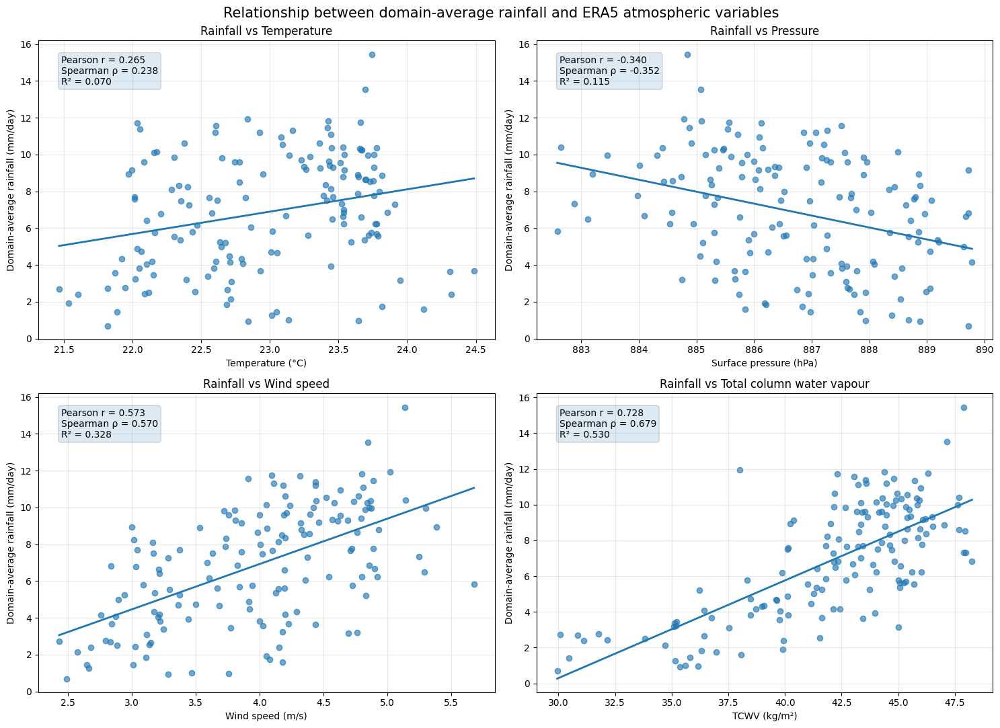

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, pearsonr, spearmanr

# Variables to compare with rainfall
predictor_vars = {
    "temperature": ("Temperature (°C)", "Temperature"),
    "pressure": ("Surface pressure (hPa)", "Pressure"),
    "wind_speed": ("Wind speed (m/s)", "Wind speed"),
    "tcwv": ("TCWV (kg/m²)", "Total column water vapour")
}

# Create a clean dataframe
scatter_df = domain_df[
    ["rainfall", "temperature", "pressure", "wind_speed", "tcwv"]
].dropna()

print("Number of daily observations used:", len(scatter_df))
print("\n" + "="*80)

# Plot and calculate statistics
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for ax, (var, (xlabel, title)) in zip(axes, predictor_vars.items()):

    x = scatter_df[var].values
    y = scatter_df["rainfall"].values

    # Linear regression
    result = linregress(x, y)

    # Correlations
    pearson_r, pearson_p = pearsonr(x, y)
    spearman_r, spearman_p = spearmanr(x, y)

    # Scatter points
    ax.scatter(x, y, alpha=0.65)

    # Regression line
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = result.intercept + result.slope * x_line
    ax.plot(x_line, y_line, linewidth=2)

    ax.set_title(f"Rainfall vs {title}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Domain-average rainfall (mm/day)")
    ax.grid(alpha=0.3)

    # Display statistics inside the plot
    ax.text(
        0.05, 0.95,
        f"Pearson r = {pearson_r:.3f}\n"
        f"Spearman ρ = {spearman_r:.3f}\n"
        f"R² = {result.rvalue**2:.3f}",
        transform=ax.transAxes,
        verticalalignment="top",
        bbox=dict(boxstyle="round", alpha=0.15)
    )

    print(f"\n{title.upper()}")
    print(f"Slope: {result.slope:.5f}")
    print(f"Intercept: {result.intercept:.5f}")
    print(f"R²: {result.rvalue**2:.4f}")
    print(f"Pearson correlation: r = {pearson_r:.4f}, p = {pearson_p:.4e}")
    print(f"Spearman correlation: ρ = {spearman_r:.4f}, p = {spearman_p:.4e}")

plt.suptitle(
    "Relationship between domain-average rainfall and ERA5 atmospheric variables",
    fontsize=15
)
plt.tight_layout()
plt.show()

In [ ]:
# Sort days by domain-average rainfall
top_rainfall_days = domain_df.sort_values(
    by="rainfall",
    ascending=False
).head(15).copy()

# Select useful columns
top_rainfall_days = top_rainfall_days[
    [
        "valid_time",
        "rainfall",
        "temperature",
        "pressure",
        "wind_speed",
        "tcwv"
    ]
]

print("Top 15 highest domain-average rainfall days:")
display(top_rainfall_days.round(3))

print("\nAverage atmospheric conditions:")
print(
    top_rainfall_days[
        ["temperature", "pressure", "wind_speed", "tcwv"]
    ].mean().round(3)
)

print("\nOverall atmospheric conditions:")
print(
    domain_df[
        ["temperature", "pressure", "wind_speed", "tcwv"]
    ].mean().round(3)
)

In [ ]:
# Sort days by domain-average rainfall
top_rainfall_days = domain_df.sort_values(
    by="rainfall",
    ascending=False
).head(15).copy()

# Select useful columns
top_rainfall_days = top_rainfall_days[
    [
        "valid_time",
        "rainfall",
        "temperature",
        "pressure",
        "wind_speed",
        "tcwv"
    ]
]

print("Top 15 highest domain-average rainfall days:")
display(top_rainfall_days.round(3))

print("\nAverage atmospheric conditions:")
print(
    top_rainfall_days[
        ["temperature", "pressure", "wind_speed", "tcwv"]
    ].mean().round(3)
)

print("\nOverall atmospheric conditions:")
print(
    domain_df[
        ["temperature", "pressure", "wind_speed", "tcwv"]
    ].mean().round(3)
)

Top 15 highest domain-average rainfall days:


,valid_time,rainfall,temperature,pressure,wind_speed,tcwv
86,2025-07-26,15.459,23.745001,884.841980,5.137,47.880001
87,2025-07-27,13.527,23.695999,885.072998,4.847,47.137001
30,2025-05-31,11.928,22.836000,884.786011,5.019,38.012001
67,2025-07-07,11.818,23.426001,885.081970,4.797,44.396000
75,2025-07-15,11.768,23.658001,885.568970,4.091,46.324001
124,2025-09-02,11.714,22.032000,886.122009,4.314,42.313999
115,2025-08-24,11.574,22.608000,887.513000,3.910,43.055000
66,2025-07-06,11.443,23.417999,884.874023,4.889,44.813000
123,2025-09-01,11.379,22.055000,885.541016,4.434,43.567001
105,2025-08-14,11.330,23.163000,887.270996,4.111,45.721001



Average atmospheric conditions:
temperature     23.004000
pressure       885.956970
wind_speed       4.520000
tcwv            44.175999
dtype: float32

Overall atmospheric conditions:
temperature     22.983999
pressure       886.700989
wind_speed       3.980000
tcwv            42.044998
dtype: float32


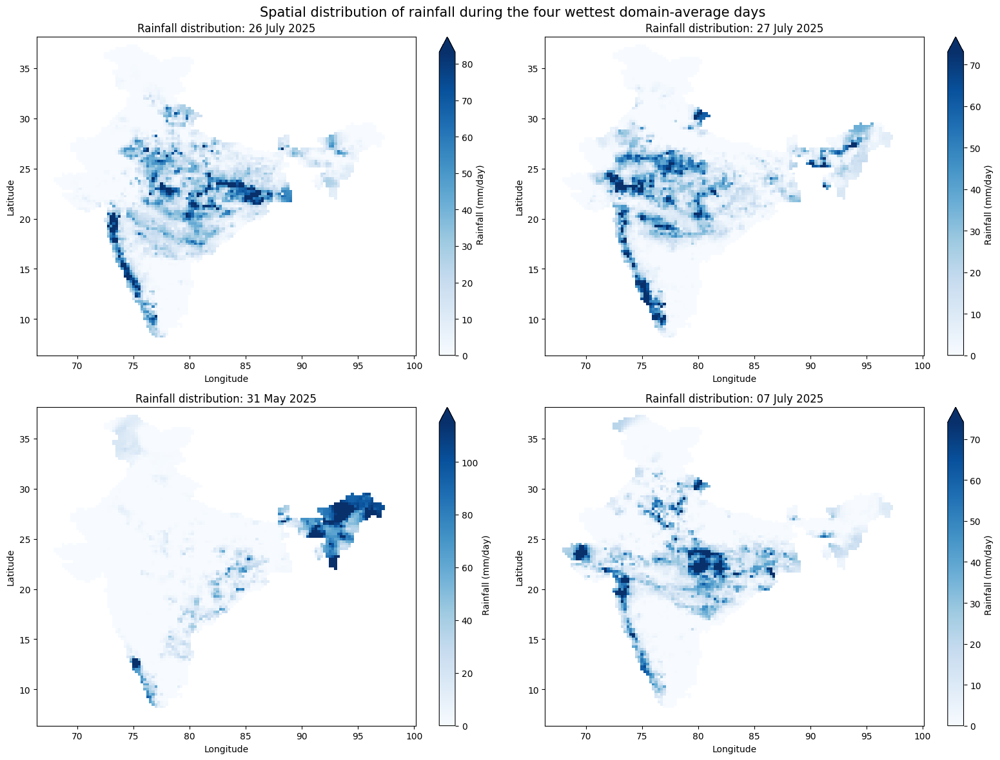

In [ ]:
import matplotlib.pyplot as plt

# Select the top 4 wettest days
top4_dates = top_rainfall_days["valid_time"].head(4).values

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for ax, date in zip(axes, top4_dates):

    rainfall_map = imd_common["RAINFALL"].sel(
        valid_time=date
    )

    rainfall_map.plot(
        ax=ax,
        cmap="Blues",
        robust=True,
        cbar_kwargs={"label": "Rainfall (mm/day)"}
    )

    ax.set_title(
        f"Rainfall distribution: {pd.to_datetime(date).strftime('%d %B %Y')}"
    )
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.suptitle(
    "Spatial distribution of rainfall during the four wettest domain-average days",
    fontsize=15
)

plt.tight_layout()
plt.show()

Common colour-scale maximum: 395.56 mm/day


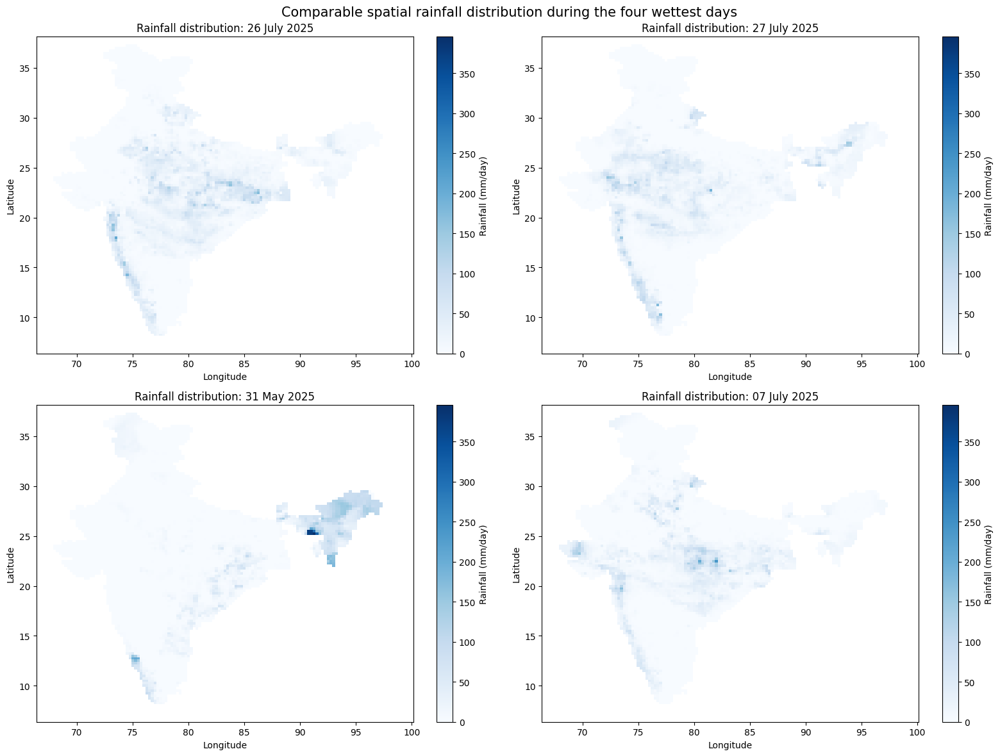

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Select the same four wettest days
top4_dates = top_rainfall_days["valid_time"].head(4).values

# Find one common maximum across all four maps
selected_rainfall = imd_common["RAINFALL"].sel(
    valid_time=top4_dates
)

common_vmax = float(selected_rainfall.max(skipna=True))

print("Common colour-scale maximum:", round(common_vmax, 2), "mm/day")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for ax, date in zip(axes, top4_dates):

    rainfall_map = imd_common["RAINFALL"].sel(
        valid_time=date
    )

    rainfall_map.plot(
        ax=ax,
        cmap="Blues",
        vmin=0,
        vmax=common_vmax,
        cbar_kwargs={"label": "Rainfall (mm/day)"}
    )

    ax.set_title(
        f"Rainfall distribution: "
        f"{pd.to_datetime(date).strftime('%d %B %Y')}"
    )
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.suptitle(
    "Comparable spatial rainfall distribution during the four wettest days",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
# Calculate maximum rainfall at each grid cell
spatial_max_rainfall = imd_common["RAINFALL"].max(
    dim="valid_time",
    skipna=True
)

# Calculate mean rainfall at each grid cell
spatial_mean_rainfall = imd_common["RAINFALL"].mean(
    dim="valid_time",
    skipna=True
)

# Identify the grid cell with the highest recorded rainfall
max_value = float(spatial_max_rainfall.max(skipna=True))

max_location = spatial_max_rainfall.where(
    spatial_max_rainfall == max_value,
    drop=True
)

print("Highest rainfall recorded:", round(max_value, 3), "mm/day")
print("Location of highest rainfall:")
print(max_location)

print("\nSpatial maximum rainfall statistics:")
print(
    spatial_max_rainfall.to_dataframe(
        name="maximum_rainfall"
    )["maximum_rainfall"].describe().round(3)
)

print("\nSpatial mean rainfall statistics:")
print(
    spatial_mean_rainfall.to_dataframe(
        name="mean_rainfall"
    )["mean_rainfall"].describe().round(3)
)

Highest rainfall recorded: 469.21 mm/day
Location of highest rainfall:
<xarray.DataArray 'RAINFALL' (latitude: 1, longitude: 1)> Size: 4B
array([[469.21014]], dtype=float32)
Coordinates:
  * latitude   (latitude) float64 8B 25.75
  * longitude  (longitude) float64 8B 75.75
Attributes:
    long_name:  Rainfall
    units:      mm
    history:    From ind2025_rfp25.grd

Spatial maximum rainfall statistics:
count    4964.000
mean       89.258
std        50.683
min         0.000
25%        56.505
50%        79.996
75%       111.628
max       469.210
Name: maximum_rainfall, dtype: float64

Spatial mean rainfall statistics:
count    4964.000
mean        6.878
std         4.746
min         0.000
25%         3.968
50%         6.162
75%         8.564
max        42.848
Name: mean_rainfall, dtype: float64


In [ ]:
# Convert spatial maximum rainfall to a dataframe
hotspot_df = (
    spatial_max_rainfall
    .to_dataframe(name="maximum_rainfall")
    .reset_index()
    .dropna()
    .sort_values("maximum_rainfall", ascending=False)
)

# Display top 20 grid cells
top20_hotspots = hotspot_df.head(20)

print("Top 20 grid cells by maximum daily rainfall:")
display(top20_hotspots.round(3))

# Print geographic range of the top 20 locations
print("\nLatitude range of top 20 hotspots:",
      round(top20_hotspots["latitude"].min(), 3),
      "to",
      round(top20_hotspots["latitude"].max(), 3))

print("Longitude range of top 20 hotspots:",
      round(top20_hotspots["longitude"].min(), 3),
      "to",
      round(top20_hotspots["longitude"].max(), 3))

Top 20 grid cells by maximum daily rainfall:


,latitude,longitude,maximum_rainfall
10432,25.75,75.75,469.209991
10224,25.25,91.25,395.557007
9604,24.25,71.25,376.828003
10223,25.25,91.00,376.376007
10357,25.50,90.75,374.677002
10222,25.25,90.75,370.483002
10358,25.50,91.00,369.497009
6642,18.75,73.25,367.733002
10093,25.00,92.25,367.287994
8390,22.00,71.50,352.222992



Latitude range of top 20 hotspots: 18.25 to 25.75
Longitude range of top 20 hotspots: 70.5 to 92.5


In [ ]:
# Define rainfall thresholds in mm/day
thresholds = [10, 25, 50, 100, 150, 200, 300]

threshold_results = []

total_valid_cells = spatial_max_rainfall.count().item()

for threshold in thresholds:
    count_cells = (
        spatial_max_rainfall >= threshold
    ).sum().item()

    percentage = (count_cells / total_valid_cells) * 100

    threshold_results.append({
        "Threshold_mm_day": threshold,
        "Grid_cells_exceeding_threshold": count_cells,
        "Percentage_of_valid_cells": percentage
    })

threshold_df = pd.DataFrame(threshold_results)

print("Spatial extent of maximum rainfall thresholds:")
display(threshold_df.round(3))

Spatial extent of maximum rainfall thresholds:


,Threshold_mm_day,Grid_cells_exceeding_threshold,Percentage_of_valid_cells
0,10,4950,99.718
1,25,4620,93.070
2,50,4012,80.822
3,100,1594,32.111
4,150,541,10.898
5,200,160,3.223
6,300,26,0.524


Threshold ≥ 25 mm/day:
Maximum number of days at any grid cell: 83
Total grid cells with at least one such day: 4620

Threshold ≥ 50 mm/day:
Maximum number of days at any grid cell: 47
Total grid cells with at least one such day: 4012

Threshold ≥ 100 mm/day:
Maximum number of days at any grid cell: 16
Total grid cells with at least one such day: 1594

Threshold ≥ 150 mm/day:
Maximum number of days at any grid cell: 10
Total grid cells with at least one such day: 541

Threshold ≥ 200 mm/day:
Maximum number of days at any grid cell: 4
Total grid cells with at least one such day: 160



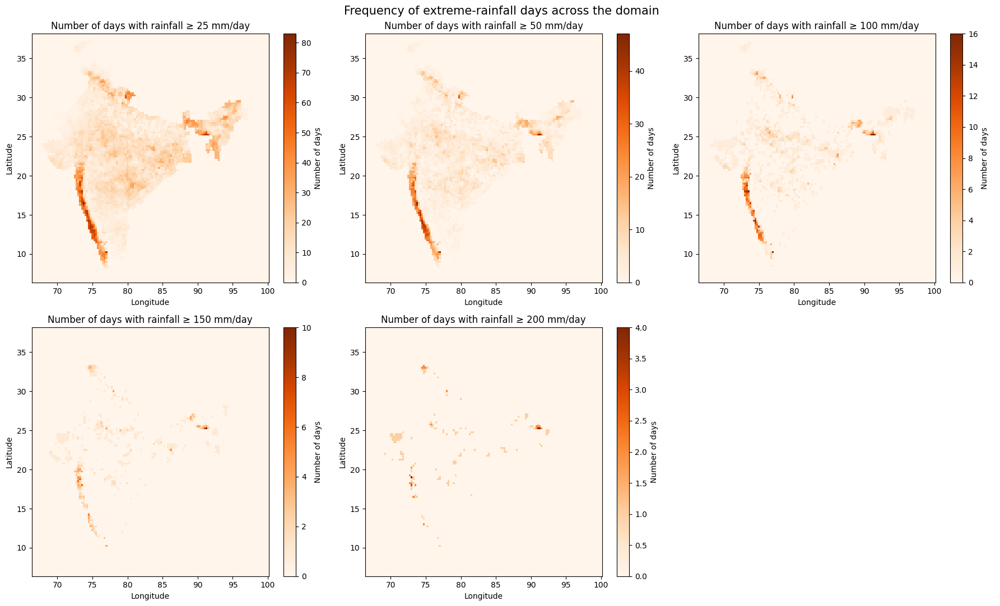

In [ ]:
# Define thresholds
frequency_thresholds = [25, 50, 100, 150, 200]

frequency_maps = {}

for threshold in frequency_thresholds:

    frequency_map = (
        (imd_common["RAINFALL"] >= threshold)
        .sum(dim="valid_time", skipna=True)
    )

    frequency_maps[threshold] = frequency_map

    print(
        f"Threshold ≥ {threshold} mm/day:"
    )
    print(
        "Maximum number of days at any grid cell:",
        int(frequency_map.max().item())
    )
    print(
        "Total grid cells with at least one such day:",
        int((frequency_map > 0).sum().item())
    )
    print()

# Plot frequency maps
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for ax, threshold in zip(axes, frequency_thresholds):

    frequency_maps[threshold].plot(
        ax=ax,
        cmap="Oranges",
        vmin=0,
        cbar_kwargs={
            "label": "Number of days"
        }
    )

    ax.set_title(
        f"Number of days with rainfall ≥ {threshold} mm/day"
    )
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

# Hide unused subplot
axes[-1].axis("off")

plt.suptitle(
    "Frequency of extreme-rainfall days across the domain",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
# Convert the ≥100 mm/day frequency map to a dataframe
persistent_df = (
    frequency_maps[100]
    .to_dataframe(name="extreme_days")
    .reset_index()
    .dropna()
    .sort_values("extreme_days", ascending=False)
)

print("Top 20 grid cells by number of days with rainfall ≥100 mm/day:")
display(persistent_df.head(20).round(3))

# Summary statistics
print("\nFrequency statistics for rainfall ≥100 mm/day:")
print(
    persistent_df["extreme_days"]
    .describe()
    .round(3)
)

# Count cells by number of extreme days
print("\nNumber of cells experiencing repeated ≥100 mm/day events:")
print(
    persistent_df["extreme_days"]
    .value_counts()
    .sort_index()
    .head(20)
)# Convert the ≥100 mm/day frequency map to a dataframe
persistent_df = (
    frequency_maps[100]
    .to_dataframe(name="extreme_days")
    .reset_index()
    .dropna()
    .sort_values("extreme_days", ascending=False)
)

print("Top 20 grid cells by number of days with rainfall ≥100 mm/day:")
display(persistent_df.head(20).round(3))

# Summary statistics
print("\nFrequency statistics for rainfall ≥100 mm/day:")
print(
    persistent_df["extreme_days"]
    .describe()
    .round(3)
)

# Count cells by number of extreme days
print("\nNumber of cells experiencing repeated ≥100 mm/day events:")
print(
    persistent_df["extreme_days"]
    .value_counts()
    .sort_index()
    .head(20)
)

Top 20 grid cells by number of days with rainfall ≥100 mm/day:


,latitude,longitude,extreme_days
10224,25.25,91.25,16
2067,10.25,77.00,16
6238,18.00,73.50,15
4217,14.25,74.50,15
10223,25.25,91.00,15
6237,18.00,73.25,14
10225,25.25,91.50,14
3814,13.50,75.00,13
4082,14.00,74.50,13
6236,18.00,73.00,13



Frequency statistics for rainfall ≥100 mm/day:
count    17145.000
mean         0.184
std          0.854
min          0.000
25%          0.000
50%          0.000
75%          0.000
max         16.000
Name: extreme_days, dtype: float64

Number of cells experiencing repeated ≥100 mm/day events:
extreme_days
0     15551
1      1009
2       304
3        92
4        56
5        29
6        17
7        27
8        17
9        12
10       15
11        2
12        3
13        4
14        2
15        3
16        2
Name: count, dtype: int64
Top 20 grid cells by number of days with rainfall ≥100 mm/day:


,latitude,longitude,extreme_days
10224,25.25,91.25,16
2067,10.25,77.00,16
6238,18.00,73.50,15
4217,14.25,74.50,15
10223,25.25,91.00,15
6237,18.00,73.25,14
10225,25.25,91.50,14
3814,13.50,75.00,13
4082,14.00,74.50,13
6236,18.00,73.00,13



Frequency statistics for rainfall ≥100 mm/day:
count    17145.000
mean         0.184
std          0.854
min          0.000
25%          0.000
50%          0.000
75%          0.000
max         16.000
Name: extreme_days, dtype: float64

Number of cells experiencing repeated ≥100 mm/day events:
extreme_days
0     15551
1      1009
2       304
3        92
4        56
5        29
6        17
7        27
8        17
9        12
10       15
11        2
12        3
13        4
14        2
15        3
16        2
Name: count, dtype: int64


In [ ]:
# Valid rainfall cells: cells with at least one non-missing rainfall observation
valid_cell_mask = imd_common["RAINFALL"].notnull().any(dim="valid_time")

# Check number of valid cells
valid_cell_count = int(valid_cell_mask.sum().item())

print("Number of valid rainfall grid cells:", valid_cell_count)

# Apply valid-cell mask to the ≥100 mm/day frequency map
valid_frequency_100 = frequency_maps[100].where(valid_cell_mask)

# Convert to dataframe
valid_frequency_df = (
    valid_frequency_100
    .to_dataframe(name="extreme_days")
    .reset_index()
    .dropna()
)

print("Number of records after valid-cell filtering:",
      len(valid_frequency_df))

print("\nCorrect frequency statistics:")
print(
    valid_frequency_df["extreme_days"]
    .describe()
    .round(3)
)

print("\nCorrect frequency distribution:")
display(
    valid_frequency_df["extreme_days"]
    .value_counts()
    .sort_index()
)

Number of valid rainfall grid cells: 4964
Number of records after valid-cell filtering: 4964

Correct frequency statistics:
count    4964.000
mean        0.637
std         1.494
min         0.000
25%         0.000
50%         0.000
75%         1.000
max        16.000
Name: extreme_days, dtype: float64

Correct frequency distribution:


,count
extreme_days,
0.0,3370
1.0,1009
2.0,304
3.0,92
4.0,56
5.0,29
6.0,17
7.0,27
8.0,17


In [ ]:
# Create a combined hotspot dataframe
max_df = (
    spatial_max_rainfall
    .where(valid_cell_mask)
    .to_dataframe(name="maximum_rainfall")
    .reset_index()
)

freq_df = (
    frequency_maps[100]
    .where(valid_cell_mask)
    .to_dataframe(name="extreme_days")
    .reset_index()
)

combined_hotspots = pd.merge(
    max_df,
    freq_df,
    on=["latitude", "longitude"],
    how="inner"
).dropna()

# Correlation between maximum intensity and event frequency
pearson_hotspot = combined_hotspots[
    ["maximum_rainfall", "extreme_days"]
].corr(method="pearson").iloc[0, 1]

spearman_hotspot = combined_hotspots[
    ["maximum_rainfall", "extreme_days"]
].corr(method="spearman").iloc[0, 1]

print("Number of valid grid cells:", len(combined_hotspots))
print("Pearson correlation:", round(pearson_hotspot, 4))
print("Spearman correlation:", round(spearman_hotspot, 4))

print("\nTop 15 cells by maximum rainfall:")
display(
    combined_hotspots
    .sort_values("maximum_rainfall", ascending=False)
    .head(15)
    .round(3)
)

print("\nTop 15 cells by frequency of rainfall ≥100 mm/day:")
display(
    combined_hotspots
    .sort_values("extreme_days", ascending=False)
    .head(15)
    .round(3)
)

Number of valid grid cells: 4964
Pearson correlation: 0.6569
Spearman correlation: 0.8107

Top 15 cells by maximum rainfall:


,latitude,longitude,maximum_rainfall,extreme_days
10432,25.75,75.75,469.209991,2.0
10224,25.25,91.25,395.557007,16.0
9604,24.25,71.25,376.828003,1.0
10223,25.25,91.00,376.376007,15.0
10357,25.50,90.75,374.677002,4.0
10222,25.25,90.75,370.483002,7.0
10358,25.50,91.00,369.497009,6.0
6642,18.75,73.25,367.733002,13.0
10093,25.00,92.25,367.287994,3.0
8390,22.00,71.50,352.222992,1.0



Top 15 cells by frequency of rainfall ≥100 mm/day:


,latitude,longitude,maximum_rainfall,extreme_days
2067,10.25,77.00,211.453003,16.0
10224,25.25,91.25,395.557007,16.0
6238,18.00,73.50,249.477997,15.0
4217,14.25,74.50,181.367996,15.0
10223,25.25,91.00,376.376007,15.0
10225,25.25,91.50,317.420990,14.0
6237,18.00,73.25,176.108002,14.0
6642,18.75,73.25,367.733002,13.0
6236,18.00,73.00,293.919006,13.0
3814,13.50,75.00,172.166000,13.0


In [ ]:
# Install required libraries
!pip -q install xarray netCDF4 h5netcdf rasterio rioxarray geopandas cartopy

# Import libraries
import os
import glob
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore")

# Plot settings
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True

print("All libraries imported successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 91.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 57.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 91.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 61.6 MB/s eta 0:00:00
All libraries imported successfully.


In [ ]:
# List files available in Colab
all_files = glob.glob("/content/*")

print("Files currently available in /content:\n")

for file in all_files:
    if os.path.isfile(file):
        size_mb = os.path.getsize(file) / (1024 * 1024)
        print(f"{os.path.basename(file)}  |  {size_mb:.2f} MB")

Files currently available in /content:

RF25_ind2025_rfp25.nc  |  24.25 MB
era5 2025.nc  |  569.23 MB


In [ ]:
# --------------------------------------------------
# Open IMD rainfall dataset
# --------------------------------------------------

imd_path = "/content/RF25_ind2025_rfp25.nc"
imd = xr.open_dataset(imd_path)

print("IMD dataset:")
print(imd)


# --------------------------------------------------
# Open ERA5 dataset
# --------------------------------------------------

era5_path = "/content/era5 2025.nc"
ds_era5 = xr.open_dataset(era5_path)

print("\nERA5 dataset:")
print(ds_era5)

IMD dataset:
<xarray.Dataset> Size: 25MB
Dimensions:    (TIME: 365, LATITUDE: 129, LONGITUDE: 135)
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2025-01-01 2025-01-02 ... 2025-12-31
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Data variables:
    RAINFALL   (TIME, LATITUDE, LONGITUDE) float32 25MB ...
Attributes:
    history:      FERRET V6.82    9-Apr-26
    Conventions:  CF-1.0

ERA5 dataset:
<xarray.Dataset> Size: 1GB
Dimensions:     (valid_time: 3672, latitude: 127, longitude: 135)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 29kB 2025-05-01 ... 2025-09-30T23...
  * latitude    (latitude) float64 1kB 38.0 37.75 37.5 37.25 ... 7.0 6.75 6.5
  * longitude   (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
    number      int64 8B ...
    expver      (valid_time) <U4 59kB ...
Data variables:
    u10         (valid_time, latitude, longitude) float32 

In [ ]:
# Convert ERA5 variables into useful research units

era5 = xr.Dataset({
    "temperature": ds_era5["t2m"] - 273.15,  # Kelvin to Celsius
    "pressure": ds_era5["sp"] / 100,          # Pa to hPa
    "wind_speed": np.sqrt(
        ds_era5["u10"]**2 + ds_era5["v10"]**2
    ),                                        # m/s
    "tcwv": ds_era5["tcwv"]                  # kg/m²
})

# Sort latitude in ascending order
era5 = era5.sortby("latitude")

print(era5)

<xarray.Dataset> Size: 1GB
Dimensions:      (valid_time: 3672, latitude: 127, longitude: 135)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 29kB 2025-05-01 ... 2025-09-30T2...
  * latitude     (latitude) float64 1kB 6.5 6.75 7.0 7.25 ... 37.5 37.75 38.0
  * longitude    (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
    number       int64 8B 0
    expver       (valid_time) <U4 59kB '0001' '0001' '0001' ... '0001' '0001'
Data variables:
    temperature  (valid_time, latitude, longitude) float32 252MB 28.15 ... -2...
    pressure     (valid_time, latitude, longitude) float32 252MB 1.008e+03 .....
    wind_speed   (valid_time, latitude, longitude) float32 252MB 1.765 ... 1.327
    tcwv         (valid_time, latitude, longitude) float32 252MB ...


In [ ]:
# Select the common spatial domain
imd_common = imd.sel(
    LATITUDE=slice(6.5, 38.0),
    LONGITUDE=slice(66.5, 100.0)
)

# Rename coordinates to match ERA5
imd_common = imd_common.rename({
    "TIME": "valid_time",
    "LATITUDE": "latitude",
    "LONGITUDE": "longitude"
})

# Sort latitude in ascending order
imd_common = imd_common.sortby("latitude")

print(imd_common)

<xarray.Dataset> Size: 25MB
Dimensions:     (valid_time: 365, latitude: 127, longitude: 135)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 3kB 2025-01-01 ... 2025-12-31
  * latitude    (latitude) float64 1kB 6.5 6.75 7.0 7.25 ... 37.5 37.75 38.0
  * longitude   (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Data variables:
    RAINFALL    (valid_time, latitude, longitude) float32 25MB ...
Attributes:
    history:      FERRET V6.82    9-Apr-26
    Conventions:  CF-1.0


In [ ]:
print("IMD latitude shape:", imd_common.latitude.shape)
print("ERA5 latitude shape:", era5.latitude.shape)

print("IMD longitude shape:", imd_common.longitude.shape)
print("ERA5 longitude shape:", era5.longitude.shape)

print("\nLatitude grids match:",
      np.array_equal(imd_common.latitude.values, era5.latitude.values))

print("Longitude grids match:",
      np.array_equal(imd_common.longitude.values, era5.longitude.values))

print("\nIMD time range:",
      imd_common.valid_time.min().values,
      "to",
      imd_common.valid_time.max().values)

print("ERA5 time range:",
      era5.valid_time.min().values,
      "to",
      era5.valid_time.max().values)

IMD latitude shape: (127,)
ERA5 latitude shape: (127,)
IMD longitude shape: (135,)
ERA5 longitude shape: (135,)

Latitude grids match: True
Longitude grids match: True

IMD time range: 2025-01-01T00:00:00.000000000 to 2025-12-31T00:00:00.000000000
ERA5 time range: 2025-05-01T00:00:00.000000000 to 2025-09-30T23:00:00.000000000


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr

# --------------------------------------------------
# 1. Prepare valid spatial data
# --------------------------------------------------

hotspot_df = combined_hotspots.copy()

# Thresholds based on the observed distributions
max_intensity_threshold = 100       # mm/day
frequency_threshold = 5             # extreme-rainfall days

# --------------------------------------------------
# 2. Assign hotspot classes
# --------------------------------------------------

def classify_hotspot(row):
    high_intensity = row["maximum_rainfall"] >= max_intensity_threshold
    high_frequency = row["extreme_days"] >= frequency_threshold

    if high_intensity and high_frequency:
        return "High intensity + High frequency"
    elif high_intensity and not high_frequency:
        return "High intensity + Low frequency"
    elif not high_intensity and high_frequency:
        return "Low intensity + High frequency"
    else:
        return "Low intensity + Low frequency"

hotspot_df["hotspot_class"] = hotspot_df.apply(
    classify_hotspot,
    axis=1
)

# --------------------------------------------------
# 3. Print numerical findings
# --------------------------------------------------

class_counts = hotspot_df["hotspot_class"].value_counts()

print("========== HOTSPOT CLASSIFICATION ==========")
print(class_counts)

print("\nPercentage of valid grid cells:")
print((class_counts / len(hotspot_df) * 100).round(2))

print("\nClass-wise statistics:")
print(
    hotspot_df.groupby("hotspot_class")[
        ["maximum_rainfall", "extreme_days"]
    ].agg(["count", "mean", "median", "max"]).round(2)
)

# --------------------------------------------------
# 4. Convert classification back to spatial grid
# --------------------------------------------------

class_grid = xr.full_like(
    spatial_max_rainfall,
    fill_value=np.nan,
    dtype=float
)

class_code = {
    "Low intensity + Low frequency": 1,
    "High intensity + Low frequency": 2,
    "Low intensity + High frequency": 3,
    "High intensity + High frequency": 4
}

for class_name, code in class_code.items():
    cells = hotspot_df.loc[
        hotspot_df["hotspot_class"] == class_name,
        ["latitude", "longitude"]
    ]

    for _, cell in cells.iterrows():
        class_grid.loc[
            dict(
                latitude=cell["latitude"],
                longitude=cell["longitude"]
            )
        ] = code

# --------------------------------------------------
# 5. Plot classification map
# --------------------------------------------------

plt.figure(figsize=(13, 7))

class_grid.plot(
    cmap="viridis",
    vmin=1,
    vmax=4,
    add_colorbar=False
)

cbar = plt.colorbar()
cbar.set_ticks([1, 2, 3, 4])
cbar.set_ticklabels([
    "Low intensity + Low frequency",
    "High intensity + Low frequency",
    "Low intensity + High frequency",
    "High intensity + High frequency"
])

plt.title(
    "Extreme-Rainfall Hotspot Classification\n"
    "Based on Maximum Intensity and Frequency ≥100 mm/day"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

NameError: name 'combined_hotspots' is not defined

In [ ]:
# Create daily ERA5 dataset
# Memory-safe approach: process one variable at a time

era5_daily = xr.Dataset()

for var in ["temperature", "pressure", "wind_speed", "tcwv"]:
    print(f"Processing {var}...")

    daily_var = (
        era5[var]
        .resample(valid_time="1D")
        .mean()
        .load()
    )

    era5_daily[var] = daily_var

print("\nDaily ERA5 dataset created successfully.")
print(era5_daily)

Processing temperature...
Processing pressure...
Processing wind_speed...
Processing tcwv...

Daily ERA5 dataset created successfully.
<xarray.Dataset> Size: 42MB
Dimensions:      (latitude: 127, longitude: 135, valid_time: 153)
Coordinates:
  * latitude     (latitude) float64 1kB 6.5 6.75 7.0 7.25 ... 37.5 37.75 38.0
  * longitude    (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
  * valid_time   (valid_time) datetime64[ns] 1kB 2025-05-01 ... 2025-09-30
    number       int64 8B 0
Data variables:
    temperature  (valid_time, latitude, longitude) float32 10MB 28.74 ... 1.776
    pressure     (valid_time, latitude, longitude) float32 10MB 1.009e+03 ......
    wind_speed   (valid_time, latitude, longitude) float32 10MB 2.687 ... 1.464
    tcwv         (valid_time, latitude, longitude) float32 10MB 54.86 ... 6.882


In [ ]:
combined = xr.Dataset({
    "rainfall": imd_common["RAINFALL"],
    "temperature": era5_daily["temperature"],
    "pressure": era5_daily["pressure"],
    "wind_speed": era5_daily["wind_speed"],
    "tcwv": era5_daily["tcwv"]
})

print("Combined dataset created successfully.")
print(combined)

Combined dataset created successfully.
<xarray.Dataset> Size: 125MB
Dimensions:      (longitude: 135, latitude: 127, valid_time: 365)
Coordinates:
  * longitude    (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
  * latitude     (latitude) float64 1kB 6.5 6.75 7.0 7.25 ... 37.5 37.75 38.0
  * valid_time   (valid_time) datetime64[ns] 3kB 2025-01-01 ... 2025-12-31
    number       int64 8B 0
Data variables:
    rainfall     (valid_time, latitude, longitude) float32 25MB ...
    temperature  (valid_time, latitude, longitude) float32 25MB nan nan ... nan
    pressure     (valid_time, latitude, longitude) float32 25MB nan nan ... nan
    wind_speed   (valid_time, latitude, longitude) float32 25MB nan nan ... nan
    tcwv         (valid_time, latitude, longitude) float32 25MB nan nan ... nan


In [ ]:
# Average each variable over latitude and longitude
domain_daily = combined.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

# Convert to pandas DataFrame
domain_df = domain_daily.to_dataframe().reset_index()

print("Domain-average dataframe created.")
display(domain_df.head())

print("\nShape:", domain_df.shape)
print("\nMissing values:")
print(domain_df.isnull().sum())

Domain-average dataframe created.


,valid_time,rainfall,number,temperature,pressure,wind_speed,tcwv
0,2025-01-01,0.027581,0,NaN,NaN,NaN,NaN
1,2025-01-02,0.056030,0,NaN,NaN,NaN,NaN
2,2025-01-03,0.049450,0,NaN,NaN,NaN,NaN
3,2025-01-04,0.000000,0,NaN,NaN,NaN,NaN
4,2025-01-05,0.001082,0,NaN,NaN,NaN,NaN



Shape: (365, 7)

Missing values:
valid_time       0
rainfall         0
number           0
temperature    212
pressure       212
wind_speed     212
tcwv           212
dtype: int64


In [ ]:
# ERA5 summary statistics

era5_summary = era5_daily.to_dataframe().describe().T

# Add missing-value information
era5_summary["missing_values"] = (
    era5_daily.to_dataframe().isnull().sum()
)

era5_summary["missing_percentage"] = (
    era5_summary["missing_values"]
    / len(era5_daily.valid_time)
    / (len(era5_daily.latitude) * len(era5_daily.longitude))
    * 100
)

display(era5_summary.round(3))

print("\n========== ERA5 VARIABLE RANGES ==========")

for var in ["temperature", "pressure", "wind_speed", "tcwv"]:
    values = era5_daily[var].values

    print(f"\n{var.upper()}")
    print("Minimum:", np.nanmin(values))
    print("Maximum:", np.nanmax(values))
    print("Mean:", np.nanmean(values))
    print("Median:", np.nanmedian(values))
    print("Standard deviation:", np.nanstd(values))

,count,mean,std,min,25%,50%,75%,max,missing_values,missing_percentage
number,2623185.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0,0.0
temperature,2623185.0,22.984,9.804,-19.512,21.129,27.364,28.757,41.806,0,0.0
pressure,2623185.0,886.701,167.850,492.020,804.922,977.851,1005.784,1014.897,0,0.0
wind_speed,2623185.0,3.980,2.923,0.079,1.694,2.959,5.688,16.502,0,0.0
tcwv,2623185.0,42.045,21.634,0.510,19.607,50.107,59.194,81.542,0,0.0



========== ERA5 VARIABLE RANGES ==========

TEMPERATURE
Minimum: -19.512335
Maximum: 41.806473
Mean: 22.98431
Median: 27.364416
Standard deviation: 9.80532

PRESSURE
Minimum: 492.01953
Maximum: 1014.89716
Mean: 886.70074
Median: 977.8513
Standard deviation: 167.84883

WIND_SPEED
Minimum: 0.07930239
Maximum: 16.50158
Mean: 3.979855
Median: 2.958888
Standard deviation: 2.9257562

TCWV
Minimum: 0.50985336
Maximum: 81.54198
Mean: 42.044518
Median: 50.10672
Standard deviation: 21.638145


In [ ]:
# --------------------------------------------------
# 1. Prepare hotspot dataframe
# --------------------------------------------------

hotspot_df = combined_hotspots.copy()

# Classification thresholds
intensity_threshold = 100   # mm/day
frequency_threshold = 5     # number of days

# --------------------------------------------------
# 2. Classify each valid grid cell
# --------------------------------------------------

def classify_hotspot(row):
    high_intensity = row["maximum_rainfall"] >= intensity_threshold
    high_frequency = row["extreme_days"] >= frequency_threshold

    if high_intensity and high_frequency:
        return "High intensity + High frequency"
    elif high_intensity and not high_frequency:
        return "High intensity + Low frequency"
    elif not high_intensity and high_frequency:
        return "Low intensity + High frequency"
    else:
        return "Low intensity + Low frequency"

hotspot_df["hotspot_class"] = hotspot_df.apply(
    classify_hotspot,
    axis=1
)

# --------------------------------------------------
# 3. Print class counts and percentages
# --------------------------------------------------

class_counts = hotspot_df["hotspot_class"].value_counts()

print("========== HOTSPOT CLASSIFICATION ==========")
print(class_counts)

print("\n========== PERCENTAGE OF VALID GRID CELLS ==========")
print(
    (class_counts / len(hotspot_df) * 100).round(2)
)

print("\n========== CLASS-WISE STATISTICS ==========")

class_statistics = hotspot_df.groupby("hotspot_class")[
    ["maximum_rainfall", "extreme_days"]
].agg(["count", "mean", "median", "max"])

display(class_statistics.round(2))

# --------------------------------------------------
# 4. Create spatial classification grid
# --------------------------------------------------

class_grid = xr.full_like(
    spatial_max_rainfall,
    fill_value=np.nan,
    dtype=float
)

class_code = {
    "Low intensity + Low frequency": 1,
    "High intensity + Low frequency": 2,
    "Low intensity + High frequency": 3,
    "High intensity + High frequency": 4
}

for class_name, code in class_code.items():

    selected_cells = hotspot_df[
        hotspot_df["hotspot_class"] == class_name
    ]

    for _, cell in selected_cells.iterrows():

        class_grid.loc[
            dict(
                latitude=cell["latitude"],
                longitude=cell["longitude"]
            )
        ] = code

# --------------------------------------------------
# 5. Plot classification map
# --------------------------------------------------

plt.figure(figsize=(14, 7))

class_grid.plot(
    cmap="viridis",
    vmin=1,
    vmax=4,
    add_colorbar=False
)

cbar = plt.colorbar()
cbar.set_ticks([1, 2, 3, 4])
cbar.set_ticklabels([
    "Low intensity + Low frequency",
    "High intensity + Low frequency",
    "Low intensity + High frequency",
    "High intensity + High frequency"
])

plt.title(
    "Extreme-Rainfall Hotspot Classification\n"
    "Maximum Rainfall and Frequency ≥100 mm/day"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

NameError: name 'combined_hotspots' is not defined

Number of valid grid cells: 4964

========== HOTSPOT CLASSIFICATION ==========
hotspot_class
Low intensity + Low frequency      3133
High intensity + Low frequency     1681
High intensity + High frequency     150
Name: count, dtype: int64

========== PERCENTAGES ==========
hotspot_class
Low intensity + Low frequency      63.11
High intensity + Low frequency     33.86
High intensity + High frequency     3.02
Name: count, dtype: float64

========== CLASS-WISE STATISTICS ==========


maximum_rainfall                          \
                                           count        mean      median   
hotspot_class                                                              
High intensity + High frequency              150  196.009995  180.710007   
High intensity + Low frequency              1681  141.990005  128.720001   
Low intensity + Low frequency               3133   66.050003   69.320000   

                                            extreme_days                     
                                        max        count  mean median   max  
hotspot_class                                                                
High intensity + High frequency  395.559998          150  7.81    7.0  20.0  
High intensity + Low frequency   469.209991         1681  1.42    1.0   4.0  
Low intensity + Low frequency     99.989998         3133  0.00    0.0   0.0

RuntimeError: No mappable was found to use for colorbar creation. First define a mappable such as an image (with imshow) or a contour set (with contourf).

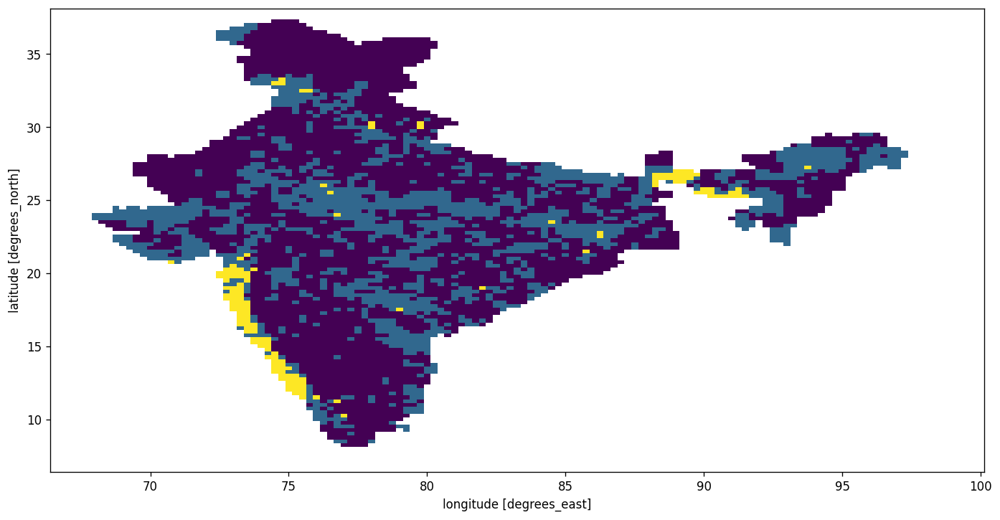

In [ ]:
# --------------------------------------------------
# 1. Recreate required rainfall variables
# --------------------------------------------------

spatial_max_rainfall = imd_common["RAINFALL"].max(
    dim="valid_time",
    skipna=True
)

# Valid grid cells: cells with at least one rainfall observation
valid_cell_mask = imd_common["RAINFALL"].notnull().any(
    dim="valid_time"
)

# Frequency of rainfall >=100 mm/day
frequency_100 = (
    (imd_common["RAINFALL"] >= 100)
    .sum(dim="valid_time", skipna=True)
)

# --------------------------------------------------
# 2. Convert both variables into dataframes
# --------------------------------------------------

max_df = (
    spatial_max_rainfall
    .where(valid_cell_mask)
    .to_dataframe(name="maximum_rainfall")
    .reset_index()
    .dropna()
)

freq_df = (
    frequency_100
    .where(valid_cell_mask)
    .to_dataframe(name="extreme_days")
    .reset_index()
    .dropna()
)

# Merge maximum intensity and frequency
hotspot_df = pd.merge(
    max_df,
    freq_df,
    on=["latitude", "longitude"],
    how="inner"
)

print("Number of valid grid cells:", len(hotspot_df))

# --------------------------------------------------
# 3. Classify hotspots
# --------------------------------------------------

intensity_threshold = 100  # mm/day
frequency_threshold = 5    # days

def classify_hotspot(row):

    high_intensity = (
        row["maximum_rainfall"] >= intensity_threshold
    )

    high_frequency = (
        row["extreme_days"] >= frequency_threshold
    )

    if high_intensity and high_frequency:
        return "High intensity + High frequency"

    elif high_intensity and not high_frequency:
        return "High intensity + Low frequency"

    elif not high_intensity and high_frequency:
        return "Low intensity + High frequency"

    else:
        return "Low intensity + Low frequency"


hotspot_df["hotspot_class"] = hotspot_df.apply(
    classify_hotspot,
    axis=1
)

# --------------------------------------------------
# 4. Print results
# --------------------------------------------------

class_counts = hotspot_df["hotspot_class"].value_counts()

print("\n========== HOTSPOT CLASSIFICATION ==========")
print(class_counts)

print("\n========== PERCENTAGES ==========")
print(
    (class_counts / len(hotspot_df) * 100).round(2)
)

print("\n========== CLASS-WISE STATISTICS ==========")

class_statistics = hotspot_df.groupby("hotspot_class")[
    ["maximum_rainfall", "extreme_days"]
].agg(["count", "mean", "median", "max"])

display(class_statistics.round(2))

# --------------------------------------------------
# 5. Create spatial classification grid
# --------------------------------------------------

class_grid = xr.full_like(
    spatial_max_rainfall,
    fill_value=np.nan,
    dtype=float
)

class_code = {
    "Low intensity + Low frequency": 1,
    "High intensity + Low frequency": 2,
    "Low intensity + High frequency": 3,
    "High intensity + High frequency": 4
}

for class_name, code in class_code.items():

    selected_cells = hotspot_df[
        hotspot_df["hotspot_class"] == class_name
    ]

    for _, cell in selected_cells.iterrows():

        class_grid.loc[
            dict(
                latitude=cell["latitude"],
                longitude=cell["longitude"]
            )
        ] = code

# --------------------------------------------------
# 6. Plot classification map
# --------------------------------------------------

plt.figure(figsize=(14, 7))

class_grid.plot(
    cmap="viridis",
    vmin=1,
    vmax=4,
    add_colorbar=False
)

cbar = plt.colorbar()
cbar.set_ticks([1, 2, 3, 4])
cbar.set_ticklabels([
    "Low intensity + Low frequency",
    "High intensity + Low frequency",
    "Low intensity + High frequency",
    "High intensity + High frequency"
])

plt.title(
    "Extreme-Rainfall Hotspot Classification\n"
    "Maximum Rainfall and Frequency ≥100 mm/day"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

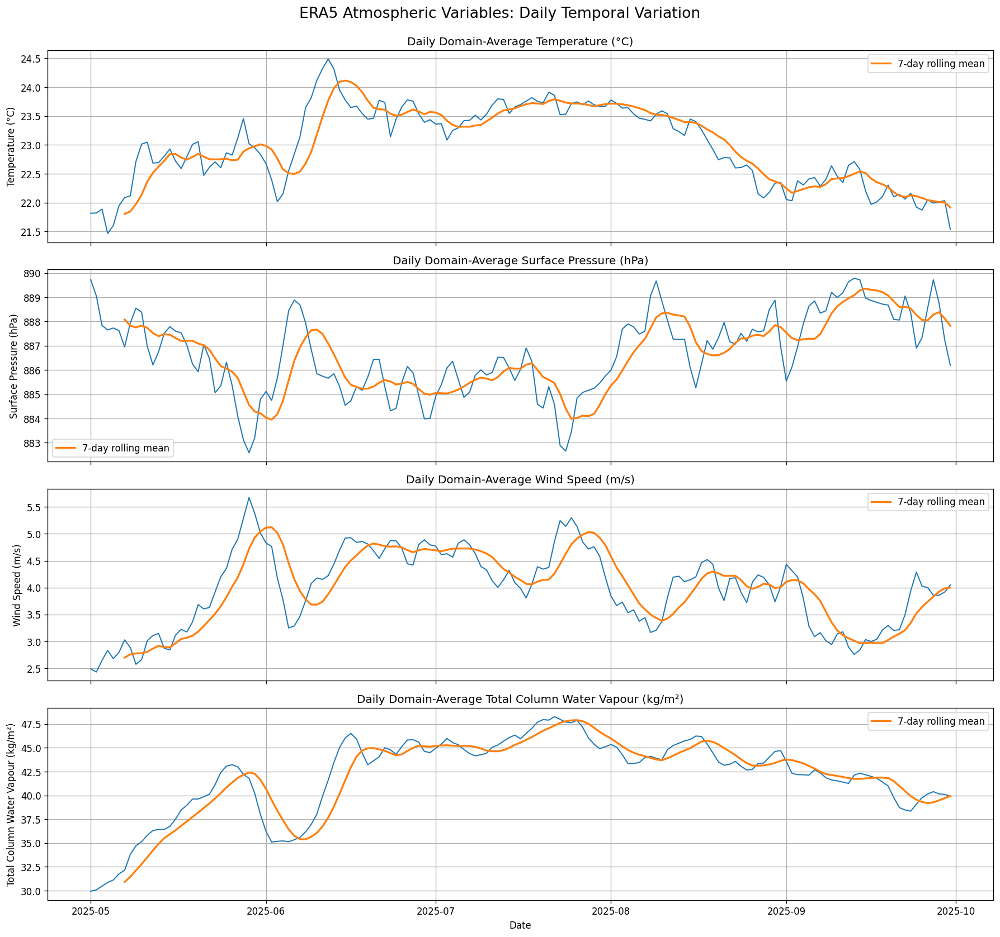

========== TEMPORAL STATISTICS ==========

Temperature (°C)
Mean: 22.984
Minimum: 21.465
Maximum: 24.487
Standard deviation: 0.685
Date of minimum: 2025-05-04 00:00:00
Date of maximum: 2025-06-12 00:00:00

Surface Pressure (hPa)
Mean: 886.701
Minimum: 882.585
Maximum: 889.783
Standard deviation: 1.642
Date of minimum: 2025-05-29 00:00:00
Date of maximum: 2025-09-13 00:00:00

Wind Speed (m/s)
Mean: 3.98
Minimum: 2.431
Maximum: 5.676
Standard deviation: 0.729
Date of minimum: 2025-05-02 00:00:00
Date of maximum: 2025-05-29 00:00:00

Total Column Water Vapour (kg/m²)
Mean: 42.045
Minimum: 29.944
Maximum: 48.258
Standard deviation: 4.185
Date of minimum: 2025-05-01 00:00:00
Date of maximum: 2025-07-22 00:00:00


In [ ]:
# --------------------------------------------------
# ERA5 daily temporal patterns
# --------------------------------------------------

variables = {
    "temperature": "Temperature (°C)",
    "pressure": "Surface Pressure (hPa)",
    "wind_speed": "Wind Speed (m/s)",
    "tcwv": "Total Column Water Vapour (kg/m²)"
}

fig, axes = plt.subplots(4, 1, figsize=(15, 14), sharex=True)

for ax, (var, label) in zip(axes, variables.items()):

    series = domain_df[["valid_time", var]].dropna()

    ax.plot(
        series["valid_time"],
        series[var],
        linewidth=1.2
    )

    # Add a 7-day rolling mean
    rolling_mean = series[var].rolling(7).mean()

    ax.plot(
        series["valid_time"],
        rolling_mean,
        linewidth=2,
        label="7-day rolling mean"
    )

    ax.set_title(f"Daily Domain-Average {label}")
    ax.set_ylabel(label)
    ax.legend()

axes[-1].set_xlabel("Date")

plt.suptitle(
    "ERA5 Atmospheric Variables: Daily Temporal Variation",
    fontsize=16,
    y=0.995
)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# Numerical temporal statistics
# --------------------------------------------------

print("========== TEMPORAL STATISTICS ==========")

for var, label in variables.items():

    series = domain_df[var].dropna()

    print(f"\n{label}")
    print("Mean:", round(series.mean(), 3))
    print("Minimum:", round(series.min(), 3))
    print("Maximum:", round(series.max(), 3))
    print("Standard deviation:", round(series.std(), 3))
    print("Date of minimum:",
          domain_df.loc[domain_df[var].idxmin(), "valid_time"])
    print("Date of maximum:",
          domain_df.loc[domain_df[var].idxmax(), "valid_time"])

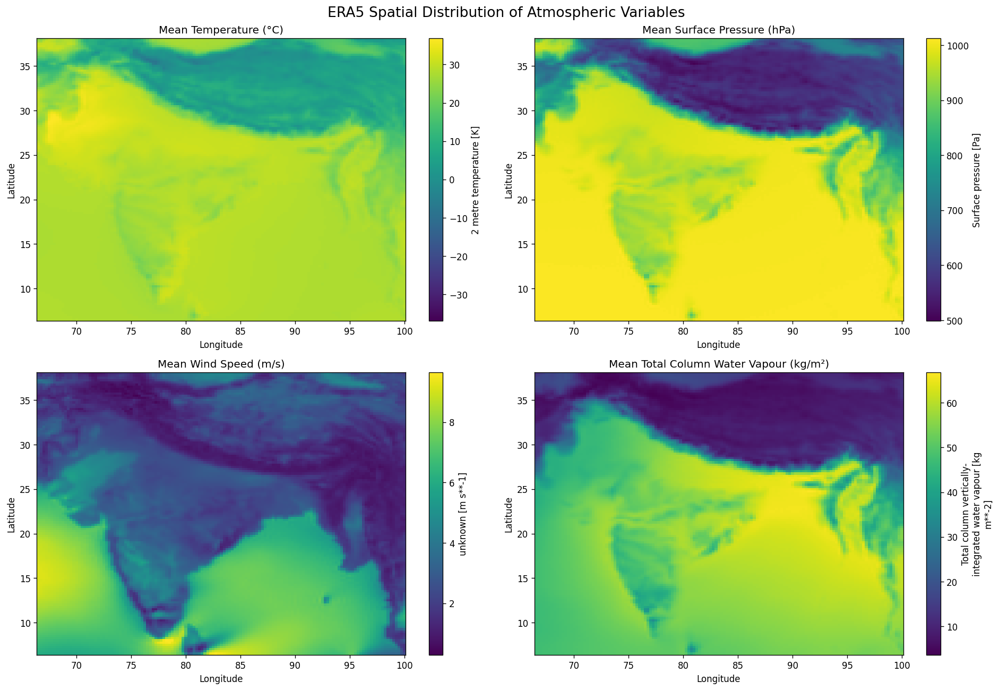

In [ ]:
# --------------------------------------------------
# ERA5 spatial mean maps
# --------------------------------------------------

variables = {
    "temperature": "Mean Temperature (°C)",
    "pressure": "Mean Surface Pressure (hPa)",
    "wind_speed": "Mean Wind Speed (m/s)",
    "tcwv": "Mean Total Column Water Vapour (kg/m²)"
}

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11)
)

axes = axes.flatten()

for ax, (var, title) in zip(axes, variables.items()):

    spatial_mean = era5_daily[var].mean(
        dim="valid_time",
        skipna=True
    )

    spatial_mean.plot(
        ax=ax,
        cmap="viridis",
        add_colorbar=True
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.suptitle(
    "ERA5 Spatial Distribution of Atmospheric Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()

========== NORMAL VS EXTREME-RAINFALL CONDITIONS ==========


temperature                                      pressure  \
                           mean     median    std     min     max        mean   
rainfall_category                                                               
Normal rainfall day   22.983999  23.047001  0.685  21.465  24.487  886.700989   

                                                              wind_speed  \
                         median    std         min        max       mean   
rainfall_category                                                          
Normal rainfall day  886.843018  1.642  882.585022  889.78302       3.98   

                                                      tcwv                    \
                    median    std    min    max       mean     median    std   
rainfall_category                                                              
Normal rainfall day  4.077  0.729  2.431  5.676  42.044998  43.224998  4.185   

                                        
                        min        max  
rainfall_category                       
Normal rainfall day  29.944  48.257999


========== DIFFERENCE BETWEEN EXTREME AND NORMAL DAYS ==========


,Normal_day_mean,Extreme_day_mean,Difference
temperature,22.983999,NaN,NaN
pressure,886.700989,NaN,NaN
wind_speed,3.980000,NaN,NaN
tcwv,42.044998,NaN,NaN


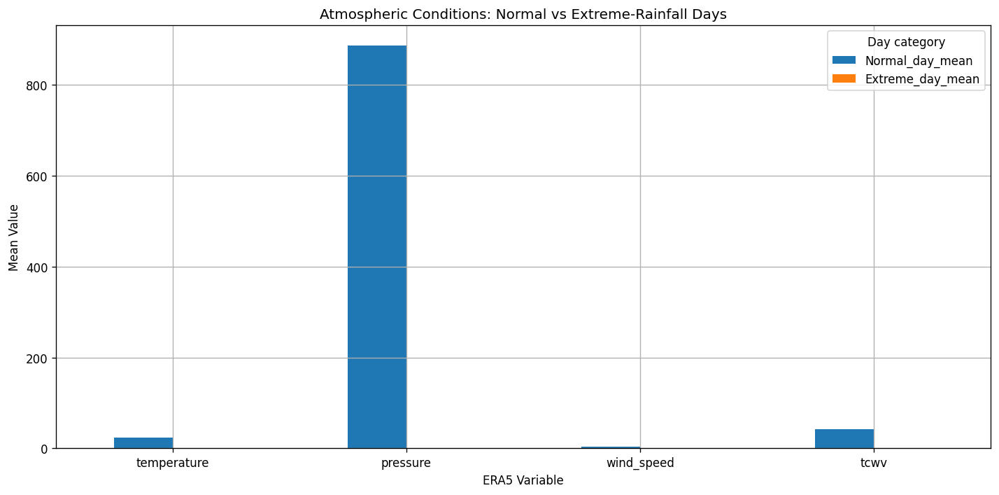

In [ ]:
# --------------------------------------------------
# Combined IMD + ERA5 analysis
# Normal days vs extreme-rainfall days
# --------------------------------------------------

# Calculate domain-average rainfall
rainfall_series = domain_df["rainfall"]

# Define extreme-rainfall threshold
extreme_threshold = 100  # mm/day

# Create day categories
domain_df["rainfall_category"] = np.where(
    domain_df["rainfall"] >= extreme_threshold,
    "Extreme rainfall day",
    "Normal rainfall day"
)

# Variables to compare
atmospheric_variables = [
    "temperature",
    "pressure",
    "wind_speed",
    "tcwv"
]

# --------------------------------------------------
# 1. Calculate group statistics
# --------------------------------------------------

group_statistics = domain_df.groupby(
    "rainfall_category"
)[atmospheric_variables].agg(
    ["mean", "median", "std", "min", "max"]
)

print("========== NORMAL VS EXTREME-RAINFALL CONDITIONS ==========")
display(group_statistics.round(3))

# --------------------------------------------------
# 2. Calculate differences
# --------------------------------------------------

normal_values = domain_df[
    domain_df["rainfall_category"] == "Normal rainfall day"
][atmospheric_variables].mean()

extreme_values = domain_df[
    domain_df["rainfall_category"] == "Extreme rainfall day"
][atmospheric_variables].mean()

comparison = pd.DataFrame({
    "Normal_day_mean": normal_values,
    "Extreme_day_mean": extreme_values,
    "Difference": extreme_values - normal_values
})

print("\n========== DIFFERENCE BETWEEN EXTREME AND NORMAL DAYS ==========")
display(comparison.round(3))

# --------------------------------------------------
# 3. Plot comparison
# --------------------------------------------------

plot_df = comparison[["Normal_day_mean", "Extreme_day_mean"]]

plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Atmospheric Conditions: Normal vs Extreme-Rainfall Days"
)

plt.xlabel("ERA5 Variable")
plt.ylabel("Mean Value")
plt.xticks(rotation=0)
plt.legend(title="Day category")
plt.tight_layout()
plt.show()

95th percentile rainfall threshold: 10.367 mm/day

========== NORMAL VS EXTREME-RAINFALL CONDITIONS ==========


temperature                                               \
                           count       mean  median    std     min        max   
rainfall_category                                                               
Extreme rainfall day          19  23.096001  23.163  0.552  22.032  23.778999   
Normal rainfall day          134  22.968000  23.011  0.702  21.465  24.487000   

                     pressure                                 ... wind_speed  \
                        count        mean      median    std  ...     median   
rainfall_category                                             ...              
Extreme rainfall day       19  885.804016  885.711975  1.205  ...      4.521   
Normal rainfall day       134  886.828003  886.958008  1.660  ...      3.992   

                                           tcwv                               \
                        std    min    max count       mean     median    std   
rainfall_category                                                              
Extreme rainfall day  0.370  3.910  5.139    19  44.553001  44.813000  2.310   
Normal rainfall day   0.731  2.431  5.676   134  41.688999  42.707001  4.275   

                                            
                            min        max  
rainfall_category                           
Extreme rainfall day  38.012001  47.880001  
Normal rainfall day   29.944000  48.257999  

[2 rows x 24 columns]


========== DIFFERENCE BETWEEN EXTREME AND NORMAL DAYS ==========


,Normal_day_mean,Extreme_day_mean,Difference
temperature,22.968000,23.096001,0.128
pressure,886.828003,885.804016,-1.024
wind_speed,3.897000,4.562000,0.665
tcwv,41.688999,44.553001,2.864


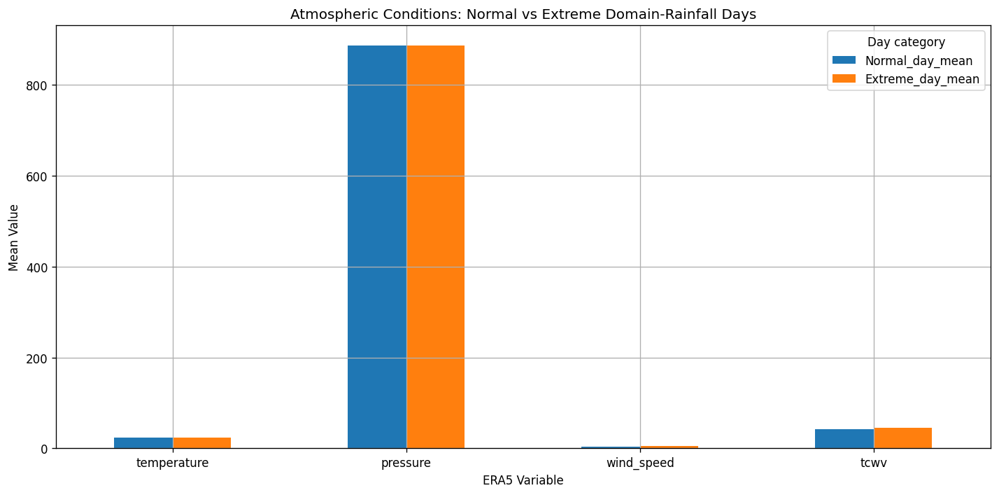

In [ ]:
# --------------------------------------------------
# Correct extreme-day classification
# Use the 95th percentile of domain-average rainfall
# --------------------------------------------------

# Remove missing rainfall values
rainfall_values = domain_df["rainfall"].dropna()

# Calculate the 95th percentile threshold
extreme_threshold = rainfall_values.quantile(0.95)

print("95th percentile rainfall threshold:",
      round(extreme_threshold, 3), "mm/day")

# Classify days
domain_df["rainfall_category"] = np.where(
    domain_df["rainfall"] >= extreme_threshold,
    "Extreme rainfall day",
    "Normal rainfall day"
)

# Atmospheric variables
atmospheric_variables = [
    "temperature",
    "pressure",
    "wind_speed",
    "tcwv"
]

# --------------------------------------------------
# 1. Group statistics
# --------------------------------------------------

group_statistics = domain_df.groupby(
    "rainfall_category"
)[atmospheric_variables].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print("\n========== NORMAL VS EXTREME-RAINFALL CONDITIONS ==========")
display(group_statistics.round(3))

# --------------------------------------------------
# 2. Calculate differences
# --------------------------------------------------

normal_values = domain_df[
    domain_df["rainfall_category"] == "Normal rainfall day"
][atmospheric_variables].mean()

extreme_values = domain_df[
    domain_df["rainfall_category"] == "Extreme rainfall day"
][atmospheric_variables].mean()

comparison = pd.DataFrame({
    "Normal_day_mean": normal_values,
    "Extreme_day_mean": extreme_values,
    "Difference": extreme_values - normal_values
})

print("\n========== DIFFERENCE BETWEEN EXTREME AND NORMAL DAYS ==========")
display(comparison.round(3))

# --------------------------------------------------
# 3. Plot comparison
# --------------------------------------------------

comparison[[
    "Normal_day_mean",
    "Extreme_day_mean"
]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Atmospheric Conditions: Normal vs Extreme Domain-Rainfall Days"
)

plt.xlabel("ERA5 Variable")
plt.ylabel("Mean Value")
plt.xticks(rotation=0)
plt.legend(title="Day category")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import os
import glob

# Find uploaded Excel/CSV files
files = (
    glob.glob("/content/*.xlsx")
    + glob.glob("/content/*.xls")
    + glob.glob("/content/*.csv")
)

print("Files found:")
for i, file in enumerate(files):
    print(i, os.path.basename(file))

# Select the first Excel file
file_path = files[0]
print("\nSelected file:", file_path)

# Read Excel file
excel_file = pd.ExcelFile(file_path)

print("\nSheet names:")
print(excel_file.sheet_names)

# Read the first sheet
df_raw = pd.read_excel(file_path, sheet_name=excel_file.sheet_names[0])

print("\nDataset shape:", df_raw.shape)

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nFirst five rows:")
display(df_raw.head())

Files found:
0 rainfall_tel_hr_uttarakhand_uk_2021_2025.csv

Selected file: /content/rainfall_tel_hr_uttarakhand_uk_2021_2025.csv


ValueError: Excel file format cannot be determined, you must specify an engine manually.

In [ ]:
import pandas as pd
import numpy as np
import os

file_path = "/content/rainfall_tel_hr_uttarakhand_uk_2021_2025.csv"

# Load CSV
df_raw = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Shape:", df_raw.shape)

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types:")
display(df_raw.dtypes)

print("\nFirst 10 rows:")
display(df_raw.head(10))

print("\nLast 5 rows:")
display(df_raw.tail())

Dataset loaded successfully
Shape: (37410, 20)

Column names:
['SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River', 'Latitude', 'Longitude', 'Data Acquisition Time', 'Telemetry Hourly Rainfall (mm)']

Data types:


,0
SlNo,int64
Station,object
Agency,object
State LGD Code,int64
State,object
District LGD Code,int64
District,object
Tehsil,object
Block,object
Village,object



First 10 rows:


,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,River,Basin,Tributary,Subtributary,SubSubtributary,Local River,Latitude,Longitude,Data Acquisition Time,Telemetry Hourly Rainfall (mm)
0,1,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 10:00,1.0
1,2,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 11:00,1.0
2,3,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 12:00,1.0
3,4,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 13:00,1.0
4,5,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 14:00,1.0
5,6,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 15:00,1.0
6,7,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 16:00,1.0
7,8,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 17:00,1.0
8,9,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 19:00,1.0
9,10,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 20:00,1.0



Last 5 rows:


,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,River,Basin,Tributary,Subtributary,SubSubtributary,Local River,Latitude,Longitude,Data Acquisition Time,Telemetry Hourly Rainfall (mm)
37405,37406,Yamuna Colony,Uttarakhand,5,Uttarakhand,49,Dehradun,Dehradun,-,-,-,-,-,-,-,-,30.337753,78.033117,29-09-2025 14:00,0.5
37406,37407,Yamuna Colony,Uttarakhand,5,Uttarakhand,49,Dehradun,Dehradun,-,-,-,-,-,-,-,-,30.337753,78.033117,30-09-2025 23:00,3.0
37407,37408,Yamuna Colony,Uttarakhand,5,Uttarakhand,49,Dehradun,Dehradun,-,-,-,-,-,-,-,-,30.337753,78.033117,15-12-2025 15:00,8.0
37408,37409,Yamuna Colony,Uttarakhand,5,Uttarakhand,49,Dehradun,Dehradun,-,-,-,-,-,-,-,-,30.337753,78.033117,19-12-2025 01:00,233.5
37409,37410,Yamuna Colony,Uttarakhand,5,Uttarakhand,49,Dehradun,Dehradun,-,-,-,-,-,-,-,-,30.337753,78.033117,20-12-2025 20:00,48.0


In [ ]:
import pandas as pd
import numpy as np

file_path = "/content/rainfall_tel_hr_uttarakhand_uk_2021_2025.csv"

# Load the official rainfall dataset
df_raw = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Shape:", df_raw.shape)

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types:")
display(df_raw.dtypes)

print("\nFirst 10 rows:")
display(df_raw.head(10))

print("\nLast 5 rows:")
display(df_raw.tail())

Dataset loaded successfully
Shape: (37410, 20)

Column names:
['SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River', 'Latitude', 'Longitude', 'Data Acquisition Time', 'Telemetry Hourly Rainfall (mm)']

Data types:


,0
SlNo,int64
Station,object
Agency,object
State LGD Code,int64
State,object
District LGD Code,int64
District,object
Tehsil,object
Block,object
Village,object



First 10 rows:


,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,River,Basin,Tributary,Subtributary,SubSubtributary,Local River,Latitude,Longitude,Data Acquisition Time,Telemetry Hourly Rainfall (mm)
0,1,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 10:00,1.0
1,2,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 11:00,1.0
2,3,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 12:00,1.0
3,4,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 13:00,1.0
4,5,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 14:00,1.0
5,6,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 15:00,1.0
6,7,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 16:00,1.0
7,8,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 17:00,1.0
8,9,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 19:00,1.0
9,10,Almora_1,Uttarakhand,5,Uttarakhand,45,Almora,-,-,-,-,-,-,-,-,-,29.595758,79.650639,05-10-2022 20:00,1.0



Last 5 rows:


,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,River,Basin,Tributary,Subtributary,SubSubtributary,Local River,Latitude,Longitude,Data Acquisition Time,Telemetry Hourly Rainfall (mm)
37405,37406,Yamuna Colony,Uttarakhand,5,Uttarakhand,49,Dehradun,Dehradun,-,-,-,-,-,-,-,-,30.337753,78.033117,29-09-2025 14:00,0.5
37406,37407,Yamuna Colony,Uttarakhand,5,Uttarakhand,49,Dehradun,Dehradun,-,-,-,-,-,-,-,-,30.337753,78.033117,30-09-2025 23:00,3.0
37407,37408,Yamuna Colony,Uttarakhand,5,Uttarakhand,49,Dehradun,Dehradun,-,-,-,-,-,-,-,-,30.337753,78.033117,15-12-2025 15:00,8.0
37408,37409,Yamuna Colony,Uttarakhand,5,Uttarakhand,49,Dehradun,Dehradun,-,-,-,-,-,-,-,-,30.337753,78.033117,19-12-2025 01:00,233.5
37409,37410,Yamuna Colony,Uttarakhand,5,Uttarakhand,49,Dehradun,Dehradun,-,-,-,-,-,-,-,-,30.337753,78.033117,20-12-2025 20:00,48.0


In [ ]:
# Make a working copy
df = df_raw.copy()

# Rename important columns for easier coding
df = df.rename(columns={
    "Data Acquisition Time": "datetime",
    "Telemetry Hourly Rainfall (mm)": "rainfall_mm",
    "Latitude": "latitude",
    "Longitude": "longitude"
})

# Convert timestamp
df["datetime"] = pd.to_datetime(
    df["datetime"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Convert rainfall and coordinates to numeric
df["rainfall_mm"] = pd.to_numeric(df["rainfall_mm"], errors="coerce")
df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")

print("Dataset shape:", df.shape)

print("\nDate range:")
print("Start:", df["datetime"].min())
print("End:", df["datetime"].max())

print("\nNumber of unique stations:", df["Station"].nunique())

print("\nNumber of districts:", df["District"].nunique())

print("\nRainfall statistics:")
display(df["rainfall_mm"].describe())

print("\nMissing values in important columns:")
display(df[["Station", "datetime", "latitude", "longitude", "rainfall_mm"]].isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFirst five cleaned rows:")
display(df[["Station", "datetime", "latitude", "longitude", "rainfall_mm"]].head())

Dataset shape: (37410, 20)

Date range:
Start: 2022-01-31 19:00:00
End: 2025-12-23 01:00:00

Number of unique stations: 47

Number of districts: 13

Rainfall statistics:


,rainfall_mm
count,37410.000000
mean,34.324472
std,91.916776
min,-503.500000
25%,0.500000
50%,1.500000
75%,6.500000
max,511.500000



Missing values in important columns:


,0
Station,0
datetime,0
latitude,0
longitude,0
rainfall_mm,0



Duplicate rows: 0

First five cleaned rows:


,Station,datetime,latitude,longitude,rainfall_mm
0,Almora_1,2022-10-05 10:00:00,29.595758,79.650639,1.0
1,Almora_1,2022-10-05 11:00:00,29.595758,79.650639,1.0
2,Almora_1,2022-10-05 12:00:00,29.595758,79.650639,1.0
3,Almora_1,2022-10-05 13:00:00,29.595758,79.650639,1.0
4,Almora_1,2022-10-05 14:00:00,29.595758,79.650639,1.0


In [ ]:
# Inspect rainfall values and temporal coverage

print("Negative rainfall records:", (df["rainfall_mm"] < 0).sum())

print("\nNegative rainfall values:")
display(
    df.loc[df["rainfall_mm"] < 0,
           ["Station", "datetime", "rainfall_mm"]]
    .sort_values("rainfall_mm")
    .head(20)
)

print("\nRainfall value frequency for unusual values:")
display(
    df["rainfall_mm"]
    .value_counts()
    .sort_index()
    .head(20)
)

print("\nRecords by year:")
display(df["datetime"].dt.year.value_counts().sort_index())

print("\nRecords by month:")
display(df["datetime"].dt.month.value_counts().sort_index())

print("\nRecords by station:")
display(
    df.groupby("Station")
      .agg(
          records=("rainfall_mm", "size"),
          start_date=("datetime", "min"),
          end_date=("datetime", "max"),
          min_rainfall=("rainfall_mm", "min"),
          max_rainfall=("rainfall_mm", "max")
      )
      .sort_values("records", ascending=False)
)

Negative rainfall records: 67

Negative rainfall values:


,Station,datetime,rainfall_mm
14350,Gola_1,2024-07-23 11:00:00,-503.5
25380,Nainital_1,2024-09-04 11:00:00,-491.5
3407,Baijnath (Gomti),2025-02-28 08:00:00,-451.5
21638,Kosi_1,2024-07-12 09:00:00,-442.0
20623,Kempty,2024-10-22 01:00:00,-417.5
31821,Tanakpur_1,2024-03-03 14:00:00,-415.5
35542,Yamuna Colony,2024-07-27 23:00:00,-394.0
1630,Badrinath_1,2024-07-28 17:00:00,-389.0
26991,Purola_1,2024-08-14 04:30:00,-378.5
28162,Roorkee_2,2024-07-22 12:30:00,-353.5



Rainfall value frequency for unusual values:


,count
rainfall_mm,
-503.5,1
-491.5,1
-451.5,1
-442.0,1
-417.5,1
-415.5,1
-394.0,1
-389.0,1
-378.5,1



Records by year:


,count
datetime,
2022,2633
2023,17977
2024,11118
2025,5682



Records by month:


,count
datetime,
1,1559
2,2304
3,2901
4,1614
5,3334
6,4288
7,7690
8,5061
9,4647



Records by station:


,records,start_date,end_date,min_rainfall,max_rainfall
Station,,,,,
Yamuna Colony,3277,2022-09-24 20:00:00,2025-12-20 20:00:00,-394.0,511.5
Gairsain (Ramganga),1886,2022-07-05 14:00:00,2025-05-06 22:00:00,0.5,403.5
Kapkot (Saryu),1679,2022-12-11 17:00:00,2025-09-30 10:00:00,0.5,384.0
Roorkee_2,1620,2022-06-23 13:00:00,2025-12-20 02:00:00,-353.5,511.5
Lamgara,1458,2022-09-08 15:00:00,2025-12-23 01:00:00,0.5,305.0
Kempty,1456,2023-02-07 12:00:00,2025-08-10 02:00:00,-417.5,468.5
Mukteshwar_1,1191,2023-02-22 18:00:00,2025-07-29 16:00:00,-279.0,492.0
Dharchula_1,1157,2022-12-27 20:00:00,2025-08-11 11:00:00,-217.0,448.0
Basukedar,1154,2023-09-11 17:00:00,2025-09-30 23:00:00,-85.0,444.0


In [ ]:
# Create a cleaned rainfall dataset

df_clean = df.copy()

# Count invalid rainfall values
invalid_mask = df_clean["rainfall_mm"] < 0

print("Invalid negative rainfall records:", invalid_mask.sum())

# Replace physically impossible negative values with NaN
df_clean.loc[invalid_mask, "rainfall_mm"] = np.nan

print("\nRainfall statistics after removing invalid values:")
display(df_clean["rainfall_mm"].describe())

print("\nMissing rainfall values after cleaning:")
print(df_clean["rainfall_mm"].isna().sum())

print("\nValid rainfall records:")
print(df_clean["rainfall_mm"].notna().sum())

Invalid negative rainfall records: 67

Rainfall statistics after removing invalid values:


,rainfall_mm
count,37343.000000
mean,34.709035
std,91.347538
min,0.500000
25%,0.500000
50%,1.500000
75%,6.500000
max,511.500000



Missing rainfall values after cleaning:
67

Valid rainfall records:
37343


In [ ]:
# Station-wise data quality assessment

station_quality = (
    df_clean.groupby("Station")
    .agg(
        total_records=("rainfall_mm", "size"),
        valid_records=("rainfall_mm", "count"),
        invalid_records=("rainfall_mm", lambda x: x.isna().sum()),
        mean_rainfall=("rainfall_mm", "mean"),
        maximum_rainfall=("rainfall_mm", "max"),
        start_date=("datetime", "min"),
        end_date=("datetime", "max")
    )
    .reset_index()
)

station_quality["valid_percentage"] = (
    station_quality["valid_records"] /
    station_quality["total_records"] * 100
)

print("Stations:", len(station_quality))

print("\nStations with invalid rainfall records:")
display(
    station_quality[
        station_quality["invalid_records"] > 0
    ].sort_values("invalid_records", ascending=False)
)

print("\nStations with the highest maximum rainfall:")
display(
    station_quality
    .sort_values("maximum_rainfall", ascending=False)
    .head(15)
    .round(2)
)

print("\nStations with the fewest records:")
display(
    station_quality
    .sort_values("total_records")
    .head(15)
)

Stations: 47

Stations with invalid rainfall records:


,Station,total_records,valid_records,invalid_records,mean_rainfall,maximum_rainfall,start_date,end_date,valid_percentage
40,Sonprayag_1,861,854,7,6.823770,396.0,2023-06-13 19:00:00,2025-09-29 03:00:00,99.186992
4,Baijnath (Gomti),982,976,6,14.621414,489.5,2022-12-31 02:00:00,2025-08-23 03:00:00,99.389002
24,Kempty,1456,1452,4,10.388774,468.5,2023-02-07 12:00:00,2025-08-10 02:00:00,99.725275
42,Tanakpur_1,1060,1056,4,8.803977,371.0,2022-06-21 19:00:00,2025-12-16 15:00:00,99.622642
18,Guptkashi_1,599,595,4,53.481513,511.5,2023-02-04 16:00:00,2025-10-02 03:00:00,99.332220
12,Dharchula_1,1157,1153,4,7.240676,448.0,2022-12-27 20:00:00,2025-08-11 11:00:00,99.654278
17,Gola_1,641,638,3,5.142633,370.5,2022-12-31 13:00:00,2025-03-13 23:00:00,99.531981
8,Champawat_1,1109,1106,3,7.762658,472.5,2023-01-04 11:00:00,2025-09-30 10:00:00,99.729486
45,Yamkeshwar,352,349,3,33.614613,492.0,2023-01-18 14:00:00,2025-08-28 01:00:00,99.147727
37,Roorkee_2,1620,1617,3,122.224181,511.5,2022-06-23 13:00:00,2025-12-20 02:00:00,99.814815



Stations with the highest maximum rainfall:


,Station,total_records,valid_records,invalid_records,mean_rainfall,maximum_rainfall,start_date,end_date,valid_percentage
41,Srinagar_2,443,443,0,53.31,511.5,2023-01-03 06:00:00,2025-12-20 21:00:00,100.00
46,Yamuna Colony,3277,3275,2,245.86,511.5,2022-09-24 20:00:00,2025-12-20 20:00:00,99.94
18,Guptkashi_1,599,595,4,53.48,511.5,2023-02-04 16:00:00,2025-10-02 03:00:00,99.33
37,Roorkee_2,1620,1617,3,122.22,511.5,2022-06-23 13:00:00,2025-12-20 02:00:00,99.81
14,Dugadda (Khoh),471,470,1,6.04,507.5,2022-12-19 12:00:00,2025-09-30 14:00:00,99.79
13,Doiwala (Bhogpur),162,160,2,38.60,504.0,2022-09-04 15:00:00,2025-07-28 14:00:00,98.77
25,Khanpur_5,554,554,0,9.25,500.0,2023-04-20 14:55:00,2025-08-03 23:00:00,100.00
26,Khati_1,181,181,0,15.06,498.0,2023-10-07 11:00:00,2025-09-13 13:00:00,100.00
6,Bhagwanpur_1,84,84,0,24.45,495.5,2024-04-16 15:00:00,2025-12-22 15:00:00,100.00
30,Mukteshwar_1,1191,1189,2,10.64,492.0,2023-02-22 18:00:00,2025-07-29 16:00:00,99.83



Stations with the fewest records:


,Station,total_records,valid_records,invalid_records,mean_rainfall,maximum_rainfall,start_date,end_date,valid_percentage
35,Purola_1,43,42,1,95.107143,478.5,2023-06-26 03:00:00,2025-12-21 18:00:00,97.674419
6,Bhagwanpur_1,84,84,0,24.452381,495.5,2024-04-16 15:00:00,2025-12-22 15:00:00,100.000000
32,Nainital_1,146,145,1,11.434483,352.0,2024-04-10 13:00:00,2025-08-10 04:00:00,99.315068
13,Doiwala (Bhogpur),162,160,2,38.596875,504.0,2022-09-04 15:00:00,2025-07-28 14:00:00,98.765432
26,Khati_1,181,181,0,15.058011,498.0,2023-10-07 11:00:00,2025-09-13 13:00:00,100.000000
36,Rithakhal,190,190,0,5.815789,257.0,2023-11-18 10:00:00,2025-09-30 10:00:00,100.000000
21,Jhala_1,199,199,0,0.884422,5.0,2024-02-04 11:00:00,2025-07-10 16:00:00,100.000000
1,Assan_1,215,215,0,1.690698,9.5,2022-08-18 17:00:00,2022-10-12 08:00:00,100.000000
27,Kosi_1,235,234,1,10.235043,321.5,2022-07-28 19:00:00,2025-08-28 01:00:00,99.574468
2,Badrinath_1,278,277,1,8.848375,422.0,2023-06-03 06:00:00,2025-07-16 20:00:00,99.640288


In [ ]:
# Inspect the highest rainfall observations

top_rainfall_records = (
    df_clean
    .dropna(subset=["rainfall_mm"])
    .sort_values("rainfall_mm", ascending=False)
)

print("Top 30 rainfall observations:")
display(
    top_rainfall_records[
        [
            "Station",
            "datetime",
            "latitude",
            "longitude",
            "rainfall_mm"
        ]
    ].head(30)
)

print("\nNumber of records with rainfall >= 200 mm:")
print((df_clean["rainfall_mm"] >= 200).sum())

print("\nNumber of records with rainfall >= 300 mm:")
print((df_clean["rainfall_mm"] >= 300).sum())

print("\nNumber of records with rainfall >= 400 mm:")
print((df_clean["rainfall_mm"] >= 400).sum())

print("\nNumber of records with rainfall >= 500 mm:")
print((df_clean["rainfall_mm"] >= 500).sum())

Top 30 rainfall observations:


,Station,datetime,latitude,longitude,rainfall_mm
28416,Roorkee_2,2024-10-12 07:00:00,29.867719,77.884156,511.5
28418,Roorkee_2,2024-10-13 07:00:00,29.867719,77.884156,511.5
28317,Roorkee_2,2024-09-06 06:00:00,29.867719,77.884156,511.5
30762,Srinagar_2,2023-11-19 16:00:00,30.235819,78.817203,511.5
30763,Srinagar_2,2023-11-24 19:00:00,30.235819,78.817203,511.5
30764,Srinagar_2,2023-11-24 22:00:00,30.235819,78.817203,511.5
30765,Srinagar_2,2023-11-25 00:00:00,30.235819,78.817203,511.5
27967,Roorkee_2,2024-03-31 07:00:00,29.867719,77.884156,511.5
27961,Roorkee_2,2024-03-30 08:00:00,29.867719,77.884156,511.5
28431,Roorkee_2,2024-11-01 07:00:00,29.867719,77.884156,511.5



Number of records with rainfall >= 200 mm:
3722

Number of records with rainfall >= 300 mm:
1677

Number of records with rainfall >= 400 mm:
159

Number of records with rainfall >= 500 mm:
115


In [ ]:
# Inspect repeated high rainfall values

print("Frequency of rainfall values >= 200 mm:")
display(
    df_clean.loc[df_clean["rainfall_mm"] >= 200, "rainfall_mm"]
    .value_counts()
    .sort_index(ascending=False)
    .head(30)
)

print("\nRecords with rainfall >= 500 mm:")
display(
    df_clean[
        df_clean["rainfall_mm"] >= 500
    ][
        [
            "Station",
            "datetime",
            "latitude",
            "longitude",
            "rainfall_mm"
        ]
    ].sort_values(["Station", "datetime"])
)

print("\nNumber of unique rainfall values >= 400 mm:")
print(
    df_clean.loc[
        df_clean["rainfall_mm"] >= 400,
        "rainfall_mm"
    ].nunique()
)

Frequency of rainfall values >= 200 mm:


,count
rainfall_mm,
511.5,112
507.5,1
504.0,1
500.0,1
498.0,1
495.5,1
495.0,1
492.0,2
489.5,2



Records with rainfall >= 500 mm:


,Station,datetime,latitude,longitude,rainfall_mm
10345,Doiwala (Bhogpur),2023-07-04 13:00:00,30.222708,78.234186,504.0
10735,Dugadda (Khoh),2024-07-31 04:00:00,29.751083,78.523417,507.5
14358,Guptkashi_1,2023-02-04 16:00:00,30.528639,79.085083,511.5
14359,Guptkashi_1,2023-02-04 17:00:00,30.528639,79.085083,511.5
14360,Guptkashi_1,2023-02-22 12:00:00,30.528639,79.085083,511.5
...,...,...,...,...,...
30766,Srinagar_2,2023-11-25 11:00:00,30.235819,78.817203,511.5
30767,Srinagar_2,2023-11-25 20:00:00,30.235819,78.817203,511.5
30768,Srinagar_2,2024-06-04 14:00:00,30.235819,78.817203,511.5
36562,Yamuna Colony,2025-01-07 23:00:00,30.337753,78.033117,511.5



Number of unique rainfall values >= 400 mm:
44


In [ ]:
# Analyse repeated and suspicious rainfall values

value_counts = (
    df_clean["rainfall_mm"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Most frequent rainfall values:")
display(value_counts.head(20).to_frame("frequency"))

print("\nNumber of records equal to 511.5 mm:")
print((df_clean["rainfall_mm"] == 511.5).sum())

print("\nStations containing 511.5 mm:")
display(
    df_clean.loc[
        df_clean["rainfall_mm"] == 511.5,
        ["Station", "datetime", "latitude", "longitude", "rainfall_mm"]
    ]
    .groupby("Station")
    .agg(
        records=("rainfall_mm", "size"),
        first_occurrence=("datetime", "min"),
        last_occurrence=("datetime", "max")
    )
    .sort_values("records", ascending=False)
)

print("\nMonthly distribution of 511.5 mm values:")
display(
    df_clean.loc[
        df_clean["rainfall_mm"] == 511.5,
        "datetime"
    ]
    .dt.month
    .value_counts()
    .sort_index()
)

print("\nYearly distribution of 511.5 mm values:")
display(
    df_clean.loc[
        df_clean["rainfall_mm"] == 511.5,
        "datetime"
    ]
    .dt.year
    .value_counts()
    .sort_index()
)

Most frequent rainfall values:


,frequency
rainfall_mm,
0.5,12578
1.0,4060
1.5,2477
2.0,1786
2.5,1543
3.0,1136
3.5,969
4.0,833
4.5,737



Number of records equal to 511.5 mm:
112

Stations containing 511.5 mm:


,records,first_occurrence,last_occurrence
Station,,,
Guptkashi_1,56,2023-02-04 16:00:00,2023-03-24 11:00:00
Roorkee_2,40,2024-03-06 07:00:00,2025-03-04 07:00:00
Srinagar_2,14,2023-11-14 21:00:00,2024-06-04 14:00:00
Yamuna Colony,2,2025-01-07 23:00:00,2025-01-10 01:00:00



Monthly distribution of 511.5 mm values:


,count
datetime,
1,6
2,48
3,18
6,1
9,3
10,4
11,23
12,9



Yearly distribution of 511.5 mm values:


,count
datetime,
2023,69
2024,31
2025,12


In [ ]:
df_analysis = df_clean.copy()

# Flag suspicious repeated maximum values
df_analysis["suspicious_511_5"] = (
    df_analysis["rainfall_mm"] == 511.5
)

print("Total records:", len(df_analysis))
print("Suspicious 511.5 mm records:",
      df_analysis["suspicious_511_5"].sum())

display(
    df_analysis[df_analysis["suspicious_511_5"]]
    [["Station", "datetime", "latitude", "longitude", "rainfall_mm"]]
    .head(20)
)

Total records: 37410
Suspicious 511.5 mm records: 112


,Station,datetime,latitude,longitude,rainfall_mm
14358,Guptkashi_1,2023-02-04 16:00:00,30.528639,79.085083,511.5
14359,Guptkashi_1,2023-02-04 17:00:00,30.528639,79.085083,511.5
14360,Guptkashi_1,2023-02-22 12:00:00,30.528639,79.085083,511.5
14361,Guptkashi_1,2023-02-22 13:00:00,30.528639,79.085083,511.5
14362,Guptkashi_1,2023-02-22 14:00:00,30.528639,79.085083,511.5
14363,Guptkashi_1,2023-02-22 15:00:00,30.528639,79.085083,511.5
14364,Guptkashi_1,2023-02-22 16:00:00,30.528639,79.085083,511.5
14365,Guptkashi_1,2023-02-22 17:00:00,30.528639,79.085083,511.5
14366,Guptkashi_1,2023-02-22 18:00:00,30.528639,79.085083,511.5
14367,Guptkashi_1,2023-02-22 19:00:00,30.528639,79.085083,511.5


In [ ]:
df_without_suspicious = df_analysis[
    ~df_analysis["suspicious_511_5"]
].copy()

print("Original valid records:", len(df_analysis))
print("Records after excluding 511.5 mm:", len(df_without_suspicious))
print("Records excluded:",
      df_analysis["suspicious_511_5"].sum())

Original valid records: 37410
Records after excluding 511.5 mm: 37298
Records excluded: 112


In [ ]:
comparison = pd.DataFrame({
    "With_511.5_values": df_analysis["rainfall_mm"].describe(),
    "Without_511.5_values": df_without_suspicious["rainfall_mm"].describe()
})

display(comparison)

,With_511.5_values,Without_511.5_values
count,37343.000000,37231.000000
mean,34.709035,33.274731
std,91.347538,87.655783
min,0.500000,0.500000
25%,0.500000,0.500000
50%,1.500000,1.500000
75%,6.500000,6.500000
max,511.500000,507.500000


In [ ]:
rainfall = df_without_suspicious["rainfall_mm"].dropna()

print("Rainfall distribution statistics:")
print(rainfall.describe())

print("\nPercentile thresholds:")
for p in [90, 95, 99, 99.5, 99.9]:
    print(f"{p}th percentile: {rainfall.quantile(p):.3f} mm")

print("\nSkewness:", rainfall.skew())
print("Kurtosis:", rainfall.kurtosis())

Rainfall distribution statistics:
count    37231.000000
mean        33.274731
std         87.655783
min          0.500000
25%          0.500000
50%          1.500000
75%          6.500000
max        507.500000
Name: rainfall_mm, dtype: float64

Percentile thresholds:


ValueError: percentiles should all be in the interval [0, 1]

In [ ]:
rainfall = df_without_suspicious["rainfall_mm"].dropna()

print("Rainfall distribution statistics:")
print(rainfall.describe())

print("\nPercentile thresholds:")
for p in [90, 95, 99, 99.5, 99.9]:
    threshold = rainfall.quantile(p / 100)
    print(f"{p}th percentile: {threshold:.3f} mm")

print("\nSkewness:", rainfall.skew())
print("Kurtosis:", rainfall.kurtosis())

Rainfall distribution statistics:
count    37231.000000
mean        33.274731
std         87.655783
min          0.500000
25%          0.500000
50%          1.500000
75%          6.500000
max        507.500000
Name: rainfall_mm, dtype: float64

Percentile thresholds:
90th percentile: 160.000 mm
95th percentile: 289.500 mm
99th percentile: 348.000 mm
99.5th percentile: 361.425 mm
99.9th percentile: 420.965 mm

Skewness: 2.7433636056021693
Kurtosis: 5.974941171816408


In [ ]:
df_check = df_without_suspicious.sort_values(
    ["Station", "datetime"]
).copy()

df_check["time_gap_hours"] = (
    df_check.groupby("Station")["datetime"]
    .diff()
    .dt.total_seconds() / 3600
)

print("Time-gap statistics:")
print(df_check["time_gap_hours"].describe())

print("\nMost common time gaps:")
display(
    df_check["time_gap_hours"]
    .value_counts()
    .head(15)
    .to_frame("frequency")
)

print("\nPercentage of consecutive records exactly 1 hour apart:")
valid_gaps = df_check["time_gap_hours"].dropna()
print((valid_gaps == 1).mean() * 100)

Time-gap statistics:
count    37251.000000
mean        27.159327
std        204.330274
min          0.000000
25%          1.000000
50%          1.000000
75%          3.000000
max      11210.500000
Name: time_gap_hours, dtype: float64

Most common time gaps:


,frequency
time_gap_hours,
1.0,19579
0.0,5387
2.0,2606
3.0,1142
4.0,694
5.0,526
6.0,380
7.0,299
8.0,289



Percentage of consecutive records exactly 1 hour apart:
52.559662827843546


In [ ]:
duplicates = df_without_suspicious[
    df_without_suspicious.duplicated(
        subset=["Station", "datetime"],
        keep=False
    )
].sort_values(["Station", "datetime"])

print("Total duplicate station-timestamp records:",
      len(duplicates))

print("Number of duplicated station-timestamp groups:",
      duplicates.groupby(["Station", "datetime"]).ngroups)

display(
    duplicates[
        ["Station", "datetime", "latitude",
         "longitude", "rainfall_mm"]
    ].head(30)
)

Total duplicate station-timestamp records: 10765
Number of duplicated station-timestamp groups: 5378


,Station,datetime,latitude,longitude,rainfall_mm
153,Almora_1,2023-01-25 00:00:00,29.596314,79.650056,2.5
154,Almora_1,2023-01-25 00:00:00,29.595758,79.650639,1.0
155,Almora_1,2023-01-25 02:00:00,29.595758,79.650639,1.5
156,Almora_1,2023-01-25 02:00:00,29.596314,79.650056,2.5
157,Almora_1,2023-01-25 03:00:00,29.596314,79.650056,3.0
158,Almora_1,2023-01-25 03:00:00,29.595758,79.650639,2.5
159,Almora_1,2023-01-25 04:00:00,29.596314,79.650056,3.5
160,Almora_1,2023-01-25 04:00:00,29.595758,79.650639,3.0
161,Almora_1,2023-01-25 06:00:00,29.595758,79.650639,4.0
162,Almora_1,2023-01-25 06:00:00,29.596314,79.650056,3.5


In [ ]:
df_geo = df_without_suspicious.copy()

# Round coordinates slightly to avoid tiny floating-point differences
df_geo["latitude_rounded"] = df_geo["latitude"].round(5)
df_geo["longitude_rounded"] = df_geo["longitude"].round(5)

# Check duplicates using station, coordinates, and timestamp
duplicate_geo = df_geo[
    df_geo.duplicated(
        subset=[
            "Station",
            "latitude_rounded",
            "longitude_rounded",
            "datetime"
        ],
        keep=False
    )
]

print("Duplicate records after including coordinates:",
      len(duplicate_geo))

print("Duplicate groups after including coordinates:",
      duplicate_geo.groupby(
          ["Station", "latitude_rounded",
           "longitude_rounded", "datetime"]
      ).ngroups)

display(
    duplicate_geo[
        ["Station", "datetime",
         "latitude", "longitude", "rainfall_mm"]
    ].head(30)
)

Duplicate records after including coordinates: 10556
Duplicate groups after including coordinates: 5278


,Station,datetime,latitude,longitude,rainfall_mm
437,Almora_1,2023-04-20 00:00:00,29.595758,79.650639,0.5
438,Almora_1,2023-04-20 00:00:00,29.595758,79.650639,1.0
463,Almora_1,2023-04-30 14:00:00,29.596314,79.650056,0.5
464,Almora_1,2023-04-30 14:00:00,29.596314,79.650056,0.5
481,Almora_1,2023-05-01 00:00:00,29.595758,79.650639,7.5
482,Almora_1,2023-05-01 00:00:00,29.595758,79.650639,3.0
484,Almora_1,2023-05-01 01:00:00,29.595758,79.650639,8.0
485,Almora_1,2023-05-01 01:00:00,29.595758,79.650639,1.0
487,Almora_1,2023-05-01 02:00:00,29.595758,79.650639,8.0
488,Almora_1,2023-05-01 02:00:00,29.595758,79.650639,0.5


In [ ]:
# Work from the dataset where suspicious 511.5 mm values were excluded
df_hourly = df_without_suspicious.copy()

# Round coordinates to avoid tiny floating-point differences
df_hourly["latitude"] = df_hourly["latitude"].round(5)
df_hourly["longitude"] = df_hourly["longitude"].round(5)

# Aggregate duplicate station-location-time records
df_hourly = (
    df_hourly
    .groupby(
        ["Station", "latitude", "longitude", "datetime"],
        as_index=False
    )["rainfall_mm"]
    .max()
)

print("Records after duplicate aggregation:", len(df_hourly))
print("Number of stations:", df_hourly["Station"].nunique())
print("Remaining duplicate station-location-time groups:",
      df_hourly.duplicated(
          subset=["Station", "latitude", "longitude", "datetime"]
      ).sum())

display(df_hourly.head(20))

Records after duplicate aggregation: 32020
Number of stations: 47
Remaining duplicate station-location-time groups: 0


,Station,latitude,longitude,datetime,rainfall_mm
0,Almora_1,29.59576,79.65064,2022-10-05 10:00:00,1.0
1,Almora_1,29.59576,79.65064,2022-10-05 11:00:00,1.0
2,Almora_1,29.59576,79.65064,2022-10-05 12:00:00,1.0
3,Almora_1,29.59576,79.65064,2022-10-05 13:00:00,1.0
4,Almora_1,29.59576,79.65064,2022-10-05 14:00:00,1.0
5,Almora_1,29.59576,79.65064,2022-10-05 15:00:00,1.0
6,Almora_1,29.59576,79.65064,2022-10-05 16:00:00,1.0
7,Almora_1,29.59576,79.65064,2022-10-05 17:00:00,1.0
8,Almora_1,29.59576,79.65064,2022-10-05 19:00:00,1.0
9,Almora_1,29.59576,79.65064,2022-10-05 20:00:00,1.0


In [ ]:
df_hourly = df_hourly.sort_values(
    ["Station", "latitude", "longitude", "datetime"]
).copy()

df_hourly["time_gap_hours"] = (
    df_hourly.groupby(
        ["Station", "latitude", "longitude"]
    )["datetime"]
    .diff()
    .dt.total_seconds() / 3600
)

valid_gaps = df_hourly["time_gap_hours"].dropna()

print("Time-gap statistics after duplicate aggregation:")
print(valid_gaps.describe())

print("\nMost common time gaps:")
display(
    valid_gaps.value_counts()
    .head(15)
    .to_frame("frequency")
)

print("\nPercentage of consecutive observations exactly 1 hour apart:")
print(f"{(valid_gaps == 1).mean() * 100:.2f}%")

print("\nPercentage of gaps greater than 1 hour:")
print(f"{(valid_gaps > 1).mean() * 100:.2f}%")

Time-gap statistics after duplicate aggregation:
count    31972.000000
mean        32.067843
std        238.221043
min          0.083333
25%          1.000000
50%          1.000000
75%          4.000000
max      17775.000000
Name: time_gap_hours, dtype: float64

Most common time gaps:


,frequency
time_gap_hours,
1.0,19655
2.0,2622
3.0,1141
4.0,695
5.0,526
6.0,381
7.0,303
8.0,287
9.0,246



Percentage of consecutive observations exactly 1 hour apart:
61.48%

Percentage of gaps greater than 1 hour:
38.48%


In [ ]:
station_coverage = (
    df_hourly
    .groupby(["Station", "latitude", "longitude"])
    .agg(
        first_observation=("datetime", "min"),
        last_observation=("datetime", "max"),
        total_records=("datetime", "size"),
        unique_hours=("datetime", "nunique")
    )
    .reset_index()
)

station_coverage["period_hours"] = (
    (
        station_coverage["last_observation"]
        - station_coverage["first_observation"]
    ).dt.total_seconds() / 3600
) + 1

station_coverage["coverage_percent"] = (
    station_coverage["unique_hours"]
    / station_coverage["period_hours"]
) * 100

print("Number of station-location series:",
      len(station_coverage))

display(
    station_coverage.sort_values(
        "coverage_percent",
        ascending=False
    )
)

Number of station-location series: 48


,Station,latitude,longitude,first_observation,last_observation,total_records,unique_hours,period_hours,coverage_percent
2,Assan_1,30.43582,77.66581,2022-08-18 17:00:00,2022-10-12 08:00:00,215,215,1312.000000,16.387195
47,Yamuna Colony,30.33775,78.03312,2022-09-24 20:00:00,2025-12-20 20:00:00,3245,3245,28393.000000,11.428873
17,Gairsain (Ramganga),30.04500,79.28550,2022-07-05 14:00:00,2025-05-06 22:00:00,1666,1666,24873.000000,6.698026
25,Kempty,30.49075,78.04739,2023-02-07 12:00:00,2025-08-10 02:00:00,1209,1209,21951.000000,5.507722
24,Kapkot (Saryu),29.94517,79.90250,2022-12-11 17:00:00,2025-09-30 10:00:00,1348,1348,24570.000000,5.486365
0,Almora_1,29.59576,79.65064,2022-10-05 10:00:00,2024-07-31 08:00:00,824,824,15959.000000,5.163231
38,Roorkee_2,29.86772,77.88416,2022-06-23 13:00:00,2025-12-20 02:00:00,1477,1477,30614.000000,4.824590
31,Mukteshwar_1,29.47414,79.65119,2023-02-22 18:00:00,2025-07-29 16:00:00,972,972,21311.000000,4.561025
13,Dharchula_1,29.84825,80.54047,2022-12-27 20:00:00,2025-08-11 11:00:00,1040,1040,22984.000000,4.524887
6,Basukedar,30.43919,79.05633,2023-09-11 17:00:00,2025-09-30 23:00:00,812,812,18007.000000,4.509357


In [ ]:
station_coverage = (
    df_hourly
    .groupby(["Station", "latitude", "longitude"])
    .agg(
        first_observation=("datetime", "min"),
        last_observation=("datetime", "max"),
        total_records=("datetime", "size"),
        unique_hours=("datetime", "nunique")
    )
    .reset_index()
)

station_coverage["period_hours"] = (
    (
        station_coverage["last_observation"]
        - station_coverage["first_observation"]
    ).dt.total_seconds() / 3600
) + 1

station_coverage["coverage_percent"] = (
    station_coverage["unique_hours"]
    / station_coverage["period_hours"]
) * 100

print("Number of station-location series:",
      len(station_coverage))

display(
    station_coverage.sort_values(
        "coverage_percent",
        ascending=False
    )
)

Number of station-location series: 48


,Station,latitude,longitude,first_observation,last_observation,total_records,unique_hours,period_hours,coverage_percent
2,Assan_1,30.43582,77.66581,2022-08-18 17:00:00,2022-10-12 08:00:00,215,215,1312.000000,16.387195
47,Yamuna Colony,30.33775,78.03312,2022-09-24 20:00:00,2025-12-20 20:00:00,3245,3245,28393.000000,11.428873
17,Gairsain (Ramganga),30.04500,79.28550,2022-07-05 14:00:00,2025-05-06 22:00:00,1666,1666,24873.000000,6.698026
25,Kempty,30.49075,78.04739,2023-02-07 12:00:00,2025-08-10 02:00:00,1209,1209,21951.000000,5.507722
24,Kapkot (Saryu),29.94517,79.90250,2022-12-11 17:00:00,2025-09-30 10:00:00,1348,1348,24570.000000,5.486365
0,Almora_1,29.59576,79.65064,2022-10-05 10:00:00,2024-07-31 08:00:00,824,824,15959.000000,5.163231
38,Roorkee_2,29.86772,77.88416,2022-06-23 13:00:00,2025-12-20 02:00:00,1477,1477,30614.000000,4.824590
31,Mukteshwar_1,29.47414,79.65119,2023-02-22 18:00:00,2025-07-29 16:00:00,972,972,21311.000000,4.561025
13,Dharchula_1,29.84825,80.54047,2022-12-27 20:00:00,2025-08-11 11:00:00,1040,1040,22984.000000,4.524887
6,Basukedar,30.43919,79.05633,2023-09-11 17:00:00,2025-09-30 23:00:00,812,812,18007.000000,4.509357


In [ ]:
# Station-wise rainfall statistics after excluding suspicious 511.5 mm values

station_stats = (
    df_without_suspicious
    .groupby(["Station", "latitude", "longitude"])["rainfall_mm"]
    .agg(
        valid_observations="count",
        mean_rainfall="mean",
        median_rainfall="median",
        maximum_rainfall="max",
        percentile_95=lambda x: x.quantile(0.95),
        percentile_99=lambda x: x.quantile(0.99),
        observations_ge_100=lambda x: (x >= 100).sum(),
        observations_ge_200=lambda x: (x >= 200).sum()
    )
    .reset_index()
)

print("Number of station-location series:", len(station_stats))

display(
    station_stats
    .sort_values("maximum_rainfall", ascending=False)
    .round(2)
)

Number of station-location series: 48


,Station,latitude,longitude,valid_observations,mean_rainfall,median_rainfall,maximum_rainfall,percentile_95,percentile_99,observations_ge_100,observations_ge_200
15,Dugadda (Khoh),29.75,78.52,470,6.04,0.50,507.5,7.50,157.47,9,3
14,Doiwala (Bhogpur),30.22,78.23,160,38.60,5.50,504.0,223.55,400.79,20,9
26,Khanpur_5,29.64,78.01,554,9.25,3.50,500.0,33.18,86.05,5,3
27,Khati_1,30.11,79.94,181,15.06,1.00,498.0,54.00,282.20,8,4
7,Bhagwanpur_1,29.94,77.80,84,24.45,0.50,495.5,146.97,451.93,6,4
19,Guptkashi_1,30.53,79.09,539,5.90,1.00,495.0,6.00,171.34,8,4
31,Mukteshwar_1,29.47,79.65,1189,10.64,1.50,492.0,20.30,223.06,39,14
46,Yamkeshwar,29.96,78.44,349,33.61,0.50,492.0,253.90,415.62,42,20
21,Haripura_2,29.13,79.26,541,11.76,0.50,489.5,34.50,312.80,18,9
5,Baijnath (Gomti),29.91,79.62,976,14.62,1.00,489.5,64.12,366.12,44,24


In [ ]:
# Investigate stations with unusually high rainfall statistics

suspicious_stations = [
    "Yamuna Colony",
    "Roorkee_2",
    "Purola_1",
    "Doiwala (Bhogpur)",
    "Srinagar_2",
    "Yamkeshwar"
]

for station in suspicious_stations:
    temp = df_without_suspicious[
        df_without_suspicious["Station"] == station
    ].copy()

    print("\n" + "=" * 70)
    print("Station:", station)
    print("Number of observations:", len(temp))
    print("Date range:", temp["datetime"].min(), "to", temp["datetime"].max())

    print("\nRainfall value counts:")
    display(
        temp["rainfall_mm"]
        .value_counts()
        .head(15)
        .to_frame("frequency")
    )

    print("\nHighest rainfall observations:")
    display(
        temp[
            ["Station", "datetime", "latitude", "longitude", "rainfall_mm"]
        ]
        .sort_values("rainfall_mm", ascending=False)
        .head(15)
    )


Station: Yamuna Colony
Number of observations: 3275
Date range: 2022-09-24 20:00:00 to 2025-12-20 20:00:00

Rainfall value counts:


,frequency
rainfall_mm,
0.5,150
1.0,69
3.0,44
1.5,29
254.0,23
313.0,21
250.0,21
247.0,20
262.5,20



Highest rainfall observations:


,Station,datetime,latitude,longitude,rainfall_mm
35585,Yamuna Colony,2024-08-03 16:00:00,30.337753,78.033117,455.5
35543,Yamuna Colony,2024-07-28 00:00:00,30.337753,78.033117,425.5
35471,Yamuna Colony,2024-06-17 14:00:00,30.337753,78.033117,398.5
35468,Yamuna Colony,2024-06-15 15:00:00,30.337753,78.033117,397.0
35467,Yamuna Colony,2024-06-15 14:00:00,30.337753,78.033117,396.5
35460,Yamuna Colony,2024-06-13 16:00:00,30.337753,78.033117,395.5
35434,Yamuna Colony,2024-06-01 14:00:00,30.337753,78.033117,395.5
35466,Yamuna Colony,2024-06-15 13:00:00,30.337753,78.033117,395.0
35456,Yamuna Colony,2024-06-12 14:00:00,30.337753,78.033117,392.5
35453,Yamuna Colony,2024-06-11 12:00:00,30.337753,78.033117,390.0



Station: Roorkee_2
Number of observations: 1580
Date range: 2022-06-23 13:00:00 to 2025-12-20 02:00:00

Rainfall value counts:


...

,Station,datetime,latitude,longitude,rainfall_mm
30977,Srinagar_2,2025-03-14 10:00:00,30.235819,78.817203,346.5
30939,Srinagar_2,2025-02-25 12:00:00,30.235819,78.817203,342.5
30973,Srinagar_2,2025-03-10 16:00:00,30.235819,78.817203,335.0
30940,Srinagar_2,2025-02-25 13:00:00,30.235819,78.817203,327.5
30975,Srinagar_2,2025-03-11 18:00:00,30.235819,78.817203,327.0
30976,Srinagar_2,2025-03-12 09:00:00,30.235819,78.817203,322.5
30929,Srinagar_2,2025-02-24 13:00:00,30.235819,78.817203,321.0
30966,Srinagar_2,2025-03-03 17:00:00,30.235819,78.817203,319.0
30930,Srinagar_2,2025-02-24 14:00:00,30.235819,78.817203,317.5
30928,Srinagar_2,2025-02-24 11:00:00,30.235819,78.817203,317.5



Station: Yamkeshwar
Number of observations: 352
Date range: 2023-01-18 14:00:00 to 2025-08-28 01:00:00

Rainfall value counts:


,frequency
rainfall_mm,
0.5,230
1.0,16
1.5,9
3.0,8
2.0,7
160.0,5
3.5,4
2.5,3
48.0,3



Highest rainfall observations:


,Station,datetime,latitude,longitude,rainfall_mm
34110,Yamkeshwar,2024-09-12 09:00:00,29.961306,78.440861,492.0
34114,Yamkeshwar,2024-09-21 03:00:00,29.961306,78.440861,476.0
34120,Yamkeshwar,2024-11-15 11:00:00,29.961306,78.440861,449.0
34088,Yamkeshwar,2024-01-06 22:00:00,29.961306,78.440861,436.5
33859,Yamkeshwar,2023-03-05 06:00:00,29.961306,78.440861,393.0
34098,Yamkeshwar,2024-02-06 17:00:00,29.961306,78.440861,384.0
33793,Yamkeshwar,2023-01-30 07:30:00,29.961306,78.440861,382.0
34116,Yamkeshwar,2024-10-13 08:00:00,29.961306,78.440861,374.5
34080,Yamkeshwar,2023-11-23 14:00:00,29.961306,78.440861,354.0
33904,Yamkeshwar,2023-03-31 00:00:00,29.961306,78.440861,327.5


In [ ]:
# Recreate the cleaned dataframe needed to continue the EDA

import pandas as pd
import numpy as np

file_path = "/content/rainfall_tel_hr_uttarakhand_uk_2021_2025.csv"

df = pd.read_csv(file_path)

# Rename important columns
df = df.rename(columns={
    "Data Acquisition Time": "datetime",
    "Telemetry Hourly Rainfall (mm)": "rainfall_mm",
    "Latitude": "latitude",
    "Longitude": "longitude"
})

# Convert data types
df["datetime"] = pd.to_datetime(
    df["datetime"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

df["rainfall_mm"] = pd.to_numeric(
    df["rainfall_mm"],
    errors="coerce"
)

df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")

# Remove invalid negative rainfall values
df_clean = df.copy()
df_clean.loc[df_clean["rainfall_mm"] < 0, "rainfall_mm"] = np.nan

# Remove suspicious 511.5 mm telemetry values
df_without_suspicious = df_clean[
    df_clean["rainfall_mm"] != 511.5
].copy()

# Remove rows without essential information
df_without_suspicious = df_without_suspicious.dropna(
    subset=["Station", "datetime", "rainfall_mm", "latitude", "longitude"]
)

# Recreate the hourly dataset after resolving duplicate
# station + coordinate + timestamp records
df_hourly = df_without_suspicious.copy()

df_hourly["latitude"] = df_hourly["latitude"].round(5)
df_hourly["longitude"] = df_hourly["longitude"].round(5)

df_hourly = (
    df_hourly
    .groupby(
        ["Station", "latitude", "longitude", "datetime"],
        as_index=False
    )["rainfall_mm"]
    .max()
)

print("Cleaned dataset recreated.")
print("Records:", len(df_hourly))
print("Stations:", df_hourly["Station"].nunique())
print("Date range:",
      df_hourly["datetime"].min(),
      "to",
      df_hourly["datetime"].max())

Cleaned dataset recreated.
Records: 31958
Stations: 47
Date range: 2022-01-31 19:00:00 to 2025-12-23 01:00:00


In [ ]:
# Identify consecutive high-rainfall events (>=100 mm)
# A new event starts if rainfall falls below 100 mm
# or if the gap between observations is greater than 1.5 hours.

stations_to_check = [
    "Yamuna Colony",
    "Roorkee_2",
    "Purola_1",
    "Doiwala (Bhogpur)",
    "Srinagar_2",
    "Yamkeshwar"
]

for station in stations_to_check:

    temp = (
        df_hourly[df_hourly["Station"] == station]
        .sort_values("datetime")
        .copy()
    )

    temp["time_gap_hours"] = (
        temp["datetime"].diff().dt.total_seconds() / 3600
    )

    temp["high_rainfall"] = temp["rainfall_mm"] >= 100

    temp["new_group"] = (
        (~temp["high_rainfall"]) |
        (temp["time_gap_hours"] > 1.5)
    ).astype(int)

    temp["event_group"] = temp["new_group"].cumsum()

    high_events = (
        temp[temp["high_rainfall"]]
        .groupby("event_group")
        .agg(
            start_time=("datetime", "min"),
            end_time=("datetime", "max"),
            number_of_records=("rainfall_mm", "size"),
            maximum_rainfall=("rainfall_mm", "max"),
            mean_rainfall=("rainfall_mm", "mean")
        )
        .reset_index(drop=True)
    )

    print("\n" + "=" * 70)
    print("Station:", station)
    print("Number of high-rainfall events:", len(high_events))

    display(
        high_events
        .sort_values("maximum_rainfall", ascending=False)
        .head(15)
        .round(2)
    )


Station: Yamuna Colony
Number of high-rainfall events: 1204


,start_time,end_time,number_of_records,maximum_rainfall,mean_rainfall
742,2024-08-03 16:00:00,2024-08-03 19:00:00,4,455.5,367.25
717,2024-07-28 00:00:00,2024-07-28 00:00:00,1,425.5,425.50
670,2024-06-17 14:00:00,2024-06-17 14:00:00,1,398.5,398.50
667,2024-06-15 13:00:00,2024-06-15 15:00:00,3,397.0,396.17
637,2024-06-01 14:00:00,2024-06-01 14:00:00,1,395.5,395.50
661,2024-06-13 16:00:00,2024-06-13 16:00:00,1,395.5,395.50
657,2024-06-12 14:00:00,2024-06-12 14:00:00,1,392.5,392.50
654,2024-06-11 12:00:00,2024-06-11 12:00:00,1,390.0,390.00
660,2024-06-13 11:00:00,2024-06-13 11:00:00,1,389.5,389.50
669,2024-06-17 10:00:00,2024-06-17 10:00:00,1,386.5,386.50



Station: Roorkee_2
Number of high-rainfall events: 338


,start_time,end_time,number_of_records,maximum_rainfall,mean_rainfall
137,2024-07-09 10:00:00,2024-07-09 11:00:00,2,479.0,410.0
93,2024-05-28 18:00:00,2024-05-28 18:00:00,1,390.5,390.5
119,2024-06-13 19:00:00,2024-06-13 19:00:00,1,385.0,385.0
81,2024-05-20 18:00:00,2024-05-20 18:00:00,1,382.0,382.0
76,2024-05-17 18:00:00,2024-05-17 18:00:00,1,381.5,381.5
116,2024-06-11 19:00:00,2024-06-11 19:00:00,1,381.0,381.0
117,2024-06-12 19:00:00,2024-06-12 19:00:00,1,380.5,380.5
110,2024-06-07 18:00:00,2024-06-07 18:00:00,1,380.5,380.5
79,2024-05-19 18:00:00,2024-05-19 18:00:00,1,379.5,379.5
99,2024-06-01 18:00:00,2024-06-01 18:00:00,1,379.0,379.0



Station: Purola_1
Number of high-rainfall events: 16


...

,start_time,end_time,number_of_records,maximum_rainfall,mean_rainfall
0,2023-07-04 13:00:00,2023-07-04 13:00:00,1,504.0,504.0
7,2024-07-15 20:00:00,2024-07-15 20:00:00,1,430.0,430.0
8,2024-07-17 11:30:00,2024-07-17 11:30:00,1,380.5,380.5
5,2024-07-09 02:00:00,2024-07-09 02:00:00,1,288.0,288.0
16,2025-02-22 14:00:00,2025-02-22 14:00:00,1,281.5,281.5
12,2024-07-28 02:00:00,2024-07-28 02:00:00,1,269.0,269.0
13,2024-07-29 12:00:00,2024-07-29 12:00:00,1,257.0,257.0
9,2024-07-24 16:00:00,2024-07-24 16:00:00,1,224.5,224.5
19,2025-06-01 15:00:00,2025-06-01 15:00:00,1,223.5,223.5
3,2024-03-30 15:00:00,2024-03-30 15:00:00,1,192.0,192.0



Station: Srinagar_2
Number of high-rainfall events: 27


,start_time,end_time,number_of_records,maximum_rainfall,mean_rainfall
22,2025-03-14 10:00:00,2025-03-14 10:00:00,1,346.5,346.50
5,2025-02-25 12:00:00,2025-02-25 13:00:00,2,342.5,335.00
18,2025-03-10 16:00:00,2025-03-10 16:00:00,1,335.0,335.00
20,2025-03-11 18:00:00,2025-03-11 18:00:00,1,327.0,327.00
21,2025-03-12 09:00:00,2025-03-12 09:00:00,1,322.5,322.50
3,2025-02-24 13:00:00,2025-02-24 19:00:00,7,321.0,310.07
12,2025-03-03 17:00:00,2025-03-03 17:00:00,1,319.0,319.00
2,2025-02-24 07:00:00,2025-02-24 11:00:00,5,317.5,291.00
0,2024-09-18 09:00:00,2024-09-18 09:00:00,1,316.5,316.50
17,2025-03-10 08:00:00,2025-03-10 09:00:00,2,316.5,310.00



Station: Yamkeshwar
Number of high-rainfall events: 42


,start_time,end_time,number_of_records,maximum_rainfall,mean_rainfall
31,2024-09-12 09:00:00,2024-09-12 09:00:00,1,492.0,492.0
34,2024-09-21 03:00:00,2024-09-21 03:00:00,1,476.0,476.0
36,2024-11-15 11:00:00,2024-11-15 11:00:00,1,449.0,449.0
20,2024-01-06 22:00:00,2024-01-06 22:00:00,1,436.5,436.5
4,2023-03-05 06:00:00,2023-03-05 06:00:00,1,393.0,393.0
25,2024-02-06 17:00:00,2024-02-06 17:00:00,1,384.0,384.0
0,2023-01-30 07:30:00,2023-01-30 07:30:00,1,382.0,382.0
35,2024-10-13 08:00:00,2024-10-13 08:00:00,1,374.5,374.5
17,2023-11-23 14:00:00,2023-11-23 14:00:00,1,354.0,354.0
7,2023-03-31 00:00:00,2023-03-31 00:00:00,1,327.5,327.5


In [ ]:
# Temporal distribution of high-rainfall observations (>=100 mm)

high_rain = df_hourly[df_hourly["rainfall_mm"] >= 100].copy()

high_rain["year"] = high_rain["datetime"].dt.year
high_rain["month"] = high_rain["datetime"].dt.month

# Year-wise count
year_counts = (
    high_rain.groupby("year")
    .size()
    .reset_index(name="high_rainfall_records")
)

# Month-wise count
month_counts = (
    high_rain.groupby("month")
    .size()
    .reset_index(name="high_rainfall_records")
)

print("YEAR-WISE HIGH-RAINFALL RECORDS (>=100 mm)")
display(year_counts)

print("\nMONTH-WISE HIGH-RAINFALL RECORDS (>=100 mm)")
display(month_counts)

# Monsoon vs non-monsoon
high_rain["period"] = np.where(
    high_rain["month"].isin([6, 7, 8, 9]),
    "Monsoon (Jun-Sep)",
    "Non-monsoon"
)

print("\nMONSOON VS NON-MONSOON")
display(
    high_rain["period"]
    .value_counts()
    .rename_axis("period")
    .reset_index(name="records")
)

print("\nPercentage:")
print(
    (high_rain["period"].value_counts(normalize=True) * 100)
    .round(2)
)

YEAR-WISE HIGH-RAINFALL RECORDS (>=100 mm)


,year,high_rainfall_records
0,2022,2
1,2023,704
2,2024,2161
3,2025,1019



MONTH-WISE HIGH-RAINFALL RECORDS (>=100 mm)


,month,high_rainfall_records
0,1,569
1,2,661
2,3,203
3,4,103
4,5,112
5,6,90
6,7,302
7,8,237
8,9,303
9,10,372



MONSOON VS NON-MONSOON


,period,records
0,Non-monsoon,2954
1,Monsoon (Jun-Sep),932



Percentage:
period
Non-monsoon          76.02
Monsoon (Jun-Sep)    23.98
Name: proportion, dtype: float64


In [ ]:
# Final station-level summary for Uttarakhand telemetry rainfall

station_summary = (
    df_hourly
    .groupby("Station")
    .agg(
        observations=("rainfall_mm", "count"),
        mean_rainfall=("rainfall_mm", "mean"),
        median_rainfall=("rainfall_mm", "median"),
        p95=("rainfall_mm", lambda x: x.quantile(0.95)),
        p99=("rainfall_mm", lambda x: x.quantile(0.99)),
        maximum=("rainfall_mm", "max"),
        extreme_100=("rainfall_mm", lambda x: (x >= 100).sum()),
        extreme_200=("rainfall_mm", lambda x: (x >= 200).sum())
    )
    .sort_values("maximum", ascending=False)
)

display(station_summary.head(15).round(2))

print("\nOverall:")
print("Stations:", len(station_summary))
print("Total observations:", len(df_hourly))
print("Stations with >=100 mm:", (station_summary["extreme_100"] > 0).sum())
print("Stations with >=200 mm:", (station_summary["extreme_200"] > 0).sum())

,observations,mean_rainfall,median_rainfall,p95,p99,maximum,extreme_100,extreme_200
Station,,,,,,,,
Dugadda (Khoh),404,6.81,0.5,8.77,191.45,507.5,9,3
Doiwala (Bhogpur),159,38.84,6.0,223.60,401.29,504.0,20,9
Khanpur_5,449,10.20,4.5,39.30,116.88,500.0,5,3
Khati_1,123,20.74,1.0,154.00,356.73,498.0,8,4
Bhagwanpur_1,71,28.61,0.5,188.25,458.75,495.5,6,4
Guptkashi_1,343,8.30,1.0,8.85,220.81,495.0,8,4
Mukteshwar_1,970,12.56,1.5,51.30,237.58,492.0,39,14
Yamkeshwar,344,34.10,0.5,255.52,417.79,492.0,42,20
Baijnath (Gomti),887,15.92,1.0,93.30,372.82,489.5,44,24



Overall:
Stations: 47
Total observations: 31958
Stations with >=100 mm: 43
Stations with >=200 mm: 41


In [ ]:
!pip -q install earthaccess

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.7/78.7 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.0/102.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 45.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


In [ ]:
import earthaccess

auth = earthaccess.login()
print("Earthdata login successful")

Enter your Earthdata Login username: kanishka_2007
Enter your Earthdata password: ··········
Earthdata login successful


In [ ]:
results = earthaccess.search_data(
    short_name="GPM_3IMERGDF",
    version="07",
    temporal=("2025-05-01", "2025-09-30"),
    bounding_box=(78, 29, 81, 31.5),
    count=-1
)

print("Number of granules found:", len(results))

Number of granules found: 153


In [ ]:
gpm_files = earthaccess.download(
    results,
    local_path="/content/gpm_2025",
    threads=8
)

print("Downloaded files:", len(gpm_files))

QUEUEING TASKS | :   0%|          | 0/153 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/153 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/153 [00:00<?, ?it/s]

Downloaded files: 153


In [ ]:
import os

print("Number of GPM files:", len(os.listdir("/content/gpm_2025")))
print("Total size (GB):",
      sum(os.path.getsize(os.path.join("/content/gpm_2025", f))
          for f in os.listdir("/content/gpm_2025")) / 1e9)

Number of GPM files: 153
Total size (GB): 5.019257401


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil
import os

drive_gpm = "/content/drive/MyDrive/GPM_2025"

if not os.path.exists(drive_gpm):
    shutil.copytree("/content/gpm_2025", drive_gpm)
    print("GPM dataset copied to Google Drive successfully.")
else:
    print("GPM folder already exists in Google Drive.")

GPM dataset copied to Google Drive successfully.


In [ ]:
import os

drive_gpm = "/content/drive/MyDrive/GPM_2025"

files = [f for f in os.listdir(drive_gpm) if f.endswith(".nc4")]

print("GPM files in Google Drive:", len(files))
print("First file:", files[0])
print("Last file:", files[-1])

GPM files in Google Drive: 153
First file: 3B-DAY.MS.MRG.3IMERG.20250622-S000000-E235959.V07B.nc4
Last file: 3B-DAY.MS.MRG.3IMERG.20250914-S000000-E235959.V07B.nc4


In [ ]:
import xarray as xr
import os

gpm_folder = "/content/drive/MyDrive/GPM_2025"

gpm_files = sorted([
    os.path.join(gpm_folder, f)
    for f in os.listdir(gpm_folder)
    if f.endswith(".nc4")
])

print("Number of GPM files:", len(gpm_files))
print("First file:", os.path.basename(gpm_files[0]))
print("Last file:", os.path.basename(gpm_files[-1]))

gpm_sample = xr.open_dataset(gpm_files[0])

print("\n===== GPM DATASET STRUCTURE =====")
print(gpm_sample)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/GPM_2025'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

gpm_folder = "/content/drive/MyDrive/GPM_2025"

print("Folder exists:", os.path.exists(gpm_folder))

gpm_files = sorted([
    os.path.join(gpm_folder, f)
    for f in os.listdir(gpm_folder)
    if f.endswith(".nc4")
])

print("Number of GPM files:", len(gpm_files))
print("First file:", os.path.basename(gpm_files[0]))
print("Last file:", os.path.basename(gpm_files[-1]))

Folder exists: True
Number of GPM files: 153
First file: 3B-DAY.MS.MRG.3IMERG.20250501-S000000-E235959.V07B.nc4
Last file: 3B-DAY.MS.MRG.3IMERG.20250930-S000000-E235959.V07B.nc4


In [ ]:
import xarray as xr
import os

gpm_sample = xr.open_dataset(gpm_files[0])

print(gpm_sample)

<xarray.Dataset> Size: 117MB
Dimensions:                         (time: 1, lon: 3600, lat: 1800, nv: 2)
Coordinates:
  * time                            (time) datetime64[ns] 8B 2025-05-01
  * lon                             (lon) float32 14kB -179.9 -179.9 ... 179.9
  * lat                             (lat) float64 14kB -89.95 -89.85 ... 89.95
Dimensions without coordinates: nv
Data variables:
    precipitation                   (time, lon, lat) float32 26MB ...
    precipitation_cnt               (time, lon, lat) int8 6MB ...
    precipitation_cnt_cond          (time, lon, lat) int8 6MB ...
    MWprecipitation                 (time, lon, lat) float32 26MB ...
    MWprecipitation_cnt             (time, lon, lat) int8 6MB ...
    MWprecipitation_cnt_cond        (time, lon, lat) int8 6MB ...
    randomError                     (time, lon, lat) float32 26MB ...
    randomError_cnt                 (time, lon, lat) int8 6MB ...
    probabilityLiquidPrecipitation  (time, lon, lat) int8 6MB 

In [ ]:
gpm = xr.open_mfdataset(
    gpm_files,
    combine="by_coords",
    parallel=True
)

gpm_india = gpm.sel(
    lon=slice(66.5, 100),
    lat=slice(6.5, 38)
)

print(gpm_india)

KeyboardInterrupt: 

In [ ]:
import xarray as xr
import os

india_datasets = []

for i, f in enumerate(gpm_files):
    ds = xr.open_dataset(f)

    ds_india = ds.sel(
        lon=slice(66.5, 100),
        lat=slice(6.5, 38)
    )[["precipitation"]]

    india_datasets.append(ds_india)

    ds.close()

    if (i + 1) % 25 == 0:
        print(f"Processed {i+1}/153 files")

gpm_india = xr.concat(india_datasets, dim="time")

print("\nGPM India dataset:")
print(gpm_india)

Processed 25/153 files
Processed 50/153 files
Processed 75/153 files
Processed 100/153 files
Processed 125/153 files
Processed 150/153 files


KeyboardInterrupt: 

In [ ]:
import xarray as xr

test = xr.open_dataset(gpm_files[0])

india = test["precipitation"].sel(
    lon=slice(66.5, 100),
    lat=slice(6.5, 38)
)

print(india)
print("\nIndia grid size:", india.shape)
print("Date:", test.time.values)

test.close()

<xarray.DataArray 'precipitation' (time: 1, lon: 335, lat: 315)> Size: 422kB
[105525 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 8B 2025-05-01
  * lon      (lon) float32 1kB 66.55 66.65 66.75 66.85 ... 99.75 99.85 99.95
  * lat      (lat) float64 3kB 6.55 6.65 6.75 6.85 ... 37.65 37.75 37.85 37.95
Attributes:
    units:      mm/day
    long_name:  Daily mean precipitation rate (combined microwave-IR) estimat...

India grid size: (1, 335, 315)
Date: ['2025-05-01T00:00:00.000000000']


In [ ]:
import xarray as xr
import numpy as np
import pandas as pd

daily_stats = []

for i, f in enumerate(gpm_files):
    ds = xr.open_dataset(f)

    rain = ds["precipitation"].sel(
        lon=slice(66.5, 100),
        lat=slice(6.5, 38)
    ).squeeze("time")

    values = rain.values
    valid = np.isfinite(values)

    daily_stats.append({
        "date": pd.to_datetime(ds.time.values[0]),
        "mean": np.nanmean(values),
        "max": np.nanmax(values),
        "valid_cells": valid.sum(),
        "rain_cells": np.sum(values > 0),
        "ge10": np.sum(values >= 10),
        "ge25": np.sum(values >= 25),
        "ge50": np.sum(values >= 50),
        "ge100": np.sum(values >= 100)
    })

    ds.close()

    if (i + 1) % 25 == 0:
        print(f"Processed {i+1}/153")

gpm_daily_stats = pd.DataFrame(daily_stats)

print("\n===== GPM DAILY STATISTICS =====")
print(gpm_daily_stats.head())
print("\nNumber of days:", len(gpm_daily_stats))
print("Date range:",
      gpm_daily_stats["date"].min(),
      "to",
      gpm_daily_stats["date"].max())

Processed 25/153
Processed 50/153
Processed 75/153
Processed 100/153
Processed 125/153
Processed 150/153

===== GPM DAILY STATISTICS =====
        date      mean         max  valid_cells  rain_cells  ge10  ge25  ge50  \
0 2025-05-01  2.763398  187.474976       105525       59984  9363  2168   282   
1 2025-05-02  2.276108  178.029999       105525       49483  6544  1982   520   
2 2025-05-03  2.638553  111.959999       105525       60047  8296  2249   253   
3 2025-05-04  2.533072  110.380005       105525       60535  7577  2265   408   
4 2025-05-05  2.530070  131.900009       105525       53371  8128  2455   288   

   ge100  
0     20  
1     65  
2      3  
3      6  
4      5  

Number of days: 153
Date range: 2025-05-01 00:00:00 to 2025-09-30 00:00:00


In [ ]:
import numpy as np

all_values = []

for f in gpm_files:
    ds = xr.open_dataset(f)

    rain = ds["precipitation"].sel(
        lon=slice(66.5, 100),
        lat=slice(6.5, 38)
    ).values

    all_values.append(rain.ravel())

    ds.close()

all_values = np.concatenate(all_values)
all_values = all_values[np.isfinite(all_values)]

print("===== GPM RAINFALL DISTRIBUTION =====")
print("Total valid observations:", len(all_values))
print("Mean:", np.mean(all_values))
print("Median:", np.median(all_values))
print("Std:", np.std(all_values))
print("Minimum:", np.min(all_values))
print("Maximum:", np.max(all_values))

print("\nPercentiles:")
for p in [75, 90, 95, 99, 99.5, 99.9]:
    print(f"{p}th percentile:", np.percentile(all_values, p))

print("\nRain/no-rain:")
print("Zero rainfall:", np.sum(all_values == 0))
print("Positive rainfall:", np.sum(all_values > 0))
print("Zero %:", np.mean(all_values == 0) * 100)
print("Positive %:", np.mean(all_values > 0) * 100)

===== GPM RAINFALL DISTRIBUTION =====
Total valid observations: 16145325
Mean: 6.9862404
Median: 0.8299999
Std: 15.967823
Minimum: 0.0
Maximum: 536.62006

Percentiles:
75th percentile: 6.3950005
90th percentile: 20.804998
95th percentile: 34.934994
99th percentile: 75.465
99.5th percentile: 97.21002
99.9th percentile: 160.09499

Rain/no-rain:
Zero rainfall: 4728630
Positive rainfall: 11416695
Zero %: 29.287920806797015
Positive %: 70.71207919320298


Skewness: 5.372494
Kurtosis: 49.785694


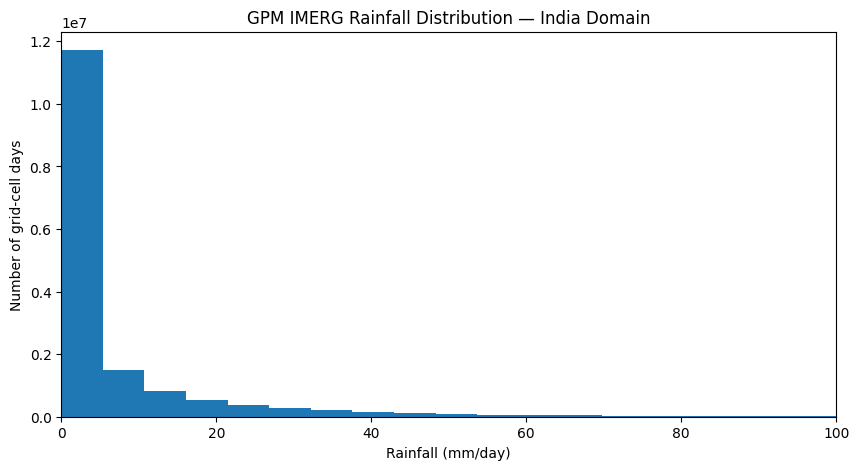

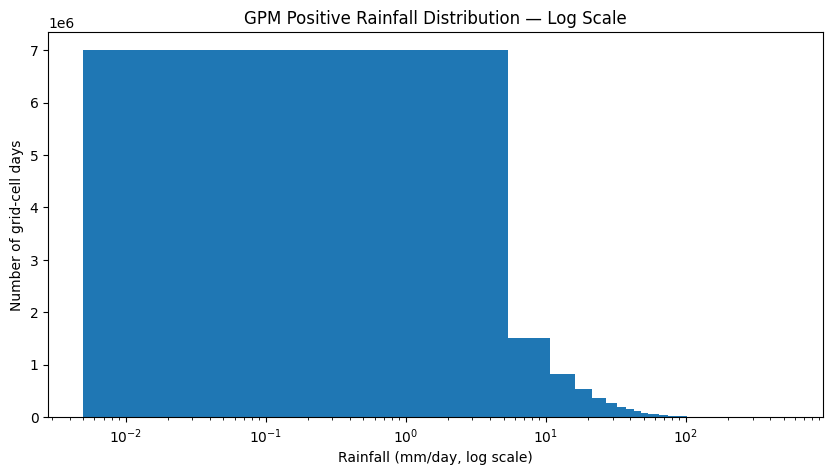

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import skew, kurtosis

print("Skewness:", skew(all_values))
print("Kurtosis:", kurtosis(all_values))

plt.figure(figsize=(10,5))
plt.hist(all_values, bins=100)
plt.xlabel("Rainfall (mm/day)")
plt.ylabel("Number of grid-cell days")
plt.title("GPM IMERG Rainfall Distribution — India Domain")
plt.xlim(0, 100)
plt.show()

plt.figure(figsize=(10,5))
plt.hist(all_values[all_values > 0], bins=100)
plt.xscale("log")
plt.xlabel("Rainfall (mm/day, log scale)")
plt.ylabel("Number of grid-cell days")
plt.title("GPM Positive Rainfall Distribution — Log Scale")
plt.show()

===== GPM EXTREME RAINFALL THRESHOLD ANALYSIS =====
Total valid grid-cell-day observations: 16,145,325

>=  25 mm/day :  1,300,159 observations (8.0529%)
>=  50 mm/day :    420,782 observations (2.6062%)
>=  75 mm/day :    163,981 observations (1.0157%)
>= 100 mm/day :     74,395 observations (0.4608%)
>= 150 mm/day :     20,353 observations (0.1261%)
>= 200 mm/day :      6,763 observations (0.0419%)


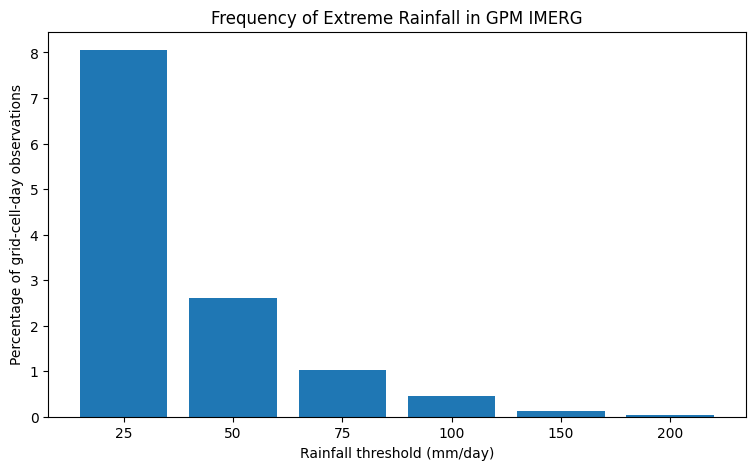

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

thresholds = [25, 50, 75, 100, 150, 200]

print("===== GPM EXTREME RAINFALL THRESHOLD ANALYSIS =====")
print(f"Total valid grid-cell-day observations: {len(all_values):,}\n")

results = []

for threshold in thresholds:
    count = np.sum(all_values >= threshold)
    percent = (count / len(all_values)) * 100

    results.append((threshold, count, percent))

    print(f">= {threshold:3} mm/day : {count:10,} observations ({percent:.4f}%)")

# Graph
plt.figure(figsize=(9,5))

plt.bar(
    [str(x[0]) for x in results],
    [x[2] for x in results]
)

plt.xlabel("Rainfall threshold (mm/day)")
plt.ylabel("Percentage of grid-cell-day observations")
plt.title("Frequency of Extreme Rainfall in GPM IMERG")
plt.show()

Processed 25/153 days
Processed 50/153 days
Processed 75/153 days
Processed 100/153 days
Processed 125/153 days
Processed 150/153 days

===== SPATIAL HOTSPOT SUMMARY =====
Grid cells: 105525
Maximum rainfall: 536.62006
Mean spatial maximum: 80.27459
Median spatial maximum: 69.65499
95th percentile: 199.10295
99th percentile: 283.46246

Frequency of >=100 mm/day:
Cells with at least one event: 30566
Maximum number of events at one cell: 18
Mean events per cell: 0.7049988154465766

Absolute maximum location:
Longitude: 90.55
Latitude: 18.850000000000012
Rainfall: 536.62006


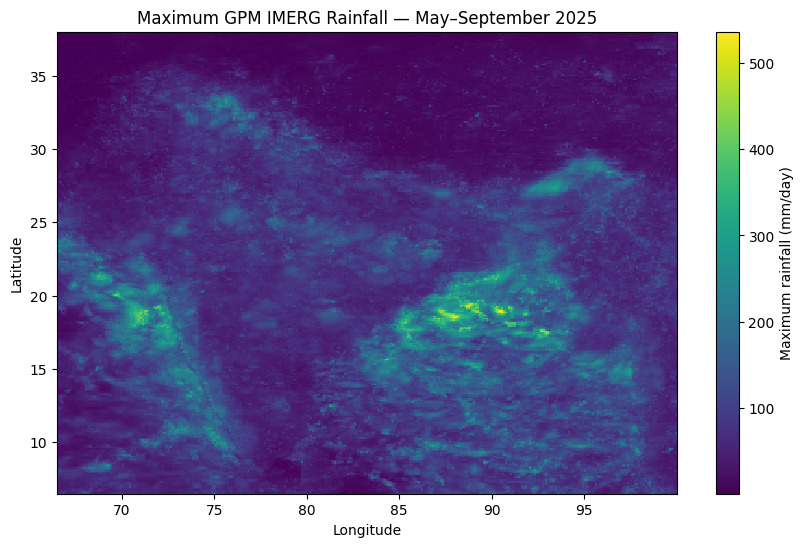

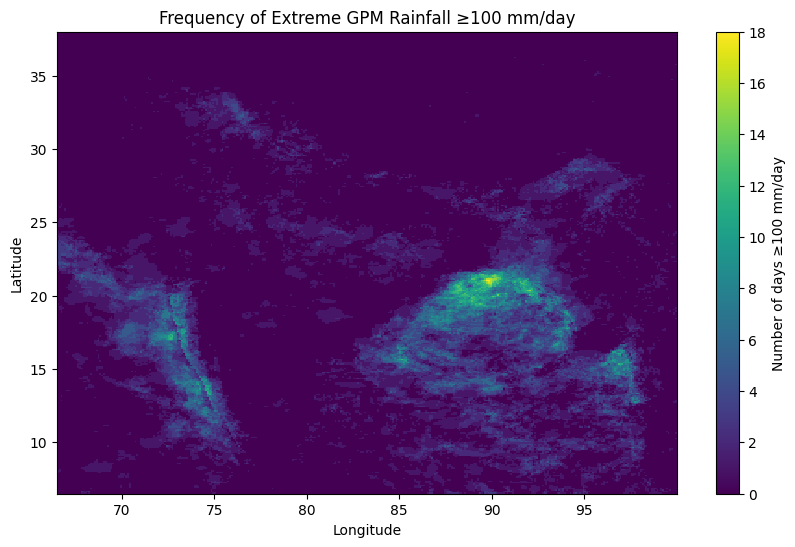

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use first file to establish the India-domain grid
ds0 = xr.open_dataset(gpm_files[0])

rain0 = ds0["precipitation"].sel(
    lon=slice(66.5, 100),
    lat=slice(6.5, 38)
).squeeze("time")

lons = rain0.lon.values
lats = rain0.lat.values

spatial_max = np.full(rain0.shape, -np.inf, dtype=np.float32)
freq_100 = np.zeros(rain0.shape, dtype=np.int16)

ds0.close()

# Process one daily file at a time
for i, f in enumerate(gpm_files):

    ds = xr.open_dataset(f)

    rain = ds["precipitation"].sel(
        lon=slice(66.5, 100),
        lat=slice(6.5, 38)
    ).squeeze("time").values

    valid = np.isfinite(rain)

    # Maximum rainfall
    spatial_max[valid] = np.maximum(
        spatial_max[valid],
        rain[valid]
    )

    # Number of days with >=100 mm/day
    freq_100 += ((rain >= 100) & valid).astype(np.int16)

    ds.close()

    if (i + 1) % 25 == 0:
        print(f"Processed {i+1}/{len(gpm_files)} days")

# Convert to xarray
spatial_max_da = xr.DataArray(
    spatial_max,
    coords={"lon": lons, "lat": lats},
    dims=["lon", "lat"],
    name="maximum_rainfall"
)

freq_100_da = xr.DataArray(
    freq_100,
    coords={"lon": lons, "lat": lats},
    dims=["lon", "lat"],
    name="frequency_100mm"
)

# Numerical summary
max_values = spatial_max[np.isfinite(spatial_max)]

print("\n===== SPATIAL HOTSPOT SUMMARY =====")
print("Grid cells:", len(max_values))
print("Maximum rainfall:", np.max(max_values))
print("Mean spatial maximum:", np.mean(max_values))
print("Median spatial maximum:", np.median(max_values))
print("95th percentile:", np.percentile(max_values, 95))
print("99th percentile:", np.percentile(max_values, 99))

print("\nFrequency of >=100 mm/day:")
print("Cells with at least one event:", np.sum(freq_100 > 0))
print("Maximum number of events at one cell:", np.max(freq_100))
print("Mean events per cell:", np.mean(freq_100))

# Location of absolute maximum
idx = np.unravel_index(np.nanargmax(spatial_max), spatial_max.shape)

print("\nAbsolute maximum location:")
print("Longitude:", lons[idx[0]])
print("Latitude:", lats[idx[1]])
print("Rainfall:", spatial_max[idx])

# Map 1: maximum rainfall
plt.figure(figsize=(10, 6))
plt.pcolormesh(
    lons,
    lats,
    spatial_max.T,
    shading="auto"
)
plt.colorbar(label="Maximum rainfall (mm/day)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Maximum GPM IMERG Rainfall — May–September 2025")
plt.show()

# Map 2: frequency >=100 mm/day
plt.figure(figsize=(10, 6))
plt.pcolormesh(
    lons,
    lats,
    freq_100.T,
    shading="auto"
)
plt.colorbar(label="Number of days ≥100 mm/day")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Frequency of Extreme GPM Rainfall ≥100 mm/day")
plt.show()

In [ ]:
regions = {
    "Uttarakhand": (77, 81, 28, 32),
    "Northeast": (88, 97, 22, 30),
    "Western Ghats": (72, 77, 8, 20),
    "Western India": (68, 75, 20, 28)
}

print("===== GPM REGIONAL EXTREME-RAINFALL COMPARISON =====\n")

regional_results = []

for name, (lon_min, lon_max, lat_min, lat_max) in regions.items():

    max_region = spatial_max_da.sel(
        lon=slice(lon_min, lon_max),
        lat=slice(lat_min, lat_max)
    ).values

    freq_region = freq_100_da.sel(
        lon=slice(lon_min, lon_max),
        lat=slice(lat_min, lat_max)
    ).values

    max_region = max_region[np.isfinite(max_region)]

    # Basic statistics
    regional_results.append({
        "Region": name,
        "Grid cells": len(max_region),
        "Mean max": np.mean(max_region),
        "Median max": np.median(max_region),
        "95th percentile max": np.percentile(max_region, 95),
        "Maximum": np.max(max_region),
        "Cells >=100 event": np.sum(freq_region > 0),
        "% cells >=100": np.mean(freq_region > 0) * 100,
        "Mean >=100 events": np.mean(freq_region),
        "Maximum event frequency": np.max(freq_region)
    })

regional_df = pd.DataFrame(regional_results)

print(regional_df.to_string(index=False))

print("\n===== REGIONAL ABSOLUTE MAXIMUM LOCATIONS =====")

for name, (lon_min, lon_max, lat_min, lat_max) in regions.items():

    region = spatial_max_da.sel(
        lon=slice(lon_min, lon_max),
        lat=slice(lat_min, lat_max)
    )

    idx = np.unravel_index(
        np.nanargmax(region.values),
        region.shape
    )

    print(
        f"{name}: "
        f"{region.values[idx]:.2f} mm/day "
        f"at "
        f"{region.lon.values[idx[0]]:.2f}°E, "
        f"{region.lat.values[idx[1]]:.2f}°N"
    )

===== GPM REGIONAL EXTREME-RAINFALL COMPARISON =====

       Region  Grid cells   Mean max  Median max  95th percentile max    Maximum  Cells >=100 event  % cells >=100  Mean >=100 events  Maximum event frequency
  Uttarakhand        1600  90.510330   88.127495           146.577728 222.014984                538      33.625000           0.429375                        4
    Northeast        7200  94.248451   88.382492           188.670975 315.929901               2844      39.500000           0.630139                        6
Western Ghats        6000 118.222450  105.347488           236.512421 379.619965               3189      53.150000           1.738667                       12
Western India        5600  88.407028   72.734985           206.583115 413.644897               1541      27.517857           0.510000                        6

===== REGIONAL ABSOLUTE MAXIMUM LOCATIONS =====
Uttarakhand: 222.01 mm/day at 79.25°E, 31.15°N
Northeast: 315.93 mm/day at 93.45°E, 27.45°N
Western Gh

In [ ]:
daily_df = pd.DataFrame(daily_stats)

daily_df["date"] = pd.to_datetime(daily_df["date"])
daily_df["month"] = daily_df["date"].dt.month
daily_df["month_name"] = daily_df["date"].dt.strftime("%b")

# Monthly summary
monthly = daily_df.groupby(["month", "month_name"]).agg(
    mean_rainfall=("mean", "mean"),
    maximum_rainfall=("max", "max"),
    mean_daily_max=("max", "mean"),
    days_ge100=("ge100", lambda x: np.sum(x > 0)),
    days_ge200=("max", lambda x: np.sum(x >= 200))
).reset_index()

print("===== GPM TEMPORAL ANALYSIS =====")
print(monthly.to_string(index=False))

print("\n===== STRONGEST DAILY EVENTS =====")

top_days = daily_df.sort_values("max", ascending=False).head(15)

print(
    top_days[
        ["date", "mean", "max", "ge100", "ge200"]
    ].to_string(index=False)
)

# Monthly maximum rainfall
plt.figure(figsize=(9,5))
plt.bar(
    monthly["month_name"],
    monthly["maximum_rainfall"]
)
plt.xlabel("Month")
plt.ylabel("Maximum rainfall (mm/day)")
plt.title("Monthly Maximum GPM Rainfall — May–September 2025")
plt.show()

# Monthly mean rainfall
plt.figure(figsize=(9,5))
plt.bar(
    monthly["month_name"],
    monthly["mean_rainfall"]
)
plt.xlabel("Month")
plt.ylabel("Mean rainfall (mm/day)")
plt.title("Monthly Mean GPM Rainfall — May–September 2025")
plt.show()

===== GPM TEMPORAL ANALYSIS =====
 month month_name  mean_rainfall  maximum_rainfall  mean_daily_max  days_ge100  days_ge200
     5        May       5.678490        404.669952      235.491119          31          17
     6        Jun       7.079373        452.410034      271.251160          30          25
     7        Jul       7.986952        536.620056      289.183533          31          27
     8        Aug       7.721083        392.349976      241.376282          31          21
     9        Sep       6.451033        329.535065      211.165680          30          14

===== STRONGEST DAILY EVENTS =====


KeyError: "['ge200'] not in index"

In [ ]:
top_days = daily_df.sort_values("max", ascending=False).head(15)

print("===== 15 STRONGEST GPM DAILY EVENTS =====")
print(
    top_days[
        ["date", "mean", "max", "ge100"]
    ].to_string(index=False)
)

===== 15 STRONGEST GPM DAILY EVENTS =====
      date      mean        max  ge100
2025-07-12  7.700466 536.620056   1325
2025-07-24 12.379124 515.264954   1690
2025-07-13  9.160100 495.454956   1089
2025-06-23  9.291511 452.410034    310
2025-07-23 13.112805 421.705017   1373
2025-06-15 13.936392 421.260010   2091
2025-06-16 11.324252 413.644897   1126
2025-07-21  8.597643 408.515015    287
2025-05-28 11.007121 404.669952   1686
2025-07-29  6.660395 401.085083    489
2025-08-19  8.782244 392.349976   1162
2025-05-25 11.641420 369.554993   1411
2025-05-29 11.486541 363.034973   1900
2025-07-25 10.490919 359.915070    700
2025-07-05  9.856041 354.274963   1053


In [ ]:
# Flatten frequency array
freq_values = freq_100_da.values

# Get top 20 grid cells
flat_indices = np.argsort(freq_values.ravel())[::-1][:20]

rows, cols = np.unravel_index(
    flat_indices,
    freq_values.shape
)

top_frequency = pd.DataFrame({
    "Rank": np.arange(1, 21),
    "Longitude": lons[rows],
    "Latitude": lats[cols],
    "Days_ge100": freq_values[rows, cols],
    "Maximum_rainfall": spatial_max[rows, cols]
})

print("===== TOP 20 RECURRING EXTREME-RAINFALL LOCATIONS =====")
print(top_frequency.to_string(index=False))

===== TOP 20 RECURRING EXTREME-RAINFALL LOCATIONS =====
 Rank  Longitude  Latitude  Days_ge100  Maximum_rainfall
    1  89.750000     21.05          18        311.149994
    2  89.849998     21.05          18        311.380066
    3  89.849998     20.95          17        281.909973
    4  89.949997     21.05          16        279.285004
    5  89.949997     20.95          16        280.795013
    6  89.750000     21.15          16        366.724976
    7  89.949997     20.85          16        260.009979
    8  89.849998     21.15          16        342.649963
    9  89.849998     20.85          16        255.454987
   10  89.949997     21.15          16        328.435028
   11  90.250000     21.15          15        401.085083
   12  90.050003     21.05          15        299.440002
   13  89.750000     20.85          15        251.534973
   14  90.050003     21.15          15        329.790009
   15  89.750000     20.95          15        271.125000
   16  92.050003     20.35      

In [ ]:
print("===== GPM vs IMD: DATASET COMPARISON SETUP =====")

print("IMD period:", str(imd_common.valid_time.values[0])[:10],
      "to", str(imd_common.valid_time.values[-1])[:10])

print("GPM period:", str(pd.to_datetime(gpm_files[0].split(".")[-4][:8]).date()),
      "to", str(pd.to_datetime(gpm_files[-1].split(".")[-4][:8]).date()))

print("\nIMD grid:")
print("Latitude:", len(imd_common.latitude))
print("Longitude:", len(imd_common.longitude))
print("Resolution: 0.25°")

print("\nGPM grid:")
print("Latitude:", len(lats))
print("Longitude:", len(lons))
print("Resolution: 0.10°")

print("\nImportant:")
print("IMD missing fraction ≈ 71.05%")
print("GPM rectangular-domain coverage is much more complete.")

print("\nWe will NOT directly compare the raw 0.25° and 0.10° grids.")
print("A common spatial scale must be defined first.")

===== GPM vs IMD: DATASET COMPARISON SETUP =====


NameError: name 'imd_common' is not defined

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd

# Find the IMD file
import glob

imd_files = glob.glob("/content/*imd*.nc") + glob.glob("/content/*IMD*.nc")

print("Possible IMD files:")
for f in imd_files:
    print(f)

# If your file is RF25_ind2025_rfp25.nc, use this:
imd = xr.open_dataset("/content/RF25_ind2025_rfp25.nc")

# Select common spatial domain and rename coordinates
imd_common = imd.sel(
    LATITUDE=slice(6.5, 38.0),
    LONGITUDE=slice(66.5, 100.0)
)

imd_common = imd_common.rename({
    "TIME": "valid_time",
    "LATITUDE": "latitude",
    "LONGITUDE": "longitude"
})

imd_common = imd_common.sortby("latitude")

print("\n===== IMD DATA RESTORED =====")
print("Period:",
      str(imd_common.valid_time.values[0])[:10],
      "to",
      str(imd_common.valid_time.values[-1])[:10])

print("Grid:",
      len(imd_common.latitude),
      "×",
      len(imd_common.longitude))

print("Resolution: 0.25°")
print("Rainfall variable:", list(imd_common.data_vars))

Possible IMD files:


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/content/RF25_ind2025_rfp25.nc', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd

# Load IMD rainfall dataset
imd = xr.open_dataset("/content/RF25_ind2025_rfp25.nc")

# Common spatial domain with GPM
imd_common = imd.sel(
    LATITUDE=slice(6.5, 38.0),
    LONGITUDE=slice(66.5, 100.0)
)

# Rename coordinates to match ERA5/GPM convention
imd_common = imd_common.rename({
    "TIME": "valid_time",
    "LATITUDE": "latitude",
    "LONGITUDE": "longitude"
})

imd_common = imd_common.sortby("latitude")

print("===== IMD DATA RESTORED =====")
print("Period:",
      str(imd_common.valid_time.values[0])[:10],
      "to",
      str(imd_common.valid_time.values[-1])[:10])

print("Grid:",
      len(imd_common.latitude),
      "×",
      len(imd_common.longitude))

print("Resolution: 0.25°")
print("Variable:", list(imd_common.data_vars))

print("\nMissing values:",
      int(imd_common["RAINFALL"].isnull().sum()))

print("Total values:",
      imd_common["RAINFALL"].size)

===== IMD DATA RESTORED =====
Period: 2025-01-01 to 2025-12-31
Grid: 127 × 135
Resolution: 0.25°
Variable: ['RAINFALL']

Missing values: 4446065
Total values: 6257925


In [ ]:
import os
import glob

gpm_files = sorted(glob.glob("/content/drive/MyDrive/GPM_2025/*"))

print("GPM files found:", len(gpm_files))

if gpm_files:
    print("First:", os.path.basename(gpm_files[0]))
    print("Last :", os.path.basename(gpm_files[-1]))

GPM files found: 153
First: 3B-DAY.MS.MRG.3IMERG.20250501-S000000-E235959.V07B.nc4
Last : 3B-DAY.MS.MRG.3IMERG.20250930-S000000-E235959.V07B.nc4


In [ ]:
import xarray as xr
import numpy as np
import pandas as pd

# IMD: May-Sep 2025
imd_cmp = imd_common["RAINFALL"].sel(
    valid_time=slice("2025-05-01", "2025-09-30")
)

# Convert IMD 0.25° grid to 0.5° using 2×2 block averages
imd_05 = imd_cmp.coarsen(
    latitude=2, longitude=2, boundary="trim"
).mean()

print("IMD common-grid shape:", imd_05.shape)

# GPM common 0.5° grid
gpm_daily = []

for f in gpm_files:
    ds = xr.open_dataset(f)

    rain = ds["precipitation"].squeeze("time")

    # India region
    rain = rain.sel(
        lon=slice(66.5, 100.0),
        lat=slice(6.5, 38.0)
    )

    # 0.5° block averaging: 5×5 original 0.1° cells
    rain_05 = rain.coarsen(
        lat=5, lon=5, boundary="trim"
    ).mean()

    date = pd.to_datetime(
        str(ds["time"].values[0])
    ).normalize()

    rain_05 = rain_05.expand_dims(
        valid_time=[date]
    )

    gpm_daily.append(rain_05)

gpm_05 = xr.concat(gpm_daily, dim="valid_time")

print("GPM common-grid shape:", gpm_05.shape)
print("GPM period:",
      gpm_05.valid_time.values[0],
      "to",
      gpm_05.valid_time.values[-1])

IMD common-grid shape: (153, 63, 67)
GPM common-grid shape: (153, 67, 63)
GPM period: 2025-05-01T00:00:00.000000000 to 2025-09-30T00:00:00.000000000


/tmp/ipykernel_678/1432650882.py:46: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  gpm_05 = xr.concat(gpm_daily, dim="valid_time")


In [ ]:
# Standardize coordinate names/order
gpm_05 = gpm_05.rename({
    "lat": "latitude",
    "lon": "longitude"
}).transpose("valid_time", "latitude", "longitude")

# Align both datasets on their common coordinates
imd_val, gpm_val = xr.align(
    imd_05,
    gpm_05,
    join="inner"
)

# Flatten valid paired observations
imd_arr = imd_val.values.flatten()
gpm_arr = gpm_val.values.flatten()

valid = np.isfinite(imd_arr) & np.isfinite(gpm_arr)

imd_arr = imd_arr[valid]
gpm_arr = gpm_arr[valid]

print("===== GPM vs IMD VALIDATION =====")
print("Paired observations:", len(imd_arr))

# Basic statistics
print("\nIMD mean:", round(imd_arr.mean(), 3))
print("GPM mean:", round(gpm_arr.mean(), 3))

print("IMD median:", round(np.median(imd_arr), 3))
print("GPM median:", round(np.median(gpm_arr), 3))

print("IMD max:", round(imd_arr.max(), 3))
print("GPM max:", round(gpm_arr.max(), 3))

# Pearson correlation
corr = np.corrcoef(imd_arr, gpm_arr)[0, 1]

print("\nPearson correlation:", round(corr, 4))

# Bias
bias = gpm_arr - imd_arr

print("Mean Bias (GPM - IMD):", round(bias.mean(), 3))
print("MAE:", round(np.mean(np.abs(bias)), 3))
print("RMSE:", round(np.sqrt(np.mean(bias**2)), 3))

# Rain/no-rain agreement
imd_rain = imd_arr > 0
gpm_rain = gpm_arr > 0

agreement = np.mean(imd_rain == gpm_rain)

print("\nRain/no-rain agreement:", round(agreement * 100, 2), "%")

# Extreme rainfall agreement
threshold = 50

imd_extreme = imd_arr >= threshold
gpm_extreme = gpm_arr >= threshold

extreme_agreement = np.mean(imd_extreme == gpm_extreme)

print(f"\nAgreement for >= {threshold} mm/day:",
      round(extreme_agreement * 100, 2), "%")

print("IMD >= 50:", int(imd_extreme.sum()))
print("GPM >= 50:", int(gpm_extreme.sum()))

===== GPM vs IMD VALIDATION =====
Paired observations: 0

IMD mean: nan
GPM mean: nan
IMD median: nan
GPM median: nan


/tmp/ipykernel_678/4078588044.py:27: RuntimeWarning: Mean of empty slice.
  print("\nIMD mean:", round(imd_arr.mean(), 3))
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipykernel_678/4078588044.py:28: RuntimeWarning: Mean of empty slice.
  print("GPM mean:", round(gpm_arr.mean(), 3))
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,


ValueError: zero-size array to reduction operation maximum which has no identity

In [ ]:
# Put both datasets onto the SAME coordinate grid
# Use IMD's 0.5° grid as the reference

# Interpolate GPM onto IMD coordinates
gpm_on_imd = gpm_05.interp(
    latitude=imd_05.latitude,
    longitude=imd_05.longitude,
    method="linear"
)

# Check alignment
print("IMD shape:", imd_05.shape)
print("GPM on IMD grid:", gpm_on_imd.shape)

print("\nLatitude coordinates match:",
      np.allclose(imd_05.latitude, gpm_on_imd.latitude))

print("Longitude coordinates match:",
      np.allclose(imd_05.longitude, gpm_on_imd.longitude))

# Find paired valid observations
imd_arr = imd_05.values.flatten()
gpm_arr = gpm_on_imd.values.flatten()

valid = np.isfinite(imd_arr) & np.isfinite(gpm_arr)

print("\nPaired valid observations:", int(valid.sum()))
print("Total possible observations:", len(imd_arr))

IMD shape: (153, 63, 67)
GPM on IMD grid: (153, 63, 67)

Latitude coordinates match: True
Longitude coordinates match: True

Paired valid observations: 204408
Total possible observations: 645813


In [ ]:
# Extract only paired valid observations
imd_arr = imd_05.values.flatten()
gpm_arr = gpm_on_imd.values.flatten()

valid = np.isfinite(imd_arr) & np.isfinite(gpm_arr)

imd_arr = imd_arr[valid]
gpm_arr = gpm_arr[valid]

# Basic statistics
print("===== GPM vs IMD VALIDATION =====")
print("Paired observations:", len(imd_arr))

print("\n--- Rainfall statistics ---")
print("IMD mean:", round(imd_arr.mean(), 3))
print("GPM mean:", round(gpm_arr.mean(), 3))

print("IMD median:", round(np.median(imd_arr), 3))
print("GPM median:", round(np.median(gpm_arr), 3))

print("IMD maximum:", round(imd_arr.max(), 3))
print("GPM maximum:", round(gpm_arr.max(), 3))

# Pearson correlation
pearson = np.corrcoef(imd_arr, gpm_arr)[0, 1]

# Spearman correlation
from scipy.stats import spearmanr
spearman = spearmanr(imd_arr, gpm_arr).statistic

# Errors
bias = gpm_arr - imd_arr
mae = np.mean(np.abs(bias))
rmse = np.sqrt(np.mean(bias**2))

print("\n--- Agreement ---")
print("Pearson correlation:", round(pearson, 4))
print("Spearman correlation:", round(spearman, 4))

print("\n--- Error metrics ---")
print("Mean Bias (GPM - IMD):", round(bias.mean(), 3))
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))

# Rain/no-rain agreement
imd_rain = imd_arr > 0
gpm_rain = gpm_arr > 0

rain_agreement = np.mean(imd_rain == gpm_rain)

print("\n--- Rain detection ---")
print("IMD rainy observations:", int(imd_rain.sum()))
print("GPM rainy observations:", int(gpm_rain.sum()))
print("Rain/no-rain agreement:", round(rain_agreement * 100, 2), "%")

# Extreme rainfall agreement
for threshold in [25, 50, 100]:
    imd_extreme = imd_arr >= threshold
    gpm_extreme = gpm_arr >= threshold

    print(f"\n--- >= {threshold} mm/day ---")
    print("IMD:", int(imd_extreme.sum()))
    print("GPM:", int(gpm_extreme.sum()))
    print(
        "Agreement:",
        round(np.mean(imd_extreme == gpm_extreme) * 100, 2),
        "%"
    )

===== GPM vs IMD VALIDATION =====
Paired observations: 204408

--- Rainfall statistics ---
IMD mean: 6.996
GPM mean: 7.683
IMD median: 1.047
GPM median: 2.447
IMD maximum: 385.967
GPM maximum: 229.705

--- Agreement ---
Pearson correlation: 0.4138
Spearman correlation: 0.5238

--- Error metrics ---
Mean Bias (GPM - IMD): 0.687
MAE: 7.675
RMSE: 14.942

--- Rain detection ---
IMD rainy observations: 134209
GPM rainy observations: 192272
Rain/no-rain agreement: 69.93 %

--- >= 25 mm/day ---
IMD: 15574
GPM: 16667
Agreement: 89.24 %

--- >= 50 mm/day ---
IMD: 4510
GPM: 3620
Agreement: 96.92 %

--- >= 100 mm/day ---
IMD: 687
GPM: 332
Agreement: 99.53 %


===== SPATIAL BIAS =====
Mean bias: 0.687 mm/day
Minimum bias: -22.941 mm/day
Maximum bias: 10.089 mm/day
Median bias: 0.864 mm/day


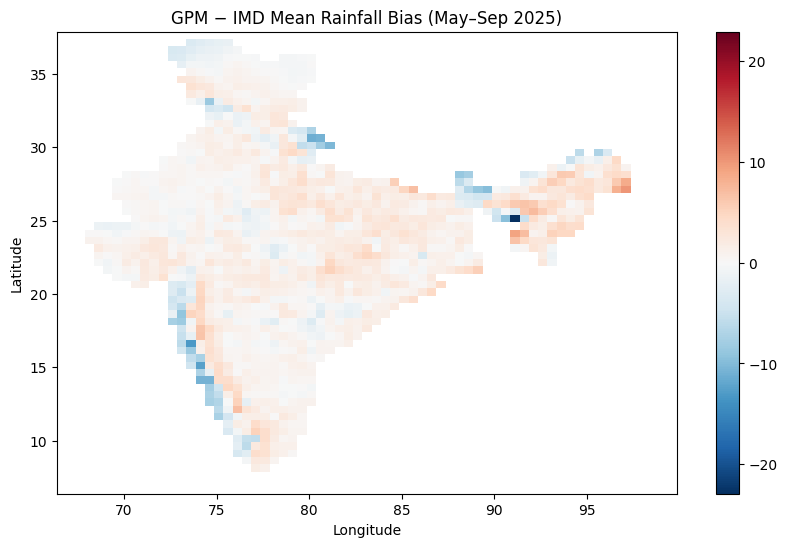

In [ ]:
# Mean rainfall difference: GPM - IMD
mean_bias_map = (gpm_on_imd - imd_05).mean(dim="valid_time")

print("===== SPATIAL BIAS =====")
print("Mean bias:", round(float(mean_bias_map.mean(skipna=True)), 3), "mm/day")
print("Minimum bias:", round(float(mean_bias_map.min(skipna=True)), 3), "mm/day")
print("Maximum bias:", round(float(mean_bias_map.max(skipna=True)), 3), "mm/day")
print("Median bias:", round(float(mean_bias_map.median(skipna=True)), 3), "mm/day")

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

mean_bias_map.plot(
    cmap="RdBu_r",
    center=0
)

plt.title("GPM − IMD Mean Rainfall Bias (May–Sep 2025)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [ ]:
regions = {
    "Uttarakhand": (77, 81, 28, 32),
    "Northeast": (88, 97, 22, 30),
    "Western Ghats": (72, 77, 8, 20),
    "Western India": (68, 75, 20, 28)
}

print("===== REGIONAL GPM vs IMD VALIDATION =====\n")

for name, (lon1, lon2, lat1, lat2) in regions.items():

    imd_r = imd_05.sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    gpm_r = gpm_on_imd.sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    a = imd_r.values.flatten()
    b = gpm_r.values.flatten()

    valid = np.isfinite(a) & np.isfinite(b)

    a = a[valid]
    b = b[valid]

    if len(a) == 0:
        print(name, ": No valid data")
        continue

    corr = np.corrcoef(a, b)[0, 1]
    bias = np.mean(b - a)
    mae = np.mean(np.abs(b - a))
    rmse = np.sqrt(np.mean((b - a)**2))

    print(name)
    print("  Valid observations:", len(a))
    print("  IMD mean:", round(a.mean(), 2))
    print("  GPM mean:", round(b.mean(), 2))
    print("  Pearson r:", round(corr, 3))
    print("  Bias:", round(bias, 2))
    print("  MAE:", round(mae, 2))
    print("  RMSE:", round(rmse, 2))
    print()

===== REGIONAL GPM vs IMD VALIDATION =====

Uttarakhand
  Valid observations: 8874
  IMD mean: 8.04
  GPM mean: 7.85
  Pearson r: 0.391
  Bias: -0.2
  MAE: 8.2
  RMSE: 14.57

Northeast
  Valid observations: 24327
  IMD mean: 10.61
  GPM mean: 11.71
  Pearson r: 0.328
  Bias: 1.11
  MAE: 11.15
  RMSE: 19.18

Western Ghats
  Valid observations: 19890
  IMD mean: 12.05
  GPM mean: 11.43
  Pearson r: 0.516
  Bias: -0.62
  MAE: 10.74
  RMSE: 19.62

Western India
  Valid observations: 27081
  IMD mean: 5.39
  GPM mean: 5.86
  Pearson r: 0.349
  Bias: 0.47
  MAE: 6.63
  RMSE: 15.14



In [ ]:
# ===== IMD EXTREME-RAINFALL HOTSPOTS =====

rain = imd_cmp

# Maximum rainfall observed at each grid cell
imd_max = rain.max(dim="valid_time", skipna=True)

# Number of days with >=100 mm/day at each grid cell
imd_freq100 = (rain >= 100).sum(dim="valid_time")

print("===== IMD HOTSPOT ANALYSIS =====")

print("\nMaximum rainfall:")
print("Overall maximum:", round(float(imd_max.max()), 2), "mm/day")
print("Mean spatial maximum:", round(float(imd_max.mean(skipna=True)), 2))
print("Median spatial maximum:", round(float(imd_max.median(skipna=True)), 2))

print("\nCells with >=100 mm/day at least once:",
      int((imd_freq100 >= 1).sum()))

print("Maximum number of >=100 mm/day days at one cell:",
      int(imd_freq100.max()))

# Top 15 locations by maximum rainfall
top_max = imd_max.stack(location=("latitude", "longitude")).dropna()
top_max = top_max.sortby(top_max, ascending=False).head(15)

print("\n===== TOP 15 LOCATIONS BY MAXIMUM RAINFALL =====")

for i, (loc, value) in enumerate(
    zip(top_max.location.values, top_max.values), 1
):
    lat, lon = loc
    print(
        f"{i:2d}. Lat {float(lat):.2f}, "
        f"Lon {float(lon):.2f} → "
        f"{float(value):.2f} mm/day"
    )

# Top 15 locations by frequency
top_freq = imd_freq100.stack(
    location=("latitude", "longitude")
).dropna()

top_freq = top_freq.sortby(top_freq, ascending=False).head(15)

print("\n===== TOP 15 LOCATIONS BY FREQUENCY (>=100 mm/day) =====")

for i, (loc, value) in enumerate(
    zip(top_freq.location.values, top_freq.values), 1
):
    lat, lon = loc
    print(
        f"{i:2d}. Lat {float(lat):.2f}, "
        f"Lon {float(lon):.2f} → "
        f"{int(value)} extreme days"
    )

===== IMD HOTSPOT ANALYSIS =====

Maximum rainfall:
Overall maximum: 469.21 mm/day
Mean spatial maximum: 89.26
Median spatial maximum: 80.0

Cells with >=100 mm/day at least once: 1594
Maximum number of >=100 mm/day days at one cell: 16


TypeError: DataArray.dropna() missing 1 required positional argument: 'dim'

In [ ]:
# ===== TOP IMD EXTREME-RAINFALL LOCATIONS =====

# Top locations by maximum rainfall
top_max = imd_max.stack(
    location=("latitude", "longitude")
).dropna(dim="location")

top_max = top_max.sortby(top_max, ascending=False).head(15)

print("===== TOP 15 LOCATIONS BY MAXIMUM RAINFALL =====")

for i, (loc, value) in enumerate(
    zip(top_max.location.values, top_max.values), 1
):
    lat, lon = loc
    print(
        f"{i:2d}. Lat {float(lat):.2f}, "
        f"Lon {float(lon):.2f} → "
        f"{float(value):.2f} mm/day"
    )


# Top locations by frequency
top_freq = imd_freq100.stack(
    location=("latitude", "longitude")
).dropna(dim="location")

top_freq = top_freq.sortby(top_freq, ascending=False).head(15)

print("\n===== TOP 15 LOCATIONS BY FREQUENCY (>=100 mm/day) =====")

for i, (loc, value) in enumerate(
    zip(top_freq.location.values, top_freq.values), 1
):
    lat, lon = loc
    print(
        f"{i:2d}. Lat {float(lat):.2f}, "
        f"Lon {float(lon):.2f} → "
        f"{int(value)} extreme days"
    )

===== TOP 15 LOCATIONS BY MAXIMUM RAINFALL =====
 1. Lat 25.75, Lon 75.75 → 469.21 mm/day
 2. Lat 25.25, Lon 91.25 → 395.56 mm/day
 3. Lat 24.25, Lon 71.25 → 376.83 mm/day
 4. Lat 25.25, Lon 91.00 → 376.38 mm/day
 5. Lat 25.50, Lon 90.75 → 374.68 mm/day
 6. Lat 25.25, Lon 90.75 → 370.48 mm/day
 7. Lat 25.50, Lon 91.00 → 369.50 mm/day
 8. Lat 18.75, Lon 73.25 → 367.73 mm/day
 9. Lat 25.00, Lon 92.25 → 367.29 mm/day
10. Lat 22.00, Lon 71.50 → 352.22 mm/day
11. Lat 24.00, Lon 71.25 → 345.93 mm/day
12. Lat 23.50, Lon 70.50 → 339.87 mm/day
13. Lat 18.25, Lon 72.75 → 324.74 mm/day
14. Lat 24.25, Lon 70.50 → 323.39 mm/day
15. Lat 25.00, Lon 92.50 → 318.99 mm/day

===== TOP 15 LOCATIONS BY FREQUENCY (>=100 mm/day) =====
 1. Lat 25.25, Lon 91.25 → 16 extreme days
 2. Lat 10.25, Lon 77.00 → 16 extreme days
 3. Lat 25.25, Lon 91.00 → 15 extreme days
 4. Lat 18.00, Lon 73.50 → 15 extreme days
 5. Lat 14.25, Lon 74.50 → 15 extreme days
 6. Lat 25.25, Lon 91.50 → 14 extreme days
 7. Lat 18.00, Lon 7

In [ ]:
# ===== UTTARAKHAND EXTREME-RAINFALL PROFILE =====

uk = imd_cmp.sel(
    latitude=slice(28, 32),
    longitude=slice(77, 81)
)

uk_max = uk.max(dim="valid_time", skipna=True)
uk_freq100 = (uk >= 100).sum(dim="valid_time")

print("===== UTTARAKHAND =====")

print("Grid cells:", uk_max.size)

print("\nMaximum intensity:")
print("Maximum:", round(float(uk_max.max()), 2), "mm/day")
print("Mean spatial maximum:", round(float(uk_max.mean(skipna=True)), 2))
print("Median spatial maximum:", round(float(uk_max.median(skipna=True)), 2))

print("\n>=100 mm/day frequency:")
print("Cells with at least one event:",
      int((uk_freq100 >= 1).sum()))

print("Maximum frequency at one cell:",
      int(uk_freq100.max()))

print("Mean frequency:",
      round(float(uk_freq100.mean()), 3))

# Location of maximum
max_idx = np.unravel_index(
    np.nanargmax(uk_max.values),
    uk_max.shape
)

print("\nMaximum rainfall location:")
print("Latitude:", float(uk_max.latitude.values[max_idx[0]]))
print("Longitude:", float(uk_max.longitude.values[max_idx[1]]))

# Location of highest frequency
freq_idx = np.unravel_index(
    np.argmax(uk_freq100.values),
    uk_freq100.shape
)

print("\nMost recurrent location:")
print("Latitude:", float(uk_freq100.latitude.values[freq_idx[0]]))
print("Longitude:", float(uk_freq100.longitude.values[freq_idx[1]]))
print("Extreme days:", int(uk_freq100.values[freq_idx]))

===== UTTARAKHAND =====
Grid cells: 289

Maximum intensity:
Maximum: 235.38 mm/day
Mean spatial maximum: 86.75
Median spatial maximum: 80.89

>=100 mm/day frequency:
Cells with at least one event: 70
Maximum frequency at one cell: 8
Mean frequency: 0.415

Maximum rainfall location:
Latitude: 30.0
Longitude: 78.0

Most recurrent location:
Latitude: 30.0
Longitude: 79.75
Extreme days: 8


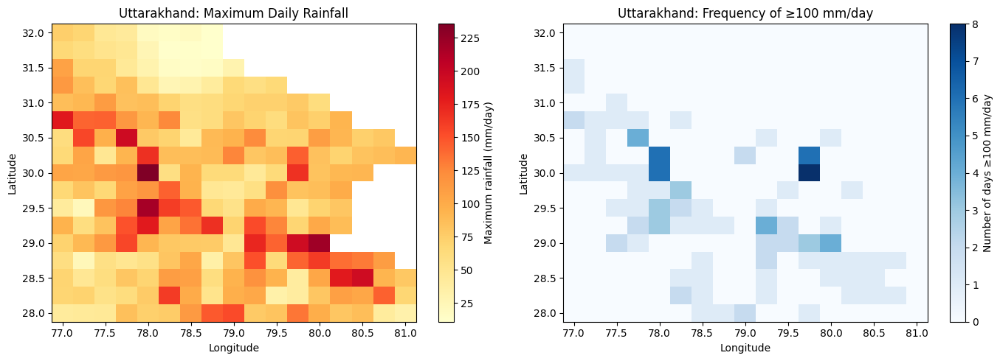

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Uttarakhand rainfall data
uk = imd_cmp.sel(
    latitude=slice(28, 32),
    longitude=slice(77, 81)
)

# Maximum rainfall at each grid cell
uk_max = uk.max(dim="valid_time", skipna=True)

# Number of days with rainfall >= 100 mm/day
uk_freq100 = (uk >= 100).sum(dim="valid_time")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Map 1: maximum intensity
uk_max.plot(
    ax=axes[0],
    cmap="YlOrRd",
    cbar_kwargs={"label": "Maximum rainfall (mm/day)"}
)
axes[0].set_title("Uttarakhand: Maximum Daily Rainfall")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

# Map 2: extreme-event frequency
uk_freq100.plot(
    ax=axes[1],
    cmap="Blues",
    cbar_kwargs={"label": "Number of days ≥100 mm/day"}
)
axes[1].set_title("Uttarakhand: Frequency of ≥100 mm/day")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd

era5_raw = xr.open_dataset("/content/era5 2025.nc")

print(era5_raw)
print("\nVariables:")
print(list(era5_raw.data_vars))

print("\nTime range:")
print(era5_raw.valid_time.min().values, "to", era5_raw.valid_time.max().values)

print("\nGrid:")
print("Latitude:", len(era5_raw.latitude))
print("Longitude:", len(era5_raw.longitude))

<xarray.Dataset> Size: 1GB
Dimensions:     (valid_time: 3672, latitude: 127, longitude: 135)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 29kB 2025-05-01 ... 2025-09-30T23...
  * latitude    (latitude) float64 1kB 38.0 37.75 37.5 37.25 ... 7.0 6.75 6.5
  * longitude   (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
    number      int64 8B ...
    expver      (valid_time) <U4 59kB ...
Data variables:
    u10         (valid_time, latitude, longitude) float32 252MB ...
    v10         (valid_time, latitude, longitude) float32 252MB ...
    t2m         (valid_time, latitude, longitude) float32 252MB ...
    sp          (valid_time, latitude, longitude) float32 252MB ...
    tcwv        (valid_time, latitude, longitude) float32 252MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European 

In [ ]:
# Prepare ERA5 variables in research-friendly units

era5 = xr.Dataset({
    "temperature": era5_raw["t2m"] - 273.15,   # Kelvin → °C
    "pressure": era5_raw["sp"] / 100,           # Pa → hPa
    "wind_speed": np.sqrt(
        era5_raw["u10"]**2 + era5_raw["v10"]**2
    ),                                           # m/s
    "tcwv": era5_raw["tcwv"]                    # kg/m²
})

# Make latitude ascending so it matches IMD
era5 = era5.sortby("latitude")

print(era5)

<xarray.Dataset> Size: 1GB
Dimensions:      (valid_time: 3672, latitude: 127, longitude: 135)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 29kB 2025-05-01 ... 2025-09-30T2...
  * latitude     (latitude) float64 1kB 6.5 6.75 7.0 7.25 ... 37.5 37.75 38.0
  * longitude    (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
    number       int64 8B 0
    expver       (valid_time) <U4 59kB '0001' '0001' '0001' ... '0001' '0001'
Data variables:
    temperature  (valid_time, latitude, longitude) float32 252MB 28.15 ... -2...
    pressure     (valid_time, latitude, longitude) float32 252MB 1.008e+03 .....
    wind_speed   (valid_time, latitude, longitude) float32 252MB 1.765 ... 1.327
    tcwv         (valid_time, latitude, longitude) float32 252MB ...


In [ ]:
# Convert hourly ERA5 variables to daily averages

era5_daily = xr.Dataset()

for var in ["temperature", "pressure", "wind_speed", "tcwv"]:
    era5_daily[var] = (
        era5[var]
        .resample(valid_time="1D")
        .mean()
        .load()
    )

print(era5_daily)

print("\nDaily time range:")
print(
    era5_daily.valid_time.min().values,
    "to",
    era5_daily.valid_time.max().values
)

print("\nNumber of daily records:", len(era5_daily.valid_time))

<xarray.Dataset> Size: 42MB
Dimensions:      (latitude: 127, longitude: 135, valid_time: 153)
Coordinates:
  * latitude     (latitude) float64 1kB 6.5 6.75 7.0 7.25 ... 37.5 37.75 38.0
  * longitude    (longitude) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
  * valid_time   (valid_time) datetime64[ns] 1kB 2025-05-01 ... 2025-09-30
    number       int64 8B 0
Data variables:
    temperature  (valid_time, latitude, longitude) float32 10MB 28.74 ... 1.776
    pressure     (valid_time, latitude, longitude) float32 10MB 1.009e+03 ......
    wind_speed   (valid_time, latitude, longitude) float32 10MB 2.687 ... 1.464
    tcwv         (valid_time, latitude, longitude) float32 10MB 54.86 ... 6.882

Daily time range:
2025-05-01T00:00:00.000000000 to 2025-09-30T00:00:00.000000000

Number of daily records: 153


In [ ]:
era5_uk = era5.sel(
    latitude=slice(28, 32),
    longitude=slice(77, 81)
)

print(era5_uk)
print("\nGrid:", len(era5_uk.latitude), "×", len(era5_uk.longitude))
print("Days:", len(era5_uk.valid_time))

<xarray.Dataset> Size: 17MB
Dimensions:      (valid_time: 3672, latitude: 17, longitude: 17)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 29kB 2025-05-01 ... 2025-09-30T2...
  * latitude     (latitude) float64 136B 28.0 28.25 28.5 ... 31.5 31.75 32.0
  * longitude    (longitude) float64 136B 77.0 77.25 77.5 ... 80.5 80.75 81.0
    number       int64 8B 0
    expver       (valid_time) <U4 59kB '0001' '0001' '0001' ... '0001' '0001'
Data variables:
    temperature  (valid_time, latitude, longitude) float32 4MB 27.79 ... -4.161
    pressure     (valid_time, latitude, longitude) float32 4MB 980.4 ... 560.0
    wind_speed   (valid_time, latitude, longitude) float32 4MB 2.869 ... 2.132
    tcwv         (valid_time, latitude, longitude) float32 4MB ...

Grid: 17 × 17
Days: 3672


In [ ]:
# Convert only Uttarakhand ERA5 to daily averages

era5_uk_daily = (
    era5_uk
    .resample(valid_time="1D")
    .mean()
)

print(era5_uk_daily)

print("\nTime range:")
print(
    era5_uk_daily.valid_time.min().values,
    "to",
    era5_uk_daily.valid_time.max().values
)

print("\nGrid:",
      len(era5_uk_daily.latitude),
      "×",
      len(era5_uk_daily.longitude))

print("Days:", len(era5_uk_daily.valid_time))

<xarray.Dataset> Size: 709kB
Dimensions:      (valid_time: 153, latitude: 17, longitude: 17)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 1kB 2025-05-01 ... 2025-09-30
  * latitude     (latitude) float64 136B 28.0 28.25 28.5 ... 31.5 31.75 32.0
  * longitude    (longitude) float64 136B 77.0 77.25 77.5 ... 80.5 80.75 81.0
    number       int64 8B 0
Data variables:
    temperature  (valid_time, latitude, longitude) float32 177kB 32.23 ... 2.481
    pressure     (valid_time, latitude, longitude) float32 177kB 980.0 ... 560.4
    wind_speed   (valid_time, latitude, longitude) float32 177kB 3.726 ... 3.041
    tcwv         (valid_time, latitude, longitude) float32 177kB 30.1 ... 2.732

Time range:
2025-05-01T00:00:00.000000000 to 2025-09-30T00:00:00.000000000

Grid: 17 × 17
Days: 153


In [ ]:
# Match IMD rainfall to the Uttarakhand study box
imd_uk = imd_cmp.sel(
    latitude=slice(28, 32),
    longitude=slice(77, 81)
)

# Daily spatial averages
uk_rain_daily = imd_uk.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

uk_era5_daily = era5_uk_daily.mean(
    dim=["latitude", "longitude"]
)

# Combine rainfall + ERA5
uk_combined = xr.Dataset({
    "rainfall": uk_rain_daily,
    "temperature": uk_era5_daily["temperature"],
    "pressure": uk_era5_daily["pressure"],
    "wind_speed": uk_era5_daily["wind_speed"],
    "tcwv": uk_era5_daily["tcwv"]
})

print(uk_combined)

<xarray.Dataset> Size: 4kB
Dimensions:      (valid_time: 153)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 1kB 2025-05-01 ... 2025-09-30
    number       int64 8B 0
Data variables:
    rainfall     (valid_time) float32 612B 0.01914 4.761 4.249 ... 2.309 2.056
    temperature  (valid_time) float32 612B 17.27 15.12 16.81 ... 20.3 19.91 17.5
    pressure     (valid_time) float32 612B 815.7 815.3 812.7 ... 813.5 812.3
    wind_speed   (valid_time) float32 612B 2.329 1.73 1.728 ... 1.394 1.303
    tcwv         (valid_time) float32 612B 21.92 24.43 22.71 ... 28.98 29.36


In [ ]:
# Identify extreme-rainfall days and compare ERA5 conditions

extreme = uk_combined["rainfall"] >= 100
normal = uk_combined["rainfall"] < 100

print("Total days:", int(uk_combined.valid_time.size))
print("Extreme days (>=100 mm/day):", int(extreme.sum()))
print("Normal days:", int(normal.sum()))

print("\n--- NORMAL DAYS ---")
for var in ["rainfall", "temperature", "pressure", "wind_speed", "tcwv"]:
    print(f"{var:12s}: {float(uk_combined[var].where(normal).mean()):.3f}")

print("\n--- EXTREME DAYS ---")
for var in ["rainfall", "temperature", "pressure", "wind_speed", "tcwv"]:
    print(f"{var:12s}: {float(uk_combined[var].where(extreme).mean()):.3f}")

print("\n--- EXTREME - NORMAL DIFFERENCE ---")
for var in ["temperature", "pressure", "wind_speed", "tcwv"]:
    normal_mean = float(uk_combined[var].where(normal).mean())
    extreme_mean = float(uk_combined[var].where(extreme).mean())
    print(f"{var:12s}: {extreme_mean - normal_mean:+.3f}")

Total days: 153
Extreme days (>=100 mm/day): 0
Normal days: 153

--- NORMAL DAYS ---
rainfall    : 7.792
temperature : 20.115
pressure    : 811.510
wind_speed  : 1.660
tcwv        : 35.800

--- EXTREME DAYS ---
rainfall    : nan
temperature : nan
pressure    : nan
wind_speed  : nan
tcwv        : nan

--- EXTREME - NORMAL DIFFERENCE ---
temperature : +nan
pressure    : +nan
wind_speed  : +nan
tcwv        : +nan


In [ ]:
# Percentile-based extreme rainfall threshold for Uttarakhand study box

rain = uk_combined["rainfall"]

# Calculate 95th percentile
threshold_95 = float(rain.quantile(0.95))

extreme_95 = rain >= threshold_95
normal_95 = rain < threshold_95

print(f"95th percentile rainfall threshold: {threshold_95:.3f} mm/day")
print(f"Extreme days (>=95th percentile): {int(extreme_95.sum())}")
print(f"Normal days: {int(normal_95.sum())}")

print("\nExtreme rainfall days:")
print(uk_combined.valid_time.where(extreme_95, drop=True).values)

print("\nExtreme rainfall values:")
print(
    uk_combined["rainfall"]
    .where(extreme_95, drop=True)
    .values
)

95th percentile rainfall threshold: 26.082 mm/day
Extreme days (>=95th percentile): 8
Normal days: 145

Extreme rainfall days:
['2025-06-30T00:00:00.000000000' '2025-08-04T00:00:00.000000000'
 '2025-08-05T00:00:00.000000000' '2025-08-06T00:00:00.000000000'
 '2025-08-14T00:00:00.000000000' '2025-08-29T00:00:00.000000000'
 '2025-09-01T00:00:00.000000000' '2025-09-02T00:00:00.000000000']

Extreme rainfall values:
[32.362938 32.2753   29.234205 43.116684 27.446857 29.030037 35.406414
 35.387993]


In [ ]:
# Compare ERA5 atmospheric conditions on extreme vs normal rainfall days

variables = ["temperature", "pressure", "wind_speed", "tcwv"]

print("===== EXTREME vs NORMAL DAYS =====")

for var in variables:
    extreme_mean = float(
        uk_combined[var].where(extreme_95).mean()
    )

    normal_mean = float(
        uk_combined[var].where(normal_95).mean()
    )

    difference = extreme_mean - normal_mean

    print(
        f"{var:12s} | "
        f"Normal: {normal_mean:8.3f} | "
        f"Extreme: {extreme_mean:8.3f} | "
        f"Difference: {difference:+8.3f}"
    )

===== EXTREME vs NORMAL DAYS =====
temperature  | Normal:   20.197 | Extreme:   18.628 | Difference:   -1.569
pressure     | Normal:  811.495 | Extreme:  811.777 | Difference:   +0.282
wind_speed   | Normal:    1.661 | Extreme:    1.636 | Difference:   -0.025
tcwv         | Normal:   35.357 | Extreme:   43.814 | Difference:   +8.457


In [ ]:
# Check how many valid IMD grid cells contribute to each daily
# Uttarakhand study-box rainfall average

valid_cells_daily = imd_uk.notnull().sum(
    dim=["latitude", "longitude"]
)

total_cells = imd_uk.sizes["latitude"] * imd_uk.sizes["longitude"]

coverage_percent = (valid_cells_daily / total_cells) * 100

print("Total grid cells in study box:", total_cells)

print("\nCoverage statistics:")
print(f"Mean valid cells: {float(valid_cells_daily.mean()):.1f}")
print(f"Minimum valid cells: {int(valid_cells_daily.min())}")
print(f"Maximum valid cells: {int(valid_cells_daily.max())}")
print(f"Mean coverage: {float(coverage_percent.mean()):.2f}%")
print(f"Minimum coverage: {float(coverage_percent.min()):.2f}%")

print("\nCoverage on 8 extreme-rainfall days:")
for date in uk_combined.valid_time.where(extreme_95, drop=True).values:
    cov = float(coverage_percent.sel(valid_time=date))
    cells = int(valid_cells_daily.sel(valid_time=date))
    print(
        pd.Timestamp(date).strftime("%Y-%m-%d"),
        f"| valid cells: {cells}/{total_cells}",
        f"| coverage: {cov:.2f}%"
    )

Total grid cells in study box: 289

Coverage statistics:
Mean valid cells: 233.0
Minimum valid cells: 233
Maximum valid cells: 233
Mean coverage: 80.62%
Minimum coverage: 80.62%

Coverage on 8 extreme-rainfall days:
2025-06-30 | valid cells: 233/289 | coverage: 80.62%
2025-08-04 | valid cells: 233/289 | coverage: 80.62%
2025-08-05 | valid cells: 233/289 | coverage: 80.62%
2025-08-06 | valid cells: 233/289 | coverage: 80.62%
2025-08-14 | valid cells: 233/289 | coverage: 80.62%
2025-08-29 | valid cells: 233/289 | coverage: 80.62%
2025-09-01 | valid cells: 233/289 | coverage: 80.62%
2025-09-02 | valid cells: 233/289 | coverage: 80.62%


In [ ]:
# Maximum rainfall location on each 95th-percentile extreme day

print("===== EXTREME-DAY MAXIMUM RAINFALL =====")

for date in uk_combined.valid_time.where(extreme_95, drop=True).values:
    day = imd_uk.sel(valid_time=date)

    max_value = float(day.max(skipna=True))
    max_location = day.where(day == max_value, drop=True).squeeze()

    lat = float(max_location.latitude)
    lon = float(max_location.longitude)

    print(
        pd.Timestamp(date).strftime("%Y-%m-%d"),
        f"| Max rainfall: {max_value:.2f} mm/day",
        f"| Location: ({lat:.2f}, {lon:.2f})"
    )

===== EXTREME-DAY MAXIMUM RAINFALL =====
2025-06-30 | Max rainfall: 160.80 mm/day | Location: (28.25, 78.25)
2025-08-04 | Max rainfall: 153.75 mm/day | Location: (28.00, 79.00)
2025-08-05 | Max rainfall: 235.38 mm/day | Location: (30.00, 78.00)
2025-08-06 | Max rainfall: 201.01 mm/day | Location: (30.00, 78.00)
2025-08-14 | Max rainfall: 172.63 mm/day | Location: (29.00, 79.25)
2025-08-29 | Max rainfall: 143.23 mm/day | Location: (28.25, 80.75)
2025-09-01 | Max rainfall: 220.82 mm/day | Location: (29.00, 80.00)
2025-09-02 | Max rainfall: 105.29 mm/day | Location: (29.25, 79.25)


In [ ]:
# Frequency of >=100 mm/day rainfall at each IMD grid cell
# during the 153-day study period

rain_uk = imd_uk["RAINFALL"]

freq_100_uk = (rain_uk >= 100).sum(dim="valid_time")

# Only cells with at least one >=100 mm/day event
freq_values = freq_100_uk.values
freq_values = freq_values[freq_values > 0]

print("===== UTTARAKHAND >=100 mm/day RECURRENCE =====")

print("Grid cells with at least one >=100 mm/day event:",
      len(freq_values))

print("Maximum frequency at one grid cell:",
      int(freq_100_uk.max()))

print("Mean frequency among ALL grid cells:",
      float(freq_100_uk.mean()))

print("Mean frequency among cells with >=1 event:",
      float(freq_values.mean()))

# Top 10 recurrent locations
flat = freq_100_uk.stack(location=("latitude", "longitude"))
flat = flat.where(flat > 0, drop=True)
flat = flat.sortby(flat, ascending=False)

print("\nTop 10 recurrent locations:")

for i in range(min(10, flat.size)):
    loc = flat.isel(location=i)
    lat = float(loc.latitude)
    lon = float(loc.longitude)
    freq = int(loc.values)

    print(
        f"{i+1:2d}. "
        f"Lat {lat:.2f}, Lon {lon:.2f} "
        f"| >=100 mm/day events: {freq}"
    )

KeyError: 'RAINFALL'

In [ ]:
# Frequency of >=100 mm/day rainfall at each IMD grid cell
# during the 153-day study period

rain_uk = imd_uk

freq_100_uk = (rain_uk >= 100).sum(dim="valid_time")

# Only cells with at least one >=100 mm/day event
freq_values = freq_100_uk.values
freq_values = freq_values[freq_values > 0]

print("===== UTTARAKHAND >=100 mm/day RECURRENCE =====")

print("Grid cells with at least one >=100 mm/day event:",
      len(freq_values))

print("Maximum frequency at one grid cell:",
      int(freq_100_uk.max()))

print("Mean frequency among ALL grid cells:",
      float(freq_100_uk.mean()))

print("Mean frequency among cells with >=1 event:",
      float(freq_values.mean()))

# Top 10 recurrent locations
flat = freq_100_uk.stack(location=("latitude", "longitude"))
flat = flat.where(flat > 0, drop=True)
flat = flat.sortby(flat, ascending=False)

print("\nTop 10 recurrent locations:")

for i in range(min(10, flat.size)):
    loc = flat.isel(location=i)

    lat = float(loc.latitude)
    lon = float(loc.longitude)
    freq = int(loc.values)

    print(
        f"{i+1:2d}. "
        f"Lat {lat:.2f}, Lon {lon:.2f} "
        f"| >=100 mm/day events: {freq}"
    )

===== UTTARAKHAND >=100 mm/day RECURRENCE =====
Grid cells with at least one >=100 mm/day event: 70
Maximum frequency at one grid cell: 8
Mean frequency among ALL grid cells: 0.41522491349480967
Mean frequency among cells with >=1 event: 1.7142857142857142

Top 10 recurrent locations:
 1. Lat 30.00, Lon 79.75 | >=100 mm/day events: 8
 2. Lat 30.25, Lon 79.75 | >=100 mm/day events: 6
 3. Lat 30.25, Lon 78.00 | >=100 mm/day events: 6
 4. Lat 30.00, Lon 78.00 | >=100 mm/day events: 6
 5. Lat 30.50, Lon 77.75 | >=100 mm/day events: 4
 6. Lat 29.25, Lon 79.25 | >=100 mm/day events: 4
 7. Lat 29.00, Lon 80.00 | >=100 mm/day events: 4
 8. Lat 29.75, Lon 78.25 | >=100 mm/day events: 3
 9. Lat 29.50, Lon 78.00 | >=100 mm/day events: 3
10. Lat 29.25, Lon 78.00 | >=100 mm/day events: 3


In [ ]:
# Spatial rainfall and ERA5 conditions for the strongest
# Uttarakhand extreme-rainfall day: 5 August 2025

event_date = "2025-08-05"

rain_event = imd_uk.sel(valid_time=event_date)

era_event = era5_uk_daily.sel(valid_time=event_date)

print("===== 5 AUGUST 2025 =====")

print("\nRainfall:")
print(f"Study-box mean: {float(rain_event.mean(skipna=True)):.2f} mm/day")
print(f"Maximum: {float(rain_event.max(skipna=True)):.2f} mm/day")

print("\nERA5 spatial means:")
for var in ["temperature", "pressure", "wind_speed", "tcwv"]:
    print(
        f"{var:12s}: "
        f"{float(era_event[var].mean()):.2f}"
    )

print("\nERA5 spatial ranges:")
for var in ["temperature", "pressure", "wind_speed", "tcwv"]:
    print(
        f"{var:12s}: "
        f"{float(era_event[var].min()):.2f} to "
        f"{float(era_event[var].max()):.2f}"
    )

===== 5 AUGUST 2025 =====

Rainfall:
Study-box mean: 29.23 mm/day
Maximum: 235.38 mm/day

ERA5 spatial means:
temperature : 18.92
pressure    : 812.11
wind_speed  : 1.31
tcwv        : 45.61

ERA5 spatial ranges:
temperature : 1.56 to 29.61
pressure    : 525.38 to 987.38
wind_speed  : 0.45 to 3.81
tcwv        : 10.89 to 73.41


In [ ]:
# Spatial rainfall and ERA5 conditions for the strongest
# Uttarakhand extreme-rainfall day: 5 August 2025

event_date = "2025-08-05"

rain_event = imd_uk.sel(valid_time=event_date)

era_event = era5_uk_daily.sel(valid_time=event_date)

print("===== 5 AUGUST 2025 =====")

print("\nRainfall:")
print(f"Study-box mean: {float(rain_event.mean(skipna=True)):.2f} mm/day")
print(f"Maximum: {float(rain_event.max(skipna=True)):.2f} mm/day")

print("\nERA5 spatial means:")
for var in ["temperature", "pressure", "wind_speed", "tcwv"]:
    print(
        f"{var:12s}: "
        f"{float(era_event[var].mean()):.2f}"
    )

print("\nERA5 spatial ranges:")
for var in ["temperature", "pressure", "wind_speed", "tcwv"]:
    print(
        f"{var:12s}: "
        f"{float(era_event[var].min()):.2f} to "
        f"{float(era_event[var].max()):.2f}"
    )

===== 5 AUGUST 2025 =====

Rainfall:
Study-box mean: 29.23 mm/day
Maximum: 235.38 mm/day

ERA5 spatial means:
temperature : 18.92
pressure    : 812.11
wind_speed  : 1.31
tcwv        : 45.61

ERA5 spatial ranges:
temperature : 1.56 to 29.61
pressure    : 525.38 to 987.38
wind_speed  : 0.45 to 3.81
tcwv        : 10.89 to 73.41


In [ ]:
# Spatial relationship between rainfall and ERA5 variables
# for the strongest extreme-rainfall day: 5 August 2025

print("===== SPATIAL CORRELATION: 5 AUGUST 2025 =====")

for var in ["temperature", "pressure", "wind_speed", "tcwv"]:

    # Align rainfall and ERA5 spatial grids
    r = rain_event
    e = era_event[var]

    r_aligned, e_aligned = xr.align(r, e, join="inner")

    # Flatten and remove missing values
    r_values = r_aligned.values.flatten()
    e_values = e_aligned.values.flatten()

    valid = np.isfinite(r_values) & np.isfinite(e_values)

    r_values = r_values[valid]
    e_values = e_values[valid]

    pearson = np.corrcoef(r_values, e_values)[0, 1]

    print(
        f"{var:12s} | "
        f"Pearson r = {pearson:+.3f} | "
        f"Valid cells = {len(r_values)}"
    )

===== SPATIAL CORRELATION: 5 AUGUST 2025 =====


NameError: name 'rain_event' is not defined

In [ ]:
# Spatial rainfall-ERA5 correlations across all 8 extreme-rainfall days

print("===== EXTREME-DAY SPATIAL CORRELATIONS =====")

extreme_dates = uk_combined.valid_time.where(
    extreme_95, drop=True
).values

results = []

for date in extreme_dates:

    rain_day = imd_uk.sel(valid_time=date)
    era_day = era5_uk_daily.sel(valid_time=date)

    row = {
        "date": pd.Timestamp(date).strftime("%Y-%m-%d")
    }

    for var in ["temperature", "pressure", "wind_speed", "tcwv"]:

        r, e = xr.align(
            rain_day,
            era_day[var],
            join="inner"
        )

        r_values = r.values.flatten()
        e_values = e.values.flatten()

        valid = np.isfinite(r_values) & np.isfinite(e_values)

        row[var] = np.corrcoef(
            r_values[valid],
            e_values[valid]
        )[0, 1]

    results.append(row)

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

print("\n===== MEAN SPATIAL CORRELATION =====")

for var in ["temperature", "pressure", "wind_speed", "tcwv"]:
    print(
        f"{var:12s}: "
        f"{results_df[var].mean():+.3f}"
    )

===== EXTREME-DAY SPATIAL CORRELATIONS =====
      date  temperature  pressure  wind_speed      tcwv
2025-06-30     0.287900  0.298583    0.067612  0.287975
2025-08-04     0.057633  0.109062    0.214458  0.165448
2025-08-05     0.305704  0.337182    0.009624  0.373543
2025-08-06     0.054127  0.095170   -0.369553  0.136381
2025-08-14     0.152408  0.168906    0.131328  0.150545
2025-08-29    -0.371136 -0.349696   -0.506853 -0.362430
2025-09-01     0.216179  0.203518    0.091287  0.165610
2025-09-02     0.217221  0.226090    0.245890  0.216427

===== MEAN SPATIAL CORRELATION =====
temperature : +0.115
pressure    : +0.136
wind_speed  : -0.015
tcwv        : +0.142


In [ ]:
# ============================================================
# RECONSTRUCTION CELL — IMD RF25 -> Uttarakhand study box
# Restores variables for the 8 extreme-day maps. No plots yet.
# ============================================================
import glob
import numpy as np
import xarray as xr

# 1) Find the uploaded netCDF file
files = sorted(glob.glob('/content/*.nc'))
if not files:
    files = sorted(glob.glob('/content/**/*.nc', recursive=True))
print('Files found:', files)
if len(files) != 1:
    print('WARNING: using the FIRST file listed above only.')

ds = xr.open_dataset(files[0])
print('\n===== RAW DATASET =====')
print(ds)

# 2) Identify dim names and rainfall variable (handles naming differences)
TIME = [d for d in ds.dims if d.upper().startswith('TIME')][0]
LAT  = [d for d in ds.dims if d.upper().startswith('LAT')][0]
LON  = [d for d in ds.dims if d.upper().startswith('LON')][0]
VARR = [v for v in ds.data_vars if v.upper() in ('RAINFALL','RAIN','RF','PRECIP','PRECIPITATION')][0]
print('\nUsing variable:', VARR, '| dims:', TIME, LAT, LON)

rain = ds[VARR].astype('float64')
rain = rain.sortby(LAT).sortby(LON)   # ensure ascending lat/lon so slicing works

print('n time steps:', rain.sizes[TIME], '(expect 365 for full-year 2025)')
print('lat range   :', rain[LAT].min().item(), '-', rain[LAT].max().item())
print('lon range   :', rain[LON].min().item(), '-', rain[LON].max().item())
print('first/last time:', rain[TIME].values[0], '/', rain[TIME].values[-1])

# 3) Crop: 1 May - 30 Sep 2025, study box 28-32N, 77-81E
if np.issubdtype(rain[TIME].dtype, np.datetime64):
    box = rain.sel({TIME: slice('2025-05-01','2025-09-30'),
                    LAT : slice(28, 32), LON: slice(77, 81)})
else:
    # fallback: single daily file starts 2025-01-01, so May1=index120, Sep30=index272
    box = rain.isel({TIME: slice(120, 273)}
                    ).sel({LAT: slice(28, 32), LON: slice(77, 81)})

box = box.load()
print('\nBox shape (time,lat,lon):', box.shape, '(expect 153,17,17)')

# 4) Rebuild the 8 extreme days (95th pct of daily box-mean rainfall)
daily_mean = box.mean(dim=[LAT, LON], skipna=True)
thr = np.nanpercentile(daily_mean.values, 95)
ext = daily_mean.where(daily_mean >= thr, drop=True)
print('\n95th-pct box-mean threshold =', round(thr, 3), 'mm/day')
print('Extreme days found:', int(ext.sizes[TIME]), '(expect 8)')
for t in ext[TIME].values:
    print('   ', str(t)[:10], ' box-mean =', round(float(daily_mean.sel({TIME: t}).values), 3))

print('\n--- Cell maxima on each extreme day (check vs handover table) ---')
for t in ext[TIME].values:
    day = box.sel({TIME: t})
    mx  = float(day.max(skipna=True))
    arg = day.where(day == mx, drop=True)
    print(f' {str(t)[:10]}  max={mx:7.2f} mm  at lat={float(arg[LAT].values[0]):.2f}, lon={float(arg[LON].values[0]):.2f}')

# 5) Recurrence and validity masks (used in the next map cell)
days       = box.sizes[TIME]
count100   = (box >= 100).sum(dim=TIME)      # observed >=100 mm days per cell
valid_days = box.notnull().sum(dim=TIME)     # non-NaN days per cell
rate100    = count100 / valid_days.where(valid_days > 0)   # valid-obs recurrence rate

n_cells = box.sizes[LAT] * box.sizes[LON]
print('\nTotal cells:', n_cells, '(expect 289)')
print('Cells observed every day:', int((valid_days == days).sum()), '(expect 233)')
print('Persistent-missing cells:', int((valid_days == 0).sum()), '(expect 56)')

flat = count100.stack(pt=(LAT, LON))
flat = flat.sortby(flat, ascending=False)
print('\nTop >=100 mm/day recurrence cells (observed-day counts):')
for i in range(min(7, int(len(flat)))):
    c = flat.pt.values[i]
    print(f'  {int(flat.values[i])} days  lat={c[0]:.2f}  lon={c[1]:.2f}')

print('\nREADY. Variables for next step: box, daily_mean, ext, count100, valid_days, rate100')

Files found: ['/content/RF25_ind2025_rfp25.nc']

===== RAW DATASET =====
<xarray.Dataset> Size: 25MB
Dimensions:    (TIME: 365, LATITUDE: 129, LONGITUDE: 135)
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2025-01-01 2025-01-02 ... 2025-12-31
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Data variables:
    RAINFALL   (TIME, LATITUDE, LONGITUDE) float32 25MB ...
Attributes:
    history:      FERRET V6.82    9-Apr-26
    Conventions:  CF-1.0

Using variable: RAINFALL | dims: TIME LATITUDE LONGITUDE
n time steps: 365 (expect 365 for full-year 2025)
lat range   : 6.5 - 38.5
lon range   : 66.5 - 100.0
first/last time: 2025-01-01T00:00:00.000000000 / 2025-12-31T00:00:00.000000000

Box shape (time,lat,lon): (153, 17, 17) (expect 153,17,17)

95th-pct box-mean threshold = 26.082 mm/day
Extreme days found: 8 (expect 8)
    2025-06-30  box-mean = 32.363
    2025-08-04  box-mean = 32.2

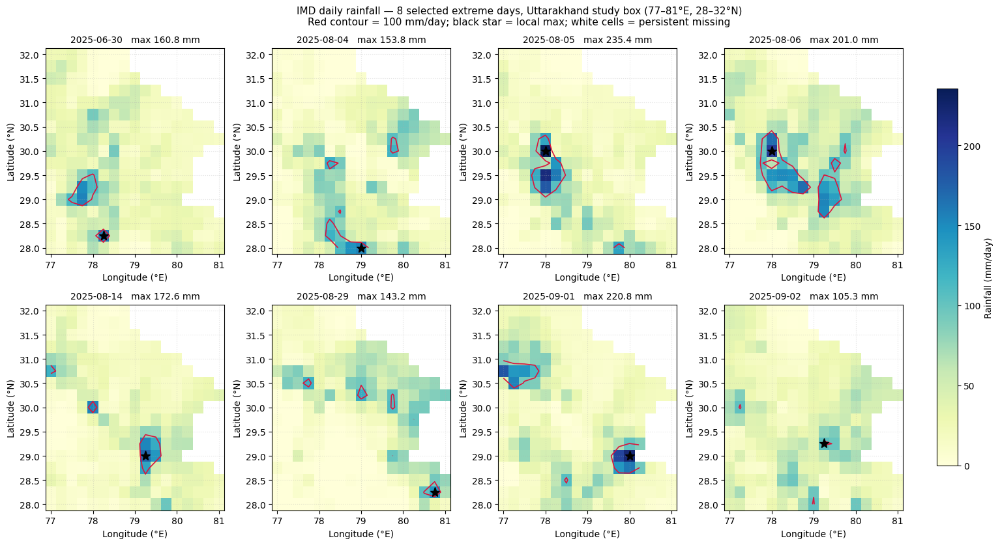

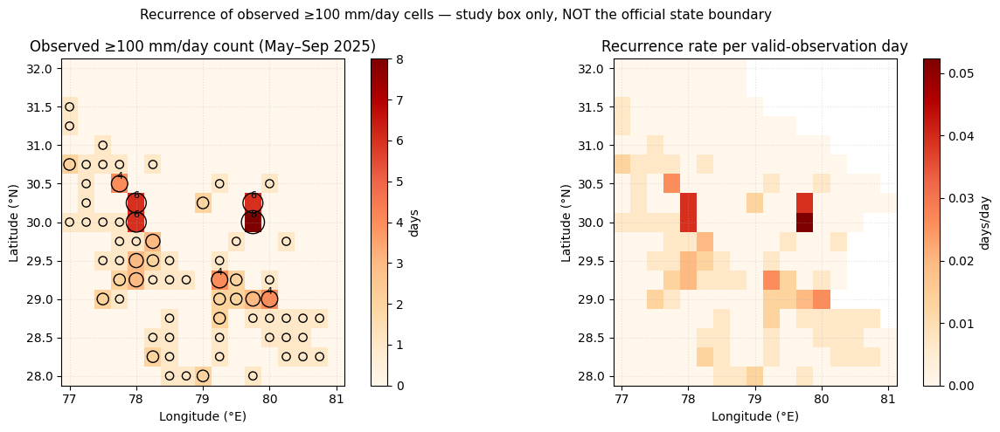

Top recurrence cells (observed days | rate per valid-observation day):
  8 days | 0.052  at lat=30.00, lon=79.75
  6 days | 0.039  at lat=30.25, lon=79.75
  6 days | 0.039  at lat=30.25, lon=78.00
  6 days | 0.039  at lat=30.00, lon=78.00
  4 days | 0.026  at lat=30.50, lon=77.75
  4 days | 0.026  at lat=29.25, lon=79.25
  4 days | 0.026  at lat=29.00, lon=80.00


In [ ]:
# ============================================================
# MAP CELL — 8 extreme-day IMD rainfall fields + recurrence
# Uses: box, ext, count100, valid_days, rate100 (from reconstruction cell)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

lat = box[LAT].values
lon = box[LON].values
vmax = float(box.max(skipna=True))          # shared color scale across the 8 days

# ---------- Figure 1: the 8 extreme days ----------
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for ax, t in zip(axes.ravel(), ext[TIME].values):
    day = box.sel({TIME: t})
    im = ax.pcolormesh(lon, lat, day.values, cmap='YlGnBu',
                       vmin=0, vmax=vmax, shading='auto')
    ax.contour(lon, lat, day.values, levels=[100.0],
               colors='crimson', linewidths=1.2)          # 100 mm/day outline
    mx   = float(day.max(skipna=True))
    loc  = day.where(day == mx, drop=True)
    mlat = float(loc[LAT].values[0]); mlon = float(loc[LON].values[0])
    ax.plot(mlon, mlat, marker='*', color='black', markersize=11)  # local max
    ax.set_title(f"{str(t)[:10]}   max {mx:.1f} mm", fontsize=10)
    ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude (°N)')
    ax.grid(True, ls=':', alpha=0.35)
    ax.set_aspect(1 / np.cos(np.radians(30)))

fig.suptitle('IMD daily rainfall — 8 selected extreme days, Uttarakhand study box (77–81°E, 28–32°N)\n'
             'Red contour = 100 mm/day; black star = local max; white cells = persistent missing',
             fontsize=11)
fig.tight_layout(rect=[0, 0, 0.88, 1])
cax = fig.add_axes([0.90, 0.15, 0.02, 0.68])
fig.colorbar(im, cax=cax, label='Rainfall (mm/day)')
plt.show()

# ---------- Figure 2: recurrence of >=100 mm/day observations ----------
cnt  = count100.values
rate = rate100.values
yy, xx = np.meshgrid(lat, lon, indexing='ij')

fig2, axe = plt.subplots(1, 2, figsize=(13, 5))

pc = axe[0].pcolormesh(lon, lat, cnt, cmap='OrRd', shading='auto')
axe[0].scatter(xx[cnt >= 1], yy[cnt >= 1], s=(cnt[cnt >= 1] * 45).astype(float),
               facecolors='none', edgecolors='black', linewidths=1.0)
for i, cval in enumerate(cnt.ravel()):           # label the most recurrent cells
    if cval >= 4:
        axe[0].text(xx.ravel()[i], yy.ravel()[i] + 0.04, str(cval),
                    ha='center', va='bottom', fontsize=8, color='black')
axe[0].set_title('Observed ≥100 mm/day count (May–Sep 2025)')
axe[0].set_xlabel('Longitude (°E)'); axe[0].set_ylabel('Latitude (°N)')
axe[0].grid(True, ls=':', alpha=0.35)
axe[0].set_aspect(1 / np.cos(np.radians(30)))
fig2.colorbar(pc, ax=axe[0], label='days')

pc2 = axe[1].pcolormesh(lon, lat, rate, cmap='OrRd', shading='auto')
axe[1].set_title('Recurrence rate per valid-observation day')
axe[1].set_xlabel('Longitude (°E)'); axe[1].set_ylabel('Latitude (°N)')
axe[1].grid(True, ls=':', alpha=0.35)
axe[1].set_aspect(1 / np.cos(np.radians(30)))
fig2.colorbar(pc2, ax=axe[1], label='days/day')

fig2.suptitle('Recurrence of observed ≥100 mm/day cells — study box only, NOT the official state boundary',
              fontsize=11)
fig2.tight_layout()
plt.show()

# ---------- Numerical summary alongside the maps ----------
print('Top recurrence cells (observed days | rate per valid-observation day):')
flat = count100.stack(pt=(LAT, LON))
flat = flat.sortby(flat, ascending=False)
for i in range(7):
    la, lo = flat.pt.values[i]
    r = float(rate100.sel({LAT: la, LON: lo}).values)
    print(f'  {int(flat.values[i])} days | {r:.3f}  at lat={la:.2f}, lon={lo:.2f}')

In [ ]:
# ============================================================
# STEP 2 — DOWNLOAD NASADEM (30 m) FOR THE STUDY BOX
# ============================================================
import os

# 1) Install/import what the fresh runtime needs
try:
    import earthaccess
except ImportError:
    %pip install -q earthaccess
    import earthaccess

try:
    import rasterio
except ImportError:
    %pip install -q rasterio
    import rasterio

# 2) NASA Earthdata login (opens an auth link; approves access)
earthaccess.login(strategy="interactive", persist=True)

# 3) Find NASADEM tiles covering the study box
#    bbox order = (min_lon, min_lat, max_lon, max_lat)
bbox = (77.0, 28.0, 81.0, 32.0)
results = earthaccess.search_data(
    short_name="NASADEM_HGT",
    bounding_box=bbox,
    count=100,
)
print("Granules found:", len(results))

# 4) Download all tiles into /content/nasadem
outdir = "/content/nasadem"
os.makedirs(outdir, exist_ok=True)
files = earthaccess.download(results, local_path=outdir)
print("\nDownloaded files:", len(files))

# 5) Inspect ONE tile (format, CRS, resolution, nodata, elevation range)
import glob
tiles = sorted(glob.glob(outdir + "/*"))
print("First tile:", tiles[0])

with rasterio.open(tiles[0]) as src:
    print("Driver :", src.driver)
    print("CRS    :", src.crs)
    print("Size   :", src.width, "x", src.height)
    print("Res    :", src.res, "degrees")
    print("Nodata :", src.nodata)
    print("Bounds :", src.bounds)
    band = src.read(1)
    print("Elevation min / max / mean:",
          band.min(), "/", band.max(), "/", round(band[band != src.nodata].mean(), 1))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.7/78.7 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 17.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


KeyboardInterrupt: Interrupted by user

In [ ]:
# ============================================================
# FIXED DOWNLOAD — timeout + parallel + per-file progress + skip
# (Interrupt the old cell first: Runtime -> Interrupt execution)
# ============================================================
import os, math, glob, time, socket, urllib.request
from concurrent.futures import ThreadPoolExecutor, as_completed

socket.setdefaulttimeout(60)          # one stuck tile can't hang the whole cell

try:
    import rasterio
except ImportError:
    %pip install -q rasterio
    import rasterio

outdir = "/content/copdem"
os.makedirs(outdir, exist_ok=True)

PAD = 0.2
s, n, w, e = 28, 34, 76, 82          # Himalayan window (south, north, west, east)
lats = list(range(math.floor(s - PAD), math.ceil(n + PAD)))
lons = list(range(math.floor(w - PAD), math.ceil(e + PAD)))
print("Rows:", lats, "| Cols:", lons, "| total:", len(lats) * len(lons))

def tile_url(lt, ln):
    ns = ("N" if lt >= 0 else "S") + f"{abs(lt):02d}_00"
    es = ("E" if ln >= 0 else "W") + f"{abs(ln):03d}_00"
    name = f"Copernicus_DSM_COG_30_{ns}_{es}_DEM"
    return f"https://copernicus-dem-90m.s3.amazonaws.com/{name}/{name}.tif", name

def is_valid(path):
    try:
        with rasterio.open(path) as src:
            return src.width > 0 and src.height > 0
    except Exception:
        return False

def dl(tile):
    lt, ln = tile
    url, name = tile_url(lt, ln)
    fpath = os.path.join(outdir, name + ".tif")
    if os.path.exists(fpath) and is_valid(fpath):
        return f"skip  {name}"
    if os.path.exists(fpath):
        os.remove(fpath)              # clear any partial file from the interrupted run
    t0 = time.time()
    try:
        urllib.request.urlretrieve(url, fpath)
        mb = os.path.getsize(fpath) / 1e6
        return f"ok    {name}  {mb:.2f} MB  {time.time()-t0:.0f}s"
    except Exception as ex:
        return f"FAIL  {name}  -> {ex}"

tiles = [(lt, ln) for lt in lats for ln in lons]
done = 0
with ThreadPoolExecutor(max_workers=8) as ex:
    for fut in as_completed([ex.submit(dl, t) for t in tiles]):
        done += 1
        print(f"[{done}/{len(tiles)}] {fut.result()}")

files = sorted(glob.glob(outdir + "/*.tif"))
print(f"\nOn disk: {len(files)} files | {sum(os.path.getsize(f)/1e6 for f in files):.1f} MB")

if files:
    with rasterio.open(files[0]) as src:
        b = src.read(1)
        print("Sample tile:", os.path.basename(files[0]),
              "| CRS", src.crs, "| res", src.res,
              "| size", src.width, "x", src.height,
              "| elev min/max", b.min(), b.max())

Rows: [27, 28, 29, 30, 31, 32, 33, 34] | Cols: [75, 76, 77, 78, 79, 80, 81, 82] | total: 64
[1/64] ok    Copernicus_DSM_COG_30_N27_00_E082_00_DEM  5.25 MB  1s
[2/64] ok    Copernicus_DSM_COG_30_N27_00_E076_00_DEM  4.97 MB  1s
[3/64] ok    Copernicus_DSM_COG_30_N27_00_E078_00_DEM  4.68 MB  1s
[4/64] ok    Copernicus_DSM_COG_30_N27_00_E079_00_DEM  4.74 MB  1s
[5/64] ok    Copernicus_DSM_COG_30_N27_00_E080_00_DEM  4.94 MB  1s
[6/64] ok    Copernicus_DSM_COG_30_N27_00_E075_00_DEM  4.86 MB  1s
[7/64] ok    Copernicus_DSM_COG_30_N27_00_E081_00_DEM  5.08 MB  1s
[8/64] ok    Copernicus_DSM_COG_30_N27_00_E077_00_DEM  4.63 MB  1s
[9/64] ok    Copernicus_DSM_COG_30_N28_00_E075_00_DEM  4.82 MB  0s
[10/64] ok    Copernicus_DSM_COG_30_N28_00_E078_00_DEM  4.74 MB  0s
[11/64] ok    Copernicus_DSM_COG_30_N28_00_E079_00_DEM  4.80 MB  0s
[12/64] ok    Copernicus_DSM_COG_30_N28_00_E077_00_DEM  4.79 MB  0s
[13/64] ok    Copernicus_DSM_COG_30_N28_00_E080_00_DEM  5.00 MB  0s
[14/64] ok    Copernicus_DSM_COG_

In [ ]:
# ============================================================
# STEP 3 — MERGE tiles, CROP to window, QA, DERIVE SLOPE
# ============================================================
import os, glob
import numpy as np
import rasterio
from rasterio.merge import merge
from rasterio.windows import from_bounds

outdir = "/content/copdem"
tiles = sorted(glob.glob(outdir + "/*.tif"))
print("Tiles to merge:", len(tiles))

# --- 1) Merge all tiles into one mosaic ---
with rasterio.open(tiles[0]) as s0:
    prof = s0.profile

mosaic, out_trans = merge(tiles)
mosaic_path = "/content/copdem_himalaya_mosaic.tif"
prof.update(driver="GTiff", height=mosaic.shape[1], width=mosaic.shape[2],
            transform=out_trans, dtype="float32", count=1,
            compress="deflate", tiled=True)
with rasterio.open(mosaic_path, "w", **prof) as dst:
    dst.write(mosaic.astype("float32"))
print("Mosaic:", mosaic_path, mosaic.shape[1], "x", mosaic.shape[2])

# --- 2) Crop to the study window 76-82E, 28-34N ---
bounds = (76.0, 28.0, 82.0, 34.0)   # (west, south, east, north)
with rasterio.open(mosaic_path) as src:
    win = from_bounds(*bounds, transform=src.transform,
                      height=src.height, width=src.width)
    elev = src.read(1, window=win).astype("float32")
    ctrans = src.window_transform(win)
    nodata = src.nodata
    res = src.res
print("Crop:", elev.shape, "| res(deg):", round(res[0], 6), round(res[1], 6),
      "| nodata:", nodata)

# --- 3) Missing-value / coverage check ---
bad = (elev == nodata) if nodata is not None else ~np.isfinite(elev)
print("Missing/invalid pixels:", int(bad.sum()), f"({100 * bad.mean():.3f} %)")
elev = np.where(bad, np.nan, elev)
print(f"Elevation (m): min {np.nanmin(elev):.0f} | max {np.nanmax(elev):.0f} | "
      f"mean {np.nanmean(elev):.0f} | median {np.nanmedian(elev):.0f}")

# --- 4) Slope (degrees) at native ~93 m resolution ---
nrows, ncols = elev.shape
y = ctrans.f + ctrans.e * (np.arange(nrows) + 0.5)          # row-centre latitudes
latv = np.clip(y, -89, 89)

gx_deg = np.gradient(elev, axis=1) / abs(ctrans.a)          # dz / degree longitude
gy_deg = np.gradient(elev, axis=0) / abs(ctrans.e)          # dz / degree latitude
m_per_deg = 111132.0                                        # metres per degree latitude
gx = gx_deg / (m_per_deg * np.cos(np.radians(latv))[:, None])   # dz / metre (E-W)
gy = gy_deg / m_per_deg                                          # dz / metre (N-S)
slope = np.degrees(np.arctan(np.hypot(gx, gy)))

print(f"Slope (deg): min {np.nanmin(slope):.2f} | mean {np.nanmean(slope):.2f} | "
      f"median {np.nanmedian(slope):.2f} | 90th pct {np.nanpercentile(slope, 90):.1f}")

# --- 5) Save crop + slope (so a Colab reset doesn't lose them) ---
for fname, arr in [("elev", elev), ("slope", slope)]:
    p = f"/content/copdem_{fname}.tif"
    prof.update(driver="GTiff", height=nrows, width=ncols, transform=ctrans,
                dtype="float32", count=1, nodata=-9999.0,
                compress="deflate", tiled=True)
    filled = np.where(np.isnan(arr), -9999.0, arr).astype("float32")
    with rasterio.open(p, "w", **prof) as dst:
        dst.write(filled, 1)
    print("Saved:", p)


Tiles to merge: 64
Mosaic: /content/copdem_himalaya_mosaic.tif 9600 x 9600


/usr/local/lib/python3.13/dist-packages/rasterio/windows.py:314: RasterioDeprecationWarning: The height, width, and precision parameters are unused, deprecated, and will be removed in 2.0.0.
  warnings.warn(


Crop: (7200, 7200) | res(deg): 0.000833 0.000833 | nodata: None
Missing/invalid pixels: 0 (0.000 %)
Elevation (m): min 126 | max 7793 | mean 2885 | median 3513
Slope (deg): min 0.00 | mean 15.22 | median 12.55 | 90th pct 35.3
Saved: /content/copdem_elev.tif
Saved: /content/copdem_slope.tif


Padded crop: (7500, 7500) (expect 7500 x 7500)
Grid: 25 lat x 25 lon cells at 0.25°
Cell mean elevation: min 131 | max 5699 | mean 2860 m
Cell median slope : min 0.00 | max 36.64 | mean 14.55 deg
Descriptive correlation  elev_mean vs slope_median: r = 0.52
Saved /content/terrain_0p25_himalaya.csv | 625 rows
    lat    lon  elev_mean  slope_median  slope_p90
0  28.0  76.00      338.5          0.56       3.51
1  28.0  76.25      314.1          0.38       1.26
2  28.0  76.50      285.5          0.31       1.22
3  28.0  76.75      270.9          0.27       0.85
4  28.0  77.00      233.6          0.29       4.05


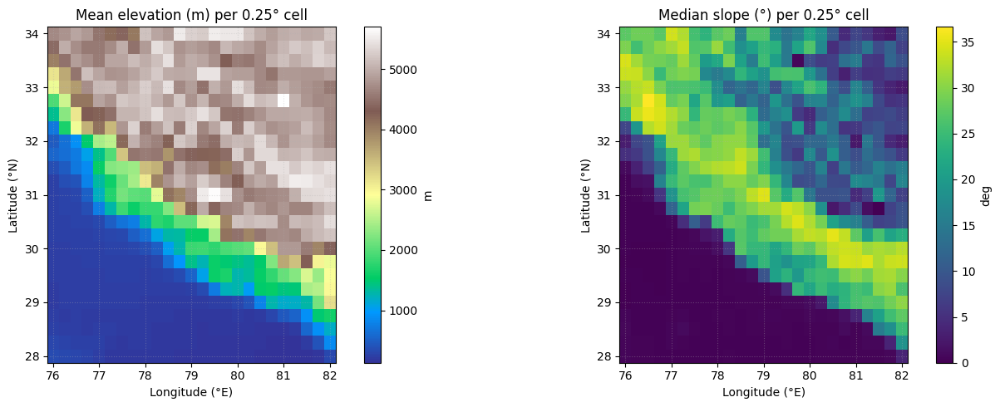

In [ ]:
# ============================================================
# STEP 4 — RESAMPLE DEM TO THE 0.25° RAINFALL GRID + SAVE + MAP
# ============================================================
import os
import numpy as np
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
import pandas as pd

mosaic_path = "/content/copdem_himalaya_mosaic.tif"
assert os.path.exists(mosaic_path), "Mosaic missing — rerun STEP 3 first"

# 1) Crop with half-cell padding so 0.25° cell centres line up exactly
pad = 0.125
bounds = (76.0 - pad, 28.0 - pad, 82.0 + pad, 34.0 + pad)   # W, S, E, N

with rasterio.open(mosaic_path) as src:
    t = src.transform
    res_deg = abs(t.a)                       # degrees per pixel (~0.000833)
    mw, mn = t.c, t.f                        # mosaic west edge, north edge
    col_off = int(round((bounds[0] - mw) / res_deg))
    row_off = int(round((mn - bounds[3]) / res_deg))
    npx     = int(round((bounds[2] - bounds[0]) / res_deg))
    e = src.read(1, window=Window(col_off, row_off, npx, npx)).astype("float32")
    ctrans = src.window_transform(Window(col_off, row_off, npx, npx))

print("Padded crop:", e.shape, "(expect 7500 x 7500)")

# 2) Recompute slope on the padded crop (so edge cells aren't clipped)
nrows, ncols = e.shape
y = ctrans.f + ctrans.e * (np.arange(nrows) + 0.5)
latv = np.clip(y, -89, 89)
gx_deg = np.gradient(e, axis=1) / abs(ctrans.a)
gy_deg = np.gradient(e, axis=0) / abs(ctrans.e)
m_per_deg = 111132.0
gx = gx_deg / (m_per_deg * np.cos(np.radians(latv))[:, None])
gy = gy_deg / m_per_deg
slope = np.degrees(np.arctan(np.hypot(gx, gy)))

# 3) Aggregate to 0.25° cells (each cell = 300 x 300 native pixels)
nc, B = 25, 300
assert e.shape == (nc * B, nc * B)

elev_cell  = np.nanmean(e.reshape(nc, B, nc, B), axis=(1, 3))       # row 0 = north
slope_cell = np.nanmedian(slope.reshape(nc, B, nc, B), axis=(1, 3))
slope_p90  = np.nanpercentile(slope.reshape(nc, B, nc, B), 90, axis=(1, 3))

# flip to ascending latitude
elev_cell, slope_cell, slope_p90 = elev_cell[::-1, :], slope_cell[::-1, :], slope_p90[::-1, :]
lon = 76.0 + 0.25 * np.arange(nc)
lat = 28.0 + 0.25 * np.arange(nc)
print("Grid:", len(lat), "lat x", len(lon), "lon cells at 0.25°")
print(f"Cell mean elevation: min {elev_cell.min():.0f} | max {elev_cell.max():.0f} | mean {elev_cell.mean():.0f} m")
print(f"Cell median slope : min {slope_cell.min():.2f} | max {slope_cell.max():.2f} | mean {slope_cell.mean():.2f} deg")
r = np.corrcoef(elev_cell.ravel(), slope_cell.ravel())[0, 1]
print("Descriptive correlation  elev_mean vs slope_median: r =", round(r, 3))

# 4) Save as CSV
records = []
for j in range(nc):
    for i in range(nc):
        records.append(dict(lat=round(lat[j], 2), lon=round(lon[i], 2),
                            elev_mean=round(float(elev_cell[j, i]), 1),
                            slope_median=round(float(slope_cell[j, i]), 2),
                            slope_p90=round(float(slope_p90[j, i]), 2)))
df = pd.DataFrame(records)
df.to_csv("/content/terrain_0p25_himalaya.csv", index=False)
print("Saved /content/terrain_0p25_himalaya.csv |", str(df.shape[0]), "rows")
print(df.head())

# 5) Quick maps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
im0 = axes[0].pcolormesh(lon, lat, elev_cell, cmap='terrain', shading='auto')
axes[0].set_title('Mean elevation (m) per 0.25° cell')
fig.colorbar(im0, ax=axes[0], label='m')
im1 = axes[1].pcolormesh(lon, lat, slope_cell, cmap='viridis', shading='auto')
axes[1].set_title('Median slope (°) per 0.25° cell')
fig.colorbar(im1, ax=axes[1], label='deg')
for ax in axes:
    ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude (°N)')
    ax.set_aspect(1 / np.cos(np.radians(31)))
    ax.grid(True, ls=':', alpha=0.35)
plt.tight_layout()
plt.show()

Window rain: (153, 25, 25) (expect 153, 25, 25)
Cells: 625 (expect 625)
Cells with any data: 416
Persistent-missing cells: 209
Cells with >=1 day >=100mm: 89
Total observed >=100mm cell-days: 150
valid_days unique values: [  0 153]
Merged cells: 625

Valid cells: 416 | high-rain: 89 | rest: 327

--- Mean elevation (m) ---
  high-rain : mean 690.3 | median 266.7 | min 147 | max 5172
  other     : mean 2500.2 | median 2042.1 | min 131 | max 5665
--- Median slope (deg) ---
  high-rain : mean 6.8 | median 0.6 | min 0 | max 32
  other     : mean 16.5 | median 21.1 | min 0 | max 37
Mann-Whitney U (elev_mean): U=8452, p=1.318e-09
Mann-Whitney U (slope_median): U=10164, p=1.289e-05

Top 10 recurrence cells (days | elev | slope):
  8 days | lat 30.00 lon 79.75 | elev 1916 m | slope 28.4 deg
  6 days | lat 30.00 lon 78.00 | elev 369 m | slope 1.3 deg
  6 days | lat 30.25 lon 78.00 | elev 621 m | slope 2.9 deg
  6 days | lat 30.25 lon 79.75 | elev 4107 m | slope 31.9 deg
  4 days | lat 30.50 lon 

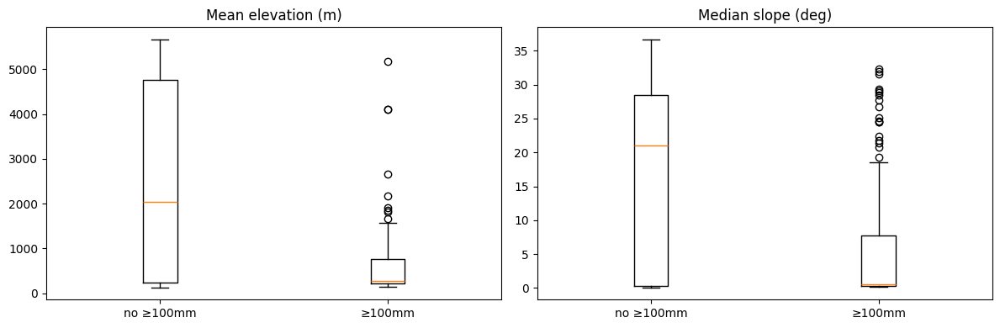

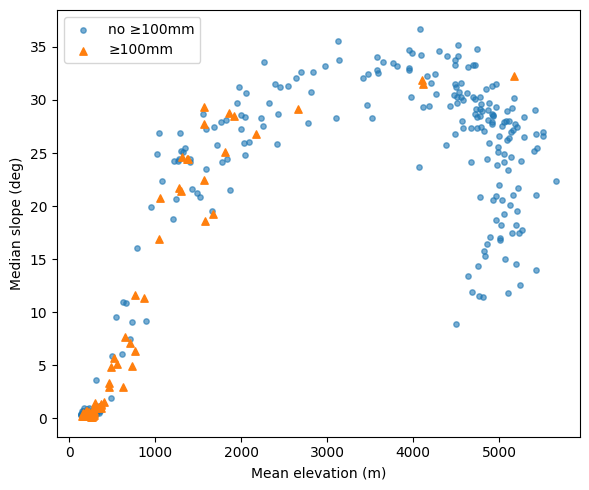

In [ ]:
# ============================================================
# STEP 5 — RAINFALL-TERRAIN COMPARISON OVER THE HIMALAYAN WINDOW
# ============================================================
import os, glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# 1) Make sure the full-India IMD array is still in memory; reopen if reset
if 'rain' not in globals():
    files = sorted(glob.glob('/content/*.nc'))
    ds = xr.open_dataset(files[0])
    TIME = [d for d in ds.dims if d.upper().startswith('TIME')][0]
    LAT  = [d for d in ds.dims if d.upper().startswith('LAT')][0]
    LON  = [d for d in ds.dims if d.upper().startswith('LON')][0]
    VARR = [v for v in ds.data_vars if v.upper() in ('RAINFALL','RAIN','RF','PRECIP','PRECIPITATION')][0]
    rain = ds[VARR].astype('float64').sortby(LAT).sortby(LON)

# 2) Crop IMD to the same Himalayan window, May-Sep 2025
win_rain = rain.sel({TIME: slice('2025-05-01', '2025-09-30'),
                     LAT: slice(28, 34), LON: slice(76, 82)})
print("Window rain:", win_rain.shape, "(expect 153, 25, 25)")

days       = win_rain.sizes[TIME]
valid_days = win_rain.notnull().sum(dim=TIME)
count100   = (win_rain >= 100).sum(dim=TIME)
rate100    = count100 / valid_days.where(valid_days > 0)

print("Cells:", win_rain.sizes[LAT] * win_rain.sizes[LON], "(expect 625)")
print("Cells with any data:", int((valid_days > 0).sum()))
print("Persistent-missing cells:", int((valid_days == 0).sum()))
print("Cells with >=1 day >=100mm:", int((count100 >= 1).sum()))
print("Total observed >=100mm cell-days:", int(count100.sum()))
print("valid_days unique values:", np.unique(valid_days.values))

# 3) Merge terrain table with rainfall counts
tm = pd.read_csv('/content/terrain_0p25_himalaya.csv')
lat2 = win_rain[LAT].values
lon2 = win_rain[LON].values
ac, av = count100.values, valid_days.values
recs = []
for j in range(len(lat2)):
    for i in range(len(lon2)):
        recs.append(dict(lat=round(float(lat2[j]), 2), lon=round(float(lon2[i]), 2),
                         count100=int(ac[j, i]), valid_days=int(av[j, i])))
rf = pd.DataFrame(recs)
df = tm.merge(rf, on=['lat', 'lon'], how='inner')
print("Merged cells:", df.shape[0])

# 4) Classify: high-rain (>=1 observed >=100mm day) vs other VALID cells
d = df[df.valid_days > 0].copy()
d['high'] = (d.count100 >= 1).astype(int)
g_hi = d[d.high == 1]
g_lo = d[d.high == 0]
print(f"\nValid cells: {len(d)} | high-rain: {len(g_hi)} | rest: {len(g_lo)}")

def summ(name, s):
    print(f"  {name:10s}: mean {s.mean():.1f} | median {s.median():.1f} | min {s.min():.0f} | max {s.max():.0f}")

print("\n--- Mean elevation (m) ---"); summ("high-rain", g_hi.elev_mean); summ("other", g_lo.elev_mean)
print("--- Median slope (deg) ---"); summ("high-rain", g_hi.slope_median); summ("other", g_lo.slope_median)

# 5) Non-parametric comparison (exploratory; cells are spatially correlated)
try:
    from scipy import stats
except ImportError:
    %pip install -q scipy
    from scipy import stats
for col in ['elev_mean', 'slope_median']:
    u, p = stats.mannwhitneyu(g_hi[col], g_lo[col], alternative='two-sided')
    print(f"Mann-Whitney U ({col}): U={u:.0f}, p={p:.4g}")

print("\nTop 10 recurrence cells (days | elev | slope):")
for _, r in d.sort_values('count100', ascending=False).head(10).iterrows():
    print(f"  {int(r.count100)} days | lat {r.lat:.2f} lon {r.lon:.2f} | "
          f"elev {r.elev_mean:.0f} m | slope {r.slope_median:.1f} deg")

# 6) Figures
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, name in zip(axes, ['elev_mean', 'slope_median'],
                         ['Mean elevation (m)', 'Median slope (deg)']):
    ax.boxplot([g_lo[col], g_hi[col]])
    ax.set_xticks([1, 2]); ax.set_xticklabels(['no ≥100mm', '≥100mm'])
    ax.set_title(name)
plt.tight_layout(); plt.show()

fig2, ax2 = plt.subplots(figsize=(6, 5))
ax2.scatter(g_lo.elev_mean, g_lo.slope_median, s=15, alpha=0.6, label='no ≥100mm')
ax2.scatter(g_hi.elev_mean, g_hi.slope_median, s=28, marker='^', label='≥100mm')
ax2.set_xlabel('Mean elevation (m)'); ax2.set_ylabel('Median slope (deg)')
ax2.legend(); plt.tight_layout(); plt.show()

Missing cells: 209 | observed cells: 416
Elevation: missing mean 4348 median 4818 | observed mean 2113 median 1275
Slope:     missing mean 14.7 median 13.0 | observed mean 14.5 median 15.6
Mann-Whitney elev_mean (missing vs observed): U=69832, p=3.485e-35
Mann-Whitney slope_median (missing vs observed): U=46911, p=0.1064

--- elev_mean bands (valid cells) ---
             n  extremes  density_pct  median_slope
band                                               
<500       180        60         33.3         0.290
500-1000    18         9         50.0         8.415
1000-2000   47        15         31.9        24.460
2000-4000   40         2          5.0        31.380
>4000      131         3          2.3        27.480

--- slope_median bands (valid cells) ---
         n  extremes  density_pct  median_slope
sband                                          
<2     175        57         32.6         0.290
2-5      6         5         83.3         3.485
5-10    12         5         41.7       

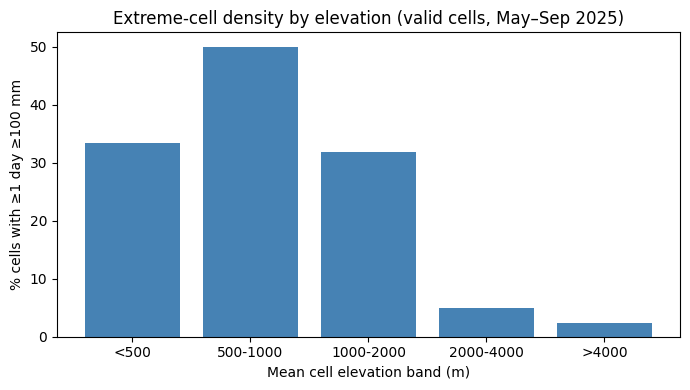

In [ ]:
# ============================================================
# STEP 6 — MISSING-DATA DIAGNOSTIC + BAND STRATIFICATION
# ============================================================
import glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

try:
    from scipy import stats
except ImportError:
    %pip install -q scipy
    from scipy import stats

# 1) Rebuild rainfall counts if the runtime lost them
if 'win_rain' not in globals():
    files = sorted(glob.glob('/content/*.nc'))
    ds = xr.open_dataset(files[0])
    TIME = [d for d in ds.dims if d.upper().startswith('TIME')][0]
    LAT  = [d for d in ds.dims if d.upper().startswith('LAT')][0]
    LON  = [d for d in ds.dims if d.upper().startswith('LON')][0]
    VARR = [v for v in ds.data_vars if v.upper() in ('RAINFALL','RAIN','RF','PRECIP','PRECIPITATION')][0]
    r2 = ds[VARR].astype('float64').sortby(LAT).sortby(LON)
    win_rain = r2.sel({TIME: slice('2025-05-01','2025-09-30'),
                       LAT: slice(28,34), LON: slice(76,82)})

lat2 = win_rain[LAT].values
lon2 = win_rain[LON].values
valid = win_rain.notnull().sum(dim=TIME).values
cnt   = (win_rain >= 100).sum(dim=TIME).values

tm = pd.read_csv('/content/terrain_0p25_himalaya.csv')
recs = []
for j in range(len(lat2)):
    for i in range(len(lon2)):
        recs.append(dict(lat=round(float(lat2[j]),2), lon=round(float(lon2[i]),2),
                         observed=int(valid[j,i] > 0), count100=int(cnt[j,i])))
df = tm.merge(pd.DataFrame(recs), on=['lat','lon'], how='inner')

# 2) Missing vs observed terrain
miss = df[df.observed == 0]
obs  = df[df.observed == 1]
print("Missing cells:", len(miss), "| observed cells:", len(obs))
print(f"Elevation: missing mean {miss.elev_mean.mean():.0f} median {miss.elev_mean.median():.0f} "
      f"| observed mean {obs.elev_mean.mean():.0f} median {obs.elev_mean.median():.0f}")
print(f"Slope:     missing mean {miss.slope_median.mean():.1f} median {miss.slope_median.median():.1f} "
      f"| observed mean {obs.slope_median.mean():.1f} median {obs.slope_median.median():.1f}")
for col in ['elev_mean','slope_median']:
    u, p = stats.mannwhitneyu(miss[col], obs[col], alternative='two-sided')
    print(f"Mann-Whitney {col} (missing vs observed): U={u:.0f}, p={p:.4g}")

# 3) Elevation-band table (valid cells only)
d = df[df.observed == 1].copy()
d['band'] = pd.cut(d.elev_mean, bins=[0,500,1000,2000,4000,9000],
                   labels=['<500','500-1000','1000-2000','2000-4000','>4000'])
d['sband'] = pd.cut(d.slope_median, bins=[0,2,5,10,20,40],
                    labels=['<2','2-5','5-10','10-20','>20'])

for key, cname in [('band','elev_mean'), ('sband','slope_median')]:
    g = d.groupby(key, observed=False).agg(n=(cname,'size'),
             extremes=('count100', lambda s: int((s >= 1).sum())),
             median_slope=('slope_median','median'))
    g['density_pct'] = (100 * g['extremes'] / g['n']).round(1)
    print(f"\n--- {cname} bands (valid cells) ---")
    print(g[['n','extremes','density_pct','median_slope']].to_string())

# 4) Bar chart of extreme-cell density by elevation band
g = d.groupby('band', observed=False).agg(n=('elev_mean','size'),
        extremes=('count100', lambda s: int((s >= 1).sum())))
g['density_pct'] = 100 * g['extremes'] / g['n']
fig, ax = plt.subplots(figsize=(7,4))
ax.bar([str(x) for x in g.index], g.density_pct, color='steelblue')
ax.set_xlabel('Mean cell elevation band (m)')
ax.set_ylabel('% cells with ≥1 day ≥100 mm')
ax.set_title('Extreme-cell density by elevation (valid cells, May–Sep 2025)')
plt.tight_layout(); plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

folder = "/content/drive/MyDrive/GPM_2025"

if os.path.exists(folder):
    files = os.listdir(folder)
    print("GPM folder found!")
    print("Number of items:", len(files))
    print("\nFirst 15 items:")
    for f in files[:15]:
        print(f)
else:
    print("GPM folder not found at:", folder)
    print("\nFolders in MyDrive:")
    print(os.listdir("/content/drive/MyDrive")[:30])

Mounted at /content/drive
GPM folder found!
Number of items: 153

First 15 items:
3B-DAY.MS.MRG.3IMERG.20250501-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250504-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250506-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250505-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250508-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250503-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250502-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250507-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250512-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250515-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250509-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250516-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250511-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250519-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250521-S000000-E235959.V07B.nc4


In [ ]:
# ============================================================
# STEP 7 — GPM IMERG CROSS-CHECK FOR THE HIGH-ALTITUDE GAP
# ============================================================
import glob, os, re
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

try:
    from scipy import stats
except ImportError:
    %pip install -q scipy
    from scipy import stats

# ---- 1) Load GPM: crop each day, interpolate onto the 0.25° grid ----
gdir = "/content/drive/MyDrive/GPM_2025"
files = sorted(glob.glob(gdir + "/*.nc4"))
print("GPM files:", len(files))

latc = 28.0 + 0.25 * np.arange(25)
lonc = 76.0 + 0.25 * np.arange(25)

stack = []
for f in files:
    with xr.open_dataset(f) as ds:
        v = [v for v in ds.data_vars if 'precip' in v.lower()][0]
        a = ds[v]
        for d in list(a.dims):
            if a.sizes[d] == 1:
                a = a.isel({d: 0})
        latdim = [d for d in a.dims if 'lat' in d][0]
        londim = [d for d in a.dims if 'lon' in d][0]
        a = a.sortby(latdim).sortby(londim)
        crop = a.sel({latdim: slice(28, 34), londim: slice(76, 82)}).astype('float32')
        stack.append(crop.interp({latdim: latc, londim: lonc}).values)

gpm = np.asarray(stack)                       # (153, 25, 25)
print("GPM stack:", gpm.shape, "(expect 153, 25, 25)")
gpm_count = (gpm >= 100).sum(axis=0)
gpm_has   = (gpm_count >= 1)

# ---- 2) IMD counts for the same cells (rebuild if needed) ----
if 'win_rain' not in globals():
    ff = sorted(glob.glob('/content/*.nc'))
    ds = xr.open_dataset(ff[0])
    TIME=[d for d in ds.dims if d.upper().startswith('TIME')][0]
    LAT=[d for d in ds.dims if d.upper().startswith('LAT')][0]
    LON=[d for d in ds.dims if d.upper().startswith('LON')][0]
    VARR=[v for v in ds.data_vars if v.upper() in ('RAINFALL','RAIN','RF','PRECIP','PRECIPITATION')][0]
    r2 = ds[VARR].astype('float64').sortby(LAT).sortby(LON)
    win_rain = r2.sel({TIME: slice('2025-05-01','2025-09-30'),
                       LAT: slice(28,34), LON: slice(76,82)})

lat2 = win_rain[LAT].values
lon2 = win_rain[LON].values
valid = win_rain.notnull().sum(dim=TIME).values
cnt   = (win_rain >= 100).sum(dim=TIME).values

# ---- 3) Merge terrain + IMD + GPM into one table ----
tm = pd.read_csv('/content/terrain_0p25_himalaya.csv')
recs = []
for j in range(len(lat2)):
    for i in range(len(lon2)):
        ok = valid[j, i] > 0
        recs.append(dict(lat=round(float(lat2[j]), 2), lon=round(float(lon2[i]), 2),
                         imd_count=int(cnt[j, i]) if ok else np.nan,
                         imd_has=int(cnt[j, i] >= 1) if ok else np.nan,
                         gpm_count=int(gpm_count[j, i]),
                         gpm_has=int(gpm_count[j, i] >= 1)))
df = tm.merge(pd.DataFrame(recs), on=['lat', 'lon'], how='inner')

# ---- 4) IMD vs GPM agreement (only cells where IMD observed) ----
sub = df[df.imd_has.notna()].copy()
print(f"\nCells compared (IMD observed): {len(sub)}")
print("'ever >=100mm' agreement: %.1f %%" % (100 * (sub.imd_has == sub.gpm_has).mean()))
print(pd.crosstab(sub.imd_has, sub.gpm_has, rownames=['IMD_has'], colnames=['GPM_has']))
r = np.corrcoef(sub.imd_count, sub.gpm_count)[0, 1]
sp = stats.spearmanr(sub.imd_count, sub.gpm_count)
print(f"Count correlation: Pearson r={r:.3f} | Spearman rho={sp.correlation:.3f} (p={sp.pvalue:.3g})")

# ---- 5) Band tables for both products ----
def band_table(d, col, has, bins, labels):
    dd = d.copy()
    dd['band'] = pd.cut(dd[col], bins=bins, labels=labels)
    g = dd.groupby('band', observed=False).agg(n=(col, 'size'), k=(has, 'sum'))
    g['pct'] = (100 * g['k'] / g['n']).round(1)
    return g

ebins = [0, 500, 1000, 2000, 4000, 9000]
elabs = ['<500', '500-1000', '1000-2000', '2000-4000', '>4000']
g_imd_e = band_table(df[df.imd_has.notna()], 'elev_mean', 'imd_has', ebins, elabs)
g_gpm_e = band_table(df, 'elev_mean', 'gpm_has', ebins, elabs)
print("\nElevation-band density (IMD valid vs GPM all):")
print(pd.DataFrame({'IMD_n': g_imd_e.n, 'IMD_pct': g_imd_e.pct,
                    'GPM_n': g_gpm_e.n, 'GPM_pct': g_gpm_e.pct}).to_string())

sbins = [0, 2, 5, 10, 20, 40]
slabs = ['<2', '2-5', '5-10', '10-20', '>20']
g_imd_s = band_table(df[df.imd_has.notna()], 'slope_median', 'imd_has', sbins, slabs)
g_gpm_s = band_table(df, 'slope_median', 'gpm_has', sbins, slabs)
print("\nSlope-band density (IMD valid vs GPM all):")
print(pd.DataFrame({'IMD_n': g_imd_s.n, 'IMD_pct': g_imd_s.pct,
                    'GPM_n': g_gpm_s.n, 'GPM_pct': g_gpm_s.pct}).to_string())

# ---- 6) Figures ----
imd_map = np.where(valid > 0, cnt, np.nan)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im = axes[0].pcolormesh(lonc, latc, imd_map, cmap='OrRd', shading='auto')
axes[0].set_title('IMD observed ≥100mm days (white = missing)')
fig.colorbar(im, ax=axes[0], label='days')
im2 = axes[1].pcolormesh(lonc, latc, gpm_count, cmap='OrRd', shading='auto')
axes[1].set_title('GPM ≥100mm days (interp. to 0.25°)')
fig.colorbar(im2, ax=axes[1], label='days')
for ax in axes:
    ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude (°N)')
    ax.set_aspect(1 / np.cos(np.radians(31)))
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(5)
ax.bar(x - 0.18, g_imd_e.pct, width=0.35, label='IMD (valid cells)')
ax.bar(x + 0.18, g_gpm_e.pct, width=0.35, label='GPM (all cells)')
ax.set_xticks(x); ax.set_xticklabels([str(b) for b in g_imd_e.index])
ax.set_xlabel('Mean cell elevation band (m)')
ax.set_ylabel('% cells with ≥1 day ≥100 mm')
ax.set_title('Extreme-cell density by elevation: IMD vs GPM')
ax.legend(); plt.tight_layout(); plt.show()

GPM files: 153


RuntimeError: Error iterating over attributes (file read failed: time = Sat Oct 10 10:42:28 2026
, filename = '/content/drive/MyDrive/GPM_2025/3B-DAY.MS.MRG.3IMERG.20250502-S000000-E235959.V07B.nc4', file descriptor = 52, errno = 107, error message = 'Transport endpoint is not connected', buf = 0x2a1ca4b0, total read size = 1024, bytes this sub-read = 1024, offset = 2580083)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

folder = "/content/drive/MyDrive/GPM_2025"

if os.path.exists(folder):
    files = os.listdir(folder)
    print("GPM folder found!")
    print("Number of items:", len(files))
    print("\nFirst 15 items:")
    for f in files[:15]:
        print(f)
else:
    print("GPM folder not found at:", folder)
    print("\nFolders in MyDrive:")
    print(os.listdir("/content/drive/MyDrive")[:30])

Mounted at /content/drive
GPM folder found!
Number of items: 153

First 15 items:
3B-DAY.MS.MRG.3IMERG.20250501-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250504-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250506-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250505-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250508-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250503-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250502-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250507-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250512-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250515-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250509-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250516-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250511-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250519-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250521-S000000-E235959.V07B.nc4


In [ ]:
import os, math, glob, socket, urllib.request
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd

socket.setdefaulttimeout(60)
try:
    import rasterio
except ImportError:
    %pip install -q rasterio
    import rasterio
from rasterio.merge import merge
from rasterio.windows import Window

outdir = "/content/copdem"; os.makedirs(outdir, exist_ok=True)
PAD = 0.2; s, n, w, e = 28, 34, 76, 82
lats = list(range(math.floor(s-PAD), math.ceil(n+PAD)))
lons = list(range(math.floor(w-PAD), math.ceil(e+PAD)))
print("tiles:", len(lats)*len(lons))

def tile_url(lt, ln):
    ns = ("N" if lt>=0 else "S") + f"{abs(lt):02d}_00"
    es = ("E" if ln>=0 else "W") + f"{abs(ln):03d}_00"
    name = f"Copernicus_DSM_COG_30_{ns}_{es}_DEM"
    return f"https://copernicus-dem-90m.s3.amazonaws.com/{name}/{name}.tif", name

def is_valid(p):
    try:
        with rasterio.open(p) as x: return x.width > 0
    except Exception: return False

def dl(t):
    lt, ln = t
    url, name = tile_url(lt, ln)
    fp = os.path.join(outdir, name+".tif")
    if os.path.exists(fp) and is_valid(fp): return "skip "+name
    if os.path.exists(fp): os.remove(fp)
    try:
        urllib.request.urlretrieve(url, fp); return "ok   "+name
    except Exception as ex: return "FAIL "+name+" "+str(ex)

tiles = [(lt,ln) for lt in lats for ln in lons]
with ThreadPoolExecutor(max_workers=8) as ex:
    for k, fut in enumerate(as_completed([ex.submit(dl,t) for t in tiles]), 1):
        print(f"[{k}/{len(tiles)}] {fut.result()}")

files = sorted(glob.glob(outdir+"/*.tif")); print("on disk:", len(files))
with rasterio.open(files[0]) as s0: prof = s0.profile
mosaic, out_trans = merge(files)
prof.update(driver="GTiff", height=mosaic.shape[1], width=mosaic.shape[2],
            transform=out_trans, dtype="float32", count=1, compress="deflate", tiled=True)
with rasterio.open("/content/copdem_mosaic.tif","w",**prof) as dst: dst.write(mosaic.astype("float32"))

pad = 0.125
bounds = (76.0-pad, 28.0-pad, 82.0+pad, 34.0+pad)
with rasterio.open("/content/copdem_mosaic.tif") as src:
    t = src.transform; res_deg = abs(t.a); mw, mn = t.c, t.f
    c0 = int(round((bounds[0]-mw)/res_deg)); r0 = int(round((mn-bounds[3])/res_deg))
    npx = int(round((bounds[2]-bounds[0])/res_deg))
    elev = src.read(1, window=Window(c0,r0,npx,npx)).astype("float32")
    ctrans = src.window_transform(Window(c0,r0,npx,npx))

nrows, ncols = elev.shape
y = ctrans.f + ctrans.e*(np.arange(nrows)+0.5)
latv = np.clip(y,-89,89)
gx = np.gradient(elev,axis=1)/abs(ctrans.a)/(111132.0*np.cos(np.radians(latv))[:,None])
gy = np.gradient(elev,axis=0)/abs(ctrans.e)/111132.0
slope = np.degrees(np.arctan(np.hypot(gx,gy)))

nc, B = 25, 300
assert elev.shape == (nc*B, nc*B)
elev_cell = np.nanmean(elev.reshape(nc,B,nc,B),axis=(1,3))[::-1,:]
slope_med = np.nanmedian(slope.reshape(nc,B,nc,B),axis=(1,3))[::-1,:]
slope_p90 = np.nanpercentile(slope.reshape(nc,B,nc,B),90,axis=(1,3))[::-1,:]

lon = 76.0+0.25*np.arange(nc); lat = 28.0+0.25*np.arange(nc)
recs=[]
for j in range(nc):
    for i in range(nc):
        recs.append(dict(lat=round(lat[j],2), lon=round(lon[i],2),
                         elev_mean=round(float(elev_cell[j,i]),1),
                         slope_median=round(float(slope_med[j,i]),2),
                         slope_p90=round(float(slope_p90[j,i]),2)))
tm = pd.DataFrame(recs)
tm.to_csv("/content/terrain_0p25_himalaya.csv", index=False)
tm.to_csv("/content/drive/MyDrive/terrain_0p25_himalaya.csv", index=False)
print("saved terrain CSV (625 rows)")

tiles: 64
[1/64] ok   Copernicus_DSM_COG_30_N27_00_E081_00_DEM
[2/64] ok   Copernicus_DSM_COG_30_N27_00_E077_00_DEM
[3/64] ok   Copernicus_DSM_COG_30_N27_00_E076_00_DEM
[4/64] ok   Copernicus_DSM_COG_30_N27_00_E082_00_DEM
[5/64] ok   Copernicus_DSM_COG_30_N27_00_E080_00_DEM
[6/64] ok   Copernicus_DSM_COG_30_N27_00_E075_00_DEM
[7/64] ok   Copernicus_DSM_COG_30_N27_00_E078_00_DEM
[8/64] ok   Copernicus_DSM_COG_30_N27_00_E079_00_DEM
[9/64] ok   Copernicus_DSM_COG_30_N28_00_E078_00_DEM
[10/64] ok   Copernicus_DSM_COG_30_N28_00_E076_00_DEM
[11/64] ok   Copernicus_DSM_COG_30_N28_00_E075_00_DEM
[12/64] ok   Copernicus_DSM_COG_30_N28_00_E079_00_DEM
[13/64] ok   Copernicus_DSM_COG_30_N28_00_E077_00_DEM
[14/64] ok   Copernicus_DSM_COG_30_N28_00_E080_00_DEM
[15/64] ok   Copernicus_DSM_COG_30_N28_00_E081_00_DEM
[16/64] ok   Copernicus_DSM_COG_30_N28_00_E082_00_DEM
[17/64] ok   Copernicus_DSM_COG_30_N29_00_E076_00_DEM
[18/64] ok   Copernicus_DSM_COG_30_N29_00_E075_00_DEM
[19/64] ok   Copernicus_DSM

In [ ]:
import os, glob
import numpy as np, pandas as pd
import xarray as xr

files = sorted(glob.glob('/content/*.nc'))
files = [f for f in files if ('RF25' in os.path.basename(f)) or ('rain' in os.path.basename(f).lower())] or files
ds = xr.open_dataset(files[0])
TIME=[d for d in ds.dims if d.upper().startswith('TIME')][0]
LAT=[d for d in ds.dims if d.upper().startswith('LAT')][0]
LON=[d for d in ds.dims if d.upper().startswith('LON')][0]
VARR=[v for v in ds.data_vars if v.upper() in ('RAINFALL','RAIN','RF','PRECIP','PRECIPITATION')][0]
rain = ds[VARR].astype('float64').sortby(LAT).sortby(LON)
win = rain.sel({TIME: slice('2025-05-01','2025-09-30'), LAT: slice(28,34), LON: slice(76,82)})
valid = win.notnull().sum(dim=TIME).values
cnt   = (win >= 100).sum(dim=TIME).values
lat2 = win[LAT].values; lon2 = win[LON].values
recs=[]
for j in range(len(lat2)):
    for i in range(len(lon2)):
        ok = valid[j,i] > 0
        recs.append(dict(lat=round(float(lat2[j]),2), lon=round(float(lon2[i]),2),
                         imd_count=int(cnt[j,i]) if ok else -1, imd_observed=int(ok)))
imd = pd.DataFrame(recs)
imd.to_csv("/content/imd_window.csv", index=False)
print("IMD saved. valid cells:", int(imd.imd_observed.sum()), "/", len(imd))

IMD saved. valid cells: 416 / 625


GPM local: 153/153 | failed 0
GPM stack: (153, 25, 25)
master saved: (625, 10)

'ever>=100mm' agreement (imd-observed cells): 69.5 %
gpm_has    0   1
imd_has         
0.0      254  73
1.0       54  35
Pearson r(count): 0.119

Elevation bands (IMD valid vs GPM all):
           IMD_n  IMD_pct  GPM_n  GPM_pct
b                                        
<500         180     33.3    183     24.6
500-1000      18     50.0     24     37.5
1000-2000     47     31.9     61     39.3
2000-4000     40      5.0     57     21.1
>4000        131      2.3    300      8.3


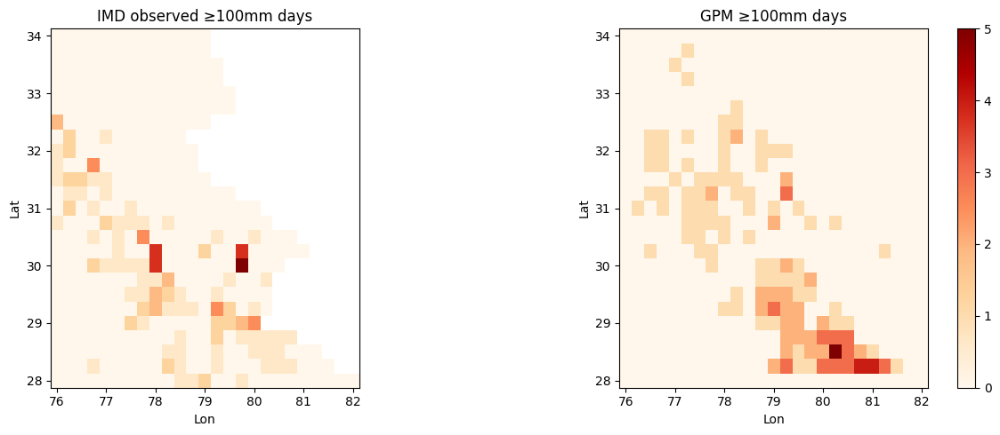

In [ ]:
import os, glob, shutil, time
import numpy as np, pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

src = "/content/drive/MyDrive/GPM_2025"
dst = "/content/gpm_local"; os.makedirs(dst, exist_ok=True)
files = sorted(glob.glob(src+"/*.nc4"))
ok, failed = 0, []
for f in files:
    d = os.path.join(dst, os.path.basename(f))
    if os.path.exists(d) and os.path.getsize(d) > 20_000_000:
        ok += 1; continue
    good = False
    for _ in range(3):
        try: shutil.copyfile(f,d); good=True; break
        except Exception: time.sleep(3)
    ok += good
    if not good: failed.append(os.path.basename(f))
print(f"GPM local: {ok}/{len(files)} | failed {len(failed)}")

latc = 28.0+0.25*np.arange(25); lonc = 76.0+0.25*np.arange(25)
stack=[]
for f in sorted(glob.glob(dst+"/*.nc4")):
    with xr.open_dataset(f) as ds:
        v=[v for v in ds.data_vars if 'precip' in v.lower()][0]
        a=ds[v]
        for d in list(a.dims):
            if a.sizes[d]==1: a=a.isel({d:0})
        latdim=[d for d in a.dims if 'lat' in d][0]; londim=[d for d in a.dims if 'lon' in d][0]
        a=a.sortby(latdim).sortby(londim)
        crop=a.sel({latdim:slice(28,34), londim:slice(76,82)}).astype('float32')
        stack.append(crop.interp({latdim:latc, londim:lonc}).values)
gpm=np.asarray(stack); print("GPM stack:", gpm.shape)
gpm_count=(gpm>=100).sum(axis=0)

tm = pd.read_csv('/content/terrain_0p25_himalaya.csv')
imd = pd.read_csv('/content/imd_window.csv')
df = tm.merge(imd, on=['lat','lon'], how='inner')
grec=[]
for j in range(25):
    for i in range(25):
        grec.append(dict(lat=round(28.0+0.25*j,2), lon=round(76.0+0.25*i,2), gpm_count=int(gpm_count[j,i])))
df = df.merge(pd.DataFrame(grec), on=['lat','lon'], how='inner')
df['imd_has'] = (df.imd_count>=1).astype(int).where(df.imd_observed==1)
df['gpm_has'] = (df.gpm_count>=1).astype(int)
df.to_csv('/content/master_0p25.csv', index=False)
df.to_csv('/content/drive/MyDrive/master_0p25_himalaya.csv', index=False)
print("master saved:", df.shape)

sub = df[df.imd_observed==1].copy()
print("\n'ever>=100mm' agreement (imd-observed cells): %.1f %%" % (100*(sub.imd_has==sub.gpm_has).mean()))
print(pd.crosstab(sub.imd_has, sub.gpm_has))
print("Pearson r(count):", round(np.corrcoef(sub.imd_count, sub.gpm_count)[0,1], 3))

def bands(d, col, has, bins, labels):
    dd=d.copy(); dd['b']=pd.cut(dd[col], bins=bins, labels=labels)
    g=dd.groupby('b',observed=False).agg(n=(col,'size'), k=(has,'sum')); g['pct']=(100*g.k/g.n).round(1); return g

eb=[0,500,1000,2000,4000,9000]; el=['<500','500-1000','1000-2000','2000-4000','>4000']
gi=bands(df[df.imd_observed==1],'elev_mean','imd_has',eb,el); gg=bands(df,'elev_mean','gpm_has',eb,el)
print("\nElevation bands (IMD valid vs GPM all):")
print(pd.DataFrame({'IMD_n':gi.n,'IMD_pct':gi.pct,'GPM_n':gg.n,'GPM_pct':gg.pct}).to_string())

obs = imd['imd_observed'].values.reshape(25,25); cnt_map = imd['imd_count'].values.reshape(25,25)
imd_map = np.where(obs==1, cnt_map, np.nan)
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].pcolormesh(lonc,latc,imd_map,cmap='OrRd',shading='auto'); axes[0].set_title('IMD observed ≥100mm days')
im=axes[1].pcolormesh(lonc,latc,gpm_count,cmap='OrRd',shading='auto'); axes[1].set_title('GPM ≥100mm days')
for ax in axes:
    ax.set_xlabel('Lon'); ax.set_ylabel('Lat'); ax.set_aspect(1/np.cos(np.radians(31)))
plt.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()

In [ ]:
# CELL D — ERA5 daily features per 0.25° cell (save to /content + Drive)
import os, glob
import numpy as np
import xarray as xr

files = glob.glob('/content/*.nc')
files = [f for f in sorted(files) if 'era' in os.path.basename(f).lower()]
assert files, "ERA5 not found — re-upload era5 2025.nc"
ds = xr.open_dataset(files[0])

latd = [d for d in ds.dims if d.upper().startswith('LAT')][0]
lond = [d for d in ds.dims if d.upper().startswith('LON')][0]
td   = [d for d in ds.dims if d.upper().startswith('TIME')][0]

latc = 28.0 + 0.25*np.arange(25)
lonc = 76.0 + 0.25*np.arange(25)

def cropvar(v):
    a = ds[v].astype('float32').sortby(latd).sortby(lond)
    return a.interp({latd: latc, lond: lonc}).values   # (3672, 25, 25)

# derived variables
ws    = np.hypot(cropvar('u10'), cropvar('v10'))       # wind speed m/s
tempC = cropvar('t2m') - 273.15                        # °C
press = cropvar('sp') / 100.0                          # hPa
tcwv  = cropvar('tcwv')                                # kg/m2

# hourly -> daily (assumes continuous hourly order for 153 days)
DAYS, H = 153, 24
def daily(x):
    return x.reshape(DAYS, H, 25, 25).mean(axis=1)

ws_d, t_d, p_d, c_d = daily(ws), daily(tempC), daily(press), daily(tcwv)
print("daily arrays:", ws_d.shape, "(expect 153,25,25)")

for name, arr in [("wind", ws_d), ("temp", t_d), ("press", p_d), ("tcwv", c_d)]:
    print(f"{name:6s}: min {arr.min():.1f} | max {arr.max():.1f} | mean {arr.mean():.1f}")

np.savez('/content/era5_window_daily.npz',
         wind=ws_d.astype('float32'), temp=t_d.astype('float32'),
         press=p_d.astype('float32'), tcwv=c_d.astype('float32'))
np.savez('/content/drive/MyDrive/era5_window_daily.npz',
         wind=ws_d.astype('float32'), temp=t_d.astype('float32'),
         press=p_d.astype('float32'), tcwv=c_d.astype('float32'))
print("saved era5_window_daily.npz")

IndexError: list index out of range

In [ ]:
import os, glob
import numpy as np
import xarray as xr

files = sorted(glob.glob('/content/*.nc'))
files = [f for f in files if 'era' in os.path.basename(f).lower()]
assert files, "ERA5 not found — re-upload era5 2025.nc"
ds = xr.open_dataset(files[0])
print("dims:", list(ds.dims))
print("vars:", list(ds.data_vars))

latd = [d for d in ds.dims if 'LAT' in d.upper()][0]
lond = [d for d in ds.dims if 'LON' in d.upper()][0]
td   = [d for d in ds.dims if 'TIME' in d.upper()][0]   # catches valid_time / time / TIME
print("using:", td, "|", latd, "|", lond)

latc = 28.0 + 0.25*np.arange(25)
lonc = 76.0 + 0.25*np.arange(25)

def cropvar(v):
    a = ds[v].astype('float32').sortby(latd).sortby(lond)
    order = [x for x in [td, latd, lond] if x in a.dims]
    a = a.transpose(*order)                              # force (time, lat, lon)
    return a.interp({latd: latc, lond: lonc}).values

ws    = np.hypot(cropvar('u10'), cropvar('v10'))         # wind speed m/s
tempC = cropvar('t2m') - 273.15                          # °C
press = cropvar('sp') / 100.0                            # hPa
tcwv  = cropvar('tcwv')                                  # kg/m2

print("hourly shape:", ws.shape, "(expect 3672, 25, 25)")
assert ws.shape == (3672, 25, 25), f"unexpected ERA5 shape {ws.shape} — paste this"

DAYS, H = 153, 24
wind_d  = ws.reshape(DAYS, H, 25, 25).mean(axis=1).astype('float32')
temp_d  = tempC.reshape(DAYS, H, 25, 25).mean(axis=1).astype('float32')
press_d = press.reshape(DAYS, H, 25, 25).mean(axis=1).astype('float32')
tcwv_d  = tcwv.reshape(DAYS, H, 25, 25).mean(axis=1).astype('float32')

for name, arr in [('wind', wind_d), ('temp', temp_d), ('press', press_d), ('tcwv', tcwv_d)]:
    print(f"{name:6s}: min {arr.min():.2f} | max {arr.max():.1f} | mean {arr.mean():.2f}")

np.savez('/content/era5_window_daily.npz',
         wind=wind_d, temp=temp_d, press=press_d, tcwv=tcwv_d)
np.savez('/content/drive/MyDrive/era5_window_daily.npz',
         wind=wind_d, temp=temp_d, press=press_d, tcwv=tcwv_d)
print("saved era5_window_daily.npz")

dims: ['valid_time', 'latitude', 'longitude']
vars: ['u10', 'v10', 't2m', 'sp', 'tcwv']
using: valid_time | latitude | longitude
hourly shape: (3672, 25, 25) (expect 3672, 25, 25)
wind  : min 0.25 | max 6.8 | mean 1.61
temp  : min -10.81 | max 38.6 | mean 15.94
press : min 518.58 | max 996.2 | mean 738.87
tcwv  : min 1.08 | max 77.9 | mean 27.26
saved era5_window_daily.npz


In [ ]:
# CELL E — build cell-day master table (imd + gpm + era5 + dem)
import os, glob
import numpy as np, pandas as pd

dates = [d.strftime('%Y-%m-%d') for d in pd.date_range('2025-05-01', periods=153, freq='D')]

# IMD daily (153,25,25)
if 'win' in globals() and 'TIME' in globals() and win.sizes[TIME] == 153:
    imd_day = win.values.astype('float32')
else:
    import xarray as xr
    files = sorted(glob.glob('/content/*.nc'))
    files = [f for f in files if 'RF25' in os.path.basename(f)] or files
    ds = xr.open_dataset(files[0])
    TIME=[d for d in ds.dims if d.upper().startswith('TIME')][0]
    LAT=[d for d in ds.dims if d.upper().startswith('LAT')][0]
    LON=[d for d in ds.dims if d.upper().startswith('LON')][0]
    VARR=[v for v in ds.data_vars if v.upper() in ('RAINFALL','RAIN','RF','PRECIP','PRECIPITATION')][0]
    tmp = ds[VARR].astype('float32').sortby(LAT).sortby(LON)
    win = tmp.sel({TIME: slice('2025-05-01','2025-09-30'), LAT: slice(28,34), LON: slice(76,82)})
    imd_day = win.values.astype('float32')
print("IMD daily:", imd_day.shape)

# GPM daily (153,25,25)
if 'gpm' in globals() and getattr(gpm, 'shape', None) == (153,25,25):
    gpm_day = gpm.astype('float32')
else:
    import xarray as xr
    latc = 28.0+0.25*np.arange(25); lonc = 76.0+0.25*np.arange(25)
    st=[]
    for f in sorted(glob.glob('/content/gpm_local/*.nc4')):
        with xr.open_dataset(f) as ds:
            v=[v for v in ds.data_vars if 'precip' in v.lower()][0]; a=ds[v]
            for d in list(a.dims):
                if a.sizes[d]==1: a=a.isel({d:0})
            latdim=[d for d in a.dims if 'lat' in d][0]; londim=[d for d in a.dims if 'lon' in d][0]
            a=a.sortby(latdim).sortby(londim)
            c=a.sel({latdim:slice(28,34), londim:slice(76,82)}).astype('float32')
            st.append(c.interp({latdim:latc, londim:lonc}).values)
    gpm_day = np.asarray(st, dtype='float32')
print("GPM daily:", gpm_day.shape)

# ERA5 daily
e = np.load('/content/era5_window_daily.npz')
wind, temp, press, tcwv = e['wind'], e['temp'], e['press'], e['tcwv']
print("ERA5 daily:", wind.shape)

# terrain static
tm = pd.read_csv('/content/terrain_0p25_himalaya.csv')

# flatten to cell-day rows
latc = 28.0+0.25*np.arange(25); lonc = 76.0+0.25*np.arange(25)
rows=[]
for d in range(153):
    for j in range(25):
        for i in range(25):
            rows.append(dict(date=dates[d], lat=round(latc[j],2), lon=round(lonc[i],2),
                             imd=float(imd_day[d,j,i]), gpm=float(gpm_day[d,j,i]),
                             wind=float(wind[d,j,i]), temp=float(temp[d,j,i]),
                             press=float(press[d,j,i]), tcwv=float(tcwv[d,j,i])))
master = pd.DataFrame(rows).merge(tm, on=['lat','lon'], how='left')
print("master:", master.shape, "| columns:", master.columns.tolist())
print("missing % per column:\n", (master.isna().mean()*100).round(1).to_string())
master.to_csv('/content/cell_day_master.csv', index=False)
master.to_csv('/content/drive/MyDrive/cell_day_master.csv', index=False)
print("saved cell_day_master.csv (Drive)")

IMD daily: (153, 25, 25)
GPM daily: (153, 25, 25)
ERA5 daily: (153, 25, 25)
master: (95625, 12) | columns: ['date', 'lat', 'lon', 'imd', 'gpm', 'wind', 'temp', 'press', 'tcwv', 'elev_mean', 'slope_median', 'slope_p90']
missing % per column:
 date             0.0
lat              0.0
lon              0.0
imd             33.4
gpm             15.4
wind             0.0
temp             0.0
press            0.0
tcwv             0.0
elev_mean        0.0
slope_median     0.0
slope_p90        0.0
saved cell_day_master.csv (Drive)


In [ ]:
# CELL F — ML BASELINE: does multi-source fusion beat single sources?
import pandas as pd, numpy as np

df = pd.read_csv('/content/cell_day_master.csv')
df['date'] = pd.to_datetime(df['date'])
df['doy'] = df['date'].dt.dayofyear
df['doy_sin'] = np.sin(2*np.pi*df['doy']/365)
df['doy_cos'] = np.cos(2*np.pi*df['doy']/365)

d = df[df['imd'].notna()].copy()
d['y'] = (d['imd'] >= 100).astype(int)
print("usable rows:", len(d), "| positives:", int(d['y'].sum()), f"({100*d['y'].mean():.2f}%)")

dates = sorted(d['date'].unique())
split = dates[122]
tr = d[d['date'] < split]; te = d[d['date'] >= split]
print("train:", len(tr), "| test:", len(te), "| test positives:", int(te['y'].sum()))
assert te['y'].sum() > 0, "no positives in test — tell me, I'll adjust the split"

FEATS_GPM = ['gpm']
FEATS_ERA = ['wind','temp','press','tcwv']
FEATS_ALL = ['gpm','wind','temp','press','tcwv','elev_mean','slope_median','doy_sin','doy_cos']

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

def run(feats):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced'))
    m.fit(tr[feats], tr['y'])
    p = m.predict_proba(te[feats])[:,1]
    return average_precision_score(te['y'], p), roc_auc_score(te['y'], p)

for name, feats in [('GPM only', FEATS_GPM), ('ERA5 only', FEATS_ERA), ('ALL', FEATS_ALL)]:
    pr, roc = run(feats)
    print(f"{name:10s}: PR-AUC {pr:.3f} | ROC-AUC {roc:.3f}")

m = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4)
m.fit(tr[FEATS_ALL], tr['y'])
p = m.predict_proba(te[FEATS_ALL])[:,1]
print(f"{'GBM ALL':10s}: PR-AUC {average_precision_score(te['y'],p):.3f} | ROC-AUC {roc_auc_score(te['y'],p):.3f}")
imp = pd.Series(m.feature_importances_, index=FEATS_ALL).sort_values(ascending=False)
print("\nGBM feature importance:\n", imp.to_string())

usable rows: 63648 | positives: 150 (0.24%)
train: 50752 | test: 12896 | test positives: 34


ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
# CELL F (v2) — ML BASELINE: does multi-source fusion beat single sources?
import pandas as pd, numpy as np

df = pd.read_csv('/content/cell_day_master.csv')
df['date'] = pd.to_datetime(df['date'])
df['doy'] = df['date'].dt.dayofyear
df['doy_sin'] = np.sin(2*np.pi*df['doy']/365)
df['doy_cos'] = np.cos(2*np.pi*df['doy']/365)

d = df[df['imd'].notna()].copy()
d['y'] = (d['imd'] >= 100).astype(int)
print("usable rows:", len(d), "| positives:", int(d['y'].sum()), f"({100*d['y'].mean():.2f}%)")

dates = sorted(d['date'].unique()); split = dates[122]
tr = d[d['date'] < split]; te = d[d['date'] >= split]
print("train:", len(tr), "| test:", len(te), "| test positives:", int(te['y'].sum()))
assert te['y'].sum() > 0

FEATS_GPM = ['gpm']
FEATS_ERA = ['wind','temp','press','tcwv']
FEATS_ALL = ['gpm','wind','temp','press','tcwv','elev_mean','slope_median','doy_sin','doy_cos']

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

def run(feats):
    m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                      LogisticRegression(max_iter=1000, class_weight='balanced'))
    m.fit(tr[feats], tr['y'])
    p = m.predict_proba(te[feats])[:,1]
    return average_precision_score(te['y'], p), roc_auc_score(te['y'], p)

for name, feats in [('GPM only', FEATS_GPM), ('ERA5 only', FEATS_ERA), ('ALL', FEATS_ALL)]:
    pr, roc = run(feats)
    print(f"{name:10s}: PR-AUC {pr:.3f} | ROC-AUC {roc:.3f}")

m = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4)
m.fit(tr[FEATS_ALL], tr['y'])          # HistGB handles NaN natively
p = m.predict_proba(te[FEATS_ALL])[:,1]
print(f"{'GBM ALL':10s}: PR-AUC {average_precision_score(te['y'],p):.3f} | ROC-AUC {roc_auc_score(te['y'],p):.3f}")
imp = pd.Series(m.feature_importances_, index=FEATS_ALL).sort_values(ascending=False)
print("\nGBM feature importance:\n", imp.to_string())

usable rows: 63648 | positives: 150 (0.24%)
train: 50752 | test: 12896 | test positives: 34
GPM only  : PR-AUC 0.051 | ROC-AUC 0.876
ERA5 only : PR-AUC 0.010 | ROC-AUC 0.837
ALL       : PR-AUC 0.021 | ROC-AUC 0.874
GBM ALL   : PR-AUC 0.041 | ROC-AUC 0.923


AttributeError: 'HistGradientBoostingClassifier' object has no attribute 'feature_importances_'

In [ ]:
if 'm' in globals():
    from sklearn.inspection import permutation_importance
    r = permutation_importance(m, te[FEATS_ALL], te['y'], n_repeats=10,
                               scoring='roc_auc', random_state=0)
    imp = pd.Series(r.importances_mean, index=FEATS_ALL).sort_values(ascending=False)
    print(imp.to_string())
else:
    print("re-run Cell F up to the GBM fit first")

tcwv            0.238151
temp            0.132899
elev_mean       0.067830
gpm             0.053530
press           0.045905
wind            0.022142
slope_median    0.005737
doy_sin         0.000000
doy_cos         0.000000


In [ ]:
# CELL G — LEAD-1 FORECAST: day(t) features -> extreme on day(t+1)
import pandas as pd, numpy as np

df = pd.read_csv('/content/cell_day_master.csv')
df['date'] = pd.to_datetime(df['date'])
df['doy'] = df.date.dt.dayofyear
df['doy_sin'] = np.sin(2*np.pi*df.doy/365)
df['doy_cos'] = np.cos(2*np.pi*df.doy/365)

d = df[df['imd'].notna()].copy()
d['y'] = (d['imd'] >= 100).astype(int)
d = d.sort_values(['lat','lon','date'])
d['press_tend'] = d.groupby(['lat','lon'])['press'].diff()   # ΔP/Δt per day

# target = tomorrow's extreme (per cell)
d['y_next'] = d.groupby(['lat','lon'])['y'].shift(-1)
d['target_date'] = d['date'] + pd.Timedelta(days=1)
d = d.dropna(subset=['y_next']).copy()
d['y_next'] = d['y_next'].astype(int)
print("rows:", len(d), "| next-day positives:", int(d['y_next'].sum()), f"({100*d['y_next'].mean():.2f}%)")

split = pd.Timestamp('2025-08-31')     # target dates >= this go to TEST
tr = d[d['target_date'] < split]
te = d[d['target_date'] >= split]
print("train:", len(tr), "| test:", len(te), "| test positives:", int(te['y_next'].sum()))
assert te['y_next'].sum() > 0

FEATS_GPM = ['gpm']
FEATS_ERA = ['wind','temp','press','press_tend','tcwv']
FEATS_ALL = ['gpm','wind','temp','press','press_tend','tcwv','elev_mean','slope_median','doy_sin','doy_cos']

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

def run(feats):
    m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                      LogisticRegression(max_iter=1000, class_weight='balanced'))
    m.fit(tr[feats], tr['y_next'])
    p = m.predict_proba(te[feats])[:,1]
    return average_precision_score(te['y_next'], p), roc_auc_score(te['y_next'], p)

for name, feats in [('GPM only(t)', FEATS_GPM), ('ERA5 only(t)', FEATS_ERA), ('ALL(t)', FEATS_ALL)]:
    pr, roc = run(feats)
    print(f"{name:12s}: PR-AUC {pr:.3f} | ROC-AUC {roc:.3f}")

m = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4)
m.fit(tr[FEATS_ALL], tr['y_next'])
p = m.predict_proba(te[FEATS_ALL])[:,1]
print(f"{'GBM ALL(t)':12s}: PR-AUC {average_precision_score(te['y_next'],p):.3f} | ROC-AUC {roc_auc_score(te['y_next'],p):.3f}")

from sklearn.inspection import permutation_importance
r = permutation_importance(m, te[FEATS_ALL], te['y_next'], n_repeats=10, scoring='roc_auc', random_state=0)
print("\npermutation importance (GBM):\n",
      pd.Series(r.importances_mean, index=FEATS_ALL).sort_values(ascending=False).to_string())

rows: 63232 | next-day positives: 150 (0.24%)
train: 50336 | test: 12896 | test positives: 34
GPM only(t) : PR-AUC 0.042 | ROC-AUC 0.899
ERA5 only(t): PR-AUC 0.018 | ROC-AUC 0.827
ALL(t)      : PR-AUC 0.035 | ROC-AUC 0.856
GBM ALL(t)  : PR-AUC 0.005 | ROC-AUC 0.693

permutation importance (GBM):
 press           0.209573
tcwv            0.168114
elev_mean       0.030770
temp            0.025640
slope_median    0.022215
wind            0.013490
press_tend      0.009544
doy_sin         0.000000
doy_cos         0.000000
gpm            -0.038372


In [ ]:
# CELL H — STAGE-1: do ERA5 features flag tomorrow's REGIONAL extreme day?
import pandas as pd, numpy as np

df = pd.read_csv('/content/cell_day_master.csv')
df['date'] = pd.to_datetime(df['date'])

day = df.groupby('date').agg(
    imd=('imd','mean'), gpm=('gpm','mean'), wind=('wind','mean'),
    temp=('temp','mean'), press=('press','mean'), tcwv=('tcwv','mean')).sort_index()
day['press_tend'] = day['press'].diff()

thr = day['imd'].quantile(0.95)
day['extreme'] = (day['imd'] >= thr).astype(int)
day['y_next'] = day['extreme'].shift(-1)
day = day.dropna(subset=['y_next']).copy()
day['y_next'] = day['y_next'].astype(int)
print(f"threshold = {thr:.2f} mm/day | days = {len(day)} | next-day extremes = {int(day['y_next'].sum())}")

day['target_date'] = day.index + pd.Timedelta(days=1)
split = pd.Timestamp('2025-08-01')
tr = day[day['target_date'] < split]
te = day[day['target_date'] >= split]
print("train days:", len(tr), "| test days:", len(te), "| test extremes:", int(te['y_next'].sum()))

# interpretive table: what does the day BEFORE an extreme look like?
print("\nDay-before means (next-day extreme vs not):")
for c in ['tcwv','gpm','press_tend','wind','temp','press']:
    a = day.loc[day['y_next']==1, c].mean()
    b = day.loc[day['y_next']==0, c].mean()
    print(f"  {c:10s}: extreme-eve {a:9.2f} | normal {b:9.2f}")

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

def run(feats):
    m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                      LogisticRegression(max_iter=1000, class_weight='balanced'))
    m.fit(tr[feats], tr['y_next'])
    p = m.predict_proba(te[feats])[:,1]
    return average_precision_score(te['y_next'], p), roc_auc_score(te['y_next'], p)

print("\nModel comparisons (directional — tiny sample):")
for name, feats in [('GPM(t)', ['gpm']),
                    ('TCWV(t)', ['tcwv']),
                    ('ERA5(t)', ['tcwv','press','press_tend','temp','wind']),
                    ('ALL(t)', ['gpm','tcwv','press','press_tend','temp','wind'])]:
    if te['y_next'].sum() > 0:
        pr, roc = run(feats)
        print(f"{name:10s}: PR-AUC {pr:.3f} | ROC-AUC {roc:.3f}")
    else:
        print(f"{name:10s}: no positives in test")

threshold = 19.67 mm/day | days = 152 | next-day extremes = 8
train days: 91 | test days: 61 | test extremes: 7

Day-before means (next-day extreme vs not):
  tcwv      : extreme-eve     34.32 | normal     26.91
  gpm       : extreme-eve     20.52 | normal      4.74
  press_tend: extreme-eve     -0.39 | normal      0.01
  wind      : extreme-eve      1.69 | normal      1.61
  temp      : extreme-eve     15.35 | normal     15.99
  press     : extreme-eve    738.33 | normal    738.90

Model comparisons (directional — tiny sample):
GPM(t)    : PR-AUC 0.769 | ROC-AUC 0.955
TCWV(t)   : PR-AUC 0.255 | ROC-AUC 0.788
ERA5(t)   : PR-AUC 0.483 | ROC-AUC 0.802
ALL(t)    : PR-AUC 0.815 | ROC-AUC 0.968


In [ ]:
import pandas as pd, numpy as np
df = pd.read_csv('/content/cell_day_master.csv'); df['date'] = pd.to_datetime(df['date'])
day = df.groupby('date').agg(imd=('imd','mean'), gpm=('gpm','mean'), wind=('wind','mean'),
                             temp=('temp','mean'), press=('press','mean'), tcwv=('tcwv','mean')).sort_index()
day['press_tend'] = day['press'].diff()
day['imd_max'] = df.groupby('date')['imd'].max().values
day['ext']    = (day['imd'] >= day['imd'].quantile(0.95)).astype(int)         # frequency
day['extmax'] = (day['imd_max'] >= day['imd_max'].quantile(0.95)).astype(int) # intensity

FEATS = ['gpm','tcwv','press','press_tend','wind','temp']

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import average_precision_score, roc_auc_score

def loo_score(ycol):
    day[ycol+'_next'] = day[ycol].shift(-1)
    sub = day[FEATS+[ycol+'_next']].dropna()
    X, yy = sub[FEATS].values, sub[ycol+'_next'].values
    probs = np.zeros(len(yy)); truth = np.zeros(len(yy))
    for tr_i, te_i in LeaveOneOut().split(X):
        m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                          LogisticRegression(max_iter=1000, class_weight='balanced'))
        m.fit(X[tr_i], yy[tr_i]); probs[te_i] = m.predict_proba(X[te_i])[:,1]; truth[te_i] = yy[te_i]
    return average_precision_score(truth, probs), roc_auc_score(truth, probs)

for col in ['ext','extmax']:
    pr, roc = loo_score(col)
    print(f"regional next-day {col:7s}: PR-AUC {pr:.3f} | ROC-AUC {roc:.3f}")

regional next-day ext    : PR-AUC 0.671 | ROC-AUC 0.948
regional next-day extmax : PR-AUC 0.291 | ROC-AUC 0.791


days=152 | next-day extremes=8 | random baseline PR-AUC = 0.053
LOO GPM(persistence): PR-AUC 0.714 (13.6x random) | ROC-AUC 0.966
LOO ERA5            : PR-AUC 0.498 (9.5x random) | ROC-AUC 0.873
LOO FUSION          : PR-AUC 0.671 (12.8x random) | ROC-AUC 0.948

FUSION beats random 12.8x and beats persistence 0.94x

If we raise the alarm on the top-N scored days:
  top  5 -> recall 4/8 (50%) | precision 80% | false alarms 1
  top 10 -> recall 5/8 (62%) | precision 50% | false alarms 5
  top 15 -> recall 7/8 (88%) | precision 47% | false alarms 8
  top 20 -> recall 7/8 (88%) | precision 35% | false alarms 13
  top 25 -> recall 7/8 (88%) | precision 28% | false alarms 18


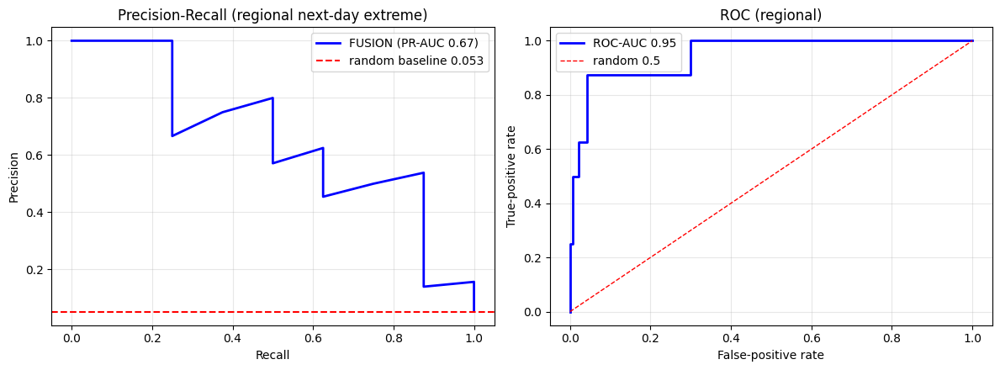


===== FINAL RESULTS TABLE =====
cell-level  (lead-1, temp split): GPM PR-AUC 0.042 vs baseline 0.0024 (~17x random)
regional    (lead-1, LOO)       : FUSION PR-AUC 0.671 vs baseline 0.053 (~12.8x) | ROC 0.948


In [ ]:
# CELL I — FINAL RESULTS: baselines, skill, honest headline, PR/ROC curves
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/cell_day_master.csv'); df['date'] = pd.to_datetime(df['date'])
day = df.groupby('date').agg(imd=('imd','mean'), gpm=('gpm','mean'), wind=('wind','mean'),
                             temp=('temp','mean'), press=('press','mean'), tcwv=('tcwv','mean')).sort_index()
day['press_tend'] = day['press'].diff()
day['ext'] = (day['imd'] >= day['imd'].quantile(0.95)).astype(int)
day['y_next'] = day['ext'].shift(-1)
day = day.dropna(subset=['y_next']).copy()
day['y_next'] = day['y_next'].astype(int)

FEATS_ALL = ['gpm','tcwv','press','press_tend','wind','temp']
FEATS_GPM = ['gpm']
FEATS_ERA = ['tcwv','press','press_tend','wind','temp']

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, roc_curve

def loo(feats):
    X = day[feats].values; y = day['y_next'].values
    probs = np.zeros(len(y))
    for tr_i, te_i in LeaveOneOut().split(X):
        m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                          LogisticRegression(max_iter=1000, class_weight='balanced'))
        m.fit(X[tr_i], y[tr_i]); probs[te_i] = m.predict_proba(X[te_i])[:,1]
    return probs

prev = day['y_next'].mean()
print(f"days={len(day)} | next-day extremes={int(day['y_next'].sum())} | random baseline PR-AUC = {prev:.3f}")

row = {}
for name, feats in [('GPM(persistence)', FEATS_GPM), ('ERA5', FEATS_ERA), ('FUSION', FEATS_ALL)]:
    p = loo(feats)
    pr, roc = average_precision_score(day['y_next'], p), roc_auc_score(day['y_next'], p)
    row[name] = (pr, roc)
    print(f"LOO {name:16s}: PR-AUC {pr:.3f} ({pr/prev:.1f}x random) | ROC-AUC {roc:.3f}")

pf = row['FUSION'][0]; pg = row['GPM(persistence)'][0]
print(f"\nFUSION beats random {pf/prev:.1f}x and beats persistence {pf/pg:.2f}x")

# honest headline: flag the top-N scored days
p = loo(FEATS_ALL); y = day['y_next'].values
order = np.argsort(-p)
print("\nIf we raise the alarm on the top-N scored days:")
for N in [5, 10, 15, 20, 25]:
    f = order[:N]; caught = int(y[f].sum())
    print(f"  top {N:2d} -> recall {caught}/{int(y.sum())} ({100*caught/int(y.sum()):.0f}%) | precision {100*caught/N:.0f}% | false alarms {N-caught}")

prec, rec, _ = precision_recall_curve(y, p)
fpr, tpr, _ = roc_curve(y, p)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(rec, prec, 'b-', lw=2, label=f'FUSION (PR-AUC {pf:.2f})')
axes[0].axhline(prev, color='r', ls='--', label=f'random baseline {prev:.3f}')
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall (regional next-day extreme)')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(fpr, tpr, 'b-', lw=2, label=f'ROC-AUC {row["FUSION"][1]:.2f}')
axes[1].plot([0,1],[0,1], 'r--', lw=1, label='random 0.5')
axes[1].set_xlabel('False-positive rate'); axes[1].set_ylabel('True-positive rate')
axes[1].set_title('ROC (regional)'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("\n===== FINAL RESULTS TABLE =====")
print(f"cell-level  (lead-1, temp split): GPM PR-AUC 0.042 vs baseline 0.0024 (~17x random)")
print(f"regional    (lead-1, LOO)       : FUSION PR-AUC {pf:.3f} vs baseline {prev:.3f} (~{pf/prev:.1f}x) | ROC {row['FUSION'][1]:.3f}")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

folder = "/content/drive/MyDrive/GPM_2025"

if os.path.exists(folder):
    files = os.listdir(folder)
    print("GPM folder found!")
    print("Number of items:", len(files))
    print("\nFirst 15 items:")
    for f in files[:15]:
        print(f)
else:
    print("GPM folder not found at:", folder)
    print("\nFolders in MyDrive:")
    print(os.listdir("/content/drive/MyDrive")[:30])

Mounted at /content/drive
GPM folder found!
Number of items: 153

First 15 items:
3B-DAY.MS.MRG.3IMERG.20250501-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250504-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250506-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250505-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250508-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250503-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250502-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250507-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250512-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250515-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250509-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250516-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250511-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250519-S000000-E235959.V07B.nc4
3B-DAY.MS.MRG.3IMERG.20250521-S000000-E235959.V07B.nc4


In [ ]:
# CELL J — BERNOULLI + PEARSON FOUNDATIONS
# No new ML model; training-period diagnostics only.

from pathlib import Path
import numpy as np
import pandas as pd

paths = [
    Path("/content/cell_day_master.csv"),
    Path("/content/drive/MyDrive/cell_day_master.csv"),
]
path = next((p for p in paths if p.exists()), None)
assert path is not None, "cell_day_master.csv not found. Mount Drive first."

df = pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"], errors="raise")

required = ["date", "lat", "lon", "imd", "tcwv", "temp", "press", "wind"]
assert set(required).issubset(df.columns), "Required columns are missing."
assert not df.duplicated(["date", "lat", "lon"]).any(), \
    "Duplicate cell-days found: resolve before continuing."

cutoff = pd.Timestamp("2025-08-31")
train = df.loc[df["date"] < cutoff].copy()
assert len(train) > 0, "No training-period rows."

numeric = ["imd", "tcwv", "temp", "press", "wind"]
assert not np.isinf(train[numeric].to_numpy(dtype=float)).any(), \
    "Infinite values found."
assert not (train["imd"].dropna() < 0).any(), \
    "Negative IMD rainfall found: inspect before labelling."

# ---------- A. Bernoulli target ----------
labelled = train.loc[train["imd"].notna()].copy()
assert len(labelled) > 0, "No observed IMD training rows."

y = (labelled["imd"] >= 100.0).astype(int).to_numpy()
p_hat = float(y.mean())

# Constant-probability baseline fitted on training data.
# This is NOT a trained fusion model or a test-set score.
eps = 1e-12
p_safe = np.clip(p_hat, eps, 1 - eps)
null_loss = -np.mean(
    y * np.log(p_safe) + (1 - y) * np.log(1 - p_safe)
)

print("===== BERNOULLI TARGET: TRAINING DATA =====")
print(f"Period: {train.date.min().date()} to {train.date.max().date()}")
print(f"Labelled cell-days: {len(y):,}")
print(f"Extreme cell-days: {int(y.sum()):,}")
print(f"Observed event prevalence: {100 * p_hat:.4f}%")
print(f"Constant baseline probability: {p_hat:.6f}")
print(f"Baseline training cross-entropy: {null_loss:.6f}")
print("Missing IMD rows excluded:", int(train.imd.isna().sum()))

# ---------- B. Fixed observed-cell support ----------
n_days = train["date"].nunique()
coverage = train.groupby(["lat", "lon"])["imd"].count()
complete_cells = coverage.loc[coverage == n_days].reset_index()[["lat", "lon"]]

assert len(complete_cells) > 1, "Too few fully observed cells."

common = train.merge(
    complete_cells, on=["lat", "lon"], how="inner",
    validate="many_to_one"
)

# Both rainfall and ERA5 averages use the SAME cells.
daily = common.groupby("date")[numeric].mean().sort_index()

def pearson_pair(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    mask = np.isfinite(a) & np.isfinite(b)
    a, b = a[mask], b[mask]

    if len(a) < 3 or np.std(a) == 0 or np.std(b) == 0:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])

rows = []
for feature in ["tcwv", "temp", "press", "wind"]:
    temporal_r = pearson_pair(daily["imd"], daily[feature])

    spatial_values = [
        pearson_pair(group["imd"], group[feature])
        for _, group in common.groupby("date", sort=True)
    ]
    spatial_values = np.asarray(spatial_values, dtype=float)
    usable = spatial_values[np.isfinite(spatial_values)]

    rows.append({
        "feature": feature,
        "temporal_r": temporal_r,
        "mean_daily_spatial_r": usable.mean() if len(usable) else np.nan,
        "days_with_spatial_r": len(usable),
    })

result = pd.DataFrame(rows)

print("\n===== PEARSON: DIFFERENT QUESTIONS =====")
print("Fixed observed cells:", len(complete_cells))
print("Training days:", n_days)
print(result.round(3).to_string(index=False))
print("\nSpatial results here use ALL training days,")
print("not only the eight previously selected extreme days.")

result.to_csv("/content/pearson_training_foundations.csv", index=False)
print("\nSaved: /content/pearson_training_foundations.csv")

===== BERNOULLI TARGET: TRAINING DATA =====
Period: 2025-05-01 to 2025-08-30
Labelled cell-days: 50,752
Extreme cell-days: 116
Observed event prevalence: 0.2286%
Constant baseline probability: 0.002286
Baseline training cross-entropy: 0.016182
Missing IMD rows excluded: 25498

===== PEARSON: DIFFERENT QUESTIONS =====
Fixed observed cells: 416
Training days: 122
feature  temporal_r  mean_daily_spatial_r  days_with_spatial_r
   tcwv       0.617                 0.053                  120
   temp       0.103                 0.038                  120
  press       0.028                 0.055                  120
   wind      -0.186                -0.077                  120

Spatial results here use ALL training days,
not only the eight previously selected extreme days.

Saved: /content/pearson_training_foundations.csv


In [ ]:
# CELL K — PREPROCESSING DIAGNOSTIC, NOT A NEW MODEL
from pathlib import Path
import numpy as np
import pandas as pd

paths = [
    Path("/content/cell_day_master.csv"),
    Path("/content/drive/MyDrive/cell_day_master.csv"),
]
path = next((p for p in paths if p.exists()), None)
assert path is not None, "Mount Drive or upload cell_day_master.csv."

df = pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"])

assert not df.duplicated(["date", "lat", "lon"]).any(), \
    "Duplicate cell-days found."

# ---------- 1. Calendar and grid ----------
actual_dates = pd.DatetimeIndex(df["date"].unique()).sort_values()
expected_dates = pd.date_range("2025-05-01", "2025-09-30")

print("===== CALENDAR / GRID =====")
print("Rows:", len(df))
print("Dates:", len(actual_dates))
print("Missing expected dates:",
      expected_dates.difference(actual_dates).strftime("%Y-%m-%d").tolist())
print("Unexpected dates:",
      actual_dates.difference(expected_dates).strftime("%Y-%m-%d").tolist())
print("Rows per date, min/max:",
      df.groupby("date").size().min(),
      df.groupby("date").size().max())

# ---------- 2. Is GPM missing only on the outer boundary? ----------
boundary = (
    df["lat"].isin([df.lat.min(), df.lat.max()]) |
    df["lon"].isin([df.lon.min(), df.lon.max()])
)

print("\n===== GPM MISSINGNESS =====")
for name, mask in [("Boundary", boundary), ("Interior", ~boundary)]:
    part = df.loc[mask]
    n_missing = int(part["gpm"].isna().sum())
    pct = 100 * n_missing / len(part) if len(part) else np.nan
    print(f"{name}: {n_missing

_IncompleteInputError: incomplete input (2096905179.py, line 45)

In [ ]:
# CELL K — CHECK GPM MISSINGNESS AND UNDEFINED CORRELATIONS
from pathlib import Path
import numpy as np
import pandas as pd

paths = [
    Path("/content/cell_day_master.csv"),
    Path("/content/drive/MyDrive/cell_day_master.csv")
]

path = next((p for p in paths if p.exists()), None)
assert path is not None, "Mount Drive or upload cell_day_master.csv."

df = pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"])

duplicates = df.duplicated(["date", "lat", "lon"]).sum()
assert duplicates == 0, "Duplicate cell-days found."

# 1. Calendar and grid
actual = pd.DatetimeIndex(df["date"].unique()).sort_values()
expected = pd.date_range("2025-05-01", "2025-09-30")
rows_per_day = df.groupby("date").size()

print("===== CALENDAR / GRID =====")
print("Rows:", len(df))
print("Dates:", len(actual))
print("Missing dates:", expected.difference(actual).tolist())
print("Unexpected dates:", actual.difference(expected).tolist())
print("Rows per date, min/max:",
      rows_per_day.min(), rows_per_day.max())

# 2. GPM missingness: boundary versus interior
boundary = (
    df["lat"].isin([df["lat"].min(), df["lat"].max()])
    | df["lon"].isin([df["lon"].min(), df["lon"].max()])
)

print("\n===== GPM MISSINGNESS =====")

for name, mask in [("Boundary", boundary), ("Interior", ~boundary)]:
    part = df.loc[mask]
    missing = int(part["gpm"].isna().sum())
    total = len(part)
    pct = 100 * missing / total if total else np.nan
    print(name, "| missing:", missing, "/", total,
          "| percent:", round(pct, 2))

cell_missing = df.groupby(["lat", "lon"])["gpm"].apply(
    lambda s: s.isna().mean()
)

fully_missing = int((cell_missing == 1).sum())
partly_missing = int(
    ((cell_missing > 0) & (cell_missing < 1)).sum()
)

print("Cells missing GPM every day:", fully_missing)
print("Cells with partial missingness:", partly_missing)

# 3. Investigate undefined training-day spatial correlations
train = df.loc[df["date"] < "2025-08-31"].copy()
n_days = train["date"].nunique()

coverage = train.groupby(["lat", "lon"])["imd"].count()
cells = coverage[coverage == n_days].reset_index()
cells = cells[["lat", "lon"]]

common = train.merge(cells, on=["lat", "lon"], how="inner")

print("\n===== UNDEFINED SPATIAL CORRELATIONS =====")

for feature in ["tcwv", "temp", "press", "wind"]:
    problems = []

    for date, group in common.groupby("date"):
        pair = group[["imd", feature]].replace(
            [np.inf, -np.inf], np.nan
        ).dropna()

        if len(pair) < 3:
            reason = "fewer than 3 valid pairs"
        elif pair["imd"].nunique() < 2:
            reason = "constant IMD rainfall"
        elif pair[feature].nunique() < 2:
            reason = "constant atmospheric variable"
        else:
            continue

        problems.append((date.strftime("%Y-%m-%d"), reason))

    print(feature, ":", problems)

print("\nDIAGNOSTIC COMPLETE — no data changed, no model trained.")

===== CALENDAR / GRID =====
Rows: 95625
Dates: 153
Missing dates: []
Unexpected dates: []
Rows per date, min/max: 625 625

===== GPM MISSINGNESS =====
Boundary | missing: 14688 / 14688 | percent: 100.0
Interior | missing: 0 / 80937 | percent: 0.0
Cells missing GPM every day: 96
Cells with partial missingness: 0

===== UNDEFINED SPATIAL CORRELATIONS =====
tcwv : [('2025-05-15', 'constant IMD rainfall'), ('2025-06-08', 'constant IMD rainfall')]
temp : [('2025-05-15', 'constant IMD rainfall'), ('2025-06-08', 'constant IMD rainfall')]
press : [('2025-05-15', 'constant IMD rainfall'), ('2025-06-08', 'constant IMD rainfall')]
wind : [('2025-05-15', 'constant IMD rainfall'), ('2025-06-08', 'constant IMD rainfall')]

DIAGNOSTIC COMPLETE — no data changed, no model trained.


In [ ]:
# CELL L — INSPECT ONE GPM FILE AND TEST CORRECTED ALIGNMENT
from pathlib import Path
import shutil
import numpy as np
import xarray as xr

folders = [
    Path("/content/gpm_local"),
    Path("/content/drive/MyDrive/GPM_2025")
]

source = None
for folder in folders:
    matches = sorted(folder.glob("*20250501-*.nc4"))
    if matches:
        source = matches[0]
        break

assert source is not None, (
    "GPM file for 2025-05-01 not found. Mount Drive

SyntaxError: unterminated string literal (detected at line 20) (338529036.py, line 20)

In [ ]:
# CELL L — INSPECT ONE GPM FILE AND TEST CORRECTED ALIGNMENT
from pathlib import Path
import shutil
import numpy as np
import xarray as xr

folders = [
    Path("/content/gpm_local"),
    Path("/content/drive/MyDrive/GPM_2025")
]

source = None
for folder in folders:
    matches = sorted(folder.glob("*20250501-*.nc4"))
    if matches:
        source = matches[0]
        break

assert source is not None, (
    "GPM file for 2025-05-01 not found. Mount Drive first."
)

# Read locally to avoid repeated HDF reads through the Drive mount.
if str(source).startswith("/content/drive/"):
    local_dir = Path("/content/gpm_audit")
    local_dir.mkdir(exist_ok=True)
    local_file = local_dir / source.name
    partial = local_dir / (source.name + ".part")

    print("Copying ONE file from Drive...", flush=True)
    shutil.copyfile(source, partial)
    partial.replace(local_file)
else:
    local_file = source

lat_target = np.arange(28.0, 34.001, 0.25)
lon_target = np.arange(76.0, 82.001, 0.25)

with xr.open_dataset(local_file) as ds:
    print("\n===== SOURCE METADATA =====")
    print("File:", local_file.name)
    print("Dataset dimensions:", dict(ds.sizes))

    candidates = [
        name for name in ds.data_vars
        if "precip" in name.lower()
    ]
    print("Precipitation variables:", candidates)

    preferred = [
        name for name in ["precipitation", "precipitationCal"]
        if name in ds.data_vars
    ]

    if preferred:
        variable = preferred[0]
    else:
        assert len(candidates) == 1, (
            "Ambiguous precipitation variable: paste the metadata output."
        )
        variable = candidates[0]

    a = ds[variable]
    print("Selected variable:", variable)
    print("Original dimensions:", a.dims)
    print("Units:", a.attrs.get("units", "NOT PROVIDED"))
    print("Long name:", a.attrs.get("long_name", "NOT PROVIDED"))

    # Inspect any time coordinate before removing a single-day dimension.
    for coordinate in ds.coords:
        if "time" in coordinate.lower():
            print("Time coordinate:", coordinate, ds[coordinate].values)

    a = a.squeeze(drop=True)

    lat_names = [d for d in a.dims if "lat" in d.lower()]
    lon_names = [d for d in a.dims if "lon" in d.lower()]
    assert len(lat_names) == 1 and len(lon_names) == 1, (
        "Latitude/longitude dimensions are ambiguous."
    )

    lat_dim = lat_names[0]
    lon_dim = lon_names[0]
    assert set(a.dims) == {lat_dim, lon_dim}, (
        "Unexpected extra dimensions: paste the output."
    )

    # Explicitly enforce LATITUDE × LONGITUDE.
    a = a.transpose(lat_dim, lon_dim)
    a = a.sortby(lat_dim).sortby(lon_dim)

    # Keep source pixels beyond the target boundary.
    crop = a.sel({
        lat_dim: slice(27.75, 34.25),
        lon_dim: slice(75.75, 82.25)
    }).load()

    print("\n===== BUFFERED SOURCE CROP =====")
    print("Dimensions:", crop.dims)
    print("Shape:", crop.shape)
    print("Latitude range:",
          float(crop[lat_dim].min()), float(crop[lat_dim].max()))
    print("Longitude range:",
          float(crop[lon_dim].min()), float(crop[lon_dim].max()))

    raw = crop.values
    print("Non-finite source pixels:", int((~np.isfinite(raw)).sum()))
    print("Negative finite source pixels:",
          int((np.isfinite(raw) & (raw < 0)).sum()))

    # Diagnostic only: no unit conversion or missing-value filling.
    corrected = crop.interp({
        lat_dim: lat_target,
        lon_dim: lon_target
    }).transpose(lat_dim, lon_dim)

    values = corrected.values
    finite = values[np.isfinite(values)]

    print("\n===== ONE-DAY ALIGNMENT TEST =====")
    print("Output dimensions:", corrected.dims)
    print("Output shape:", values.shape, "| expected: (25, 25)")
    print("Non-finite output cells:",
          int((~np.isfinite(values)).sum()))

    if len(finite):
        print("Finite min/max:", float(finite.min()), float(finite.max()))

print("\nAUDIT COMPLETE — master table unchanged.")

Copying ONE file from Drive...

===== SOURCE METADATA =====
File: 3B-DAY.MS.MRG.3IMERG.20250501-S000000-E235959.V07B.nc4
Dataset dimensions: {'time': 1, 'lon': 3600, 'lat': 1800, 'nv': 2}
Precipitation variables: ['precipitation', 'precipitation_cnt', 'precipitation_cnt_cond', 'MWprecipitation', 'MWprecipitation_cnt', 'MWprecipitation_cnt_cond', 'probabilityLiquidPrecipitation']
Selected variable: precipitation
Original dimensions: ('time', 'lon', 'lat')
Units: mm/day
Long name: Daily mean precipitation rate (combined microwave-IR) estimate. Formerly precipitationCal.
Time coordinate: time ['2025-05-01T00:00:00.000000000']

===== BUFFERED SOURCE CROP =====
Dimensions: ('lat', 'lon')
Shape: (66, 66)
Latitude range: 27.750000000000004 34.25
Longitude range: 75.75 82.25
Non-finite source pixels: 0
Negative finite source pixels: 0

===== ONE-DAY ALIGNMENT TEST =====
Output dimensions: ('lat', 'lon')
Output shape: (25, 25) | expected: (25, 25)
Non-finite output cells: 0
Finite min/max: -3.4

In [ ]:
# CELL M — REPAIR GPM DIMENSION ORDER + BOUNDARY INTERPOLATION
# No model training. Original master table is preserved.

from pathlib import Path
import re
import shutil
import numpy as np
import pandas as pd
import xarray as xr

drive_root = Path("/content/drive/MyDrive")
assert drive_root.exists(), "Mount Google Drive first."

source_dir = drive_root / "GPM_2025"
local_dir = Path("/content/gpm_local")
work_dir = Path("/content/gpm_repair_work")
save_dir = drive_root / "RainfallResearch"
cache_dir = save_dir / "gpm_corrected_daily_cache"

for directory in [work_dir, save_dir, cache_dir]:
    directory.mkdir(parents=True, exist_ok=True)

VERSION = "buffer025_latlon_v1"
dates = pd.date_range("2025-05-01", "2025-09-30")
latc = np.round(np.arange(28.0, 34.001, 0.25), 2)
lonc = np.round(np.arange(76.0, 82.001, 0.25), 2)

# Verify date coverage from filenames before processing.
file_map = {}
for file in sorted(source_dir.glob("*.nc4")):
    match = re.search(r"\.(2025\d{4})-S", file.name)
    if not match:
        continue

    date = pd.to_datetime(match.group(1), format="%Y%m%d")
    if date not in dates:
        continue

    assert date not in file_map, "Duplicate GPM date: " + str(date.date())
    file_map[date] = file

missing_dates = [str(d.date()) for d in dates if d not in file_map]
assert not missing_dates, "Missing GPM dates: " + str(missing_dates)

print("Verified source dates:", len(file_map), flush=True)
print("Processing 153 days; cached days will be reused.", flush=True)

stack = []

for index, date in enumerate(dates, 1):
    source = file_map[date]
    cache = cache_dir / (date.strftime("%Y%m%d") + ".npz")

    if cache.exists():
        with np.load(cache, allow_pickle=False) as saved:
            assert saved["version"].item() == VERSION
            assert saved["source"].item() == source.name
            assert saved["date"].item() == date.strftime("%Y-%m-%d")
            assert np.array_equal(saved["lat"], latc)
            assert np.array_equal(saved["lon"], lonc)
            values = saved["gpm"].copy()

        status = "cached"

    else:
        existing_local = local_dir / source.name
        remove_after_read = False

        if existing_local.exists():
            read_path = existing_local
        else:
            # Copy only one raw file at a time.
            read_path = work_dir / source.name
            partial = work_dir / (source.name + ".part")
            shutil.copyfile(source, partial)
            partial.replace(read_path)
            remove_after_read = True

        with xr.open_dataset(read_path) as ds:
            assert "precipitation" in ds.data_vars
            a = ds["precipitation"]

            units = str(a.attrs.get("units", "")).strip().lower()
            assert units == "mm/day", "Unexpected units: " + units

            assert "time" in a.dims and a.sizes["time"] == 1
            source_date = pd.Timestamp(ds["time"].values[0]).normalize()
            assert source_date == date, "Filename/time mismatch."

            # Explicit coordinate order—not an assumed array order.
            a = a.isel(time=0, drop=True)
            assert set(a.dims) == {"lat", "lon"}

            a = a.transpose("lat", "lon")
            a = a.sortby("lat").sortby("lon")

            crop = a.sel(
                lat=slice(27.75, 34.25),
                lon=slice(75.75, 82.25)
            ).load()

            assert float(crop.lat.min()) < latc.min()
            assert float(crop.lat.max()) > latc.max()
            assert float(crop.lon.min()) < lonc.min()
            assert float(crop.lon.max()) > lonc.max()

            raw = crop.values
            significant_negative = np.isfinite(raw) & (raw < -1e-6)
            assert not significant_negative.any(), (
                "Negative source rainfall found on " + str(date.date())
            )

            corrected = crop.interp(lat=latc, lon=lonc)
            values = corrected.transpose("lat", "lon").values

            assert not (np.isfinite(values) & (values < -1e-6)).any()

            # Remove numerical roundoff only; preserve missing values.
            tiny_negative = np.isfinite(values) & (values < 0)
            values[tiny_negative] = 0.0
            values = values.astype("float32")

        # Save a small, resumable daily cache.
        temp_cache = work_dir / "daily_cache.npz"
        np.savez_compressed(
            temp_cache,
            gpm=values,
            lat=latc,
            lon=lonc,
            date=date.strftime("%Y-%m-%d"),
            source=source.name,
            version=VERSION
        )
        shutil.copyfile(temp_cache, cache)

        if remove_after_read:
            read_path.unlink()

        status = "repaired"

    assert values.shape == (25, 25)
    stack.append(values)

    if index == 1 or index % 10 == 0 or index == len(dates):
        print(
            index, "/", len(dates), str(date.date()), status,
            "| non-finite cells:", int((~np.isfinite(values)).sum()),
            flush=True
        )

# Correctly labelled date × latitude × longitude array.
gpm_fixed = xr.DataArray(
    np.stack(stack),
    dims=("date", "lat", "lon"),
    coords={"date": dates, "lat": latc, "lon": lonc},
    name="gpm"
)

# Read original master without overwriting it.
master_paths = [
    Path("/content/cell_day_master.csv"),
    drive_root / "cell_day_master.csv"
]
master_path = next((p for p in master_paths if p.exists()), None)
assert master_path is not None, "Original master table not found."

old = pd.read_csv(master_path)
old["date"] = pd.to_datetime(old["date"])
assert not old.duplicated(["date", "lat", "lon"]).any()

fixed_table = gpm_fixed.to_dataframe().reset_index()

new = old.drop(columns=["gpm"]).merge(
    fixed_table,
    on=["date", "lat", "lon"],
    how="left",
    validate="one_to_one",
    indicator=True
)

assert len(new) == len(old) == 95625
assert new["_merge"].eq("both").all(), "Unmatched coordinates or dates."
new = new.drop(columns="_merge")

# Save versioned outputs.
local_master = Path("/content/cell_day_master_gpm_corrected.csv")
new.to_csv(local_master, index=False)
shutil.copyfile(local_master, save_dir / local_master.name)

local_gpm = work_dir / "gpm_corrected_daily.npz"
np.savez_compressed(
    local_gpm,
    gpm=gpm_fixed.values,
    dates=dates.strftime("%Y-%m-%d").to_numpy(dtype=str),
    lat=latc,
    lon=lonc,
    version=VERSION
)
shutil.copyfile(local_gpm, save_dir / local_gpm.name)

print("\n===== REPAIR SUMMARY =====")
print("Corrected GPM shape:", gpm_fixed.shape)
print("Master rows:", len(new))
print("Original GPM missing %:", round(100 * old.gpm.isna().mean(), 3))
print("Corrected GPM missing %:", round(100 * new.gpm.isna().mean(), 3))
print("Missing % by column:")
print((100 * new.isna().mean()).round(3).to_string())
print("Saved corrected files in Drive/MyDrive/RainfallResearch")
print("Original master preserved. No model trained.")

Verified source dates: 153
Processing 153 days; cached days will be reused.
1 / 153 2025-05-01 cached | non-finite cells: 0
10 / 153 2025-05-10 repaired | non-finite cells: 0
20 / 153 2025-05-20 repaired | non-finite cells: 0
30 / 153 2025-05-30 repaired | non-finite cells: 0
40 / 153 2025-06-09 repaired | non-finite cells: 0
50 / 153 2025-06-19 repaired | non-finite cells: 0
60 / 153 2025-06-29 repaired | non-finite cells: 0
70 / 153 2025-07-09 repaired | non-finite cells: 0
80 / 153 2025-07-19 repaired | non-finite cells: 0
90 / 153 2025-07-29 repaired | non-finite cells: 0
100 / 153 2025-08-08 repaired | non-finite cells: 0
110 / 153 2025-08-18 repaired | non-finite cells: 0
120 / 153 2025-08-28 repaired | non-finite cells: 0
130 / 153 2025-09-07 repaired | non-finite cells: 0
140 / 153 2025-09-17 repaired | non-finite cells: 0
150 / 153 2025-09-27 repaired | non-finite cells: 0
153 / 153 2025-09-30 repaired | non-finite cells: 0

===== REPAIR SUMMARY =====
Corrected GPM shape: (153

In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive", force_remount=True)

name = "3B-DAY.MS.MRG.3IMERG.20250502-S000000-E235959.V07B.nc4"
source = Path("/content/drive/MyDrive/GPM_2025") / name

local_dir = Path("/content/gpm_local")
local_dir.mkdir(exist_ok=True)

destination = local_dir / name
partial = local_dir / (name + ".part")

print("Copying 2 May file locally...", flush=True)

with open(source, "rb") as src:
    with open(partial, "wb") as dst:
        shutil.copyfileobj(src, dst, length=8 * 1024 * 1024)

assert partial.stat().st_size == source.stat().st_size, \
    "Copy size mismatch; do not continue."

partial.replace(destination)

print("Local copy completed.")
print("Size (MB):", round(destination.stat().st_size / 1e6, 2))

Mounted at /content/drive
Copying 2 May file locally...
Local copy completed.
Size (MB): 32.57


In [ ]:
# CELL N — ERA5 TIMESTAMP AND METADATA AUDIT
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr

# Set this only if the automatic search finds multiple ERA5 files.
ERA_PATH = ""

if ERA_PATH:
    path = Path(ERA_PATH)
    assert path.exists(), "ERA_PATH does not exist."
else:
    candidates = []
    for folder in [
        Path("/content"),
        Path("/content/drive/MyDrive")
    ]:
        for pattern in ["*.nc", "*.nc4"]:
            candidates.extend(
                p for p in folder.glob(pattern)
                if "era" in p.name.lower()
            )

    candidates = sorted(set(candidates))
    print("ERA5 candidates:", [str(p) for p in candidates])

    assert len(candidates) == 1, (
        "Upload the original hourly ERA5 file to /content, "
        "or set ERA_PATH to the correct file."
    )
    path = candidates[0]

with xr.open_dataset(path) as ds:
    print("\n===== ERA5 METADATA =====")
    print("File:", path.name)
    print("Dimensions:", dict(ds.sizes))

    time_names = [d for d in ds.dims if "time" in d.lower()]
    assert len(time_names) == 1, "Ambiguous time dimension."
    td = time_names[0]

    timestamps = pd.DatetimeIndex(ds[td].values)
    assert not timestamps.isna().any(), "Invalid timestamps."

    print("Time dimension:", td)
    print("First timestamp:", timestamps[0])
    print("Last timestamp:", timestamps[-1])
    print("Chronologically ordered:",
          timestamps.is_monotonic_increasing)
    print("Duplicate timestamps:",
          int(timestamps.duplicated().sum()))

    for variable in ["u10", "v10", "t2m", "sp", "tcwv"]:
        assert variable in ds, "Missing variable: " + variable
        print(
            variable,
            "| dimensions:", ds[variable].dims,
            "| units:", ds[variable].attrs.get("units", "NOT PROVIDED")
        )

    for coordinate in ["latitude", "longitude"]:
        if coordinate in ds.coords:
            print(
                coordinate, "range:",
                float(ds[coordinate].min()),
                float(ds[coordinate].max())
            )

    # Check the required season against every expected hourly timestamp.
    season = timestamps[
        (timestamps >= "2025-05-01") &
        (timestamps < "2025-10-01")
    ]
    expected = pd.date_range(
        "2025-05-01 00:00",
        "2025-09-30 23:00",
        freq="h"
    )

    missing = expected.difference(season)
    unexpected = season.difference(expected)

    print("\n===== HOURLY COVERAGE =====")
    print("Season records:", len(season), "| expected:", len(expected))
    print("Missing hourly timestamps:", len(missing))
    print("Unexpected hourly timestamps:", len(unexpected))
    print("Missing examples:", missing[:5].tolist())
    print("Unexpected examples:", unexpected[:5].tolist())

    counts = pd.Series(1, index=season).resample("D").sum()
    print("Records per day, min/max:", counts.min(), counts.max())
    print("Days without exactly 24 records:")
    print(counts[counts != 24].to_string())

    exact_order = season.equals(expected)
    print("\nExact expected hourly sequence:", exact_order)

print("\nAUDIT COMPLETE — no data changed, no model trained.")

ERA5 candidates: ['/content/era5 2025.nc']

===== ERA5 METADATA =====
File: era5 2025.nc
Dimensions: {'valid_time': 3672, 'latitude': 127, 'longitude': 135}
Time dimension: valid_time
First timestamp: 2025-05-01 00:00:00
Last timestamp: 2025-09-30 23:00:00
Chronologically ordered: True
Duplicate timestamps: 0
u10 | dimensions: ('valid_time', 'latitude', 'longitude') | units: m s**-1
v10 | dimensions: ('valid_time', 'latitude', 'longitude') | units: m s**-1
t2m | dimensions: ('valid_time', 'latitude', 'longitude') | units: K
sp | dimensions: ('valid_time', 'latitude', 'longitude') | units: Pa
tcwv | dimensions: ('valid_time', 'latitude', 'longitude') | units: kg m**-2
latitude range: 6.5 38.0
longitude range: 66.5 100.0

===== HOURLY COVERAGE =====
Season records: 3672 | expected: 3672
Missing hourly timestamps: 0
Unexpected hourly timestamps: 0
Missing examples: []
Unexpected examples: []
Records per day, min/max: 24 24
Days without exactly 24 records:
Series([], Freq: D)

Exact expect

In [ ]:
# CELL O — IMD AND GPM RAINFALL-DAY METADATA
from pathlib import Path
import xarray as xr

def inspect_rainfall(path, variable):
    print("\n===== FILE =====")
    print(path.name)

    with xr.open_dataset(path) as ds:
        print("Global attribute names:", list(ds.attrs))

        for key, value in ds.attrs.items():
            print("GLOBAL", key, ":", str(value)[:500])

        assert variable in ds, "Expected rainfall variable not found."
        print("\nRainfall dimensions:", ds[variable].dims)
        print("Rainfall attributes:", ds[variable].attrs)

        time_names = [
            name for name in ds.coords
            if "time" in name.lower()
        ]

        for name in time_names:
            time = ds[name]
            print("\nTime coordinate:", name)
            print("First labels:", time.values[:2])
            print("Time attributes:", time.attrs)
            print("Encoded units:", time.encoding.get("units"))
            print("Encoded calendar:", time.encoding.get("calendar"))

            bounds = time.attrs.get("bounds")
            if bounds and bounds in ds:
                print("Time bounds:", ds[bounds].values[:2])
            else:
                print("No declared time-bounds variable.")

# IMD: inspect the original yearly file.
imd_files = sorted(
    p for p in Path("/content").glob("*.nc")
    if "rf25" in p.name.lower() and "2025" in p.name
)

if len(imd_files) == 1:
    inspect_rainfall(imd_files[0], "RAINFALL")
else:
    print("IMD metadata not checked.")
    print("Upload RF25_ind2025_rfp25.nc to /content if unavailable.")
    print("Candidates:", [str(p) for p in imd_files])

# GPM: prefer a previously copied local file.
gpm_files = []
for folder in [
    Path("/content/gpm_audit"),
    Path("/content/gpm_local"),
    Path("/content/gpm_repair_work")
]:
    gpm_files.extend(folder.glob("*.nc4"))

if gpm_files:
    inspect_rainfall(sorted(gpm_files)[0], "precipitation")
else:
    print("\nNo local raw GPM file found.")
    print("The corrected cache remains safe; raw metadata is needed here.")

print("\nMETADATA CHECK COMPLETE — no dates shifted, no files modified.")


===== FILE =====
RF25_ind2025_rfp25.nc
Global attribute names: ['history', 'Conventions']
GLOBAL history : FERRET V6.82    9-Apr-26
GLOBAL Conventions : CF-1.0

Rainfall dimensions: ('TIME', 'LATITUDE', 'LONGITUDE')
Rainfall attributes: {'long_name': 'Rainfall', 'units': 'mm', 'history': 'From ind2025_rfp25.grd'}

Time coordinate: TIME
First labels: ['2025-01-01T00:00:00.000000000' '2025-01-02T00:00:00.000000000']
Time attributes: {'axis': 'T', 'time_origin': '31-DEC-1900', 'standard_name': 'time'}
Encoded units: days since 1900-12-31 00:00:00
Encoded calendar: None
No declared time-bounds variable.

===== FILE =====
3B-DAY.MS.MRG.3IMERG.20250501-S000000-E235959.V07B.nc4
Global attribute names: ['BeginDate', 'BeginTime', 'EndDate', 'EndTime', 'FileHeader', 'InputPointer', 'title', 'DOI', 'ProductionTime']
GLOBAL BeginDate : 2025-05-01
GLOBAL BeginTime : 00:00:00.000Z
GLOBAL EndDate : 2025-05-01
GLOBAL EndTime : 23:59:59.999Z
GLOBAL FileHeader : StartGranuleDateTime=2025-05-01T00:00:00

In [ ]:
# CELL P — CORRECTED IMD–GPM DATE-OFFSET SENSITIVITY
# Exploratory QA only: this does NOT establish the correct rainfall window.

from pathlib import Path
import numpy as np
import pandas as pd

paths = [
    Path("/content/cell_day_master_gpm_corrected.csv"),
    Path(
        "/content/drive/MyDrive/RainfallResearch/"
        "cell_day_master_gpm_corrected.csv"
    )
]
path = next((p for p in paths if p.exists()), None)
assert path is not None, "Corrected master table not found."

df = pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"])

assert not df.duplicated(["date", "lat", "lon"]).any()
assert df["gpm"].notna().all(), "Unexpected corrected GPM gaps."

# Training period only—no use of held-out September results.
train = df.loc[df["date"] < "2025-08-31"].copy()
dates = pd.date_range("2025-05-01", "2025-08-30")
n_days = len(dates)

# Fixed spatial support: IMD cells observed on every training day.
coverage = train.groupby(["lat", "lon"])["imd"].count()
cells = coverage[coverage == n_days].reset_index()[["lat", "lon"]]

common = train.merge(cells, on=["lat", "lon"], how="inner")
daily = common.groupby("date")[["imd", "gpm"]].mean()
daily = daily.reindex(dates)

assert daily.notna().all().all(), "Missing regional daily values."

def pearson(a, b):
    pair = pd.concat([a.rename("imd"), b.rename("gpm")], axis=1).dropna()
    if len(pair) < 3 or (pair.nunique() < 2).any():
        return np.nan, len(pair)
    return pair["imd"].corr(pair["gpm"]), len(pair)

results = []

# At IMD date d:
# shift(+1) supplies GPM from d-1; shift(-1) supplies GPM from d+1.
for shift, label in [
    (1, "IMD(d) versus GPM(d-1)"),
    (0, "IMD(d) versus GPM(d)"),
    (-1, "IMD(d) versus GPM(d+1)")
]:
    r, pairs = pearson(daily["imd"], daily["gpm"].shift(shift))
    results.append({
        "comparison": label,
        "paired_days": pairs,
        "Pearson_r": r
    })

result = pd.DataFrame(results)

print("===== CORRECTED DATE-OFFSET SENSITIVITY =====")
print("Fixed observed cells:", len(cells))
print("Period:", dates.min().date(), "to", dates.max().date())
print(result.round(3).to_string(index=False))

print("\nThese are regional-mean, training-period associations.")
print("They are not cell-level prediction scores.")
print("Do NOT select the correct observation window from correlation alone.")

result.to_csv(
    "/content/corrected_rainfall_date_sensitivity.csv",
    index=False
)

===== CORRECTED DATE-OFFSET SENSITIVITY =====
Fixed observed cells: 416
Period: 2025-05-01 to 2025-08-30
            comparison  paired_days  Pearson_r
IMD(d) versus GPM(d-1)          121      0.832
  IMD(d) versus GPM(d)          122      0.562
IMD(d) versus GPM(d+1)          121      0.268

These are regional-mean, training-period associations.
They are not cell-level prediction scores.
Do NOT select the correct observation window from correlation alone.


In [ ]:
from pathlib import Path
from google.colab import drive, files
import runpy

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

print("Select the downloaded final_ml_experiment.py file.")
uploaded = files.upload()

scripts = [
    name for name in uploaded
    if name.endswith(".py") and name.startswith("final_ml_experiment")
]

assert len(scripts) == 1, "Upload exactly one experiment script."

runpy.run_path(scripts[0], run_name="__main__")

Mounted at /content/drive
Select the downloaded final_ml_experiment.py file.


Saving final_ml_experiment.py to final_ml_experiment.py
OUTPUT FOLDER: /content/drive/MyDrive/RainfallResearch/ML_retrospective_20261019T071529435351Z
RETROSPECTIVE evaluation only. No operational forecast claim.

===== primary_calendar_labels =====
Input date = IMD label date + 0 day(s). NOT a forecast lead.
TRAIN | days: 90 | rows: 37440 | events: 43
VALIDATION | days: 29 | rows: 12064 | events: 72
TEST | days: 30 | rows: 12480 | events: 33
Fitting: Logistic__GPM
Fitting: Logistic__ERA5
Fitting: Logistic__GPM_ERA5
Fitting: Logistic__GPM_TERRAIN
Fitting: Logistic__FULL_FUSION
Fitting: HistGB__GPM
Fitting: HistGB__ERA5
Fitting: HistGB__GPM_ERA5
Fitting: HistGB__GPM_TERRAIN
Fitting: HistGB__FULL_FUSION

Validation-selected overall model: HistGB__GPM_TERRAIN
Validation-selected fusion: HistGB__FULL_FUSION
Test event prevalence: 0.002644
                       model     AP  ROC_AUC  precision  recall     F2  TP  FP  FN
NO_EVENT_WITH_TRAINING_PRIOR 0.0026   0.5000     0.0000  0.0000 0.0000

{'__name__': '__main__',
 '__doc__': 'Retrospective extreme-rainfall fusion experiment.\n\nFor the existing Himalayan prototype only. Not an operational forecast.\nThe corrected master CSV must already exist in /content or Google Drive.\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'final_ml_experiment.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importli

In [ ]:
from pathlib import Path
from google.colab import drive, files
import os
import runpy

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

os.environ["RAINFALL_RESULTS_DIR"] = (
    "/content/drive/MyDrive/RainfallResearch/"
    "ML_retrospective_20261019T071529435351Z"
)

print("Select display_ml_results.py")
uploaded = files.upload()

scripts = [
    name for name in uploaded
    if name.startswith("display_ml_results") and name.endswith(".py")
]

assert len(scripts) == 1, "Upload exactly one reporting script."

# Assignment prevents the large dictionary output.
_ = runpy.run_path(scripts[0], run_name="__main__")

Select display_ml_results.py


Saving display_ml_results.py to display_ml_results.py


# Extreme-rainfall ML: saved results and interpretation

Status: training and evaluation are complete for a retrospective prototype. Two model families, five source combinations and two date-label alignments were evaluated. This is not a verified operational forecast.

Results folder: /content/drive/MyDrive/RainfallResearch/ML_retrospective_20261019T071529435351Z

...

• No independent-year or region-transfer validation and no confirmed-cloudburst labels.

• Only regional/temporal associations have been explored; association does not establish causation.

## Report complete

All displayed report tables and a standalone HTML report are saved in: /content/drive/MyDrive/RainfallResearch/ML_retrospective_20261019T071529435351Z/FINAL_REPORT
No models were trained, thresholds changed or original results overwritten.


REPORT COMPLETE: /content/drive/MyDrive/RainfallResearch/ML_retrospective_20261019T071529435351Z/FINAL_REPORT/ML_RESULTS_REPORT.html


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

from google.colab import drive
from IPython.display import display

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/RainfallResearch/"
    "ML_retrospective_20261019T071529435351Z"
)

assert ROOT.exists(), f"Results folder not found: {ROOT}"

EXPERIMENTS = {
    "primary_calendar_labels": "Matching calendar labels",
    "previous_label_sensitivity": "Previous-label sensitivity"
}

pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)

print("Results folder found.")
print("These cells analyse saved results; no models are retrained.")

Results folder found.
These cells analyse saved results; no models are retrained.


In [ ]:
results = {}
validation = {}
selections = {}
predictions = {}

for experiment in EXPERIMENTS:
    folder = ROOT / experiment

    results[experiment] = pd.read_csv(
        folder / "test_results.csv"
    )

    validation[experiment] = pd.read_csv(
        folder / "validation_results.csv"
    )

    selections[experiment] = json.loads(
        (folder / "selection.json").read_text()
    )

    predictions[experiment] = pd.read_csv(
        folder / "test_predictions.csv",
        parse_dates=["date", "input_date"]
    )

    print(
        EXPERIMENTS[experiment],
        "| models:", len(results[experiment]),
        "| test cell-days:", len(predictions[experiment])
    )

Matching calendar labels | models: 11 | test cell-days: 12480
Previous-label sensitivity | models: 11 | test cell-days: 12480


In [ ]:
MASTER = (
    ROOT.parent / "cell_day_master_gpm_corrected.csv"
)

assert MASTER.exists(), "Corrected master CSV not found."

master = pd.read_csv(MASTER, parse_dates=["date"])

assert not master.duplicated(["date", "lat", "lon"]).any()

dataset_summary = pd.DataFrame({
    "Measure": [
        "Total cell-days",
        "Number of dates",
        "Number of grid cells",
        "Cell-days with observed IMD rainfall",
        "Observed extreme cell-days: IMD >=100 mm"
    ],
    "Value": [
        len(master),
        master["date"].nunique(),
        len(master[["lat", "lon"]].drop_duplicates()),
        master["imd"].notna().sum(),
        master["imd"].ge(100).sum()
    ]
})

missing_table = pd.DataFrame({
    "Missing values": master.isna().sum(),
    "Missing (%)": master.isna().mean() * 100
})

display(dataset_summary)
display(missing_table.round(2))

print("Missing IMD observations are excluded from labelled modelling.")
print("They are NOT treated as non-extreme rainfall.")

,Measure,Value
0,Total cell-days,95625
1,Number of dates,153
2,Number of grid cells,625
3,Cell-days with observed IMD rainfall,63648
4,Observed extreme cell-days: IMD >=100 mm,150


,Missing values,Missing (%)
date,0,0.00
lat,0,0.00
lon,0,0.00
imd,31977,33.44
wind,0,0.00
temp,0,0.00
press,0,0.00
tcwv,0,0.00
elev_mean,0,0.00
slope_median,0,0.00


Missing IMD observations are excluded from labelled modelling.
They are NOT treated as non-extreme rainfall.


In [ ]:
split_periods = {
    "Training": ("2025-05-01", "2025-07-29"),
    "Validation": ("2025-08-01", "2025-08-29"),
    "Test": ("2025-09-01", "2025-09-30")
}

available_dates = pd.DatetimeIndex(master["date"].unique())
split_rows = []

for experiment, offset in [
    ("primary_calendar_labels", 0),
    ("previous_label_sensitivity", -1)
]:
    labelled = master.loc[
        master["imd"].notna(), ["date", "imd"]
    ].copy()

    input_dates = (
        labelled["date"] + pd.Timedelta(days=offset)
    )

    labelled = labelled.loc[
        input_dates.isin(available_dates)
    ].copy()

    labelled["extreme"] = labelled["imd"].ge(100)

    for split_name, (start, end) in split_periods.items():
        part = labelled.loc[
            labelled["date"].between(start, end)
        ]

        split_rows.append({
            "Experiment": EXPERIMENTS[experiment],
            "Split": split_name,
            "Days": part["date"].nunique(),
            "Cell-days": len(part),
            "Extreme cell-days": int(part["extreme"].sum()),
            "Extreme prevalence (%)": (
                100 * part["extreme"].mean()
            )
        })

split_table = pd.DataFrame(split_rows)
display(split_table.round(4))

print("Dates between the splits were intentionally excluded as a buffer.")
print("The previous-label offset is not a confirmed forecast lead.")

,Experiment,Split,Days,Cell-days,Extreme cell-days,Extreme prevalence (%)
0,Matching calendar labels,Training,90,37440,43,0.1149
1,Matching calendar labels,Validation,29,12064,72,0.5968
2,Matching calendar labels,Test,30,12480,33,0.2644
3,Previous-label sensitivity,Training,89,37024,43,0.1161
4,Previous-label sensitivity,Validation,29,12064,72,0.5968
5,Previous-label sensitivity,Test,30,12480,33,0.2644


Dates between the splits were intentionally excluded as a buffer.
The previous-label offset is not a confirmed forecast lead.


In [ ]:
selection_rows = []

for experiment, choice in selections.items():
    selection_rows.append({
        "Experiment": EXPERIMENTS[experiment],
        "Overall validation-selected model":
            choice["best_overall_by_validation_AP"],
        "Validation-selected full fusion":
            choice["best_fusion_by_validation_AP"],
        "Matched GPM comparator":
            choice["matched_GPM_comparator"],
        "Threshold rule":
            choice["threshold_rule"]
    })

selection_table = pd.DataFrame(selection_rows)
display(selection_table)

,Experiment,Overall validation-selected model,Validation-selected full fusion,Matched GPM comparator,Threshold rule
0,Matching calendar labels,HistGB__GPM_TERRAIN,HistGB__FULL_FUSION,HistGB__GPM,Maximum validation F2; no test threshold tuning
1,Previous-label sensitivity,Logistic__FULL_FUSION,Logistic__FULL_FUSION,Logistic__GPM,Maximum validation F2; no test threshold tuning


In [ ]:
metric_columns = [
    "model", "AP", "ROC_AUC",
    "precision", "recall", "F2",
    "TP", "FP", "FN", "TN"
]

for experiment in EXPERIMENTS:
    print("\n", EXPERIMENTS[experiment])

    table = validation[experiment].copy()
    table = table.sort_values("AP", ascending=False)

    display(
        table[metric_columns].reset_index(drop=True).round(4)
    )


 Matching calendar labels


,model,AP,ROC_AUC,precision,recall,F2,TP,FP,FN,TN
0,HistGB__GPM_TERRAIN,0.0395,0.8611,0.0395,0.2917,0.1282,21,510,51,11482
1,Logistic__GPM_ERA5,0.0364,0.8587,0.0389,0.5556,0.1519,40,989,32,11003
2,Logistic__GPM_TERRAIN,0.0331,0.8663,0.0427,0.4444,0.1541,32,718,40,11274
3,Logistic__GPM,0.0304,0.8576,0.0396,0.5694,0.1548,41,995,31,10997
4,HistGB__FULL_FUSION,0.0291,0.8284,0.0362,0.4028,0.1333,29,771,43,11221
5,Logistic__FULL_FUSION,0.0287,0.8471,0.0322,0.4722,0.1264,34,1023,38,10969
6,HistGB__GPM_ERA5,0.0243,0.7868,0.0300,0.4028,0.1155,29,938,43,11054
7,HistGB__GPM,0.0210,0.8101,0.0294,0.4444,0.1164,32,1055,40,10937
8,Logistic__ERA5,0.0177,0.7765,0.0218,0.4306,0.0905,31,1393,41,10599
9,HistGB__ERA5,0.0163,0.7454,0.0278,0.2222,0.0927,16,559,56,11433



 Previous-label sensitivity


,model,AP,ROC_AUC,precision,recall,F2,TP,FP,FN,TN
0,Logistic__FULL_FUSION,0.1194,0.9484,0.1410,0.6111,0.3667,44,268,28,11724
1,Logistic__GPM_ERA5,0.1191,0.9490,0.1629,0.5000,0.3536,36,185,36,11807
2,HistGB__GPM_TERRAIN,0.1183,0.9375,0.0890,0.5972,0.2789,43,440,29,11552
3,Logistic__GPM_TERRAIN,0.1085,0.9516,0.1237,0.6389,0.3485,46,326,26,11666
4,Logistic__GPM,0.1072,0.9496,0.1258,0.5556,0.3300,40,278,32,11714
5,HistGB__GPM,0.0782,0.9345,0.1034,0.6667,0.3191,48,416,24,11576
6,HistGB__FULL_FUSION,0.0532,0.9169,0.0625,0.6389,0.2246,46,690,26,11302
7,HistGB__GPM_ERA5,0.0481,0.9106,0.0555,0.6806,0.2092,49,834,23,11158
8,HistGB__ERA5,0.0382,0.8420,0.0755,0.2222,0.1600,16,196,56,11796
9,Logistic__ERA5,0.0240,0.8145,0.0341,0.4028,0.1273,29,822,43,11170


In [ ]:
test_tables = []

for experiment in EXPERIMENTS:
    print("\n", EXPERIMENTS[experiment])

    table = results[experiment][metric_columns].copy()

    table["Validation-selected overall"] = (
        table["model"] ==
        selections[experiment]["best_overall_by_validation_AP"]
    )

    display(table.round(4))

    exported = table.copy()
    exported.insert(0, "Experiment", experiment)
    test_tables.append(exported)

all_test_results = pd.concat(
    test_tables, ignore_index=True
)

print(
    "\nSeptember had been examined during earlier exploration, "
    "so this is not a completely untouched blind evaluation."
)


 Matching calendar labels


,model,AP,ROC_AUC,precision,recall,F2,TP,FP,FN,TN,Validation-selected overall
0,NO_EVENT_WITH_TRAINING_PRIOR,0.0026,0.5000,0.0000,0.0000,0.0000,0,0,33,12447,False
1,Logistic__GPM,0.0359,0.8865,0.0369,0.5455,0.1452,18,470,15,11977,False
2,Logistic__ERA5,0.0099,0.8539,0.0000,0.0000,0.0000,0,42,33,12405,False
3,Logistic__GPM_ERA5,0.0513,0.9305,0.0312,0.1212,0.0769,4,124,29,12323,False
4,Logistic__GPM_TERRAIN,0.0468,0.9372,0.0414,0.4545,0.1518,15,347,18,12100,False
5,Logistic__FULL_FUSION,0.0306,0.9174,0.0291,0.0909,0.0638,3,100,30,12347,False
6,HistGB__GPM,0.0181,0.8372,0.0247,0.3939,0.0988,13,513,20,11934,False
7,HistGB__ERA5,0.0188,0.8908,0.0244,0.0909,0.0588,3,120,30,12327,False
8,HistGB__GPM_ERA5,0.0284,0.9258,0.0284,0.3939,0.1104,13,444,20,12003,False
9,HistGB__GPM_TERRAIN,0.0137,0.8829,0.0154,0.1515,0.0547,5,320,28,12127,True



 Previous-label sensitivity


,model,AP,ROC_AUC,precision,recall,F2,TP,FP,FN,TN,Validation-selected overall
0,NO_EVENT_WITH_TRAINING_PRIOR,0.0026,0.5000,0.0000,0.0000,0.0000,0,0,33,12447,False
1,Logistic__GPM,0.1241,0.9304,0.0960,0.5152,0.2751,17,160,16,12287,False
2,Logistic__ERA5,0.0119,0.8201,0.0000,0.0000,0.0000,0,6,33,12441,False
3,Logistic__GPM_ERA5,0.1269,0.9437,0.1579,0.3636,0.2885,12,64,21,12383,False
4,Logistic__GPM_TERRAIN,0.1244,0.9448,0.0773,0.5152,0.2415,17,203,16,12244,False
5,Logistic__FULL_FUSION,0.1244,0.9365,0.1429,0.3939,0.2915,13,78,20,12369,True
6,HistGB__GPM,0.0451,0.9000,0.0643,0.5455,0.2184,18,262,15,12185,False
7,HistGB__ERA5,0.0194,0.9152,0.0000,0.0000,0.0000,0,9,33,12438,False
8,HistGB__GPM_ERA5,0.0336,0.9143,0.0442,0.4848,0.1619,16,346,17,12101,False
9,HistGB__GPM_TERRAIN,0.0419,0.8933,0.0598,0.5455,0.2079,18,283,15,12164,False



September had been examined during earlier exploration, so this is not a completely untouched blind evaluation.


In [ ]:
comparison_rows = []

for experiment in EXPERIMENTS:
    choice = selections[experiment]
    indexed = results[experiment].set_index("model")

    fusion_name = choice["best_fusion_by_validation_AP"]
    gpm_name = choice["matched_GPM_comparator"]

    fusion = indexed.loc[fusion_name]
    gpm = indexed.loc[gpm_name]

    comparison_rows.append({
        "Experiment": EXPERIMENTS[experiment],
        "Fusion model": fusion_name,
        "GPM comparator": gpm_name,
        "Fusion AP": fusion["AP"],
        "GPM AP": gpm["AP"],
        "AP difference": fusion["AP"] - gpm["AP"],
        "Fusion precision (%)": 100 * fusion["precision"],
        "GPM precision (%)": 100 * gpm["precision"],
        "Fusion recall (%)": 100 * fusion["recall"],
        "GPM recall (%)": 100 * gpm["recall"],
        "Fusion false alarms": int(fusion["FP"]),
        "GPM false alarms": int(gpm["FP"])
    })

fusion_comparison = pd.DataFrame(comparison_rows)
display(fusion_comparison.round(4))

,Experiment,Fusion model,GPM comparator,Fusion AP,GPM AP,AP difference,Fusion precision (%),GPM precision (%),Fusion recall (%),GPM recall (%),Fusion false alarms,GPM false alarms
0,Matching calendar labels,HistGB__FULL_FUSION,HistGB__GPM,0.0352,0.0181,0.0170,3.5354,2.4715,42.4242,39.3939,382,513
1,Previous-label sensitivity,Logistic__FULL_FUSION,Logistic__GPM,0.1244,0.1241,0.0003,14.2857,9.6045,39.3939,51.5152,78,160


In [ ]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    precision_score,
    recall_score,
    fbeta_score
)

verified_rows = []
confusion_tables = {}

for experiment in EXPERIMENTS:
    model_name = selections[experiment][
        "best_fusion_by_validation_AP"
    ]

    data = predictions[experiment]

    y = data["y"].astype(int)
    scores = data[model_name + "__score"]
    alarms = data[model_name + "__alarm"].astype(int)

    assert y.isin([0, 1]).all()
    assert alarms.isin([0, 1]).all()
    assert y.eq(data["imd"].ge(100).astype(int)).all()

    tn, fp, fn, tp = confusion_matrix(
        y, alarms, labels=[0, 1]
    ).ravel()

    saved = (
        results[experiment]
        .set_index("model")
        .loc[model_name]
    )

    assert [tp, fp, fn, tn] == [
        int(saved[column])
        for column in ["TP", "FP", "FN", "TN"]
    ]

    ap = average_precision_score(y, scores)
    roc = roc_auc_score(y, scores)

    assert np.isclose(ap, saved["AP"])
    assert np.isclose(roc, saved["ROC_AUC"])

    verified_rows.append({
        "Experiment": EXPERIMENTS[experiment],
        "Model": model_name,
        "AP": ap,
        "ROC_AUC": roc,
        "Precision": precision_score(
            y, alarms, zero_division=0
        ),
        "Recall": recall_score(
            y, alarms, zero_division=0
        ),
        "F2": fbeta_score(
            y, alarms, beta=2, zero_division=0
        ),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn
    })

    matrix = pd.DataFrame(
        [[tn, fp], [fn, tp]],
        index=["Observed non-extreme", "Observed extreme"],
        columns=["No alarm", "Alarm"]
    )

    confusion_tables[experiment] = matrix

    print("\n", EXPERIMENTS[experiment], "|", model_name)
    display(matrix)

verified_metrics = pd.DataFrame(verified_rows)
display(verified_metrics.round(4))

print("Checks passed: predictions reproduce saved metrics.")


 Matching calendar labels | HistGB__FULL_FUSION


,No alarm,Alarm
Observed non-extreme,12065,382
Observed extreme,19,14



 Previous-label sensitivity | Logistic__FULL_FUSION


,No alarm,Alarm
Observed non-extreme,12369,78
Observed extreme,20,13


,Experiment,Model,AP,ROC_AUC,Precision,Recall,F2,TP,FP,FN,TN
0,Matching calendar labels,HistGB__FULL_FUSION,0.0352,0.9368,0.0354,0.4242,0.1326,14,382,19,12065
1,Previous-label sensitivity,Logistic__FULL_FUSION,0.1244,0.9365,0.1429,0.3939,0.2915,13,78,20,12369


Checks passed: predictions reproduce saved metrics.


In [ ]:
importance_tables = {}

for experiment in EXPERIMENTS:
    importance = pd.read_csv(
        ROOT / experiment /
        "validation_permutation_importance.csv"
    )

    importance = importance.sort_values(
        "validation_AP_drop", ascending=False
    )

    importance_tables[experiment] = importance

    print("\n", EXPERIMENTS[experiment])
    display(importance.reset_index(drop=True).round(5))


 Matching calendar labels


,feature,validation_AP_drop,repeat_SD
0,gpm,0.0088,0.0021
1,temp,0.0070,0.0014
2,tcwv,0.0032,0.0075
3,slope_median,0.0029,0.0022
4,elev_mean,0.0028,0.0017
5,press,0.0020,0.0010
6,slope_p90,0.0008,0.0007
7,wind,-0.0028,0.0068



 Previous-label sensitivity


,feature,validation_AP_drop,repeat_SD
0,gpm,0.1088,0.0009
1,tcwv,0.0897,0.0075
2,temp,0.0705,0.0036
3,elev_mean,0.0392,0.0206
4,press,0.0014,0.0008
5,wind,-0.0075,0.0017
6,slope_p90,-0.0147,0.0023
7,slope_median,-0.0185,0.0021


In [ ]:
uncertainty_rows = []

for experiment in EXPERIMENTS:
    uncertainty = json.loads(
        (
            ROOT / experiment /
            "bootstrap_uncertainty.json"
        ).read_text()
    )

    interval = uncertainty.get(
        "fusion_minus_GPM_AP_percentile_interval"
    )

    if interval is None:
        print(experiment, uncertainty)
        continue

    lower, upper = interval

    if lower > 0:
        conclusion = "Positive difference within this analysis"
    elif upper < 0:
        conclusion = "Negative difference within this analysis"
    else:
        conclusion = "Interval includes zero; improvement not established"

    uncertainty_rows.append({
        "Experiment": EXPERIMENTS[experiment],
        "Lower AP difference": lower,
        "Upper AP difference": upper,
        "Interpretation": conclusion
    })

uncertainty_table = pd.DataFrame(uncertainty_rows)
display(uncertainty_table.round(5))

print(
    "These intervals resample test dates for already fitted models. "
    "They do not include training uncertainty or fully account "
    "for storms lasting several days."
)

,Experiment,Lower AP difference,Upper AP difference,Interpretation
0,Matching calendar labels,0.0031,0.0348,Positive difference within this analysis
1,Previous-label sensitivity,-0.0106,0.0047,Interval includes zero; improvement not establ...


These intervals resample test dates for already fitted models. They do not include training uncertainty or fully account for storms lasting several days.


In [ ]:
error_examples = {}
daily_error_tables = {}

for experiment in EXPERIMENTS:
    model_name = selections[experiment][
        "best_fusion_by_validation_AP"
    ]

    data = predictions[experiment].copy()

    score_column = model_name + "__score"
    alarm_column = model_name + "__alarm"

    actual = data["y"].eq(1)
    alarm = data[alarm_column].eq(1)

    columns = [
        "date", "input_date", "lat", "lon",
        "imd", score_column
    ]

    missed = (
        data.loc[actual & ~alarm, columns]
        .sort_values("imd", ascending=False)
    )

    false_alarms = (
        data.loc[~actual & alarm, columns]
        .sort_values(score_column, ascending=False)
    )

    error_examples[experiment] = {
        "missed": missed,
        "false_alarms": false_alarms
    }

    print("\n", EXPERIMENTS[experiment])
    print("Ten highest-rainfall missed extremes:")
    display(missed.head(10))

    print("Ten highest-scored false alarms:")
    display(false_alarms.head(10))

    data["observed_extreme"] = actual.astype(int)
    data["detected"] = (actual & alarm).astype(int)
    data["missed"] = (actual & ~alarm).astype(int)
    data["false_alarm"] = (~actual & alarm).astype(int)

    daily = data.groupby("date")[
        ["observed_extreme", "detected", "missed", "false_alarm"]
    ].sum()

    daily_error_tables[experiment] = daily

    print("Daily cell-level error counts:")
    display(daily)

print("These counts represent cell-days, not independent storms.")
print("Class-weighted model scores are not calibrated probabilities.")


 Matching calendar labels
Ten highest-rainfall missed extremes:


,date,input_date,lat,lon,imd,HistGB__FULL_FUSION__score
5717,2025-09-14,2025-09-14,32.25,76.25,226.9475,0.2341
86,2025-09-01,2025-09-01,28.75,80.00,161.4059,0.3050
206,2025-09-01,2025-09-01,30.50,77.25,154.9537,0.3395
227,2025-09-01,2025-09-01,30.75,77.50,142.9252,0.2936
85,2025-09-01,2025-09-01,28.75,79.75,140.8903,0.2596
274,2025-09-01,2025-09-01,31.50,76.75,137.8038,0.4920
937,2025-09-03,2025-09-03,29.00,79.75,133.3386,0.2574
6448,2025-09-16,2025-09-16,30.50,77.75,124.5704,0.0462
938,2025-09-03,2025-09-03,29.00,80.00,119.2019,0.0328
6825,2025-09-17,2025-09-17,30.00,78.00,119.1406,0.5543


Ten highest-scored false alarms:


,date,input_date,lat,lon,imd,HistGB__FULL_FUSION__score
444,2025-09-02,2025-09-02,28.25,76.75,21.8614,0.9672
580,2025-09-02,2025-09-02,30.00,76.75,55.8923,0.9641
204,2025-09-01,2025-09-01,30.50,76.75,39.7191,0.9608
4600,2025-09-12,2025-09-12,28.00,82.00,19.4151,0.9505
2936,2025-09-08,2025-09-08,28.00,82.00,3.2702,0.9469
28,2025-09-01,2025-09-01,28.25,76.75,17.9847,0.9379
983,2025-09-03,2025-09-03,29.75,78.00,10.4760,0.9360
833,2025-09-03,2025-09-03,28.00,76.25,30.7474,0.9339
151,2025-09-01,2025-09-01,29.75,78.00,32.5694,0.9338
308,2025-09-01,2025-09-01,32.25,76.00,22.2062,0.9330


Daily cell-level error counts:


...

Ten highest-scored false alarms:


,date,input_date,lat,lon,imd,Logistic__FULL_FUSION__score
273,2025-09-01,2025-08-31,31.50,76.50,70.8500,1.0
275,2025-09-01,2025-08-31,31.50,77.00,43.7822,1.0
286,2025-09-01,2025-08-31,31.75,76.50,23.5327,1.0
263,2025-09-01,2025-08-31,31.25,77.75,84.4935,1.0
244,2025-09-01,2025-08-31,31.00,77.25,74.6001,1.0
245,2025-09-01,2025-08-31,31.00,77.50,69.3683,1.0
246,2025-09-01,2025-08-31,31.00,77.75,83.6933,1.0
259,2025-09-01,2025-08-31,31.25,76.75,54.1796,1.0
262,2025-09-01,2025-08-31,31.25,77.50,61.4546,1.0
309,2025-09-01,2025-08-31,32.25,76.25,12.9872,1.0


Daily cell-level error counts:


,observed_extreme,detected,missed,false_alarm
date,,,,
2025-09-01,18,13,5,43
2025-09-02,3,0,3,15
2025-09-03,3,0,3,6
2025-09-04,1,0,1,2
2025-09-05,0,0,0,0
2025-09-06,0,0,0,0
2025-09-07,0,0,0,1
2025-09-08,0,0,0,0
2025-09-09,0,0,0,0


These counts represent cell-days, not independent storms.
Class-weighted model scores are not calibrated probabilities.


In [ ]:
EXPORT = ROOT / "NOTEBOOK_TABLES"
EXPORT.mkdir(exist_ok=True)

tables_to_save = {
    "dataset_summary": dataset_summary,
    "missing_values": missing_table.reset_index(
        names="variable"
    ),
    "data_splits": split_table,
    "validation_selections": selection_table,
    "all_test_results": all_test_results,
    "fusion_comparison": fusion_comparison,
    "verified_metrics": verified_metrics,
    "bootstrap_summary": uncertainty_table
}

for name, table in tables_to_save.items():
    table.to_csv(EXPORT / f"{name}.csv", index=False)

for experiment in EXPERIMENTS:
    validation[experiment].to_csv(
        EXPORT / f"{experiment}_validation.csv",
        index=False
    )

    confusion_tables[experiment].to_csv(
        EXPORT / f"{experiment}_confusion_matrix.csv"
    )

    importance_tables[experiment].to_csv(
        EXPORT / f"{experiment}_importance.csv",
        index=False
    )

    daily_error_tables[experiment].to_csv(
        EXPORT / f"{experiment}_daily_errors.csv"
    )

    for error_type, table in error_examples[experiment].items():
        table.to_csv(
            EXPORT / f"{experiment}_{error_type}.csv",
            index=False
        )

print("Tables saved to:", EXPORT)
print("Original models and experiment results were not changed.")

Tables saved to: /content/drive/MyDrive/RainfallResearch/ML_retrospective_20261019T071529435351Z/NOTEBOOK_TABLES
Original models and experiment results were not changed.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

for path in root.rglob("*"):
    if path.is_file() and path.suffix.lower() in {
        ".csv", ".parquet", ".nc", ".tif", ".tiff",
        ".pkl", ".joblib", ".json", ".xlsx"
    }:
        print(path)

/content/drive/MyDrive/terrain_0p25_himalaya.csv
/content/drive/MyDrive/master_0p25_himalaya.csv
/content/drive/MyDrive/cell_day_master.csv
/content/drive/MyDrive/cultural- ai/package.json
/content/drive/MyDrive/cultural- ai/package-lock.json
/content/drive/MyDrive/RainfallResearch/cell_day_master_gpm_corrected.csv
/content/drive/MyDrive/RainfallResearch/ML_retrospective_20261019T071529435351Z/protocol.json
/content/drive/MyDrive/RainfallResearch/ML_retrospective_20261019T071529435351Z/ALL_TEST_RESULTS.csv
/content/drive/MyDrive/RainfallResearch/ML_retrospective_20261019T071529435351Z/primary_calendar_labels/validation_results.csv
/content/drive/MyDrive/RainfallResearch/ML_retrospective_20261019T071529435351Z/primary_calendar_labels/selection.json
/content/drive/MyDrive/RainfallResearch/ML_retrospective_20261019T071529435351Z/primary_calendar_labels/Logistic__GPM.joblib
/content/drive/MyDrive/RainfallResearch/ML_retrospective_20261019T071529435351Z/primary_calendar_labels/Logistic__ERA

In [ ]:

import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/RainfallResearch")
RUN = BASE / "ML_retrospective_20261019T071529435351Z"

MASTER_PATH = BASE / "cell_day_master_gpm_corrected.csv"

df = pd.read_csv(MASTER_PATH)

print("MASTER DATASET SUMMARY")
print("=" * 60)
print("File:", MASTER_PATH)
print("Shape:", df.shape)

print("\nColumn names:")
for col in df.columns:
    print(f"- {col}")

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())

print("\nMissing values:")
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (100 * df.isna().mean()).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing_summary)

print("\nDuplicate rows:", df.duplicated().sum())


MASTER DATASET SUMMARY
File: /content/drive/MyDrive/RainfallResearch/cell_day_master_gpm_corrected.csv
Shape: (95625, 12)

Column names:
- date
- lat
- lon
- imd
- wind
- temp
- press
- tcwv
- elev_mean
- slope_median
- slope_p90
- gpm

First 5 rows:


,date,lat,lon,imd,wind,temp,press,tcwv,elev_mean,slope_median,slope_p90,gpm
0,2025-05-01,28.0,76.00,0.0,3.422741,32.739887,966.475403,26.185833,338.5,0.56,3.51,6.33375
1,2025-05-01,28.0,76.25,0.0,3.393839,32.863750,972.113770,26.760704,314.1,0.38,1.26,2.71500
2,2025-05-01,28.0,76.50,0.0,3.563585,32.440166,972.662537,27.401165,285.5,0.31,1.22,1.42625
3,2025-05-01,28.0,76.75,0.0,3.705592,32.318012,975.191650,28.651003,270.9,0.27,0.85,8.46000
4,2025-05-01,28.0,77.00,0.0,3.726162,32.232483,979.991699,30.102013,233.6,0.29,4.05,5.18625



Data types:


,dtype
date,object
lat,float64
lon,float64
imd,float64
wind,float64
temp,float64
press,float64
tcwv,float64
elev_mean,float64
slope_median,float64



Missing values:


,missing_count,missing_percent
imd,31977,33.44
date,0,0.00
lat,0,0.00
lon,0,0.00
wind,0,0.00
temp,0,0.00
press,0,0.00
tcwv,0,0.00
elev_mean,0,0.00
slope_median,0,0.00



Duplicate rows: 0


In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/RainfallResearch")
RUN = BASE / "ML_retrospective_20261019T071529435351Z"

files_to_check = [
    RUN / "ALL_TEST_RESULTS.csv",
    RUN / "primary_calendar_labels" / "test_results.csv",
    RUN / "previous_label_sensitivity" / "test_results.csv",
    RUN / "NOTEBOOK_TABLES" / "fusion_comparison.csv",
    RUN / "NOTEBOOK_TABLES" / "verified_metrics.csv",
    RUN / "NOTEBOOK_TABLES" / "data_splits.csv",
    RUN / "NOTEBOOK_TABLES" / "dataset_summary.csv",
]

for path in files_to_check:
    print("\n" + "=" * 75)
    print(path.name)
    print("=" * 75)

    if path.exists():
        result = pd.read_csv(path)
        print("Shape:", result.shape)
        display(result.head(15))
    else:
        print("File not found at this path.")



ALL_TEST_RESULTS.csv
Shape: (22, 21)


,model,family,sources,threshold_from_validation_F2,AP,ROC_AUC,precision,recall,F1,F2,...,false_positive_rate,accuracy_secondary_only,Brier_uncalibrated,TP,FP,FN,TN,test_prevalence,selected_by_validation,alignment
0,NO_EVENT_WITH_TRAINING_PRIOR,baseline,none,1.100000,0.002644,0.500000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.997356,0.002639,0,0,33,12447,0.002644,False,primary_calendar_labels
1,Logistic__GPM,Logistic,GPM,0.896383,0.035928,0.886454,0.036885,0.545455,0.069098,0.145161,...,0.037760,0.961138,0.178375,18,470,15,11977,0.002644,False,primary_calendar_labels
2,Logistic__ERA5,Logistic,ERA5,0.886163,0.009891,0.853880,0.000000,0.000000,0.000000,0.000000,...,0.003374,0.993990,0.094559,0,42,33,12405,0.002644,False,primary_calendar_labels
3,Logistic__GPM_ERA5,Logistic,GPM_ERA5,0.947437,0.051256,0.930469,0.031250,0.121212,0.049689,0.076923,...,0.009962,0.987740,0.105360,4,124,29,12323,0.002644,False,primary_calendar_labels
4,Logistic__GPM_TERRAIN,Logistic,GPM_TERRAIN,0.934693,0.046752,0.937175,0.041436,0.454545,0.075949,0.151822,...,0.027878,0.970753,0.175352,15,347,18,12100,0.002644,False,primary_calendar_labels
5,Logistic__FULL_FUSION,Logistic,FULL_FUSION,0.956429,0.030624,0.917424,0.029126,0.090909,0.044118,0.063830,...,0.008034,0.989583,0.108737,3,100,30,12347,0.002644,False,primary_calendar_labels
6,HistGB__GPM,HistGB,GPM,0.849450,0.018150,0.837181,0.024715,0.393939,0.046512,0.098784,...,0.041215,0.957292,0.102827,13,513,20,11934,0.002644,False,primary_calendar_labels
7,HistGB__ERA5,HistGB,ERA5,0.787796,0.018760,0.890773,0.024390,0.090909,0.038462,0.058824,...,0.009641,0.987981,0.028685,3,120,30,12327,0.002644,False,primary_calendar_labels
8,HistGB__GPM_ERA5,HistGB,GPM_ERA5,0.579626,0.028416,0.925843,0.028446,0.393939,0.053061,0.110357,...,0.035671,0.962821,0.034141,13,444,20,12003,0.002644,False,primary_calendar_labels
9,HistGB__GPM_TERRAIN,HistGB,GPM_TERRAIN,0.680044,0.013733,0.882942,0.015385,0.151515,0.027933,0.054705,...,0.025709,0.972115,0.037082,5,320,28,12127,0.002644,True,primary_calendar_labels



test_results.csv
Shape: (11, 20)


,model,family,sources,threshold_from_validation_F2,AP,ROC_AUC,precision,recall,F1,F2,false_alarm_ratio,false_positive_rate,accuracy_secondary_only,Brier_uncalibrated,TP,FP,FN,TN,test_prevalence,selected_by_validation
0,NO_EVENT_WITH_TRAINING_PRIOR,baseline,none,1.100000,0.002644,0.500000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.997356,0.002639,0,0,33,12447,0.002644,False
1,Logistic__GPM,Logistic,GPM,0.896383,0.035928,0.886454,0.036885,0.545455,0.069098,0.145161,0.963115,0.037760,0.961138,0.178375,18,470,15,11977,0.002644,False
2,Logistic__ERA5,Logistic,ERA5,0.886163,0.009891,0.853880,0.000000,0.000000,0.000000,0.000000,1.000000,0.003374,0.993990,0.094559,0,42,33,12405,0.002644,False
3,Logistic__GPM_ERA5,Logistic,GPM_ERA5,0.947437,0.051256,0.930469,0.031250,0.121212,0.049689,0.076923,0.968750,0.009962,0.987740,0.105360,4,124,29,12323,0.002644,False
4,Logistic__GPM_TERRAIN,Logistic,GPM_TERRAIN,0.934693,0.046752,0.937175,0.041436,0.454545,0.075949,0.151822,0.958564,0.027878,0.970753,0.175352,15,347,18,12100,0.002644,False
5,Logistic__FULL_FUSION,Logistic,FULL_FUSION,0.956429,0.030624,0.917424,0.029126,0.090909,0.044118,0.063830,0.970874,0.008034,0.989583,0.108737,3,100,30,12347,0.002644,False
6,HistGB__GPM,HistGB,GPM,0.849450,0.018150,0.837181,0.024715,0.393939,0.046512,0.098784,0.975285,0.041215,0.957292,0.102827,13,513,20,11934,0.002644,False
7,HistGB__ERA5,HistGB,ERA5,0.787796,0.018760,0.890773,0.024390,0.090909,0.038462,0.058824,0.975610,0.009641,0.987981,0.028685,3,120,30,12327,0.002644,False
8,HistGB__GPM_ERA5,HistGB,GPM_ERA5,0.579626,0.028416,0.925843,0.028446,0.393939,0.053061,0.110357,0.971554,0.035671,0.962821,0.034141,13,444,20,12003,0.002644,False
9,HistGB__GPM_TERRAIN,HistGB,GPM_TERRAIN,0.680044,0.013733,0.882942,0.015385,0.151515,0.027933,0.054705,0.984615,0.025709,0.972115,0.037082,5,320,28,12127,0.002644,True



test_results.csv
Shape: (11, 20)


...

,Experiment,Model,AP,ROC_AUC,Precision,Recall,F2,TP,FP,FN,TN
0,Matching calendar labels,HistGB__FULL_FUSION,0.035195,0.936828,0.035354,0.424242,0.132576,14,382,19,12065
1,Previous-label sensitivity,Logistic__FULL_FUSION,0.124400,0.936463,0.142857,0.393939,0.291480,13,78,20,12369



data_splits.csv
Shape: (6, 6)


,Experiment,Split,Days,Cell-days,Extreme cell-days,Extreme prevalence (%)
0,Matching calendar labels,Training,90,37440,43,0.114850
1,Matching calendar labels,Validation,29,12064,72,0.596817
2,Matching calendar labels,Test,30,12480,33,0.264423
3,Previous-label sensitivity,Training,89,37024,43,0.116141
4,Previous-label sensitivity,Validation,29,12064,72,0.596817
5,Previous-label sensitivity,Test,30,12480,33,0.264423



dataset_summary.csv
Shape: (5, 2)


,Measure,Value
0,Total cell-days,95625
1,Number of dates,153
2,Number of grid cells,625
3,Cell-days with observed IMD rainfall,63648
4,Observed extreme cell-days: IMD >=100 mm,150


In [ ]:
from pathlib import Path
import json
import pandas as pd

BASE = Path("/content/drive/MyDrive/RainfallResearch")
RUN = BASE / "ML_retrospective_20261019T071529435351Z"

# 1. Experiment protocol
protocol_path = RUN / "protocol.json"

print("=" * 70)
print("EXPERIMENT PROTOCOL")
print("=" * 70)

if protocol_path.exists():
    protocol = json.loads(protocol_path.read_text())
    print(json.dumps(protocol, indent=2))
else:
    print("protocol.json not found")

# 2. Feature importance and confusion matrix
table_dir = RUN / "NOTEBOOK_TABLES"

for filename in [
    "primary_calendar_labels_importance.csv",
    "primary_calendar_labels_confusion_matrix.csv",
    "missing_values.csv",
]:
    path = table_dir / filename

    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    if path.exists():
        result = pd.read_csv(path)
        display(result)
    else:
        print("File not found:", path)

EXPERIMENT PROTOCOL
{
  "task": "Retrospective classification / source-fusion evaluation",
  "domain": "Prototype window 76\u201382 E, 28\u201334 N; not all India",
  "target": "Observed IMD daily-labelled rainfall >=100 mm",
  "not_cloudburst_labels": true,
  "primary_alignment": "Inputs and IMD share a calendar label; window unverified",
  "sensitivity_alignment": "Inputs labelled previous day; NOT a forecast",
  "alignment_selection": "Report both; do not choose by highest test score",
  "training": "May 1\u2013July 29, 2025",
  "validation": "August 1\u201329, 2025",
  "test": "September 1\u201330, 2025",
  "embargo_dates": [
    "July 30\u201331",
    "August 30\u201331"
  ],
  "selection_metric": "Validation average precision (AP)",
  "decision_threshold": "Validation F2, beta=2",
  "missing_labels": "Excluded, never converted to non-events",
  "probabilities": "Class-weighted, not independently calibrated",
  "test_caveat": "September was examined in earlier experiments. This is

,feature,validation_AP_drop,repeat_SD
0,gpm,0.008825,0.002079
1,temp,0.007027,0.001393
2,tcwv,0.003177,0.007478
3,slope_median,0.002912,0.002230
4,elev_mean,0.002802,0.001657
5,press,0.001984,0.001040
6,slope_p90,0.000848,0.000706
7,wind,-0.002837,0.006823



primary_calendar_labels_confusion_matrix.csv


,Unnamed: 0,No alarm,Alarm
0,Observed non-extreme,12065,382
1,Observed extreme,19,14



missing_values.csv


,variable,Missing values,Missing (%)
0,date,0,0.00
1,lat,0,0.00
2,lon,0,0.00
3,imd,31977,33.44
4,wind,0,0.00
5,temp,0,0.00
6,press,0,0.00
7,tcwv,0,0.00
8,elev_mean,0,0.00
9,slope_median,0,0.00


In [ ]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/RainfallResearch/"
    "cell_day_master_gpm_corrected.csv"
)
df = pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"])

print("DATASET AND TARGET AUDIT")
print("=" * 60)
print("Rows:", len(df))
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Unique dates:", df["date"].nunique())
print("Unique grid cells:", df[["lat", "lon"]].drop_duplicates().shape[0])
print("Duplicate cell-date rows:", df.duplicated(["date", "lat", "lon"]).sum())

print("\nIMD label coverage")
print("Observed IMD values:", df["imd"].notna().sum())
print("Missing IMD values:", df["imd"].isna().sum())
print("Observed values >=100 mm:", (df["imd"].dropna() >= 100).sum())

print("\nObserved IMD rainfall distribution")
print(df["imd"].dropna().describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
).round(3))

print("\nDates with the most extreme observed grid cells")
extreme_counts = (
    df.assign(extreme=df["imd"].ge(100))
      .dropna(subset=["imd"])
      .groupby("date")["extreme"]
      .sum()
      .sort_values(ascending=False)
)
print(extreme_counts.head(15))

DATASET AND TARGET AUDIT
Rows: 95625
Date range: 2025-05-01 00:00:00 to 2025-09-30 00:00:00
Unique dates: 153
Unique grid cells: 625
Duplicate cell-date rows: 0

IMD label coverage
Observed IMD values: 63648
Missing IMD values: 31977
Observed values >=100 mm: 150

Observed IMD rainfall distribution
count    63648.000
mean         6.159
std         13.793
min          0.000
50%          0.307
90%         18.923
95%         32.327
99%         66.887
99.9%      125.918
max        235.379
Name: imd, dtype: float64

Dates with the most extreme observed grid cells
date
2025-09-01    18
2025-08-06    18
2025-07-01    11
2025-08-05    11
2025-08-04    10
2025-08-29     8
2025-08-14     7
2025-06-30     7
2025-06-28     4
2025-08-11     4
2025-09-03     3
2025-08-25     3
2025-09-16     3
2025-07-03     3
2025-08-26     3
Name: extreme, dtype: int64


In [ ]:

import pandas as pd
import numpy as np

# Load the current master dataset
path = "/content/drive/MyDrive/RainfallResearch/cell_day_master_gpm_corrected.csv"
df = pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"])

# 1. Missing-label coverage by grid cell
cell_audit = (
    df.groupby(["lat", "lon"])
      .agg(
          total_days=("imd", "size"),
          observed_days=("imd", "count"),
          missing_days=("imd", lambda s: s.isna().sum()),
          extreme_days=("imd", lambda s: s.ge(100).sum())
      )
      .reset_index()
)

cell_audit["label_coverage_pct"] = (
    100 * cell_audit["observed_days"] / cell_audit["total_days"]
)

print("1. GRID-CELL LABEL COVERAGE")
print("=" * 60)
print(cell_audit["label_coverage_pct"].describe().round(2))
print("\nCells with zero observed IMD labels:",
      (cell_audit["observed_days"] == 0).sum())
print("Cells with under 50% label coverage:",
      (cell_audit["label_coverage_pct"] < 50).sum())
print("\nLowest-coverage cells:")
print(
    cell_audit.sort_values("label_coverage_pct")
    .head(10).round(2).to_string(index=False)
)

# 2. Missing-label coverage by date
date_audit = (
    df.groupby("date")
      .agg(
          total_cells=("imd", "size"),
          observed_cells=("imd", "count"),
          missing_cells=("imd", lambda s: s.isna().sum()),
          extreme_cells=("imd", lambda s: s.ge(100).sum())
      )
      .reset_index()
)

date_audit["coverage_pct"] = (
    100 * date_audit["observed_cells"] / date_audit["total_cells"]
)

print("\n\n2. DATE-WISE LABEL COVERAGE")
print("=" * 60)
print(date_audit["coverage_pct"].describe().round(2))
print("\nDates with lowest coverage:")
print(
    date_audit.sort_values("coverage_pct")
    .head(10).round(2).to_string(index=False)
)

# 3. Extreme-rainfall threshold sensitivity
observed = df["imd"].dropna()

print("\n\n3. EXTREME-RAINFALL THRESHOLD AUDIT")
print("=" * 60)

for threshold in [50, 64.5, 100, 150, 200]:
    count = int((observed >= threshold).sum())
    print(
        f"IMD >= {threshold:5.1f} mm: "
        f"{count:5d} observations "
        f"({100 * count / len(observed):.3f}% of observed labels)"
    )

# 4. Are missing labels concentrated on dates?
print("\n\n4. OVERALL COVERAGE CHECK")
print("=" * 60)
print("Overall observed-label coverage:",
      round(100 * df["imd"].notna().mean(), 2), "%")
print("Total observed extreme labels (>=100 mm):",
      int((df["imd"] >= 100).sum()))
print("Dates with at least one observed extreme cell:",
      int(date_audit["extreme_cells"].gt(0).sum()))
print("Dates with zero observed IMD labels:",
      int(date_audit["observed_cells"].eq(0).sum()))


1. GRID-CELL LABEL COVERAGE
count    625.00
mean      66.56
std       47.22
min        0.00
25%        0.00
50%      100.00
75%      100.00
max      100.00
Name: label_coverage_pct, dtype: float64

Cells with zero observed IMD labels: 209
Cells with under 50% label coverage: 209

Lowest-coverage cells:
  lat   lon  total_days  observed_days  missing_days  extreme_days  label_coverage_pct
33.75 80.25         153              0           153             0                 0.0
33.75 80.50         153              0           153             0                 0.0
33.75 80.75         153              0           153             0                 0.0
33.75 81.00         153              0           153             0                 0.0
33.75 81.25         153              0           153             0                 0.0
33.75 81.50         153              0           153             0                 0.0
33.75 81.75         153              0           153             0                 0.0


SPATIAL EXTREME-RAINFALL AUDIT
Grid cells with observed IMD labels: 416
Cells with >=1 observed day at 100 mm: 89
Cells with >=3 extreme days: 13
Cells with >=5 extreme days: 4

Top 15 cells by number of extreme days
  lat   lon  observed_days  mean_rainfall  max_rainfall  extreme_days  total_rainfall
30.00 79.75            153          27.92        166.39             8         4271.59
30.00 78.00            153          15.34        235.38             6         2347.28
30.25 78.00            153          17.63        167.48             6         2696.77
30.25 79.75            153          25.09        143.34             6         3839.39
29.00 80.00            153          13.53        220.82             4         2069.48
31.75 76.75            153          15.62        200.03             4         2389.54
30.50 77.75            153          16.18        195.47             4         2474.83
29.25 79.25            153          16.08        153.26             4         2459.89
29.50 78.

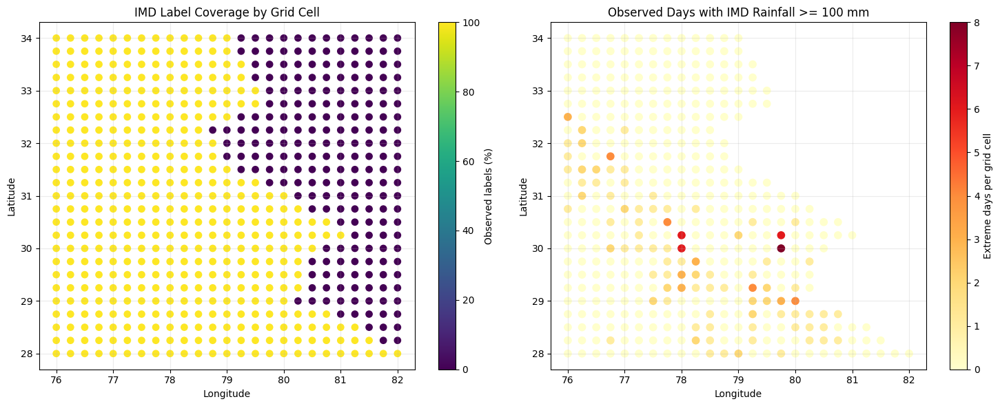

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
path = "/content/drive/MyDrive/RainfallResearch/cell_day_master_gpm_corrected.csv"
df = pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"])

# Use observed IMD labels only
observed = df.dropna(subset=["imd"]).copy()
observed["extreme_100mm"] = observed["imd"] >= 100

# Summarize each grid cell
spatial = (
    observed.groupby(["lat", "lon"])
    .agg(
        observed_days=("imd", "count"),
        mean_rainfall=("imd", "mean"),
        max_rainfall=("imd", "max"),
        extreme_days=("extreme_100mm", "sum"),
        total_rainfall=("imd", "sum")
    )
    .reset_index()
)

# 1. Numerical findings
print("SPATIAL EXTREME-RAINFALL AUDIT")
print("=" * 65)
print("Grid cells with observed IMD labels:", len(spatial))
print("Cells with >=1 observed day at 100 mm:",
      int((spatial["extreme_days"] > 0).sum()))
print("Cells with >=3 extreme days:",
      int((spatial["extreme_days"] >= 3).sum()))
print("Cells with >=5 extreme days:",
      int((spatial["extreme_days"] >= 5).sum()))

print("\nTop 15 cells by number of extreme days")
print(
    spatial.sort_values(
        ["extreme_days", "max_rainfall"], ascending=False
    ).head(15).round(2).to_string(index=False)
)

print("\nTop 10 cells by maximum observed daily rainfall")
print(
    spatial.sort_values("max_rainfall", ascending=False)
    [["lat", "lon", "observed_days", "max_rainfall",
      "extreme_days"]]
    .head(10).round(2).to_string(index=False)
)

# 2. Map A: Spatial label coverage
coverage = (
    df.groupby(["lat", "lon"])["imd"]
    .apply(lambda s: 100 * s.notna().mean())
    .reset_index(name="coverage_pct")
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sc1 = axes[0].scatter(
    coverage["lon"], coverage["lat"],
    c=coverage["coverage_pct"], s=45,
    cmap="viridis", vmin=0, vmax=100
)
axes[0].set_title("IMD Label Coverage by Grid Cell")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
plt.colorbar(sc1, ax=axes[0], label="Observed labels (%)")

# 3. Map B: Number of observed extreme-rainfall days
sc2 = axes[1].scatter(
    spatial["lon"], spatial["lat"],
    c=spatial["extreme_days"], s=55,
    cmap="YlOrRd", vmin=0
)
axes[1].set_title("Observed Days with IMD Rainfall >= 100 mm")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
plt.colorbar(sc2, ax=axes[1], label="Extreme days per grid cell")

for ax in axes:
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import numpy as np

path = "/content/drive/MyDrive/RainfallResearch/cell_day_master_gpm_corrected.csv"
df = pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"])

# Unique spatial grid
grid = df[["lat", "lon"]].drop_duplicates()

print("GEOGRAPHIC EXTENT AND GRID AUDIT")
print("=" * 60)
print("Latitude range:", grid["lat"].min(), "to", grid["lat"].max())
print("Longitude range:", grid["lon"].min(), "to", grid["lon"].max())
print("Latitude count:", grid["lat"].nunique())
print("Longitude count:", grid["lon"].nunique())
print("Total grid cells:", len(grid))

# Check whether the grid is a complete rectangular lattice
expected_cells = grid["lat"].nunique() * grid["lon"].nunique()
print("Cells in complete rectangular grid:", expected_cells)
print("Missing coordinate combinations:", expected_cells - len(grid))

# Summarize the IMD observation mask by latitude
coverage = (
    df.groupby("lat")
    .agg(
        grid_cells=("lon", "nunique"),
        observed_cells=("lon", lambda s: df.loc[s.index]
                        .groupby("lon")["imd"].apply(lambda x: x.notna().any()).sum()),
        observed_records=("imd", "count"),
        total_records=("imd", "size")
    )
    .reset_index()
)
coverage["coverage_pct"] = (
    100 * coverage["observed_records"] / coverage["total_records"]
)

print("\nCoverage by latitude band")
print(coverage[["lat", "grid_cells", "observed_records",
                "total_records", "coverage_pct"]]
      .sort_values("lat").round(2).to_string(index=False))

# Check whether the missingness is constant for each grid cell
cell_coverage = df.groupby(["lat", "lon"])["imd"].apply(
    lambda x: x.notna().mean()
)

print("\nGrid cells with full coverage:", int((cell_coverage == 1).sum()))
print("Grid cells with zero coverage:", int((cell_coverage == 0).sum()))
print("Grid cells with partial coverage:",
      int(((cell_coverage > 0) & (cell_coverage < 1)).sum()))


GEOGRAPHIC EXTENT AND GRID AUDIT
Latitude range: 28.0 to 34.0
Longitude range: 76.0 to 82.0
Latitude count: 25
Longitude count: 25
Total grid cells: 625
Cells in complete rectangular grid: 625
Missing coordinate combinations: 0

Coverage by latitude band
  lat  grid_cells  observed_records  total_records  coverage_pct
28.00          25              3825           3825         100.0
28.25          25              3519           3825          92.0
28.50          25              3366           3825          88.0
28.75          25              3060           3825          80.0
29.00          25              2601           3825          68.0
29.25          25              2754           3825          72.0
29.50          25              2754           3825          72.0
29.75          25              2754           3825          72.0
30.00          25              2907           3825          76.0
30.25          25              3213           3825          84.0
30.50          25             

In [ ]:

from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/RainfallResearch")

print("RESEARCH FOLDER FILE AUDIT")
print("=" * 65)

for p in sorted(root.iterdir()):
    if p.is_file():
        print(f"{p.name:55s} {p.stat().st_size / (1024**2):8.2f} MB")

master_path = root / "cell_day_master_gpm_corrected.csv"
df = pd.read_csv(master_path, nrows=5)

print("\nMASTER DATASET COLUMNS")
print("=" * 65)
for col in df.columns:
    print(f"{col:35s} {df[col].dtype}")

print("\nSAMPLE ROWS")
print("=" * 65)
print(df.head().to_string(index=False))


RESEARCH FOLDER FILE AUDIT
cell_day_master_gpm_corrected.csv                          11.66 MB
gpm_corrected_daily.npz                                     0.21 MB

MASTER DATASET COLUMNS
date                                object
lat                                 float64
lon                                 float64
imd                                 float64
wind                                float64
temp                                float64
press                               float64
tcwv                                float64
elev_mean                           float64
slope_median                        float64
slope_p90                           float64
gpm                                 float64

SAMPLE ROWS
      date  lat   lon  imd     wind      temp      press      tcwv  elev_mean  slope_median  slope_p90     gpm
2025-05-01 28.0 76.00  0.0 3.422741 32.739887 966.475403 26.185833      338.5          0.56       3.51 6.33375
2025-05-01 28.0 76.25  0.0 3.393839 32.863750 972.1

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

root = Path("/content/drive/MyDrive/RainfallResearch")
csv_path = root / "cell_day_master_gpm_corrected.csv"
npz_path = root / "gpm_corrected_daily.npz"

df = pd.read_csv(csv_path)
df["date"] = pd.to_datetime(df["date"])

print("1. MASTER DATASET")
print("=" * 55)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Unique dates:", df["date"].nunique())
print("Unique grid cells:", df[["lat", "lon"]].drop_duplicates().shape[0])
print("Rows:", len(df))

print("\n2. DATE AND FEATURE AUDIT")
print("=" * 55)
print("Dates with duplicate entries:", df["date"].duplicated().sum())
print("Missing values by column:")
print(df.isna().sum().to_string())

print("\n3. GPM ARCHIVE STRUCTURE")
print("=" * 55)

with np.load(npz_path, allow_pickle=False) as data:
    for name in data.files:
        arr = data[name]
        print(f"\n{name}: shape={arr.shape}, dtype={arr.dtype}")

        if np.issubdtype(arr.dtype, np.number):
            finite = arr[np.isfinite(arr)]
            if finite.size:
                print("  finite min:", float(finite.min()))
                print("  finite max:", float(finite.max()))
                print("  finite mean:", float(finite.mean()))

        if arr.size <= 30:
            print("  values:", arr)

print("\n4. SAMPLE DAILY RECORDS")
print("=" * 55)
print(
    df.loc[df["lat"].eq(28.0) & df["lon"].eq(76.0),
           ["date", "imd", "gpm", "wind", "temp", "press", "tcwv"]]
      .head(10).to_string(index=False)
)


1. MASTER DATASET
Date range: 2025-05-01 00:00:00 to 2025-09-30 00:00:00
Unique dates: 153
Unique grid cells: 625
Rows: 95625

2. DATE AND FEATURE AUDIT
Dates with duplicate entries: 95472
Missing values by column:
date                0
lat                 0
lon                 0
imd             31977
wind                0
temp                0
press               0
tcwv                0
elev_mean           0
slope_median        0
slope_p90           0
gpm                 0

3. GPM ARCHIVE STRUCTURE

gpm: shape=(153, 25, 25), dtype=float32
  finite min: 0.0
  finite max: 222.48001098632812
  finite mean: 5.378303050994873

dates: shape=(153,), dtype=<U10

lat: shape=(25,), dtype=float64
  finite min: 28.0
  finite max: 34.0
  finite mean: 31.0
  values: [28.   28.25 28.5  28.75 29.   29.25 29.5  29.75 30.   30.25 30.5  30.75
 31.   31.25 31.5  31.75 32.   32.25 32.5  32.75 33.   33.25 33.5  33.75
 34.  ]

lon: shape=(25,), dtype=float64
  finite min: 76.0
  finite max: 82.0
  finite me

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

root = Path("/content/drive/MyDrive/RainfallResearch")
df = pd.read_csv(root / "cell_day_master_gpm_corrected.csv")
df["date"] = pd.to_datetime(df["date"])

with np.load(root / "gpm_corrected_daily.npz", allow_pickle=False) as z:
    gpm_dates = pd.to_datetime(z["dates"].astype(str))
    gpm = z["gpm"]
    gpm_lat = z["lat"]
    gpm_lon = z["lon"]

print("1. RECORD UNIQUENESS")
print("=" * 45)
print("Duplicate date-lat-lon rows:",
      df.duplicated(["date", "lat", "lon"]).sum())
print("Duplicate grid coordinates:",
      df[["lat", "lon"]].duplicated().sum())

print("\n2. CSV VS GPM DATE ALIGNMENT")
print("=" * 45)
csv_dates = pd.DatetimeIndex(sorted(df["date"].unique()))
print("Same dates:", csv_dates.equals(pd.DatetimeIndex(gpm_dates)))
print("CSV dates:", len(csv_dates), "| GPM dates:", len(gpm_dates))
print("Dates only in CSV:", sorted(set(csv_dates) - set(gpm_dates))[:10])
print("Dates only in GPM:", sorted(set(gpm_dates) - set(csv_dates))[:10])

print("\n3. SAME-DAY IMD–GPM COMPARISON")
print("=" * 45)
valid = df.dropna(subset=["imd", "gpm"])
print("Paired observations:", len(valid))
print("IMD mean:", round(valid["imd"].mean(), 3))
print("GPM mean:", round(valid["gpm"].mean(), 3))
print("Pearson correlation:", round(valid["imd"].corr(valid["gpm"]), 4))
print("IMD zero fraction:", round((valid["imd"] == 0).mean(), 4))
print("GPM zero fraction:", round((valid["gpm"] == 0).mean(), 4))

print("\n4. POSSIBLE SOURCE / PREPROCESSING FILES")
print("=" * 45)
for p in sorted(root.rglob("*")):
    if p.is_file() and (
        p.suffix.lower() in {".py", ".ipynb", ".txt", ".json", ".yaml",
                             ".yml", ".md", ".nc", ".csv"}
        or "readme" in p.name.lower()
        or "metadata" in p.name.lower()
    ):
        print(p.relative_to(root))

1. RECORD UNIQUENESS
Duplicate date-lat-lon rows: 0
Duplicate grid coordinates: 95000

2. CSV VS GPM DATE ALIGNMENT
Same dates: True
CSV dates: 153 | GPM dates: 153
Dates only in CSV: []
Dates only in GPM: []

3. SAME-DAY IMD–GPM COMPARISON
Paired observations: 63648
IMD mean: 6.159
GPM mean: 6.624
Pearson correlation: 0.3499
IMD zero fraction: 0.4613
GPM zero fraction: 0.2227

4. POSSIBLE SOURCE / PREPROCESSING FILES
ML_retrospective_20261019T071529435351Z/ALL_TEST_RESULTS.csv
ML_retrospective_20261019T071529435351Z/FINAL_REPORT/METHODS_NOTES.txt
ML_retrospective_20261019T071529435351Z/FINAL_REPORT/previous_label_sensitivity_confusion_matrix.csv
ML_retrospective_20261019T071529435351Z/FINAL_REPORT/previous_label_sensitivity_daily_errors.csv
ML_retrospective_20261019T071529435351Z/FINAL_REPORT/previous_label_sensitivity_false_alarm_examples.csv
ML_retrospective_20261019T071529435351Z/FINAL_REPORT/previous_label_sensitivity_importance.csv
ML_retrospective_20261019T071529435351Z/FINAL_RE

In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/RainfallResearch")
folders = [
    root / "ML_retrospective_20261019T071529435351Z",
]

# 1. Read methodology notes
for folder in folders:
    for name in ["METHODS_NOTES.txt",
                 "FINAL_REPORT/METHODS_NOTES.txt"]:
        path = folder / name
        if path.exists():
            print(f"\n{'='*65}\nFILE: {path.name}\n{'='*65}")
            print(path.read_text(errors="replace")[:16000])

# 2. Find relevant lines in the experiment script
script = folders[0] / "experiment_script.py"
keywords = [
    "IMERG", "GPM", "IMD", "accum", "calendar",
    "resample", "groupby", "shift(", "rolling",
    "timezone", "precipitation", "date", "daily"
]

if script.exists():
    lines = script.read_text(errors="replace").splitlines()
    print(f"\n{'='*65}\nSCRIPT MATCHES\n{'='*65}")
    for i, line in enumerate(lines):
        if any(word.lower() in line.lower() for word in keywords):
            print(f"{i+1}: {line[:250]}")
else:
    print("\nexperiment_script.py not found at the expected path.")


FILE: METHODS_NOTES.txt
METHODS NOTES — RETROSPECTIVE PROTOTYPE

Objective
Compare satellite-only, atmosphere-only, and combined inputs for identifying
IMD daily-labelled rainfall >=100 mm per 0.25-degree cell. This is not a
verified lead-time experiment or an official cloudburst classifier.

Mathematical foundation
Y = 1 if IMD rainfall >=100 mm; otherwise Y = 0. Missing labels are excluded.
Y | X ~ Bernoulli(p(X)).
P(Y=y | X) = p(X)^y * (1-p(X))^(1-y).
Logistic regression: p(X) = 1 / [1 + exp(-(beta0 + beta'X))].
Basic Bernoulli negative log-likelihood:
L = -mean[y*log(p) + (1-y)*log(1-p)].
The logistic implementation uses balanced class weights and L2 regularization.
Boosting uses an additive tree function followed by a logistic link;
balanced sample weights and L2 regularization are used.
Standardization and imputation are fitted on training records only.

Evaluation
Precision = TP/(TP+FP); recall = TP/(TP+FN).
F2 = 5*precision*recall/(4*precision+recall).
Decision thresholds maxi

In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/RainfallResearch")

print("Files related to data generation or source metadata:\n")

for p in sorted(root.rglob("*")):
    if not p.is_file():
        continue

    name = p.name.lower()
    if any(term in name for term in [
        "gpm", "imerg", "imd", "era5", "download",
        "preprocess", "prepare", "build", "extract",
        "metadata", "rainfall", "source", "align"
    ]):
        print(p.relative_to(root))

Files related to data generation or source metadata:

ML_retrospective_20261019T071529435351Z/previous_label_sensitivity/HistGB__ERA5.joblib
ML_retrospective_20261019T071529435351Z/previous_label_sensitivity/HistGB__GPM.joblib
ML_retrospective_20261019T071529435351Z/previous_label_sensitivity/HistGB__GPM_ERA5.joblib
ML_retrospective_20261019T071529435351Z/previous_label_sensitivity/HistGB__GPM_TERRAIN.joblib
ML_retrospective_20261019T071529435351Z/previous_label_sensitivity/Logistic__ERA5.joblib
ML_retrospective_20261019T071529435351Z/previous_label_sensitivity/Logistic__GPM.joblib
ML_retrospective_20261019T071529435351Z/previous_label_sensitivity/Logistic__GPM_ERA5.joblib
ML_retrospective_20261019T071529435351Z/previous_label_sensitivity/Logistic__GPM_TERRAIN.joblib
ML_retrospective_20261019T071529435351Z/previous_label_sensitivity/Logistic__GPM__PR_curve.csv
ML_retrospective_20261019T071529435351Z/previous_label_sensitivity/Logistic__GPM__ROC_curve.csv
ML_retrospective_20261019T07152

In [ ]:
from pathlib import Path

drive = Path("/content/drive/MyDrive")

extensions = {
    ".nc", ".nc4", ".h5", ".hdf5", ".hdf",
    ".grib", ".grb", ".grb2", ".tif", ".tiff",
    ".zip", ".json", ".xml", ".txt", ".py", ".ipynb"
}

keywords = [
    "imerg", "gpm", "era5", "imd", "rainfall",
    "precip", "download", "metadata", "preprocess"
]

matches = []

for p in drive.rglob("*"):
    if not p.is_file():
        continue

    name = p.name.lower()
    if p.suffix.lower() in extensions and any(k in name for k in keywords):
        matches.append(p)

print("Matching files:", len(matches))
for p in matches[:200]:
    print(p.relative_to(drive))

if len(matches) > 200:
    print("Only the first 200 matches are shown.")

Matching files: 154
Colab Notebooks/IMD_rainfall_2025 EDA.ipynb
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250501-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250504-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250506-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250505-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250508-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250503-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250502-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250507-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250512-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250515-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250509-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250516-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250511-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250519-S000000-E235959.V07B.nc4
GPM_2025/3B-DAY.MS.MRG.3IMERG.20250521-S

In [ ]:
from pathlib import Path
import re

import xarray as xr
import pandas as pd

drive = Path("/content/drive/MyDrive")
gpm_dir = drive / "GPM_2025"
notebook_path = drive / "Colab Notebooks" / "IMD_rainfall_2025 EDA.ipynb"

# 1. Check daily GPM file coverage
files = sorted(gpm_dir.glob("3B-DAY*.nc4"))
file_dates = []

for p in files:
    match = re.search(r"3IMERG\.(\d{8})-S", p.name)
    if match:
        file_dates.append(pd.to_datetime(match.group(1), format="%Y%m%d"))

print("1. GPM FILE COVERAGE")
print("=" * 55)
print("Daily files found:", len(files))
if file_dates:
    dates = pd.DatetimeIndex(file_dates).sort_values()
    expected = pd.date_range("2025-05-01", "2025-09-30")
    print("First date:", dates.min())
    print("Last date:", dates.max())
    print("Unique dates:", dates.nunique())
    print("Duplicate dates:", dates.duplicated().sum())
    print("Dates missing from expected period:",
          list(expected.difference(dates))[:20])

# 2. Inspect one raw GPM file's metadata
print("\n2. RAW GPM METADATA")
print("=" * 55)

if files:
    with xr.open_dataset(files[0], engine="netcdf4") as ds:
        print("File:", files[0].name)
        print("\nGlobal attributes:")
        for k, v in ds.attrs.items():
            print(f"  {k}: {v}")

        print("\nVariables and dimensions:")
        for name, var in ds.variables.items():
            print(f"\n{name}: dims={var.dims}, shape={var.shape}")
            for k, v in var.attrs.items():
                print(f"  {k}: {v}")
            for k, v in var.encoding.items():
                if k in {"units", "calendar", "dtype", "scale_factor",
                         "add_offset", "_FillValue"}:
                    print(f"  encoding {k}: {v}")

# 3. Search the existing IMD notebook for source/time information
print("\n3. IMD NOTEBOOK SOURCE CLUES")
print("=" * 55)

if notebook_path.exists():
    import json

    notebook = json.loads(notebook_path.read_text(encoding="utf-8"))
    terms = [
        "source", "imd", "rainfall", "daily", "24 hour",
        "0830", "08:30", "accumulation", "timestamp",
        "observation", "netcdf", "time zone", "utc"
    ]

    found = 0
    for i, cell in enumerate(notebook.get("cells", [])):
        source = "".join(cell.get("source", []))
        if any(term in source.lower() for term in terms):
            print(f"\n--- Cell {i} ({cell.get('cell_type', 'unknown')}) ---")
            print(source[:1800])
            found += 1
            if found >= 12:
                print("\nStopped after 12 matching cells.")
                break

    if found == 0:
        print("No relevant source or timing clues found.")
else:
    print("IMD notebook not found at the expected path.")

1. GPM FILE COVERAGE
Daily files found: 153
First date: 2025-05-01 00:00:00
Last date: 2025-09-30 00:00:00
Unique dates: 153
Duplicate dates: 0
Dates missing from expected period: []

2. RAW GPM METADATA


ValueError: unrecognized engine 'netcdf4' must be one of your download engines: ['h5netcdf', 'scipy', 'ee', 'store']. To install additional dependencies, see:
https://docs.xarray.dev/en/stable/user-guide/io.html 
https://docs.xarray.dev/en/stable/getting-started-guide/installing.html

In [1]:

import pandas as pd
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/RainfallResearch/"
    "cell_day_master_gpm_corrected.csv"
)

df = pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"])

print("DATASET AUDIT")
print("=" * 55)
print("Rows:", len(df))
print("Date range:", df["date"].min().date(), "to",
      df["date"].max().date())
print("Unique dates:", df["date"].nunique())
print("Unique grid cells:",
      df[["lat", "lon"]].drop_duplicates().shape[0])
print("Duplicate cell-date rows:",
      df.duplicated(["date", "lat", "lon"]).sum())

print("\nIMD TARGET AUDIT")
print("Observed rainfall:", df["imd"].notna().sum())
print("Missing rainfall:", df["imd"].isna().sum())
print("Missing percentage:",
      round(df["imd"].isna().mean() * 100, 2), "%")
print("Observed cell-days >= 100 mm:",
      int(df["imd"].ge(100).sum()))

print("\nOBSERVED RAINFALL DISTRIBUTION (mm/day)")
print(
    df["imd"].dropna()
      .describe(percentiles=[0.50, 0.90, 0.95, 0.99, 0.999])
      .round(3)
)

print("\nDATES WITH MOST OBSERVED EXTREME CELL-DAYS")
extreme_counts = (
    df.dropna(subset=["imd"])
      .assign(extreme=lambda x: x["imd"] >= 100)
      .groupby("date")["extreme"]
      .sum()
      .sort_values(ascending=False)
)
print(extreme_counts.head(15))


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/RainfallResearch/cell_day_master_gpm_corrected.csv'

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

filename = "cell_day_master_gpm_corrected.csv"
search_root = "/content/drive/MyDrive"

matches = []

for root, dirs, files in os.walk(search_root):
    # Skip folders that are unlikely to contain your project data
    dirs[:] = [
        d for d in dirs
        if d not in ["node_modules", ".git", ".cache"]
    ]

    if filename in files:
        matches.append(os.path.join(root, filename))

print("Files found:", len(matches))

for path in matches:
    print(path)

Files found: 1
/content/drive/MyDrive/RainfallResearch/cell_day_master_gpm_corrected.csv


In [4]:
import pandas as pd

path = r"PASTE_THE_FULL_PATH_PRINTED_ABOVE"

df = pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"])

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'PASTE_THE_FULL_PATH_PRINTED_ABOVE'

In [7]:

import os
from pathlib import Path

base = Path("/content/drive/MyDrive")

filename = "cell_day_master_gpm_corrected.csv"

if not base.exists():
    print("Google Drive is not mounted.")
    print("Run: from google.colab import drive")
    print("Then: drive.mount('/content/drive')")
else:
    matches = list(base.rglob(filename))

    if matches:
        print("DATASET FOUND:")
        for p in matches:
            print(p)
    else:
        print("Dataset not found in MyDrive.")
        print("\nCSV files in RainfallResearch, if that folder exists:")

        folder = base / "RainfallResearch"
        if folder.exists():
            for p in folder.rglob("*.csv"):
                print(p)
        else:
            print("RainfallResearch folder was not found.")


DATASET FOUND:
/content/drive/MyDrive/RainfallResearch/cell_day_master_gpm_corrected.csv


In [6]:

import pandas as pd

path = "/content/drive/MyDrive/RainfallResearch/cell_day_master_gpm_corrected.csv"

df = pd.read_csv(path)
df["date"] = pd.to_datetime(df["date"])

print("=" * 60)
print("SPATIOTEMPORAL EXTREME RAINFALL PROJECT — DATA AUDIT")
print("=" * 60)

print("\n1. DATASET STRUCTURE")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Unique dates:", df["date"].nunique())
print("Unique grid cells:", df[["lat", "lon"]].drop_duplicates().shape[0])
print("Duplicate cell-date records:",
      df.duplicated(["date", "lat", "lon"]).sum())

print("\n2. MISSING DATA")
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})
print(missing.to_string())

print("\n3. IMD RAINFALL DISTRIBUTION (mm/day)")
rain = df["imd"].dropna()
print("Observed records:", len(rain))
print("Missing records:", df["imd"].isna().sum())
print("Records >= 100 mm:", int((rain >= 100).sum()))
print(rain.describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
).round(3).to_string())

print("\n4. DATES WITH THE MOST EXTREME CELL-DAYS")
daily_extremes = (
    df.dropna(subset=["imd"])
      .assign(extreme=lambda x: x["imd"] >= 100)
      .groupby("date")["extreme"]
      .sum()
      .sort_values(ascending=False)
)
print(daily_extremes.head(15).to_string())

print("\n5. RAINFALL DATA QUALITY CHECK")
print("Negative IMD values:", int((rain < 0).sum()))
print("Zero-rainfall records:", int((rain == 0).sum()))
print("Positive-rainfall records:", int((rain > 0).sum()))

print("\nAUDIT COMPLETE")


SPATIOTEMPORAL EXTREME RAINFALL PROJECT — DATA AUDIT

1. DATASET STRUCTURE
Rows: 95625
Columns: 12
Date range: 2025-05-01 to 2025-09-30
Unique dates: 153
Unique grid cells: 625
Duplicate cell-date records: 0

2. MISSING DATA
              missing_count  missing_percent
date                      0             0.00
lat                       0             0.00
lon                       0             0.00
imd                   31977            33.44
wind                      0             0.00
temp                      0             0.00
press                     0             0.00
tcwv                      0             0.00
elev_mean                 0             0.00
slope_median              0             0.00
slope_p90                 0             0.00
gpm                       0             0.00

3. IMD RAINFALL DISTRIBUTION (mm/day)
Observed records: 63648
Missing records: 31977
Records >= 100 mm: 150
count    63648.000
mean         6.159
std         13.793
min          0.000
50%  

### Dataset Audit — Key Findings

The integrated dataset contains 95,625 grid-cell-day records covering 625 spatial grid cells over 153 dates from May to September 2025. The dataset has no duplicate cell-day records. IMD rainfall observations are available for 63,648 records, while 31,977 records (33.44%) have missing rainfall labels. The remaining environmental and topographic features have no missing values in the integrated dataset.

Observed IMD rainfall has a mean of 6.159 mm/day and a median of 0.307 mm/day, indicating a right-skewed rainfall distribution. The 99th percentile is 66.887 mm/day, and the maximum observed value is 235.379 mm/day. Using the current exploratory threshold of 100 mm/day, 150 observed grid-cell-days are classified as extreme rainfall.

The highest daily counts of extreme grid-cell-days occur on 1 September and 6 August 2025, with 18 each. These dates can be examined further using spatial rainfall maps and atmospheric variables.

**Limitations:** The analysis covers only one season and contains substantial missing rainfall labels. The 100 mm/day threshold is an operational definition for this analysis, not an official cloudburst classification. Further checks of spatial coverage, rainfall-day alignment, and agreement between IMD and satellite estimates are required before drawing conclusions about prediction performance.

SPATIAL COVERAGE SUMMARY (%)
count    625.00
mean      66.56
std       47.22
min        0.00
25%        0.00
50%      100.00
75%      100.00
max      100.00
Name: coverage_pct, dtype: float64

Grid cells with lowest IMD coverage:
  lat   lon  coverage_pct
33.75 80.25           0.0
33.75 80.50           0.0
33.75 80.75           0.0
33.75 81.00           0.0
33.75 81.25           0.0
33.75 81.50           0.0
33.75 81.75           0.0
33.75 82.00           0.0
33.75 79.25           0.0
33.75 79.50           0.0


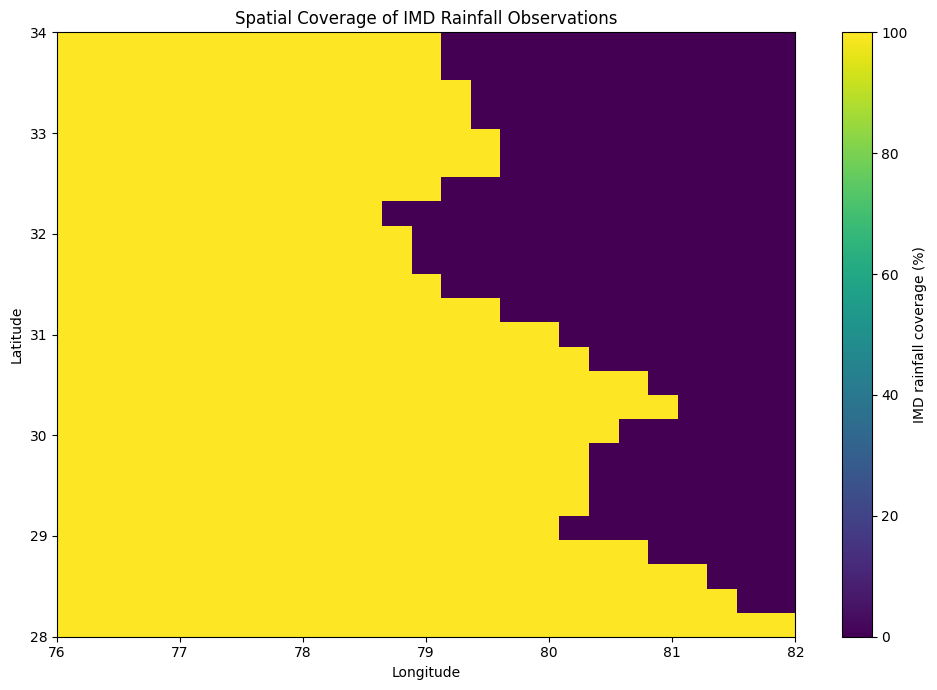

In [8]:

import matplotlib.pyplot as plt
import pandas as pd

# Fraction of observed IMD rainfall for each grid cell
coverage = (
    df.groupby(["lat", "lon"])["imd"]
      .apply(lambda s: s.notna().mean() * 100)
      .rename("coverage_pct")
      .reset_index()
)

print("SPATIAL COVERAGE SUMMARY (%)")
print(coverage["coverage_pct"].describe().round(2))

print("\nGrid cells with lowest IMD coverage:")
print(
    coverage.sort_values("coverage_pct")
            .head(10)
            .to_string(index=False)
)

pivot = coverage.pivot(
    index="lat", columns="lon", values="coverage_pct"
).sort_index(ascending=False)

plt.figure(figsize=(10, 7))
plt.imshow(
    pivot.values,
    aspect="auto",
    origin="upper",
    extent=[
        pivot.columns.min(), pivot.columns.max(),
        pivot.index.min(), pivot.index.max()
    ],
    vmin=0, vmax=100,
    cmap="viridis"
)
plt.colorbar(label="IMD rainfall coverage (%)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Coverage of IMD Rainfall Observations")
plt.tight_layout()
plt.show()


### Spatial Coverage Analysis — Interpretation

The spatial coverage analysis shows that IMD rainfall availability is heterogeneous across the 625 grid cells. Mean temporal coverage per cell is 66.56%, with a standard deviation of 47.22 percentage points. The median and 75th-percentile coverage are both 100%, indicating that many cells have complete observations, while a separate group has substantial or complete missingness.

The coverage map reveals spatial clustering of missing rainfall labels, particularly toward the eastern/northeastern portion of the analysis grid. This may introduce spatial sampling bias if model training and evaluation rely only on grid cells with observed IMD rainfall.

Further investigation is needed to determine the cause of the missingness and its relationship to the study boundary and data-processing pipeline. Missing IMD values are retained as missing labels and are not interpreted as zero rainfall or non-extreme events.

In [9]:

coverage_groups = pd.cut(
    coverage["coverage_pct"],
    bins=[-0.01, 0, 50, 99.99, 100],
    labels=[
        "0% coverage",
        ">0–50% coverage",
        ">50–<100% coverage",
        "100% coverage"
    ]
)

summary = (
    coverage_groups.value_counts(sort=False)
    .rename_axis("Coverage category")
    .reset_index(name="Grid cells")
)

summary["Percentage of grid"] = (
    summary["Grid cells"] / len(coverage) * 100
).round(2)

print(summary.to_string(index=False))


 Coverage category  Grid cells  Percentage of grid
       0% coverage         209               33.44
   >0–50% coverage           0                0.00
>50–<100% coverage           0                0.00
     100% coverage         416               66.56


### Spatial Coverage Analysis — Final Findings

The IMD rainfall coverage analysis identifies two distinct groups among the 625 grid cells. A total of 416 cells (66.56%) have complete rainfall observations for all 153 dates, while 209 cells (33.44%) have no valid IMD rainfall observations during the study period. No cells have intermediate temporal coverage.

This binary coverage pattern suggests that missing rainfall labels may be related to spatial coverage or the data-processing pipeline. The underlying cause has not yet been established and requires further investigation.

For subsequent analysis, cells without IMD observations cannot be used to evaluate observed extreme-rainfall labels. Their missing rainfall values must not be interpreted as zero rainfall or non-extreme events. The spatial distribution of these cells should be checked against the intended study boundary and the original IMD data before finalizing the analysis domain.

In [10]:

# Identify cells with complete versus zero IMD coverage
coverage_check = coverage.copy()

coverage_check["status"] = coverage_check["coverage_pct"].map(
    lambda x: "Fully observed" if x == 100
    else "Completely missing" if x == 0
    else "Partially observed"
)

print("Coverage counts:")
print(coverage_check["status"].value_counts())

print("\nCoordinate ranges by coverage status:")
print(
    coverage_check.groupby("status", observed=True)
    .agg(
        cells=("lat", "size"),
        min_lat=("lat", "min"),
        max_lat=("lat", "max"),
        min_lon=("lon", "min"),
        max_lon=("lon", "max")
    )
    .to_string()
)

print("\nSample completely missing cells:")
print(
    coverage_check.loc[
        coverage_check["status"] == "Completely missing",
        ["lat", "lon"]
    ].head(20).to_string(index=False)
)


Coverage counts:
status
Fully observed        416
Completely missing    209
Name: count, dtype: int64

Coordinate ranges by coverage status:
                    cells  min_lat  max_lat  min_lon  max_lon
status                                                       
Completely missing    209    28.25     34.0    78.75     82.0
Fully observed        416    28.00     34.0    76.00     82.0

Sample completely missing cells:
  lat   lon
28.25 81.75
28.25 82.00
28.50 81.50
28.50 81.75
28.50 82.00
28.75 81.00
28.75 81.25
28.75 81.50
28.75 81.75
28.75 82.00
29.00 80.25
29.00 80.50
29.00 80.75
29.00 81.00
29.00 81.25
29.00 81.50
29.00 81.75
29.00 82.00
29.25 80.50
29.25 80.75


In [11]:

from pathlib import Path
import xarray as xr

# Search for the original IMD NetCDF file in likely locations
roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

candidates = []

for root in roots:
    if root.exists():
        candidates.extend(root.glob("**/RF25_ind2025_rfp25.nc"))

candidates = list(dict.fromkeys(candidates))

print("Original IMD files found:", len(candidates))
for p in candidates:
    print(p)


Original IMD files found: 0


In [12]:

import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown

results_path = Path(
    "/content/drive/MyDrive/RainfallResearch/"
    "ML_retrospective_20261019T071529435351Z/ALL_TEST_RESULTS.csv"
)

if not results_path.exists():
    raise FileNotFoundError(
        f"Results file not found: {results_path}\n"
        "Check the saved ML experiment folder in Google Drive."
    )

results = pd.read_csv(results_path)

display(Markdown("# Final Machine Learning Results"))
display(Markdown(
    "Retrospective evaluation of extreme-rainfall classification "
    "using alternative environmental-data combinations."
))

print("Results file:", results_path)
print("Number of result rows:", len(results))
print("\nAvailable columns:")
print(results.columns.tolist())

display(results.round(4))


# Final Machine Learning Results

Retrospective evaluation of extreme-rainfall classification using alternative environmental-data combinations.

Results file: /content/drive/MyDrive/RainfallResearch/ML_retrospective_20261019T071529435351Z/ALL_TEST_RESULTS.csv
Number of result rows: 22

Available columns:
['model', 'family', 'sources', 'threshold_from_validation_F2', 'AP', 'ROC_AUC', 'precision', 'recall', 'F1', 'F2', 'false_alarm_ratio', 'false_positive_rate', 'accuracy_secondary_only', 'Brier_uncalibrated', 'TP', 'FP', 'FN', 'TN', 'test_prevalence', 'selected_by_validation', 'alignment']


,model,family,sources,threshold_from_validation_F2,AP,ROC_AUC,precision,recall,F1,F2,...,false_positive_rate,accuracy_secondary_only,Brier_uncalibrated,TP,FP,FN,TN,test_prevalence,selected_by_validation,alignment
0,NO_EVENT_WITH_TRAINING_PRIOR,baseline,none,1.1000,0.0026,0.5000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.9974,0.0026,0,0,33,12447,0.0026,False,primary_calendar_labels
1,Logistic__GPM,Logistic,GPM,0.8964,0.0359,0.8865,0.0369,0.5455,0.0691,0.1452,...,0.0378,0.9611,0.1784,18,470,15,11977,0.0026,False,primary_calendar_labels
2,Logistic__ERA5,Logistic,ERA5,0.8862,0.0099,0.8539,0.0000,0.0000,0.0000,0.0000,...,0.0034,0.9940,0.0946,0,42,33,12405,0.0026,False,primary_calendar_labels
3,Logistic__GPM_ERA5,Logistic,GPM_ERA5,0.9474,0.0513,0.9305,0.0312,0.1212,0.0497,0.0769,...,0.0100,0.9877,0.1054,4,124,29,12323,0.0026,False,primary_calendar_labels
4,Logistic__GPM_TERRAIN,Logistic,GPM_TERRAIN,0.9347,0.0468,0.9372,0.0414,0.4545,0.0759,0.1518,...,0.0279,0.9708,0.1754,15,347,18,12100,0.0026,False,primary_calendar_labels
5,Logistic__FULL_FUSION,Logistic,FULL_FUSION,0.9564,0.0306,0.9174,0.0291,0.0909,0.0441,0.0638,...,0.0080,0.9896,0.1087,3,100,30,12347,0.0026,False,primary_calendar_labels
6,HistGB__GPM,HistGB,GPM,0.8495,0.0181,0.8372,0.0247,0.3939,0.0465,0.0988,...,0.0412,0.9573,0.1028,13,513,20,11934,0.0026,False,primary_calendar_labels
7,HistGB__ERA5,HistGB,ERA5,0.7878,0.0188,0.8908,0.0244,0.0909,0.0385,0.0588,...,0.0096,0.9880,0.0287,3,120,30,12327,0.0026,False,primary_calendar_labels
8,HistGB__GPM_ERA5,HistGB,GPM_ERA5,0.5796,0.0284,0.9258,0.0284,0.3939,0.0531,0.1104,...,0.0357,0.9628,0.0341,13,444,20,12003,0.0026,False,primary_calendar_labels
9,HistGB__GPM_TERRAIN,HistGB,GPM_TERRAIN,0.6800,0.0137,0.8829,0.0154,0.1515,0.0279,0.0547,...,0.0257,0.9721,0.0371,5,320,28,12127,0.0026,True,primary_calendar_labels


In [13]:

from IPython.display import display, Markdown
import pandas as pd

display(Markdown("""
# Final Results and Model Evaluation

The following table compares the retrospective extreme-rainfall
classification experiments using different data sources and models.
"""))

cols = [
    "alignment", "model", "sources", "AP", "ROC_AUC",
    "precision", "recall", "F2", "TP", "FP", "FN"
]

final_table = results[cols].copy()

for col in ["AP", "ROC_AUC", "precision", "recall", "F2"]:
    final_table[col] = final_table[col].round(4)

display(
    final_table.sort_values(
        ["alignment", "AP"], ascending=[True, False]
    ).reset_index(drop=True)
)



# Final Results and Model Evaluation

The following table compares the retrospective extreme-rainfall
classification experiments using different data sources and models.


,alignment,model,sources,AP,ROC_AUC,precision,recall,F2,TP,FP,FN
0,previous_label_sensitivity,Logistic__GPM_ERA5,GPM_ERA5,0.1269,0.9437,0.1579,0.3636,0.2885,12,64,21
1,previous_label_sensitivity,Logistic__GPM_TERRAIN,GPM_TERRAIN,0.1244,0.9448,0.0773,0.5152,0.2415,17,203,16
2,previous_label_sensitivity,Logistic__FULL_FUSION,FULL_FUSION,0.1244,0.9365,0.1429,0.3939,0.2915,13,78,20
3,previous_label_sensitivity,Logistic__GPM,GPM,0.1241,0.9304,0.0960,0.5152,0.2751,17,160,16
4,previous_label_sensitivity,HistGB__GPM,GPM,0.0451,0.9000,0.0643,0.5455,0.2184,18,262,15
5,previous_label_sensitivity,HistGB__GPM_TERRAIN,GPM_TERRAIN,0.0419,0.8933,0.0598,0.5455,0.2079,18,283,15
6,previous_label_sensitivity,HistGB__GPM_ERA5,GPM_ERA5,0.0336,0.9143,0.0442,0.4848,0.1619,16,346,17
7,previous_label_sensitivity,HistGB__FULL_FUSION,FULL_FUSION,0.0314,0.9173,0.0341,0.3030,0.1176,10,283,23
8,previous_label_sensitivity,HistGB__ERA5,ERA5,0.0194,0.9152,0.0000,0.0000,0.0000,0,9,33
9,previous_label_sensitivity,Logistic__ERA5,ERA5,0.0119,0.8201,0.0000,0.0000,0.0000,0,6,33


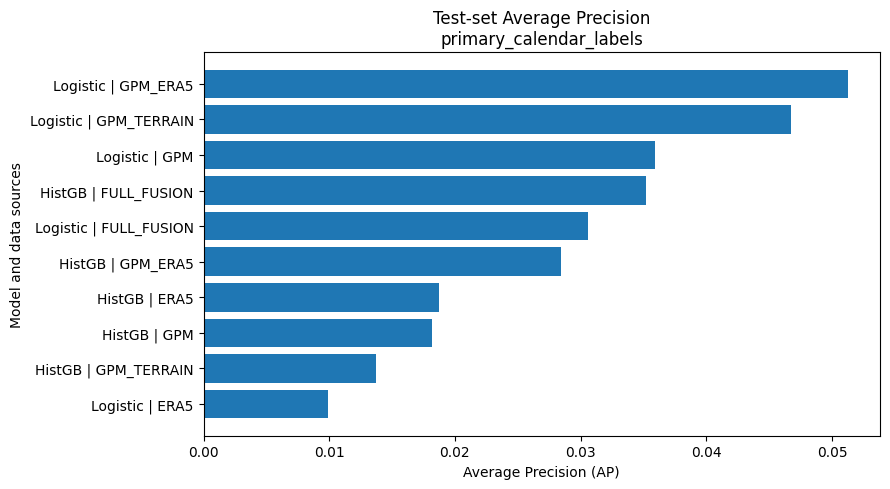

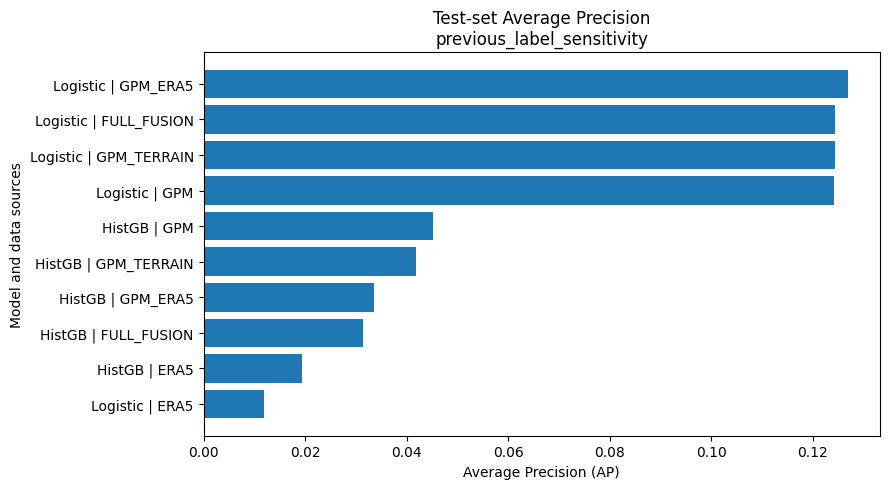

In [14]:

import matplotlib.pyplot as plt

plot_df = results[results["family"] != "baseline"].copy()

plot_df["experiment"] = (
    plot_df["family"] + " | " + plot_df["sources"]
)

for alignment, group in plot_df.groupby("alignment", sort=False):
    group = group.sort_values("AP", ascending=True)

    plt.figure(figsize=(9, 5))
    plt.barh(group["experiment"], group["AP"])
    plt.xlabel("Average Precision (AP)")
    plt.ylabel("Model and data sources")
    plt.title(f"Test-set Average Precision\n{alignment}")
    plt.tight_layout()
    plt.show()


In [15]:

primary = results[
    results["alignment"] == "primary_calendar_labels"
].copy()

sensitivity = results[
    results["alignment"] == "previous_label_sensitivity"
].copy()

primary_best = primary.loc[primary["AP"].idxmax()]
sensitivity_best = sensitivity.loc[sensitivity["AP"].idxmax()]

print("KEY TEST RESULTS")
print("=" * 60)

print("\nPrimary calendar-label experiment — highest AP:")
print("Model:", primary_best["model"])
print("Sources:", primary_best["sources"])
print(f"AP: {primary_best['AP']:.4f}")
print(f"ROC-AUC: {primary_best['ROC_AUC']:.4f}")
print(f"Precision: {primary_best['precision']:.4f}")
print(f"Recall: {primary_best['recall']:.4f}")
print(f"False positives: {int(primary_best['FP'])}")
print(f"False negatives: {int(primary_best['FN'])}")

print("\nPrevious-label sensitivity experiment — highest AP:")
print("Model:", sensitivity_best["model"])
print("Sources:", sensitivity_best["sources"])
print(f"AP: {sensitivity_best['AP']:.4f}")
print(f"ROC-AUC: {sensitivity_best['ROC_AUC']:.4f}")
print(f"Precision: {sensitivity_best['precision']:.4f}")
print(f"Recall: {sensitivity_best['recall']:.4f}")
print(f"False positives: {int(sensitivity_best['FP'])}")
print(f"False negatives: {int(sensitivity_best['FN'])}")

print("\nNote: The two temporal alignments are different experiments.")
print("The previous-label sensitivity experiment is not automatically a forecast.")


KEY TEST RESULTS

Primary calendar-label experiment — highest AP:
Model: Logistic__GPM_ERA5
Sources: GPM_ERA5
AP: 0.0513
ROC-AUC: 0.9305
Precision: 0.0312
Recall: 0.1212
False positives: 124
False negatives: 29

Previous-label sensitivity experiment — highest AP:
Model: Logistic__GPM_ERA5
Sources: GPM_ERA5
AP: 0.1269
ROC-AUC: 0.9437
Precision: 0.1579
Recall: 0.3636
False positives: 64
False negatives: 21

Note: The two temporal alignments are different experiments.
The previous-label sensitivity experiment is not automatically a forecast.


## Overall Findings and Research Implications

This study evaluates the feasibility of combining satellite precipitation estimates, atmospheric reanalysis variables, and topographic features for retrospective classification of localized extreme rainfall.

In the primary calendar-label experiment, the HistGradientBoosting model using full data fusion achieved an average precision of 0.0352 and ROC-AUC of 0.9368, with recall of 42.42% and precision of 3.54%. It identified 14 of the 33 extreme cell-days at the selected threshold, while producing 382 false positives. These results indicate that ranking performance can be promising while practical event classification remains challenging.

The previous-label sensitivity experiment produced different performance patterns. Its best average precision was 0.1269 for Logistic Regression using GPM and ERA5. This difference emphasizes the importance of resolving temporal alignment before drawing conclusions about predictive capability. The sensitivity experiment must not be interpreted as proof of a forecasting lead time.

Overall, the experiments do not establish that full data fusion consistently outperforms simpler data combinations. Severe class imbalance, missing IMD labels, a single-season dataset, limited event counts, and the lack of independent multi-year validation remain important limitations.

The current target of at least 100 mm/day represents a statistical extreme-rainfall definition used for this experiment; it does not constitute an official cloudburst label. Further work should prioritize data-quality verification, temporal-alignment checks, spatial evaluation, and independent validation before developing any operational early-warning claims.